# Anexo · Desarrollos previos del libro, capítulos 7–11

**Antecedente, no evidencia del protocolo nuevo.** Este cuaderno conserva las ejecuciones previas en CPU, con varias series y objetivos en diferencias absolutas. No acredita entrenamiento T4, la división 70/15/15 ni el objetivo de rendimiento diario que ahora exige el protocolo. La entrega actual se encuentra en `notebooks/` y sus pendientes se declaran en el informe.

# Proyecto final de Gestión de bases de datos
## Almacenamiento, evaluación y auditoría de modelos de series temporales
### Integración de los capítulos 7, 8, 9, 10 y 11 de *Deep Learning for Finance*

**Alumno:** Juan Fernando Castrejón Villa  
**Matrícula:** 81901  
**Correo institucional:** jcv81901@lasallebajio.edu.mx  
**Carrera:** Actuaría  
**Semestre:** 5.º  
**Institución:** Universidad De La Salle Bajío  
**Materia:** Gestión de bases de datos  
**Fecha de cierre:** 19 de noviembre de 2026

Este documento reúne los cinco avances y añade la integración relacional, la auditoría de métricas y las conclusiones generales. Los modelos se ejecutan con las muestras históricas incluidas. Los resultados pertenecen a esta implementación y no son una copia de las cifras del libro.

**Formato de entrega:** cuaderno Jupyter `.ipynb`, compatible con Google Colab. Las salidas guardadas permiten revisar el trabajo sin entrenarlo de nuevo. Para reproducirlo, se ejecutan las celdas en orden.

## Contenido

1. Introducción, problema y objetivos.
2. Metodología, procedencia y diseño de la base.
3. Entorno de ejecución.
4. Capítulo 7: aprendizaje automático.
5. Capítulo 8: redes neuronales.
6. Capítulo 9: transformaciones, validación y múltiples horizontes.
7. Capítulo 10: aprendizaje por refuerzo.
8. Capítulo 11: aplicaciones avanzadas.
9. Integración SQLite y consultas SQL.
10. Auditoría, resultados y conclusiones generales.
11. Exportación y referencias.

## 1. Introducción y planteamiento del problema

Un modelo de predicción requiere más que un algoritmo: necesita observaciones identificables, una transformación explícita, una separación temporal correcta y evidencia que permita comprobar sus resultados. Cuando distintos experimentos se conservan en archivos separados, resulta fácil perder la relación entre fuente, variable, modelo y métrica o comparar errores expresados en unidades diferentes.

Este proyecto construye un proceso que va de los datos a la evaluación y termina en una base relacional consultable. Las prácticas de los capítulos 7 al 11 permiten estudiar aprendizaje automático, redes neuronales, pronósticos multiperíodo, aprendizaje por refuerzo e indicadores financieros. SQLite organiza la evidencia para que las conclusiones puedan revisarse a partir de las predicciones almacenadas.

**Pregunta general:** ¿cómo almacenar y auditar experimentos de predicción temporal para determinar, dentro de cada tarea y periodo de prueba, si los modelos estudiados mejoran a referencias simples?

### Objetivo general

Desarrollar un cuaderno reproducible que implemente los capítulos 7 al 11, integre sus experimentos en una base relacional y contraste sus resultados fuera de muestra con referencias explícitas.

### Objetivos específicos

1. Conservar la procedencia, la unidad y las huellas de integridad de las muestras.
2. Preparar las variables y ventanas sin incorporar observaciones futuras al ajuste.
3. Implementar los modelos y las demostraciones de los cinco capítulos.
4. Registrar casos, modelos, métricas, pronósticos y curvas de aprendizaje mediante claves y relaciones.
5. Recalcular el conteo, el MAE y el RMSE desde SQL y verificar su coincidencia con Python.
6. Interpretar los resultados por tarea y documentar sus límites.

### Alcance

Se cubren los capítulos 7 al 11 del material proporcionado. Las redes se adaptan a CPU con tamaños y épocas máximas declarados en sus secciones. Las muestras de los avances se mantienen congeladas para permitir su revisión. No se añaden datos de mercado recientes ni fechas a archivos que no las proporcionan. Los ejemplos de temperatura, PMI y seno permiten estudiar técnicas de series; no todos los experimentos predicen precios financieros.

## 2. Metodología y fuentes

El proceso sigue cinco fases: **identificar y conservar los datos; preparar variables; separar cronológicamente; ajustar y evaluar; almacenar y auditar**. La limpieza elimina registros sin cotización para construir las diferencias entre observaciones publicadas; los CSV originales conservan los faltantes. Cada capítulo documenta su corte, su ventana y su horizonte.

| Capítulo | Datos o ejemplo principal | Técnicas | Regla de evaluación |
|---|---|---|---|
| 7 | EUR/USD diario, USD por EUR | Lineal, SVR, SGD, KNN, árbol, bosque, AdaBoost y XGBoost | 80 % entrenamiento, 20 % prueba; mismas fechas objetivo |
| 8 | Cambios del S&P 500, puntos | MLP, RNN, LSTM, CNN y dropout | 64 % ajuste, 16 % validación y 20 % prueba sobre ejemplos supervisados |
| 9 | EUR/USD, S&P 500, temperatura y PMI | Diferenciación fraccionaria, umbrales, actualización, pronósticos directos y recursivos | Cortes documentados por experimento; purga de etiquetas que cruzan particiones |
| 10 | Seno de frecuencia fija, simulado | Bellman, memoria de experiencias y Double DQN | Ajuste, validación y prueba temporal; sin aprender sobre prueba |
| 11 | COT CAD, EUR/USD, Bitcoin y PMI | LSTM, indicadores, salidas múltiples y visualización del aprendizaje | Escalado solo con ajuste; comparación por variable y horizonte |

En los capítulos 9 y 11, el esquema común reserva el primer 64 % de la serie para ajuste, el siguiente 16 % para validación y el último 20 % para prueba. Al predecir varios pasos se excluyen las etiquetas que atraviesan los cortes y en prueba se usan bloques de objetivos sin solapamiento. La demostración de actualización del capítulo 9 usa una división de desarrollo/prueba de 80/20, señalada en su apartado.

### Procedencia de las muestras

| Fuente | Muestra y unidad | Identificación temporal |
|---|---|---|
| FRED DEXUSEU | EUR/USD, USD por EUR | 2000-01-03 a 2023-06-01; consulta 2026-11-05 |
| FRED SP500 | Nivel S&P 500, puntos | 2016-11-07 a 2023-06-01; consulta 2026-11-06 |
| Repositorio del autor: temperatura Basel | 6,241 valores, °C | El archivo no contiene fechas; se conserva el orden |
| Repositorio del autor: ISM PMI | 906 valores, puntos | El archivo no contiene fechas; se conserva el orden |
| Repositorio del autor: COT CAD | 449 informes TFF, porcentajes de interés abierto | Fechas de informe 2015-01-06 a 2023-08-08 |
| Repositorio del autor: Bitcoin | 3,123 precios | Sin calendario ni mercado documentados en el archivo |
| FRED DEXCAUS | CAD por USD y su recíproco CADUSD | Consulta 2026-11-12; comparación descriptiva con COT |
| Generación matemática | 500 valores de seno | Secuencia simulada, sin fechas de mercado |

Los archivos del autor se fijan en la revisión `07e6d4f4844b228849294eee5b426029e7b011b1`. Las celdas verifican los hashes de las copias incluidas. El rango solicitado del S&P 500 comenzaba en 1990, pero se declara el intervalo realmente devuelto por la fuente. La consulta del COT no reconstruye las fechas efectivas de difusión de cada informe.

### Criterios de evaluación

Se calculan MAE y RMSE en la unidad de la variable objetivo, y cuando corresponde R², correlación y acierto direccional. Una correlación con predicción constante no está definida y se guarda como `NULL`. R² puede ser negativo. Para niveles, el acierto direccional compara el cambio desde el valor del origen; para diferencias, compara sus signos. Los ceros cuentan como una tercera categoría.

Las referencias de media, persistencia o cero establecen una comparación básica según la tarea. La regresión lineal también se utiliza como contraste en algunos experimentos. Las épocas se eligen por validación. Los ordenamientos de resultados de prueba son descriptivos: no se presentan como selección prospectiva ni como demostración de rentabilidad.

### Diseño relacional de la integración

Cada **caso** identifica un objetivo concreto, una unidad, un horizonte y un capítulo. Los modelos se identifican dentro de ese caso; por ejemplo, dos redes llamadas LSTM no se confunden si pertenecen a tareas distintas. Una tabla intermedia relaciona fuentes y casos.

| Tabla | Clave primaria | Información y relación |
|---|---|---|
| `capitulos` | `capitulo_id` | Tema; un capítulo tiene varios casos |
| `fuentes` | `fuente_id` | Procedencia, consulta, hashes y tipo real/simulado |
| `casos` | `caso_id` | Capítulo, objetivo, unidad, rezagos máximos y horizonte |
| `caso_fuente` | Caso + fuente | Relación de varios a varios y papel de la fuente |
| `observaciones` | Caso + índice | Serie objetivo; fecha cuando existe en los capítulos 7 y 8 |
| `modelos` | `modelo_id` | Caso, familia, rezagos efectivos y configuración |
| `metricas` | Modelo + partición | Tamaño, errores, R², correlación y acierto |
| `predicciones` | Modelo + origen + horizonte | Objetivo, valor real y valor estimado de prueba |
| `aprendizaje` | Modelo + época | Pérdidas de ajuste y validación de las redes supervisadas |
| `ejecucion` | `ejecucion_id` | Autor, fecha final, semilla, versiones y alcance |

La separación evita repetir nombres, unidades y metadatos de fuente en cada predicción. Las claves foráneas impiden registros huérfanos; las claves compuestas evitan duplicados. Los índices apoyan búsquedas por capítulo, partición y objetivo, y una vista reúne los resultados de prueba. Los parámetros específicos se conservan como metadatos JSON; los campos utilizados para relacionar y auditar permanecen en columnas.

La integración guarda series objetivo, mientras que las bases de cada capítulo conservan sus tablas originales y auxiliares. Los índices de observación de los capítulos 9 al 11 representan posiciones; no se convierten en fechas ficticias. El máximo de rezagos del caso puede diferir del de un modelo: SVR usa 50 en el capítulo 7 y las configuraciones DDQN usan 5 u 8.

## 3. Entorno y reproducción

En Google Colab: **Archivo → Subir cuaderno**, seleccionar este `.ipynb` y elegir **Entorno de ejecución → Ejecutar todo**. También puede abrirse en Jupyter con Python 3.12. El entrenamiento utiliza CPU y puede tardar varios minutos; los datos no necesitan una nueva descarga.

La siguiente celda instala únicamente bibliotecas ausentes y necesita internet si falta alguna. Las versiones de esta ejecución quedan registradas en la base y en `fuentes_y_versiones.json`. Las semillas ayudan a reproducir el procedimiento; otra plataforma o versión puede modificar cifras y tiempos. Cada sección redefine sus funciones y variables de trabajo, por lo que se debe ejecutar el cuaderno en orden.

In [1]:
import importlib.util, subprocess, sys, os
from pathlib import Path
os.environ['KERAS_BACKEND']='tensorflow'
os.environ['CUDA_VISIBLE_DEVICES']='-1'
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
os.environ['TF_ENABLE_ONEDNN_OPTS']='0'
requisitos={'numpy':'numpy>=1.26,<3','pandas':'pandas>=2.2,<3',
 'matplotlib':'matplotlib>=3.8,<4','sklearn':'scikit-learn>=1.6,<2',
 'tensorflow':'tensorflow-cpu>=2.20,<2.21','keras':'keras>=3.3,<4',
 'statsmodels':'statsmodels>=0.14,<1','xgboost':'xgboost>=3.1,<4'}
faltantes=[p for m,p in requisitos.items() if importlib.util.find_spec(m) is None]
if faltantes:subprocess.check_call([sys.executable,'-m','pip','install','-q',*faltantes])
P_FECHA='2026-11-19'
P_VERSIONES={}
print('Entorno preparado. Se conservarán los datos históricos incluidos.')

Entorno preparado. Se conservarán los datos históricos incluidos.


In [2]:
P_MANIFIESTO = {'sp500': {'fuente': 'https://fred.stlouisfed.org/series/SP500', 'consulta': '2026-11-06', 'sha256_original': '3355191bdf68ac93e7b2fddd32f971cf6f8dd734b91e32a65d4bcbe624d262d2', 'sha256_csv': '9609d0756b691f4c45cabb05bdf6ca62c0dad810b31231c92b0da68176bf025b', 'nombre': 'FRED SP500', 'tipo': 'Real', 'nota': 'Muestra histórica documentada en su capítulo.'}, 'euro': {'fuente': 'https://fred.stlouisfed.org/series/DEXUSEU', 'consulta': '2026-11-05', 'sha256_original': '81b2de51286e97b324bb26b479fede3a040217152638d5490285032f75dc34fa', 'sha256_csv': '8dcf3490796966d2149ab4261ffaf5e34f0a730ccf6cf4c6949d5a18af30f1b5', 'nombre': 'FRED DEXUSEU, EUR/USD', 'tipo': 'Real', 'nota': 'Muestra histórica documentada en su capítulo.'}, 'temperatura': {'fuente': 'https://raw.githubusercontent.com/sofienkaabar/deep-learning-for-finance/07e6d4f4844b228849294eee5b426029e7b011b1/Chapter%209/Temperature_Basel.xlsx', 'consulta': '2026-11-12', 'sha256_original': '9522484cdad15ddac89e4072696c1a48a89f8888fb375b7bc83918ecde6eabf2', 'sha256_csv': '9f4c0b8d196c283d0ba40bbd9bfe67aafe6f84fe85f663241b0074e4d6ff46ae', 'nombre': 'Temperatura Basel', 'tipo': 'Real', 'nota': 'Archivo sin calendario: se conserva la secuencia.'}, 'pmi': {'fuente': 'https://raw.githubusercontent.com/sofienkaabar/deep-learning-for-finance/07e6d4f4844b228849294eee5b426029e7b011b1/Chapter%209/ISM_PMI.xlsx', 'consulta': '2026-11-12', 'sha256_original': 'a0eb65a309846269fece8f90c36f22e9367ed23744feceeae53adc4650346b51', 'sha256_csv': '47fd6193e3322f90e4e3570287269834c77ebffdaa1c02028f45259dbc3eda5f', 'nombre': 'ISM PMI', 'tipo': 'Real', 'nota': 'Archivo sin calendario: se conserva la secuencia.'}, 'cot': {'fuente': 'https://raw.githubusercontent.com/sofienkaabar/deep-learning-for-finance/07e6d4f4844b228849294eee5b426029e7b011b1/Historical%20Data/COT_CAD.xlsx', 'consulta': '2026-11-12', 'sha256_original': '3c64902c6ab4e40c740d76cbdf11ed0521769e1e26afd52c3016c3f85ddd02cb', 'sha256_csv': 'ba88ae047d7a6c908487095d2b47235b66dd24aaa1bfe9af24649f89abdca8fc', 'nombre': 'COT CAD, informe TFF', 'tipo': 'Real', 'nota': 'Muestra histórica documentada en su capítulo.'}, 'bitcoin': {'fuente': 'https://raw.githubusercontent.com/sofienkaabar/deep-learning-for-finance/07e6d4f4844b228849294eee5b426029e7b011b1/Chapter%2011/Bitcoin_Daily_Historical_Data.xlsx', 'consulta': '2026-11-12', 'sha256_original': '8b64ec19434c25677a8951260e78cce3639082e5a27ba664b287b14f54b28132', 'sha256_csv': '67ef76d890bedb238ef626386646d74ec9bcb44ba3ac6438d6034d024aa8b484', 'nombre': 'Bitcoin, archivo histórico del autor', 'tipo': 'Real', 'nota': 'Archivo sin calendario: se conserva la secuencia.'}, 'cad': {'fuente': 'https://fred.stlouisfed.org/series/DEXCAUS', 'consulta': '2026-11-12', 'sha256_original': 'bad6cb547fc923538cdb20608619dc9ecdd172f333f203288662658859b4d2d6', 'sha256_csv': '8e2c665f908e18669ff2a4be32e7a72ca0518f43b8c39d8bcbadcd05b154b8c4', 'nombre': 'FRED DEXCAUS', 'tipo': 'Real', 'nota': 'Muestra histórica documentada en su capítulo.'}, 'seno': {'nombre': 'Onda sinusoidal', 'tipo': 'Simulada', 'fuente': None, 'consulta': None, 'nota': 'sin(arange(500)*10*pi/500); no son observaciones de mercado.'}}
print("Fuentes documentadas:",len(P_MANIFIESTO))

Fuentes documentadas: 8


## Capítulo 7. Aprendizaje automático para la predicción temporal

Esta sección conserva el desarrollo del avance y vuelve a ejecutar sus experimentos con los datos incluidos. Las referencias y limitaciones específicas se mantienen al final del capítulo.

#### Correspondencia con el capítulo

Las páginas corresponden al PDF de 61 páginas entregado como referencia.

| Apartado del material | Páginas del PDF | Desarrollo en el cuaderno |
|---|---:|---|
| Marco de trabajo y modelo de referencia | 1-22 | Datos, diferencias, rezagos, separación temporal y DummyRegressor |
| Regresión lineal | 23-29 | Ajuste, predicción y comparación |
| Regresión con vectores de soporte, SVR | 30-34 | Escalado y kernel RBF |
| Regresión por descenso de gradiente estocástico, SGD | 34-38 | Escalado y entrenamiento iterativo |
| Vecinos más cercanos, KNN | 38-42 | Promedio de 10 vecinos |
| Árbol de decisión | 42-45 | Árbol sin límite de profundidad y revisión de sobreajuste |
| Bosque aleatorio | 45-49 | Conjunto de árboles |
| AdaBoost | 49-52 | Reponderación de observaciones y regresores débiles |
| XGBoost | 52-55 | Boosting con árboles |
| Sobreajuste y subajuste | 55-61 | Brecha entre entrenamiento y prueba, y validación temporal |

La base de datos SQLite y sus consultas son una ampliación para relacionar la práctica con la materia. No se requiere MetaTrader 5 ni un archivo externo `master_function.py`: las funciones necesarias están definidas aquí.

### 1. Planteamiento y objetivos

**Pregunta del proyecto:** ¿los cambios anteriores del EUR/USD permiten predecir el siguiente cambio mejor que un modelo que siempre responde con el promedio histórico de entrenamiento?

**Objetivo general:** construir un proceso reproducible para almacenar, preparar y evaluar una serie temporal mediante los modelos del capítulo 7.

**Objetivos específicos:**

1. Conservar los datos originales e identificar valores faltantes.
2. Almacenar y consultar la serie con SQLite y SQL.
3. Transformar los precios en diferencias y construir variables rezagadas.
4. Separar cronológicamente el 80 % para entrenamiento y el 20 % para prueba.
5. Comparar un modelo de referencia y los ocho modelos del capítulo.
6. Interpretar sus errores y reconocer señales de sobreajuste.

#### Variable que se predice

Sea $P_t$ el tipo de cambio expresado en dólares estadounidenses por euro. Se calcula:

$$d_t = P_t - P_{t-1}$$

Se busca estimar $d_t$ utilizando únicamente diferencias anteriores:

$$\widehat{d_t}=f(d_{t-1},d_{t-2},\ldots,d_{t-L})$$

En cada fila, la **fecha objetivo** corresponde a $t$ y la **fecha de origen** a la observación disponible inmediatamente anterior. Es equivalente a usar información hasta $t$ para estimar $d_{t+1}$.

Se usan **diferencias absolutas**, como en el código del capítulo. Su unidad es USD por EUR; no son rendimientos porcentuales. Una diferencia positiva significa que aumentaron los dólares por euro. El horizonte es la **siguiente observación publicada**, que puede estar separada por un fin de semana o feriado.

### 2. Preparación del entorno

Se utiliza Python con NumPy, pandas, Matplotlib, scikit-learn y XGBoost. SQLite está incluido en Python. La instalación solo se intenta cuando una biblioteca está ausente; las versiones efectivamente utilizadas se muestran debajo para documentar la ejecución.

In [3]:
import base64
import gzip
import hashlib
import io
import json
import sqlite3
from pathlib import Path
from time import perf_counter
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor

SEMILLA = 123
REZAGOS = 500
REZAGOS_SVR = 50
FRACCION_ENTRENAMIENTO = 0.80
np.random.seed(SEMILLA)
pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 6)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18,
    'axes.titleweight': 'bold',
})
versiones = pd.DataFrame({
    'Componente': ['Python', 'NumPy', 'pandas', 'Matplotlib',
                   'scikit-learn', 'XGBoost', 'SQLite'],
    'Versión': [sys.version.split()[0], version('numpy'), version('pandas'),
                version('matplotlib'), version('scikit-learn'), version('xgboost'),
                sqlite3.sqlite_version],
})
display(versiones)

,Componente,Versión
0,Python,3.12.14
1,NumPy,2.3.5
2,pandas,2.2.3
3,Matplotlib,3.10.8
4,scikit-learn,1.8.0
5,XGBoost,3.1.1
6,SQLite,3.53.1


### 3. Fuente de datos y revisión de calidad

Se utiliza la serie **DEXUSEU** de FRED, cuya fuente es la Junta de Gobernadores de la Reserva Federal de Estados Unidos. Su frecuencia es diaria y su unidad es **USD por un euro**. Son tasas de compra al mediodía en Nueva York; no se presentan como precios de cierre de un bróker.

- **Periodo solicitado:** 1 de enero de 2000 al 1 de junio de 2023, como la alternativa de importación mostrada en la página 21 del PDF.
- **Fecha de consulta:** 5 de noviembre de 2026.
- **Ficha de la serie:** https://fred.stlouisfed.org/series/DEXUSEU
- **Descarga consultada:** https://fred.stlouisfed.org/graph/fredgraph.csv?id=DEXUSEU&cosd=2000-01-01&coed=2023-06-01

La siguiente celda contiene una copia comprimida del CSV real descargado. La compresión reduce el tamaño del cuaderno; no genera ni simula datos. Se verifica su huella SHA-256 antes de leerlo. No es necesario volver a descargar la serie para reproducir este desarrollo.

In [4]:
# Copia del CSV de FRED, comprimida con gzip y codificada en base64.
# Esta celda únicamente recupera los datos incluidos en el cuaderno.
CSV_COMPRIMIDO = """
...
+FBbZxuoAQA=
"""
CSV_SHA256 = "81b2de51286e97b324bb26b479fede3a040217152638d5490285032f75dc34fa"
csv_original = gzip.decompress(base64.b64decode(CSV_COMPRIMIDO))
assert hashlib.sha256(csv_original).hexdigest() == CSV_SHA256
original = pd.read_csv(io.BytesIO(csv_original))
print(f'Integridad del CSV: correcta. Filas originales: {len(original):,}')
display(original.head())

Integridad del CSV: correcta. Filas originales: 6,109


,observation_date,DEXUSEU
0,2000-01-03,1.0155
1,2000-01-04,1.0309
2,2000-01-05,1.0335
3,2000-01-06,1.0324
4,2000-01-07,1.0294


In [5]:
datos = original.rename(columns={'observation_date': 'fecha', 'DEXUSEU': 'valor'}).copy()
datos['fecha'] = pd.to_datetime(datos['fecha'], errors='raise')
datos['valor'] = pd.to_numeric(datos['valor'], errors='coerce')
datos = datos.sort_values('fecha').reset_index(drop=True)

calidad = pd.DataFrame({
    'Revisión': ['Filas originales', 'Fechas duplicadas', 'Valores faltantes',
                 'Valores no positivos', 'Observaciones válidas'],
    'Cantidad': [len(datos), int(datos['fecha'].duplicated().sum()),
                 int(datos['valor'].isna().sum()), int((datos['valor'] <= 0).sum()),
                 int(datos['valor'].notna().sum())],
})
display(calidad)
assert not datos['fecha'].duplicated().any(), 'Revisar fechas duplicadas.'
assert (datos['valor'].dropna() > 0).all(), 'Revisar cotizaciones no positivas.'
print('Primera fecha:', datos['fecha'].min().date())
print('Última fecha:', datos['fecha'].max().date())

,Revisión,Cantidad
0,Filas originales,6109
1,Fechas duplicadas,0
2,Valores faltantes,236
3,Valores no positivos,0
4,Observaciones válidas,5873


Primera fecha: 2000-01-03
Última fecha: 2023-06-01


**Tratamiento de faltantes.** Se conservan como `NULL` en la tabla original. Para modelar se excluyen las observaciones sin cotización antes de calcular diferencias. No se interpolan ni se rellenan, porque hacerlo introduciría valores que no se observaron. Tampoco se eliminan movimientos extremos válidos solo por su magnitud.

### 4. Almacenamiento y consulta en SQLite

Se utiliza una base en memoria durante el análisis para que ejecutar el cuaderno otra vez produzca un conjunto nuevo de resultados. Al final se guarda una copia en disco.

| Tabla | Contenido | Clave principal |
|---|---|---|
| `series` | Identificación y procedencia de la serie | `serie_id` |
| `cotizaciones` | Fechas y valores originales, incluidos los faltantes | `serie_id, fecha` |
| `modelos` | Nombre, número de rezagos y parámetros de cada modelo | `modelo_id` |
| `metricas` | Resultados por modelo y partición | `modelo_id, particion` |
| `predicciones` | Predicción y valor observado en cada fecha de prueba | `modelo_id, fecha_objetivo` |
| `ejecucion` | Configuración y huella de los datos utilizados | `ejecucion_id` |

Las claves foráneas conectan las cotizaciones con su serie, y los resultados con el modelo que los produjo. La fecha se guarda en formato ISO `AAAA-MM-DD`.

In [6]:
conexion = sqlite3.connect(':memory:')
conexion.execute('PRAGMA foreign_keys = ON')
conexion.executescript("""
CREATE TABLE series (
    serie_id TEXT PRIMARY KEY,
    descripcion TEXT NOT NULL,
    unidad TEXT NOT NULL,
    fuente_url TEXT NOT NULL
);
CREATE TABLE cotizaciones (
    serie_id TEXT NOT NULL,
    fecha TEXT NOT NULL,
    valor REAL CHECK (valor IS NULL OR valor > 0),
    PRIMARY KEY (serie_id, fecha),
    FOREIGN KEY (serie_id) REFERENCES series(serie_id)
);
CREATE TABLE modelos (
    modelo_id TEXT PRIMARY KEY,
    rezagos INTEGER NOT NULL CHECK (rezagos > 0),
    parametros_json TEXT NOT NULL
);
CREATE TABLE metricas (
    modelo_id TEXT NOT NULL,
    particion TEXT NOT NULL CHECK (particion IN ('Entrenamiento', 'Prueba')),
    n INTEGER NOT NULL,
    mae REAL NOT NULL,
    mse REAL NOT NULL,
    rmse REAL NOT NULL,
    acierto_pct REAL NOT NULL,
    correlacion REAL,
    sesgo REAL,
    positivas INTEGER NOT NULL,
    negativas INTEGER NOT NULL,
    ceros INTEGER NOT NULL,
    PRIMARY KEY (modelo_id, particion),
    FOREIGN KEY (modelo_id) REFERENCES modelos(modelo_id)
);
CREATE TABLE predicciones (
    modelo_id TEXT NOT NULL,
    serie_id TEXT NOT NULL,
    fecha_objetivo TEXT NOT NULL,
    fecha_origen TEXT NOT NULL,
    valor_real REAL NOT NULL,
    valor_predicho REAL NOT NULL,
    CHECK (fecha_origen < fecha_objetivo),
    PRIMARY KEY (modelo_id, fecha_objetivo),
    FOREIGN KEY (modelo_id) REFERENCES modelos(modelo_id),
    FOREIGN KEY (serie_id, fecha_objetivo) REFERENCES cotizaciones(serie_id, fecha)
);
CREATE TABLE ejecucion (
    ejecucion_id INTEGER PRIMARY KEY,
    fecha_consulta TEXT NOT NULL,
    datos_sha256 TEXT NOT NULL,
    configuracion_json TEXT NOT NULL,
    versiones_json TEXT NOT NULL
);
""")

conexion.execute('INSERT INTO series VALUES (?, ?, ?, ?)', (
    'DEXUSEU', 'Tipo de cambio USD por EUR', 'USD/EUR',
    'https://fred.stlouisfed.org/series/DEXUSEU'))
filas_originales = [
    ('DEXUSEU', fecha.strftime('%Y-%m-%d'), None if pd.isna(valor) else float(valor))
    for fecha, valor in datos[['fecha', 'valor']].itertuples(index=False, name=None)
]
conexion.executemany('INSERT INTO cotizaciones VALUES (?, ?, ?)', filas_originales)
conexion.commit()

display(pd.read_sql_query("""
SELECT s.serie_id, s.unidad,
       COUNT(*) AS filas, COUNT(c.valor) AS valores_disponibles,
       SUM(c.valor IS NULL) AS faltantes,
       MIN(c.fecha) AS primera_fecha, MAX(c.fecha) AS ultima_fecha
FROM series AS s JOIN cotizaciones AS c ON s.serie_id = c.serie_id
GROUP BY s.serie_id, s.unidad
""", conexion))

,serie_id,unidad,filas,valores_disponibles,faltantes,primera_fecha,ultima_fecha
0,DEXUSEU,USD/EUR,6109,5873,236,2000-01-03,2023-06-01


,fecha,fecha_origen,diferencia
0,2000-01-04,2000-01-03,0.0154
1,2000-01-05,2000-01-04,0.0026
2,2000-01-06,2000-01-05,-0.0011
3,2000-01-07,2000-01-06,-0.0030
4,2000-01-10,2000-01-07,-0.0042


Cotizaciones válidas: 5,873; diferencias: 5,872.


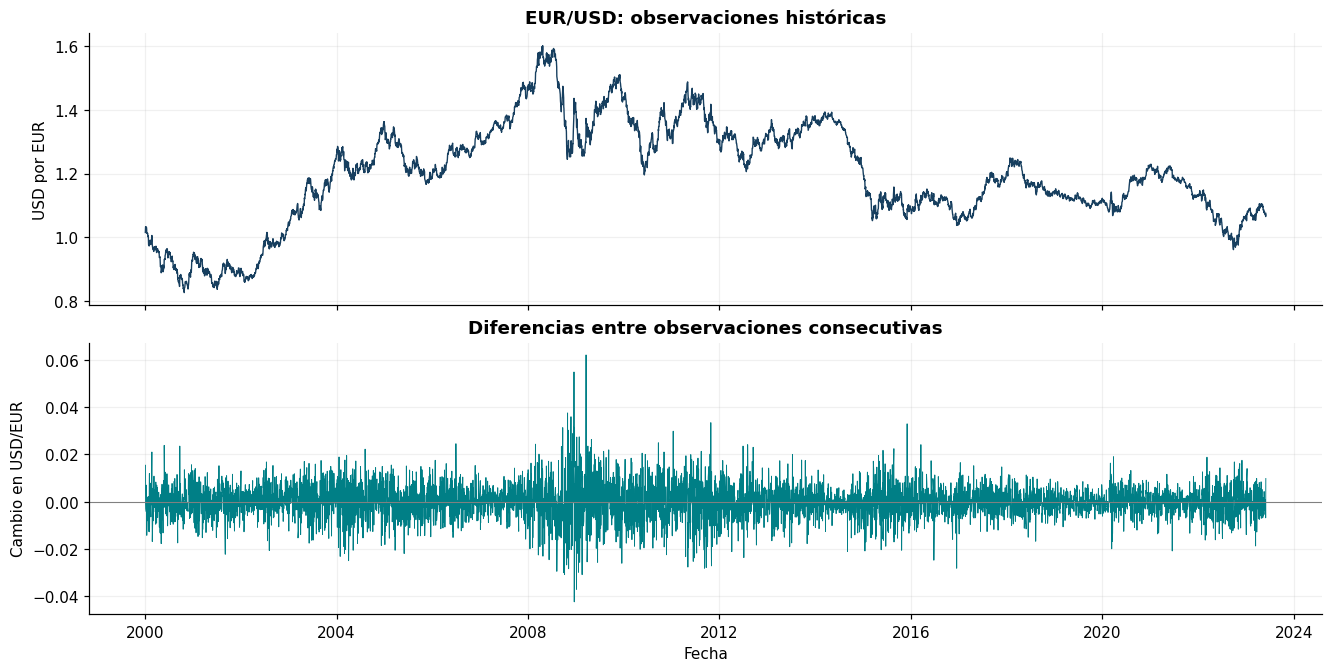

In [7]:
# La información que se modela se recupera mediante una consulta SQL.
precios = pd.read_sql_query("""
SELECT fecha, valor
FROM cotizaciones
WHERE serie_id = ? AND valor IS NOT NULL
ORDER BY fecha
""", conexion, params=('DEXUSEU',), parse_dates=['fecha'])

cambios = precios[['fecha']].copy()
cambios['fecha_origen'] = precios['fecha'].shift(1)
cambios['diferencia'] = precios['valor'].diff()
cambios = cambios.dropna().reset_index(drop=True)

display(cambios.head())
print(f'Cotizaciones válidas: {len(precios):,}; diferencias: {len(cambios):,}.')

fig, ejes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout='constrained')
ejes[0].plot(precios['fecha'], precios['valor'], color='#173F5F', linewidth=0.9)
ejes[0].set(title='EUR/USD: observaciones históricas', ylabel='USD por EUR')
ejes[1].plot(cambios['fecha'], cambios['diferencia'], color='#007F86', linewidth=0.6)
ejes[1].axhline(0, color='gray', linewidth=0.7)
ejes[1].set(title='Diferencias entre observaciones consecutivas',
            ylabel='Cambio en USD/EUR', xlabel='Fecha')
plt.show()

La diferenciación centra el análisis en los cambios. La gráfica permite explorar la serie, pero **no demuestra por sí sola estacionariedad**. Este avance aplica la transformación usada en el capítulo; una prueba formal de estacionariedad y el estudio de cambios de volatilidad quedan como ampliaciones del proyecto.

### 5. Rezagos y división cronológica

Cada fila contiene una diferencia objetivo y las diferencias anteriores. `rezago_1` es la diferencia inmediatamente anterior; `rezago_500` es la más antigua de la ventana principal.

Se utilizan **500 rezagos**, como en el marco del capítulo. Para SVR se emplean **50**, como en su apartado específico. Para comparar los resultados, SVR se alinea a las mismas fechas objetivo y al mismo corte 80/20 de los demás modelos. Por tanto, su conjunto de predictores es distinto, pero el periodo evaluado es idéntico.

No se mezclan las fechas. Los escaladores se ajustan dentro de cada modelo únicamente con su entrenamiento. En prueba se realizan pronósticos de **un paso con observaciones previas ya disponibles**: el modelo queda fijo, pero la ventana de entrada incorpora los datos reales que se van conociendo. No es un pronóstico simultáneo de todo el periodo de prueba desde una única fecha.

In [8]:
def construir_rezagos(serie, numero):
    columnas = {
        'fecha': serie['fecha'],
        'fecha_origen': serie['fecha_origen'],
        'objetivo': serie['diferencia'],
    }
    for k in range(1, numero + 1):
        columnas[f'rezago_{k}'] = serie['diferencia'].shift(k)
    return pd.DataFrame(columnas).dropna().reset_index(drop=True)

supervisado = construir_rezagos(cambios, REZAGOS)
supervisado_svr = (
    construir_rezagos(cambios, REZAGOS_SVR).set_index('fecha')
    .loc[supervisado['fecha']].reset_index()
)
corte = int(len(supervisado) * FRACCION_ENTRENAMIENTO)
assert 0 < corte < len(supervisado)
assert supervisado['fecha'].equals(supervisado_svr['fecha'])
assert np.allclose(supervisado['objetivo'], supervisado_svr['objetivo'])
assert (supervisado['fecha_origen'] < supervisado['fecha']).all()
assert supervisado.loc[corte - 1, 'fecha'] < supervisado.loc[corte, 'fecha']

def obtener_matrices(numero_rezagos):
    tabla = supervisado_svr if numero_rezagos == REZAGOS_SVR else supervisado
    columnas_x = [f'rezago_{k}' for k in range(1, numero_rezagos + 1)]
    x = tabla[columnas_x].to_numpy(dtype=float)
    y = tabla['objetivo'].to_numpy(dtype=float)
    return x[:corte], y[:corte], x[corte:], y[corte:]

x_train, y_train, x_test, y_test = obtener_matrices(REZAGOS)
fechas_train = supervisado['fecha'].iloc[:corte].reset_index(drop=True)
fechas_test = supervisado['fecha'].iloc[corte:].reset_index(drop=True)

display(supervisado[['fecha', 'fecha_origen', 'objetivo',
                     'rezago_1', 'rezago_2', 'rezago_500']].head())
display(pd.DataFrame({
    'Partición': ['Entrenamiento', 'Prueba'],
    'Observaciones': [len(y_train), len(y_test)],
    'Inicio objetivo': [fechas_train.min().date(), fechas_test.min().date()],
    'Fin objetivo': [fechas_train.max().date(), fechas_test.max().date()],
}))
print('x_train:', x_train.shape, '| y_train:', y_train.shape)
print('x_test: ', x_test.shape, '| y_test: ', y_test.shape)
print('SVR: mismas filas y fechas; 50 columnas de entrada.')

,fecha,fecha_origen,objetivo,rezago_1,rezago_2,rezago_500
0,2001-12-31,2001-12-28,0.0079,-0.0021,0.0065,0.0154
1,2002-01-02,2001-12-31,0.0130,0.0079,-0.0021,0.0026
2,2002-01-03,2002-01-02,-0.0039,0.0130,0.0079,-0.0011
3,2002-01-04,2002-01-03,-0.0046,-0.0039,0.0130,-0.0030
4,2002-01-07,2002-01-04,-0.0015,-0.0046,-0.0039,-0.0042


,Partición,Observaciones,Inicio objetivo,Fin objetivo
0,Entrenamiento,4297,2001-12-31,2019-02-12
1,Prueba,1075,2019-02-13,2023-06-01


x_train: (4297, 500) | y_train: (4297,)
x_test:  (1075, 500) | y_test:  (1075,)
SVR: mismas filas y fechas; 50 columnas de entrada.


### 6. Métricas de evaluación

Con $y_i$ observado y $\hat y_i$ predicho:

$$\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|$$
$$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2$$
$$\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$$

| Métrica | Interpretación |
|---|---|
| MAE | Distancia absoluta media entre predicción y observación; menor es mejor |
| MSE | Error cuadrático medio; penaliza más los errores grandes |
| RMSE | Raíz del MSE, expresada en USD/EUR; menor es mejor |
| Acierto direccional | Porcentaje de coincidencias entre los signos observado y predicho |
| Correlación | Asociación lineal entre valores predichos y observados |
| Sesgo direccional | Número de predicciones positivas dividido entre negativas |

Para el acierto se distinguen tres signos: positivo, negativo y cero. Un cero solo acierta si ambos valores son cero; el denominador incluye todas las observaciones. La correlación se deja sin definir cuando alguna serie es constante. El sesgo también se deja sin definir si no hay predicciones negativas. Las cantidades positivas, negativas y cero se conservan para poder interpretarlo.

El **sesgo direccional** no es el mismo concepto que el sesgo estadístico del equilibrio sesgo-varianza. Un valor direccional cercano a 1 indica balance de signos, pero no demuestra capacidad predictiva.

In [9]:
def evaluar(y_real, y_predicho):
    real = np.asarray(y_real, dtype=float).ravel()
    pred = np.asarray(y_predicho, dtype=float).ravel()
    assert real.shape == pred.shape
    assert np.isfinite(real).all() and np.isfinite(pred).all()
    positivas = int((pred > 0).sum())
    negativas = int((pred < 0).sum())
    ceros = int((pred == 0).sum())
    correlacion = np.nan
    if np.std(real) > np.finfo(float).eps and np.std(pred) > np.finfo(float).eps:
        correlacion = float(np.corrcoef(real, pred)[0, 1])
    mse = float(mean_squared_error(real, pred))
    return {
        'n': len(real),
        'mae': float(mean_absolute_error(real, pred)),
        'mse': mse,
        'rmse': float(np.sqrt(mse)),
        'acierto_pct': float(100 * np.mean(np.sign(real) == np.sign(pred))),
        'correlacion': correlacion,
        'sesgo': positivas / negativas if negativas else np.nan,
        'positivas': positivas, 'negativas': negativas, 'ceros': ceros,
    }

resultados = []
predicciones_train = {}
predicciones_test = {}
modelos_entrenados = {}
rezagos_modelo = {}
tiempos = {}

def entrenar_y_evaluar(nombre, modelo, numero_rezagos=REZAGOS):
    xt, yt, xv, yv = obtener_matrices(numero_rezagos)
    inicio = perf_counter()
    with threadpool_limits(limits=2):
        modelo.fit(xt, yt)
        pred_train = np.asarray(modelo.predict(xt)).ravel()
        pred_test = np.asarray(modelo.predict(xv)).ravel()
    tiempos[nombre] = perf_counter() - inicio
    modelos_entrenados[nombre] = modelo
    rezagos_modelo[nombre] = numero_rezagos
    predicciones_train[nombre] = pred_train
    predicciones_test[nombre] = pred_test

    resumen = []
    for particion, observado, predicho in [
        ('Entrenamiento', yt, pred_train), ('Prueba', yv, pred_test)
    ]:
        fila = {'modelo_id': nombre, 'particion': particion, **evaluar(observado, predicho)}
        resultados.append(fila)
        resumen.append(fila)
    display(pd.DataFrame(resumen).set_index('particion')[
        ['rmse', 'mae', 'acierto_pct', 'correlacion', 'sesgo']].round(6))

    ultimos, primeros = 80, 60
    fig, ax = plt.subplots(figsize=(12, 3.3), layout='constrained')
    ax.plot(fechas_train.iloc[-ultimos:], yt[-ultimos:],
            color='#8A96A3', linewidth=1, label='Real: entrenamiento')
    ax.plot(fechas_test.iloc[:primeros], yv[:primeros],
            color='#173F5F', linestyle='--', linewidth=1.2, label='Real: prueba')
    ax.plot(fechas_test.iloc[:primeros], pred_test[:primeros],
            color='#E87524', linewidth=1.2, label='Predicción: prueba')
    ax.axvline(fechas_test.iloc[0], color='#A12335', linestyle=':', label='Inicio de prueba')
    ax.axhline(0, color='gray', linewidth=0.6)
    ax.set(title=f'{nombre} | {numero_rezagos} rezagos', ylabel='Cambio en USD/EUR', xlabel='Fecha')
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.legend(loc='upper left', ncol=2, fontsize=8)
    plt.show()
    print(f'Tiempo de ajuste y predicción: {tiempos[nombre]:.2f} s')

### 7. Implementación de los modelos

Cada modelo se entrena con las matrices preparadas y se evalúa tanto dentro como fuera de la muestra. Las tablas usan las mismas definiciones de métricas. Las gráficas muestran las últimas 80 observaciones de entrenamiento y las primeras 60 de prueba para facilitar la lectura.

Los parámetros se fijan antes de comparar el periodo de prueba. No se utiliza ese periodo para cambiar los parámetros y volver a buscar un resultado favorable.

#### 7.1 Modelo de referencia: DummyRegressor

Siempre predice la media de `y_train`. Permite comprobar si un método más complejo aporta una mejora. Su predicción es constante por definición.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.007686,0.005610,49.941820,NaN,NaN
Prueba,0.005052,0.003751,49.395349,NaN,NaN


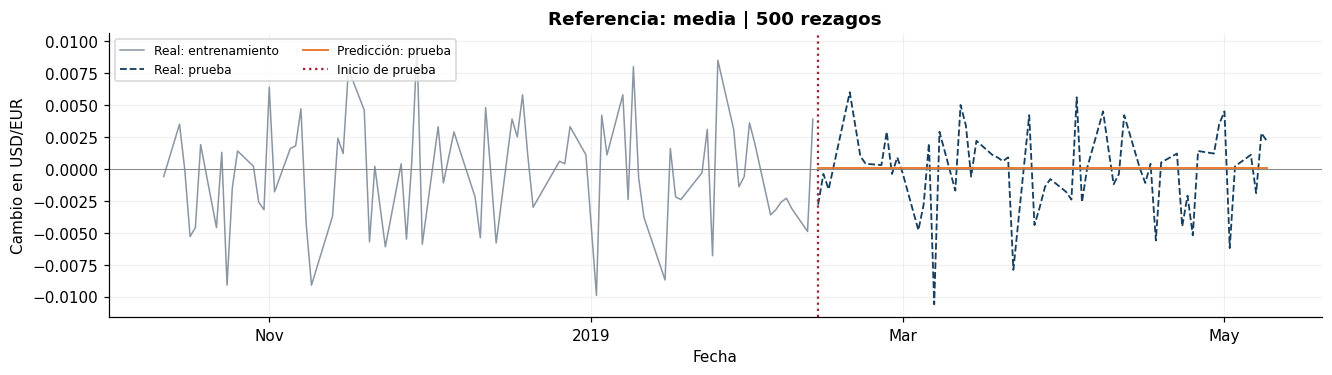

Tiempo de ajuste y predicción: 0.02 s
Verificación: cada predicción de referencia coincide con la media de entrenamiento.
Media de entrenamiento: 0.0000580405 USD/EUR


In [10]:
entrenar_y_evaluar('Referencia: media', DummyRegressor(strategy='mean'))
assert np.allclose(predicciones_test['Referencia: media'], y_train.mean())
print('Verificación: cada predicción de referencia coincide con la media de entrenamiento.')
print(f'Media de entrenamiento: {y_train.mean():.10f} USD/EUR')

#### 7.2 Regresión lineal

Estima una combinación lineal de los 500 rezagos mediante mínimos cuadrados. Es fácil de interpretar, pero puede ajustar relaciones débiles o ruido cuando hay muchas variables. Un buen ajuste de entrenamiento debe contrastarse con la prueba.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.007209,0.005348,59.390272,0.346765,1.028801
Prueba,0.005439,0.004112,48.558140,-0.040612,1.067308


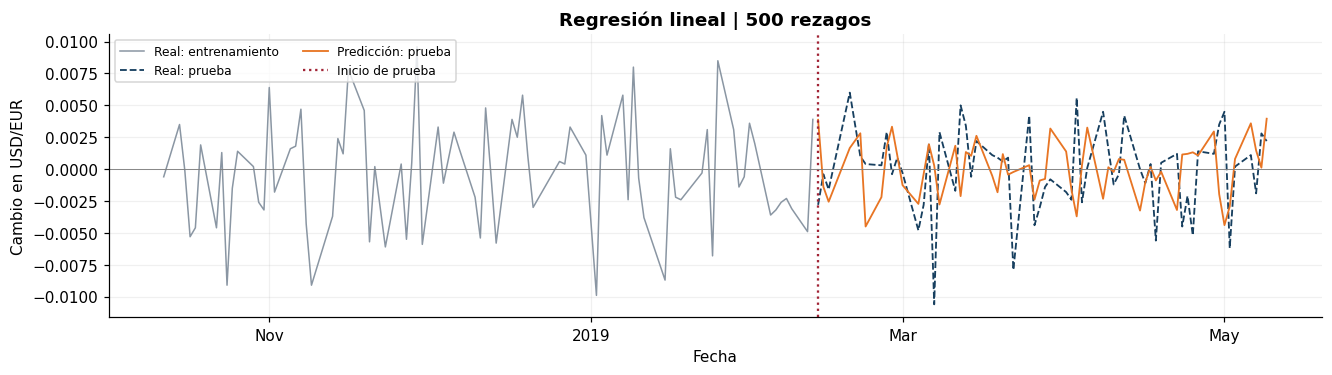

Tiempo de ajuste y predicción: 0.18 s


In [11]:
entrenar_y_evaluar('Regresión lineal', LinearRegression())

#### 7.3 Regresión con vectores de soporte, SVR

Se utiliza un kernel RBF para representar relaciones no lineales. El escalador se ajusta solo con `x_train` dentro del `Pipeline`. Se mantienen 50 rezagos y los parámetros del ejemplo del capítulo: `C=1`, `gamma=0.04` y `epsilon=0.01`. `epsilon` está expresado en la escala de la diferencia objetivo.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.005968,0.004928,58.133582,0.695451,0.571115
Prueba,0.005324,0.004035,50.511628,0.004084,0.396104


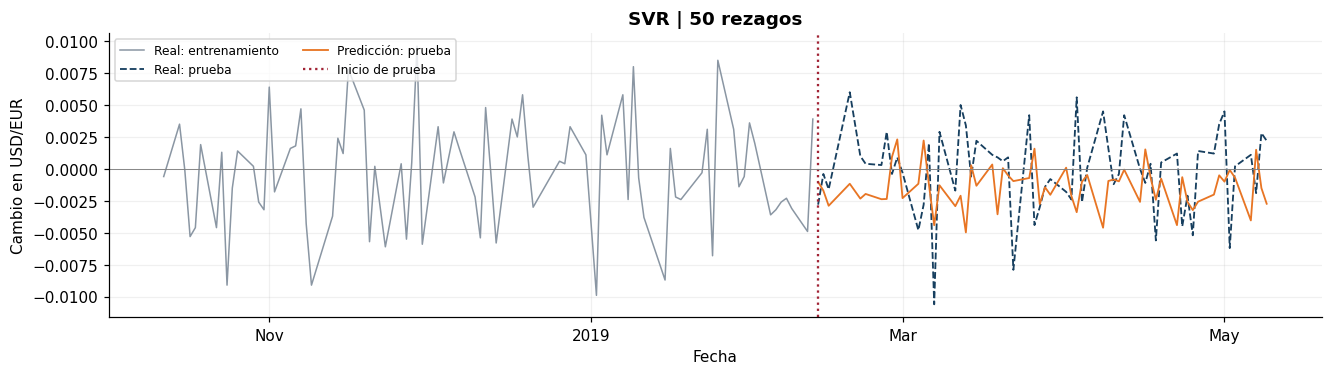

Tiempo de ajuste y predicción: 0.34 s


In [12]:
modelo_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel='rbf', C=1, gamma=0.04, epsilon=0.01)
)
entrenar_y_evaluar('SVR', modelo_svr, numero_rezagos=REZAGOS_SVR)

#### 7.4 Regresión por descenso de gradiente estocástico, SGD

Aprende una relación lineal actualizando sus coeficientes de manera iterativa. Se estandarizan las entradas. Respecto al ejemplo del capítulo, se amplía el máximo a 2,000 iteraciones, se reduce el paso inicial a `0.001` y se usa tolerancia `0.0000001` para favorecer la estabilidad con 500 predictores. Estos valores se fijan de antemano; no se eligen buscando mejorar la prueba.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.007213,0.005339,59.367000,0.345789,1.037459
Prueba,0.005393,0.004065,47.906977,-0.041212,1.071291


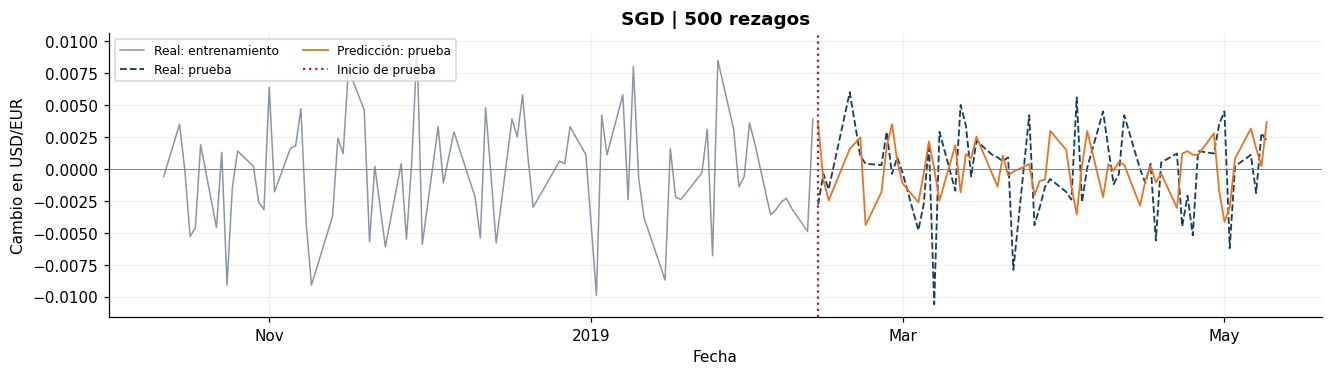

Tiempo de ajuste y predicción: 0.18 s


In [13]:
modelo_sgd = make_pipeline(
    StandardScaler(),
    SGDRegressor(max_iter=2000, tol=1e-7, eta0=0.001, random_state=SEMILLA)
)
entrenar_y_evaluar('SGD', modelo_sgd)

#### 7.5 Vecinos más cercanos, KNN

Predice mediante el promedio de las respuestas de las 10 ventanas más cercanas. Se conservan las diferencias en su escala original, como en el ejemplo. Con 500 rezagos, la distancia puede perder capacidad para distinguir ventanas realmente informativas.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.007024,0.005187,64.719572,0.493571,0.841699
Prueba,0.005211,0.003900,51.162791,-0.008258,0.658951


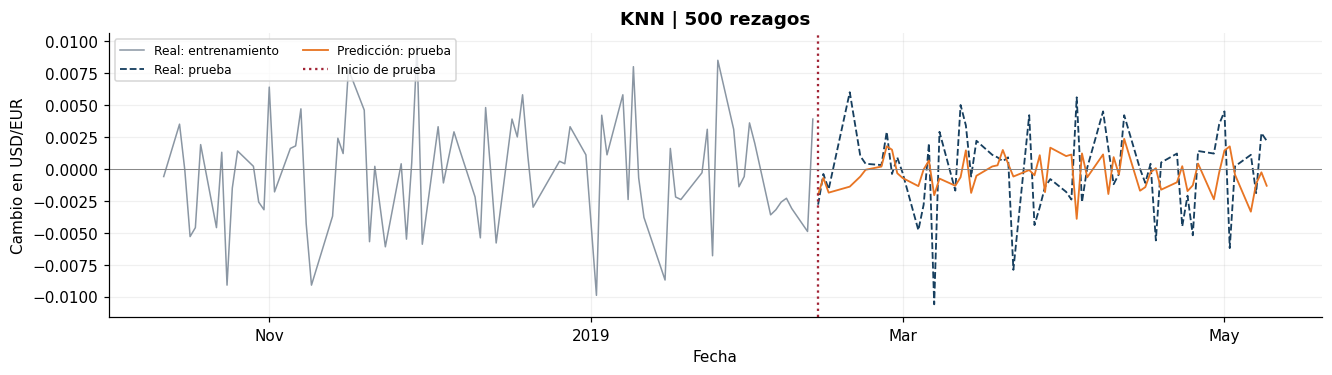

Tiempo de ajuste y predicción: 0.32 s


In [14]:
entrenar_y_evaluar('KNN', KNeighborsRegressor(n_neighbors=10, n_jobs=2))

#### 7.6 Árbol de decisión

Divide los datos mediante reglas hasta construir grupos con respuestas similares. Se deja sin límite de profundidad, como en el capítulo, para observar la diferencia entre memorizar el entrenamiento y generalizar.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.000000,0.000000,100.000000,1.000000,1.015618
Prueba,0.007117,0.005489,51.348837,0.043441,0.759536


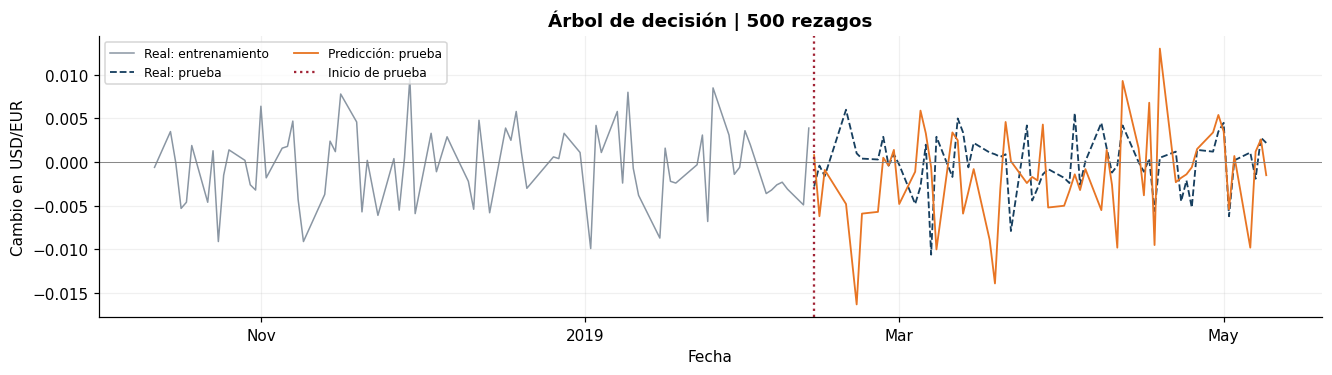

Tiempo de ajuste y predicción: 6.20 s


In [15]:
entrenar_y_evaluar('Árbol de decisión', DecisionTreeRegressor(random_state=SEMILLA))

#### 7.7 Bosque aleatorio

Combina y promedia las predicciones de 100 árboles, entrenados sobre muestras con reemplazo y selección aleatoria de variables en las divisiones. Se fija profundidad máxima de 20, como en el ejemplo. Promediar árboles puede reducir la variabilidad, pero no garantiza superar la referencia.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.005796,0.004511,81.754713,0.820036,1.585439
Prueba,0.005064,0.003761,49.023256,-0.004121,4.143541


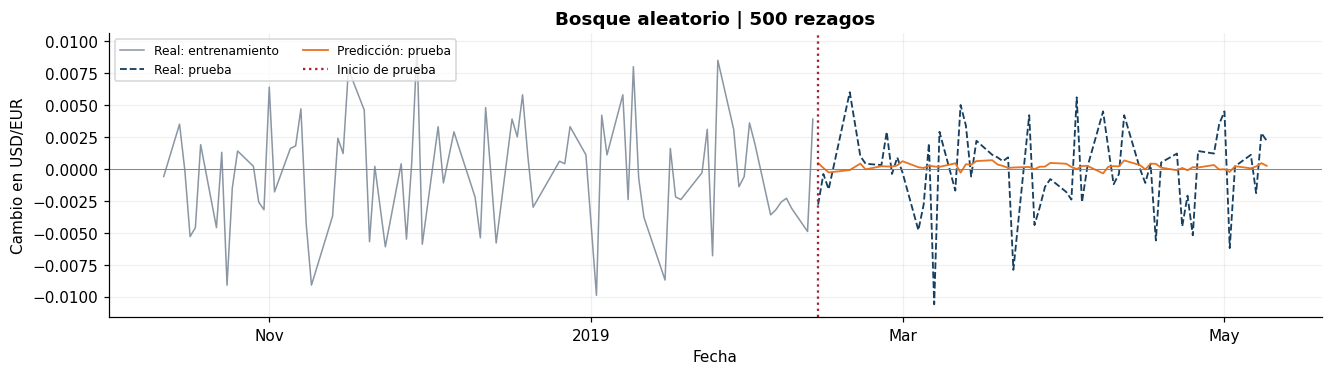

Tiempo de ajuste y predicción: 88.52 s


In [16]:
modelo_bosque = RandomForestRegressor(
    n_estimators=100, max_depth=20, random_state=SEMILLA, n_jobs=2
)
entrenar_y_evaluar('Bosque aleatorio', modelo_bosque)

#### 7.8 AdaBoost

Entrena regresores débiles de manera secuencial y da más atención a observaciones difíciles. Se usan 50 estimadores y una semilla fija. En `AdaBoostRegressor` de scikit-learn, la salida se calcula con una **mediana ponderada** de las predicciones. No debe confundirse con una votación de clases ni con el ajuste de residuos de gradient boosting.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.007260,0.005515,51.268327,0.376999,0.079106
Prueba,0.005104,0.003809,50.697674,0.014074,0.019924


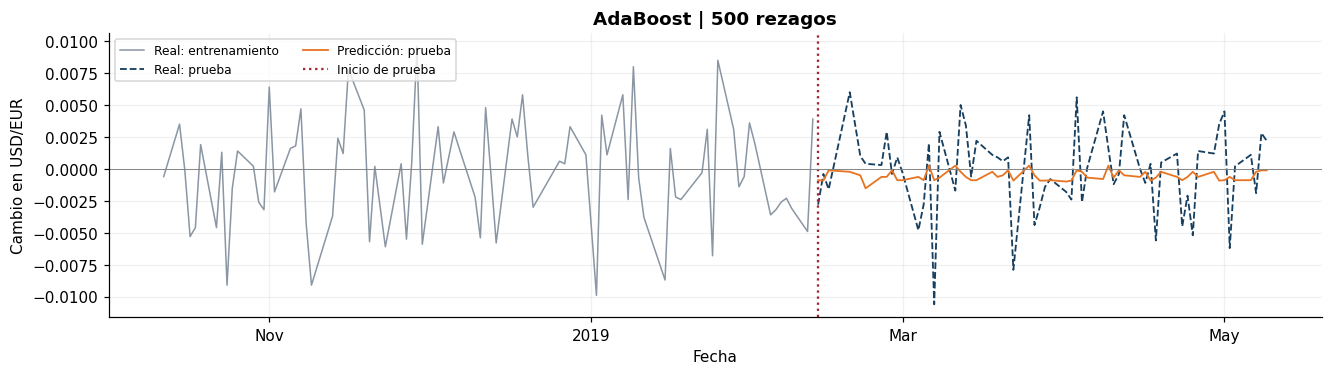

Tiempo de ajuste y predicción: 15.84 s


In [17]:
entrenar_y_evaluar('AdaBoost', AdaBoostRegressor(n_estimators=50, random_state=SEMILLA))

#### 7.9 XGBoost

Agrega árboles para reducir progresivamente la función de pérdida y permite regularización. Se mantienen los 16 árboles y la profundidad máxima de 12 del capítulo. Se especifica pérdida cuadrática y cálculo en CPU mediante histogramas; no se necesita GPU.

,rmse,mae,acierto_pct,correlacion,sesgo
particion,,,,,
Entrenamiento,0.000747,0.000522,97.858971,0.997750,1.024023
Prueba,0.005445,0.004058,49.488372,0.002512,0.950998


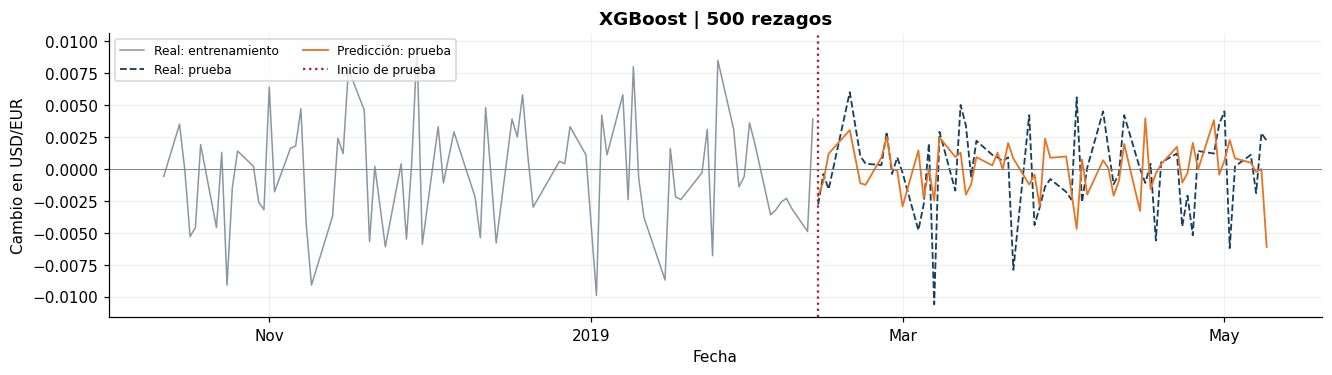

Tiempo de ajuste y predicción: 12.13 s


In [18]:
modelo_xgb = XGBRegressor(
    n_estimators=16, max_depth=12, random_state=SEMILLA,
    objective='reg:squarederror', tree_method='hist', n_jobs=2
)
entrenar_y_evaluar('XGBoost', modelo_xgb)

### 8. Comparación de resultados

Se comparan los nueve métodos en las mismas fechas de prueba. La mejora de RMSE respecto a la referencia se calcula como:

`100 × (RMSE de referencia - RMSE del modelo) / RMSE de referencia`.

Un porcentaje positivo indica menor error que la referencia; uno negativo indica mayor error. Ordenar esta tabla describe el resultado de este periodo. Elegir un modelo a partir de ella necesitaría confirmación en un periodo posterior independiente.

,rezagos,rmse_train,rmse,mae,mejora_rmse_pct
modelo_id,,,,,
Referencia: media,500,0.007686,0.005052,0.003751,0.000000
Bosque aleatorio,500,0.005796,0.005064,0.003761,-0.231751
AdaBoost,500,0.007260,0.005104,0.003809,-1.024685
KNN,500,0.007024,0.005211,0.003900,-3.147186
SVR,50,0.005968,0.005324,0.004035,-5.394478
SGD,500,0.007213,0.005393,0.004065,-6.747260
Regresión lineal,500,0.007209,0.005439,0.004112,-7.668211
XGBoost,500,0.000747,0.005445,0.004058,-7.780870
Árbol de decisión,500,0.000000,0.007117,0.005489,-40.872726


,acierto_pct,correlacion,sesgo
modelo_id,,,
Referencia: media,49.3953,NaN,NaN
Bosque aleatorio,49.0233,-0.0041,4.1435
AdaBoost,50.6977,0.0141,0.0199
KNN,51.1628,-0.0083,0.6590
SVR,50.5116,0.0041,0.3961
SGD,47.9070,-0.0412,1.0713
Regresión lineal,48.5581,-0.0406,1.0673
XGBoost,49.4884,0.0025,0.9510
Árbol de decisión,51.3488,0.0434,0.7595


rmse y mae: prueba, en USD/EUR. Los valores NaN indican métricas no definidas.


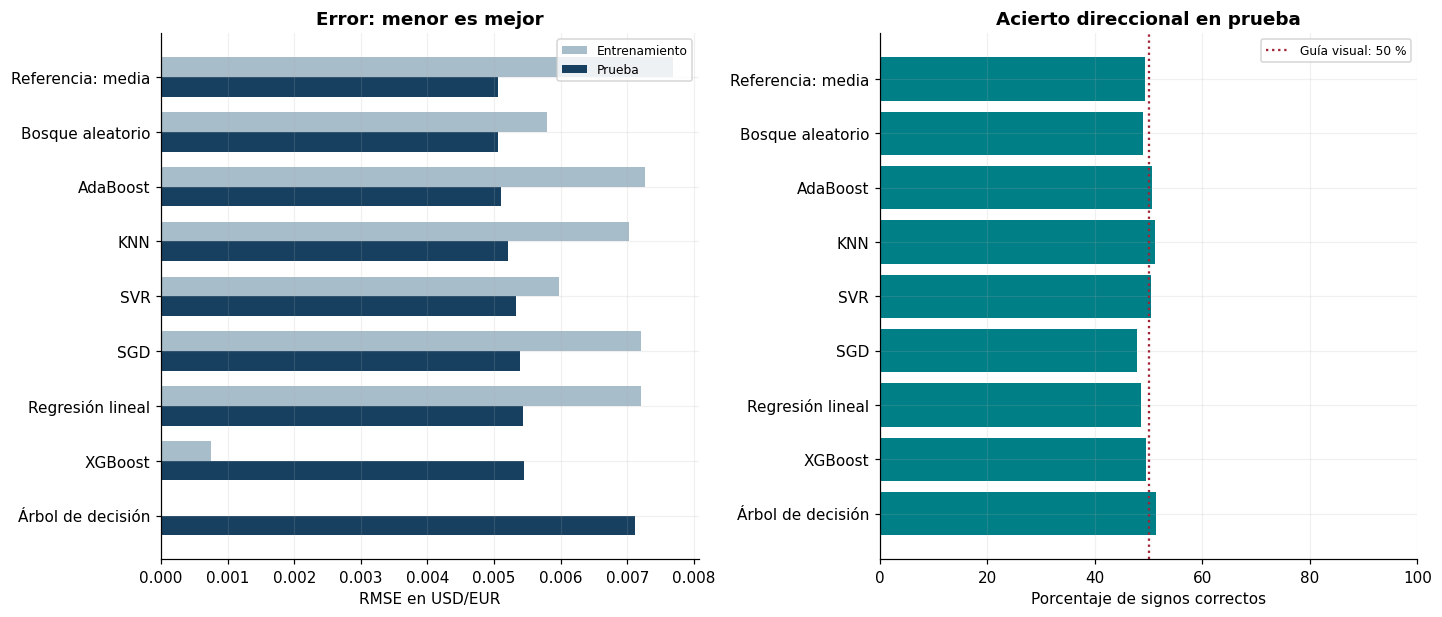

In [19]:
metricas = pd.DataFrame(resultados)
prueba = metricas[metricas['particion'] == 'Prueba'].set_index('modelo_id').copy()
entrenamiento = metricas[metricas['particion'] == 'Entrenamiento'].set_index('modelo_id')
rmse_referencia = prueba.loc['Referencia: media', 'rmse']
comparacion = prueba[['rmse', 'mae', 'acierto_pct', 'correlacion', 'sesgo']].copy()
comparacion['rmse_train'] = entrenamiento['rmse']
comparacion['rezagos'] = pd.Series(rezagos_modelo)
comparacion['mejora_rmse_pct'] = 100 * (rmse_referencia - comparacion['rmse']) / rmse_referencia
comparacion = comparacion.sort_values('rmse')
display(comparacion[['rezagos', 'rmse_train', 'rmse', 'mae', 'mejora_rmse_pct']].round(6))
display(comparacion[['acierto_pct', 'correlacion', 'sesgo']].round(4))
print('rmse y mae: prueba, en USD/EUR. Los valores NaN indican métricas no definidas.')

orden = comparacion.index.tolist()
posiciones = np.arange(len(orden))
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained')
ejes[0].barh(posiciones - 0.18, entrenamiento.loc[orden, 'rmse'], height=0.36,
             color='#A7BDC9', label='Entrenamiento')
ejes[0].barh(posiciones + 0.18, prueba.loc[orden, 'rmse'], height=0.36,
             color='#173F5F', label='Prueba')
ejes[0].set_yticks(posiciones, orden)
ejes[0].invert_yaxis()
ejes[0].set(title='Error: menor es mejor', xlabel='RMSE en USD/EUR')
ejes[0].legend(fontsize=8)
ejes[1].barh(posiciones, prueba.loc[orden, 'acierto_pct'], color='#007F86')
ejes[1].set_yticks(posiciones, orden)
ejes[1].invert_yaxis()
ejes[1].set(title='Acierto direccional en prueba', xlabel='Porcentaje de signos correctos', xlim=(0, 100))
ejes[1].axvline(50, linestyle=':', color='#A12335', label='Guía visual: 50 %')
ejes[1].legend(fontsize=8)
plt.show()

#### Ejemplo de revisión de predicciones

Se muestran las primeras ocho observaciones de prueba de la regresión lineal para comprobar qué se compara. La fecha de origen siempre precede a la fecha objetivo. El error es `valor observado - valor predicho`.

In [20]:
ejemplo = supervisado[['fecha_origen', 'fecha', 'objetivo']].iloc[corte:corte + 8].copy()
ejemplo['prediccion_lineal'] = predicciones_test['Regresión lineal'][:8]
ejemplo['error'] = ejemplo['objetivo'] - ejemplo['prediccion_lineal']
ejemplo['signo_correcto'] = np.sign(ejemplo['objetivo']) == np.sign(ejemplo['prediccion_lineal'])
display(ejemplo.reset_index(drop=True))

,fecha_origen,fecha,objetivo,prediccion_lineal,error,signo_correcto
0,2019-02-12,2019-02-13,-0.0028,0.003870,-0.006670,False
1,2019-02-13,2019-02-14,-0.0004,-0.001383,0.000983,True
2,2019-02-14,2019-02-15,-0.0016,-0.002554,0.000954,True
3,2019-02-15,2019-02-19,0.0060,0.001656,0.004344,True
4,2019-02-19,2019-02-21,0.0010,0.002812,-0.001812,True
5,2019-02-21,2019-02-22,0.0004,-0.004498,0.004898,False
6,2019-02-22,2019-02-25,0.0003,-0.002198,0.002498,False
7,2019-02-25,2019-02-26,0.0029,0.001736,0.001164,True


### 9. Sobreajuste, subajuste y validación temporal

**Sobreajuste:** un modelo aprende detalles o ruido del entrenamiento y pierde desempeño en datos posteriores. Un árbol que tiene error casi cero en entrenamiento y mucho mayor en prueba es una señal clara de este problema.

**Subajuste:** el modelo no representa relaciones relevantes de los datos. La referencia constante ilustra un modelo muy simple, pero que otros métodos no la superen no prueba por sí solo que exista una relación explotable que esté dejando de aprenderse. El ruido y los cambios de mercado también pueden explicar los resultados.

Se compara adicionalmente la profundidad de un árbol mediante tres particiones temporales **solo dentro del entrenamiento**. Cada partición entrena con un bloque inicial y valida con el bloque siguiente, sin barajar observaciones. El bloque final de prueba no interviene en esta comparación. Se conservan los modelos principales tal como se definieron.

In [21]:
validacion_temporal = TimeSeriesSplit(n_splits=3)
filas_cv = []
for profundidad in [2, 5, 10, None]:
    errores_ajuste, errores_validacion = [], []
    for indices_ajuste, indices_validacion in validacion_temporal.split(x_train):
        assert indices_ajuste.max() < indices_validacion.min()
        arbol = DecisionTreeRegressor(max_depth=profundidad, random_state=SEMILLA)
        with threadpool_limits(limits=2):
            arbol.fit(x_train[indices_ajuste], y_train[indices_ajuste])
            pred_ajuste = arbol.predict(x_train[indices_ajuste])
            pred_validacion = arbol.predict(x_train[indices_validacion])
        errores_ajuste.append(np.sqrt(mean_squared_error(y_train[indices_ajuste], pred_ajuste)))
        errores_validacion.append(np.sqrt(mean_squared_error(y_train[indices_validacion], pred_validacion)))
    filas_cv.append({
        'profundidad': 'Sin límite' if profundidad is None else str(profundidad),
        'rmse_ajuste_cv': np.mean(errores_ajuste),
        'rmse_validacion_cv': np.mean(errores_validacion),
        'desviacion_validacion_cv': np.std(errores_validacion, ddof=1),
    })
tabla_cv = pd.DataFrame(filas_cv).sort_values('rmse_validacion_cv').reset_index(drop=True)
display(tabla_cv.round(6))
display(Markdown(
    f'En esta comparación interna, la profundidad con menor RMSE medio de validación es '
    f'**{tabla_cv.iloc[0]["profundidad"]}**. Es una candidata para una siguiente etapa; '
    'el promedio de tres bloques no garantiza el desempeño de un periodo nuevo.'
))

,profundidad,rmse_ajuste_cv,rmse_validacion_cv,desviacion_validacion_cv
0,2,0.007664,0.007895,0.001747
1,5,0.007302,0.008082,0.001968
2,10,0.006321,0.008656,0.002541
3,Sin límite,0.000000,0.010882,0.001547


En esta comparación interna, la profundidad con menor RMSE medio de validación es **2**. Es una candidata para una siguiente etapa; el promedio de tres bloques no garantiza el desempeño de un periodo nuevo.

#### Métricas financieras mencionadas en el capítulo

| Métrica | Qué describe |
|---|---|
| Rendimiento neto | Variación del capital después de los costos |
| Factor de beneficio | Ganancias acumuladas divididas entre pérdidas acumuladas, en valor absoluto |
| Ganancia y pérdida media | Resultado promedio de operaciones ganadoras y perdedoras por separado |
| Máxima caída o drawdown | Mayor descenso porcentual del capital respecto a un máximo previo |
| Razón de Sharpe | Retorno medio en exceso de la tasa libre de riesgo dividido entre volatilidad, con periodos compatibles |

El capítulo desarrolla principalmente la evaluación del pronóstico. Este avance no define órdenes, posiciones, capital, comisiones ni diferenciales de compra y venta; por eso no calcula rentabilidad de una estrategia. Un porcentaje alto de signos correctos no equivale automáticamente a ganancias. La referencia de 50 % de la gráfica es solo una guía visual y no una prueba de significancia.

### 10. Registro de resultados y consultas SQL

Se almacenan los parámetros de cada modelo, sus métricas de entrenamiento y prueba, y las predicciones del periodo de prueba. Esto permite consultar y comprobar resultados sin volver a entrenar.

In [22]:
for nombre, modelo in modelos_entrenados.items():
    parametros = json.dumps(modelo.get_params(deep=True), ensure_ascii=False, default=str, sort_keys=True)
    conexion.execute('INSERT INTO modelos VALUES (?, ?, ?)',
                     (nombre, rezagos_modelo[nombre], parametros))

# pandas convierte los valores no definidos en NULL al escribir en SQLite.
columnas_metricas = ['modelo_id', 'particion', 'n', 'mae', 'mse', 'rmse',
                     'acierto_pct', 'correlacion', 'sesgo', 'positivas', 'negativas', 'ceros']
metricas[columnas_metricas].to_sql('metricas', conexion, if_exists='append', index=False)

filas_predicciones = []
fechas_objetivo = supervisado['fecha'].iloc[corte:]
fechas_origen = supervisado['fecha_origen'].iloc[corte:]
for nombre, predicho in predicciones_test.items():
    for fecha, origen, real, pred in zip(fechas_objetivo, fechas_origen, y_test, predicho):
        filas_predicciones.append((nombre, 'DEXUSEU', fecha.strftime('%Y-%m-%d'),
                                   origen.strftime('%Y-%m-%d'), float(real), float(pred)))
conexion.executemany('INSERT INTO predicciones VALUES (?, ?, ?, ?, ?, ?)', filas_predicciones)

configuracion = {
    'rezagos_principales': REZAGOS, 'rezagos_svr': REZAGOS_SVR,
    'fraccion_entrenamiento': FRACCION_ENTRENAMIENTO, 'semilla': SEMILLA,
    'objetivo': 'Diferencia absoluta entre observaciones consecutivas',
    'horizonte': 'Siguiente observación publicada',
    'evaluacion': 'Un paso con datos previos observados; modelo fijo',
    'fecha_inicio_prueba': fechas_test.min().strftime('%Y-%m-%d'),
    'fecha_fin_prueba': fechas_test.max().strftime('%Y-%m-%d'),
}
conexion.execute('INSERT INTO ejecucion VALUES (?, ?, ?, ?, ?)', (
    1, P_FECHA, CSV_SHA256, json.dumps(configuracion, ensure_ascii=False),
    json.dumps(dict(zip(versiones['Componente'], versiones['Versión'])), ensure_ascii=False)
))
conexion.commit()

display(pd.read_sql_query("""
SELECT m.modelo_id AS modelo, m.rezagos,
       ROUND(e.rmse, 6) AS rmse_prueba,
       ROUND(e.acierto_pct, 2) AS acierto_pct
FROM modelos AS m JOIN metricas AS e ON m.modelo_id = e.modelo_id
WHERE e.particion = 'Prueba'
ORDER BY e.rmse
""", conexion))

,modelo,rezagos,rmse_prueba,acierto_pct
0,Referencia: media,500,0.005052,49.40
1,Bosque aleatorio,500,0.005064,49.02
2,AdaBoost,500,0.005104,50.70
3,KNN,500,0.005211,51.16
4,SVR,50,0.005324,50.51
5,SGD,500,0.005393,47.91
6,Regresión lineal,500,0.005439,48.56
7,XGBoost,500,0.005445,49.49
8,Árbol de decisión,500,0.007117,51.35


In [23]:
# Comprobación independiente del MAE mediante SQL.
mae_sql = pd.read_sql_query("""
SELECT modelo_id, COUNT(*) AS n_predicciones,
       AVG(ABS(valor_real - valor_predicho)) AS mae_sql
FROM predicciones
GROUP BY modelo_id
""", conexion).set_index('modelo_id')
assert np.allclose(mae_sql.loc[prueba.index, 'mae_sql'], prueba['mae'])
assert (mae_sql['n_predicciones'] == len(y_test)).all()
assert conexion.execute('SELECT COUNT(*) FROM modelos').fetchone()[0] == 9
assert conexion.execute('SELECT COUNT(*) FROM metricas').fetchone()[0] == 18
assert conexion.execute('PRAGMA foreign_key_check').fetchall() == []
assert conexion.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
display(mae_sql.round(6))
print('Comprobaciones correctas: 9 métodos, 18 registros de métricas y un registro por fecha y modelo en prueba.')

,n_predicciones,mae_sql
modelo_id,,
AdaBoost,1075,0.003809
Bosque aleatorio,1075,0.003761
KNN,1075,0.003900
Referencia: media,1075,0.003751
Regresión lineal,1075,0.004112
SGD,1075,0.004065
SVR,1075,0.004035
XGBoost,1075,0.004058
Árbol de decisión,1075,0.005489


Comprobaciones correctas: 9 métodos, 18 registros de métricas y un registro por fecha y modelo en prueba.


### 11. Conclusiones del desarrollo

Las conclusiones cuantitativas siguientes se calculan a partir de los resultados obtenidos en esta ejecución. Se distingue entre el menor error observado y la capacidad de generalizar a un periodo todavía no utilizado.

In [24]:
mejor = comparacion.index[0]
mejor_ml = comparacion.drop(index='Referencia: media').index[0]
mejora_ml = float(comparacion.loc[mejor_ml, 'mejora_rmse_pct'])
mejor_signo = prueba['acierto_pct'].idxmax()
tree_train = entrenamiento.loc['Árbol de decisión', 'rmse']
tree_test = prueba.loc['Árbol de decisión', 'rmse']
superan = comparacion.drop(index='Referencia: media').query('mejora_rmse_pct > 0')

conclusion_error = (
    f'{len(superan)} de los ocho modelos superaron a la referencia en RMSE en este periodo. '
    f'La mayor mejora fue de **{mejora_ml:.2f} %**, con **{mejor_ml}**.'
    if len(superan) else
    f'**Ninguno de los ocho modelos superó a la referencia en RMSE**. '
    f'El de menor error entre ellos fue **{mejor_ml}**, con una variación de '
    f'**{mejora_ml:.2f} %** respecto a la referencia.'
)
display(Markdown(f"""
1. Se conservaron **{len(datos):,} filas originales** y se identificaron **{datos['valor'].isna().sum():,} valores faltantes**. Se trabajó con **{len(precios):,} cotizaciones válidas** y **{len(supervisado):,} ejemplos supervisados** después de la diferenciación y los 500 rezagos.
2. La separación produjo **{len(y_train):,} ejemplos de entrenamiento** y **{len(y_test):,} de prueba**. Todos los métodos se evaluaron sobre las mismas fechas objetivo, desde **{fechas_test.min().date()}** hasta **{fechas_test.max().date()}**.
3. El menor RMSE de prueba entre los nueve métodos correspondió a **{mejor}**. {conclusion_error}
4. El mayor acierto direccional observado fue de **{prueba.loc[mejor_signo, 'acierto_pct']:.2f} %**, con **{mejor_signo}**. Esta comparación no incorpora una prueba estadística ni demuestra rentabilidad.
5. El árbol sin límite obtuvo RMSE de **{tree_train:.8f}** en entrenamiento y **{tree_test:.8f}** en prueba. La brecha muestra por qué un ajuste casi perfecto del pasado no basta para aceptar un modelo.
6. Se integró una base relacional con claves y consultas SQL. El MAE obtenido directamente desde las predicciones almacenadas coincide con el calculado en Python.

**Interpretación:** este avance permite comprobar el procedimiento del capítulo y comparar modelos con datos históricos reales. Los resultados no se copian de las tablas del libro: cambian con la fuente de datos, el periodo, la alineación de fechas y las versiones de las bibliotecas.
"""))


1. Se conservaron **6,109 filas originales** y se identificaron **236 valores faltantes**. Se trabajó con **5,873 cotizaciones válidas** y **5,372 ejemplos supervisados** después de la diferenciación y los 500 rezagos.
2. La separación produjo **4,297 ejemplos de entrenamiento** y **1,075 de prueba**. Todos los métodos se evaluaron sobre las mismas fechas objetivo, desde **2019-02-13** hasta **2023-06-01**.
3. El menor RMSE de prueba entre los nueve métodos correspondió a **Referencia: media**. **Ninguno de los ocho modelos superó a la referencia en RMSE**. El de menor error entre ellos fue **Bosque aleatorio**, con una variación de **-0.23 %** respecto a la referencia.
4. El mayor acierto direccional observado fue de **51.35 %**, con **Árbol de decisión**. Esta comparación no incorpora una prueba estadística ni demuestra rentabilidad.
5. El árbol sin límite obtuvo RMSE de **0.00000000** en entrenamiento y **0.00711678** en prueba. La brecha muestra por qué un ajuste casi perfecto del pasado no basta para aceptar un modelo.
6. Se integró una base relacional con claves y consultas SQL. El MAE obtenido directamente desde las predicciones almacenadas coincide con el calculado en Python.

**Interpretación:** este avance permite comprobar el procedimiento del capítulo y comparar modelos con datos históricos reales. Los resultados no se copian de las tablas del libro: cambian con la fuente de datos, el periodo, la alineación de fechas y las versiones de las bibliotecas.


#### Limitaciones del capítulo

- Se utiliza una sola serie y únicamente sus diferencias rezagadas. No se incorporan noticias ni variables económicas externas.
- Los 500 rezagos se adoptan del capítulo como punto de partida; no se afirma que sean la mejor elección.
- El periodo final de prueba ya quedó observado en este desarrollo. Una futura selección o modificación de modelos debe confirmarse con datos posteriores que todavía no se hayan utilizado para decidir.
- SVR utiliza 50 entradas y los demás modelos, 500. La comparación controla las fechas, pero no aísla el efecto de usar distinta cantidad de variables.
- Queda pendiente probar diferentes cantidades de rezagos y regularización mediante validación temporal dentro del entrenamiento, examinar estacionariedad y estabilidad de volatilidad, y documentar nuevas fuentes si se incorporan.
- La automatización de actualizaciones de la base y un posible análisis de operaciones con costos corresponden a etapas posteriores.

**Adaptaciones respecto al material:** se usa la alternativa FRED del propio capítulo; se adopta frecuencia diaria aunque un fragmento del PDF menciona `H1`; se incluyen las funciones dentro del cuaderno; se alinean las fechas de todos los métodos; se explicita el tratamiento de ceros y métricas no definidas; y se ajustan los parámetros de convergencia de SGD. Se agrega SQLite y una validación temporal para la materia.

### 12. Exportación de los resultados

Al ejecutar esta sección se crean los siguientes archivos en `salidas_capitulo7`. El notebook conserva además sus propias tablas y gráficas.

| Archivo | Contenido |
|---|---|
| `eurusd_capitulo7.sqlite` | Base de datos con observaciones, modelos, métricas y predicciones |
| `datos_originales_fred.csv` | Copia exacta de los datos consultados |
| `metricas_modelos.csv` | Métricas de entrenamiento y prueba |
| `comparacion_modelos.csv` | Comparación de los modelos |
| `predicciones_prueba.csv` | Valores observados y predichos por fecha y modelo |
| `validacion_temporal.csv` | Comparación interna de profundidades del árbol |

In [25]:
carpeta = Path.cwd() / 'salidas_capitulo7'
carpeta.mkdir(exist_ok=True)
(carpeta / 'datos_originales_fred.csv').write_bytes(csv_original)
metricas.to_csv(carpeta / 'metricas_modelos.csv', index=False)
comparacion.to_csv(carpeta / 'comparacion_modelos.csv', index_label='modelo_id')
tabla_cv.to_csv(carpeta / 'validacion_temporal.csv', index=False)
pd.read_sql_query('SELECT * FROM predicciones ORDER BY modelo_id, fecha_objetivo', conexion).to_csv(
    carpeta / 'predicciones_prueba.csv', index=False)
with sqlite3.connect(carpeta / 'eurusd_capitulo7.sqlite') as archivo_db:
    conexion.backup(archivo_db)
print('Archivos creados en la carpeta salidas_capitulo7:')
for archivo in sorted(carpeta.iterdir()):
    print(f'  {archivo.name}: {archivo.stat().st_size:,} bytes')

Archivos creados en la carpeta salidas_capitulo7:
  comparacion_modelos.csv: 1,439 bytes
  datos_originales_fred.csv: 108,571 bytes
  eurusd_capitulo7.sqlite: 1,413,120 bytes
  metricas_modelos.csv: 2,868 bytes
  predicciones_prueba.csv: 830,472 bytes
  validacion_temporal.csv: 347 bytes


### 13. Referencias

1. Kaabar, S. (2024). *Deep Learning for Finance*. O'Reilly Media. Capítulo 7, “Machine Learning Models for Time Series Prediction”. Material de referencia proporcionado en clase: PDF adjunto de 61 páginas.
2. Board of Governors of the Federal Reserve System (US). (s. f.). *U.S. Dollars to Euro Spot Exchange Rate [DEXUSEU]*. FRED, Federal Reserve Bank of St. Louis. Recuperado el 5 de noviembre de 2026 de https://fred.stlouisfed.org/series/DEXUSEU
3. Kaabar, S. (s. f.). *deep-learning-for-finance* [Repositorio oficial del libro]. GitHub. https://github.com/sofienkaabar/deep-learning-for-finance
4. Scikit-learn developers. (s. f.). *AdaBoostRegressor*. Documentación oficial. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostRegressor.html
5. Scikit-learn developers. (s. f.). *TimeSeriesSplit*. Documentación oficial. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html
6. XGBoost developers. (s. f.). *Python API Reference: XGBRegressor*. Documentación oficial. https://xgboost.readthedocs.io/en/stable/python/python_api.html

El texto explicativo y las funciones de este cuaderno son una adaptación didáctica del marco del capítulo. Las métricas, tablas, predicciones y gráficas corresponden a la ejecución del código incluido, utilizando el conjunto de datos documentado.

In [26]:
# Registrar las versiones de cada sección sin modificar sus variables.
P_VERSIONES['capitulo_7'] = (dict(zip(versiones['Componente'],versiones['Versión']))
    if isinstance(versiones,pd.DataFrame) else dict(versiones))

## Capítulo 8. Aprendizaje profundo para series temporales I

Esta sección conserva el desarrollo del avance y vuelve a ejecutar sus experimentos con los datos incluidos. Las referencias y limitaciones específicas se mantienen al final del capítulo.

#### Correspondencia con el material

Los números corresponden a las páginas del PDF adjunto de 51 páginas.

| Apartado del capítulo | Páginas | Desarrollo en este notebook |
|---|---:|---|
| Neuronas, capas y propagación hacia adelante | 1-5 | Explicación y cálculo de una neurona |
| Funciones de activación | 5-13 | Sigmoide, tanh, ReLU y leaky ReLU; fórmulas y gráficas |
| Retropropagación | 13-16 | Gradientes y una actualización numérica de pesos |
| Optimizadores y regularización | 16-19 | GD, SGD, Adam, RMSprop, dropout y parada temprana |
| Perceptrón multicapa | 19-26 | MLP, tabla de capas y curva de pérdida |
| Red recurrente simple | 27-31 | SimpleRNN con entrada tridimensional |
| LSTM | 31-37 | Memoria, compuertas y entrenamiento |
| Ejemplo de serie sencilla y R² | 37-42 | Serie simulada, regresión lineal y MLP |
| CNN temporal | 42-48 | Conv1D, MaxPooling1D y predicción |
| Desafíos y conclusiones | 49-51 | Interpretación, límites y siguientes pasos |

**Pregunta del proyecto:** ¿estas redes consiguen predecir el siguiente cambio del S&P 500 mejor que un modelo que responde con la media del periodo de ajuste?

El objetivo es implementar y comprender el procedimiento, conservar la trazabilidad de los datos y evaluar observaciones posteriores sin usarlas para entrenar o elegir la época de la red. No se presupone que una red más compleja obtenga mejores resultados.

### 1. Preparación del entorno

Se utiliza Keras con TensorFlow, como en el material. También se necesitan NumPy, pandas, Matplotlib y scikit-learn. SQLite está incluido en Python. Las semillas y las versiones se registran; una ejecución en otra plataforma o versión puede producir pequeñas diferencias numéricas.

In [27]:
import base64
import gzip
import hashlib
import io
import json
import sqlite3
from pathlib import Path
from time import perf_counter
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf
import keras
from keras import layers
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

SEMILLA = 123
REZAGOS = 100
FRACCION_DESARROLLO = 0.80
FRACCION_AJUSTE_INTERNO = 0.80
PACIENCIA = 10
keras.utils.set_random_seed(SEMILLA)
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    pass  # Una sesión ya iniciada puede tener su configuración fijada.
tf.config.experimental.enable_op_determinism()

pd.set_option('display.precision', 6)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.18,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
})
versiones = pd.DataFrame({
    'Componente': ['Python', 'NumPy', 'pandas', 'Matplotlib', 'scikit-learn', 'TensorFlow', 'Keras', 'SQLite'],
    'Versión': [sys.version.split()[0], version('numpy'), version('pandas'),
                version('matplotlib'), version('scikit-learn'), tf.__version__,
                keras.__version__, sqlite3.sqlite_version],
})
display(versiones)

,Componente,Versión
0,Python,3.12.14
1,NumPy,2.3.5
2,pandas,2.2.3
3,Matplotlib,3.10.8
4,scikit-learn,1.8.0
5,TensorFlow,2.20.0
6,Keras,3.12.0
7,SQLite,3.53.1


### 2. ¿Qué calcula una red neuronal?

Una neurona recibe entradas $x_i$, las multiplica por pesos $w_i$, agrega un sesgo $b$ y aplica una activación:

$$z=\sum_i w_i x_i+b, \qquad a=f(z).$$

La **capa de entrada** recibe los datos. Las **capas ocultas** construyen transformaciones de ellos. La **capa de salida** entrega la predicción. En este proyecto la salida es un número real, por lo que se utiliza una neurona final lineal que permite tanto aumentos como disminuciones.

Los pesos y el sesgo se aprenden durante el entrenamiento. Una **época** es un recorrido por el conjunto de ajuste; un **lote** es un grupo de observaciones usado para una actualización de parámetros.

#### Funciones de activación

| Función | Expresión | Rango | Observación |
|---|---|---|---|
| Sigmoide | $1/(1+e^{-z})$ | $(0,1)$ | Puede saturarse y reducir los gradientes |
| Tanh | $\tanh(z)$ | $(-1,1)$ | Centrada en cero, también puede saturarse |
| ReLU | $\max(0,z)$ | $[0,\infty)$ | Simple; algunas unidades pueden quedar inactivas |
| Leaky ReLU | $\max(\alpha z,z)$, $0<\alpha<1$ | Real | Conserva una pendiente pequeña para entradas negativas |

ReLU y leaky ReLU son continuas, pero no tienen una derivada única en cero. Una salida sigmoide solo puede interpretarse como probabilidad cuando el planteamiento y el entrenamiento justifican esa interpretación.

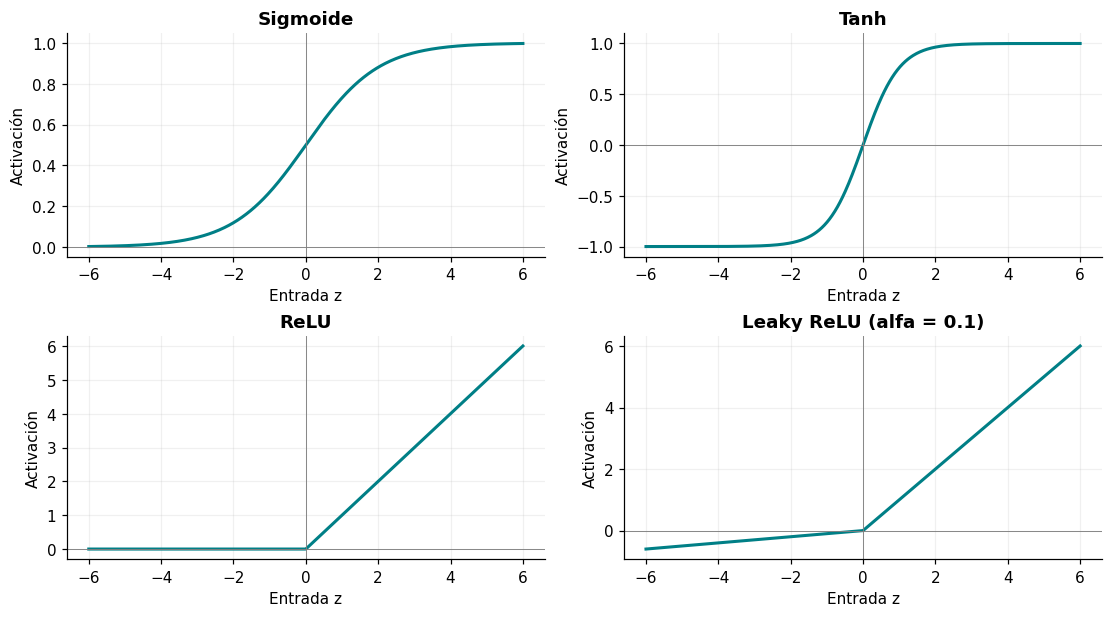

In [28]:
z = np.linspace(-6, 6, 500)
activaciones = {
    'Sigmoide': 1 / (1 + np.exp(-z)),
    'Tanh': np.tanh(z),
    'ReLU': np.maximum(0, z),
    'Leaky ReLU (alfa = 0.1)': np.where(z >= 0, z, 0.1 * z),
}
fig, ejes = plt.subplots(2, 2, figsize=(10, 5.5), layout='constrained')
for ax, (nombre, valores) in zip(ejes.flat, activaciones.items()):
    ax.plot(z, valores, color='#007F86', linewidth=2)
    ax.axhline(0, color='gray', linewidth=0.6)
    ax.axvline(0, color='gray', linewidth=0.6)
    ax.set(title=nombre, xlabel='Entrada z', ylabel='Activación')
plt.show()

#### Retropropagación: un cálculo pequeño

La propagación hacia adelante obtiene la predicción. La retropropagación aplica la regla de la cadena para calcular cómo cambia la pérdida al modificar cada peso. El optimizador usa esos gradientes para actualizar parámetros. Para el ejemplo siguiente:

$$L=\tfrac12(\hat y-y)^2,\qquad
\frac{\partial L}{\partial w_i}=(\hat y-y)f'(z)x_i,\qquad
w_i^{nuevo}=w_i-\eta\frac{\partial L}{\partial w_i}.$$

Se utiliza una neurona ReLU con entrada positiva en la zona diferenciable. Este ejemplo es didáctico; las redes financieras utilizarán MSE y diferenciación automática de TensorFlow.

In [29]:
x_ejemplo = np.array([1.0, 2.0])
w = np.array([0.4, -0.1])
b = 0.1
objetivo_ejemplo = 0.8
tasa = 0.1
z_antes = float(x_ejemplo @ w + b)
pred_antes = max(0.0, z_antes)
perdida_antes = 0.5 * (pred_antes - objetivo_ejemplo) ** 2
grad_z = (pred_antes - objetivo_ejemplo) * float(z_antes > 0)
grad_w = grad_z * x_ejemplo
grad_b = grad_z
w_nuevos, b_nuevo = w - tasa * grad_w, b - tasa * grad_b
pred_despues = max(0.0, float(x_ejemplo @ w_nuevos + b_nuevo))
perdida_despues = 0.5 * (pred_despues - objetivo_ejemplo) ** 2
display(pd.DataFrame({
    'Etapa': ['Antes de actualizar', 'Después de actualizar'],
    'w1': [w[0], w_nuevos[0]], 'w2': [w[1], w_nuevos[1]],
    'sesgo_b': [b, b_nuevo], 'prediccion': [pred_antes, pred_despues],
    'perdida': [perdida_antes, perdida_despues],
}))
assert perdida_despues < perdida_antes
print('Una actualización en este ejemplo redujo la pérdida.')

,Etapa,w1,w2,sesgo_b,prediccion,perdida
0,Antes de actualizar,0.40,-0.1,0.10,0.3,0.125
1,Después de actualizar,0.45,0.0,0.15,0.6,0.020


Una actualización en este ejemplo redujo la pérdida.


#### Optimizadores y regularización

| Método | Idea principal |
|---|---|
| Descenso de gradiente, GD | Usa el gradiente del conjunto completo para una actualización |
| Descenso estocástico, SGD | Actualiza con observaciones o lotes; puede tener una trayectoria más irregular |
| Adam | Usa estimaciones de primer y segundo momento de los gradientes |
| RMSprop | Ajusta la escala del paso mediante promedios de gradientes cuadrados |

Las redes de este desarrollo usan **Adam** con tasa inicial de `0.001`. Ningún optimizador garantiza encontrar el mejor mínimo global de una red.

**Dropout** desactiva aleatoriamente una fracción de las activaciones durante el entrenamiento. En inferencia no las desactiva. Se aplica en una variante adicional de MLP.

**Parada temprana, o early stopping**, observa la pérdida de validación. Si deja de mejorar durante 10 épocas, termina el entrenamiento y recupera los pesos de la época de menor pérdida. La prueba final no se usa para decidir cuándo detenerse.

### 3. Datos del S&P 500 y su procedencia

Se utiliza la serie diaria **SP500** de FRED, proveniente de S&P Dow Jones Indices LLC. El dato es el nivel del índice al cierre; su unidad son **puntos del índice**, no dólares ni porcentajes.

El ejemplo del PDF solicita `1990-01-01` a `2023-06-01`. FRED informa que esta serie ofrece una ventana móvil de diez años. La descarga del **6 de noviembre de 2026** devolvió observaciones desde **2016-11-07 hasta 2023-06-01** dentro del intervalo solicitado. Se documenta ese periodo real y no se supone que se obtuvieron datos desde 1990.

**Ficha y fuente:** https://fred.stlouisfed.org/series/SP500  
**Consulta utilizada:** https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=1990-01-01&coed=2023-06-01

La celda siguiente recupera una copia comprimida del CSV consultado y comprueba su huella SHA-256. Se conservan las fechas sin valor en la base original, pero se excluyen antes de calcular diferencias. No se inventan precios, no se interpolan faltantes y no se eliminan movimientos extremos válidos.

In [30]:
# Copia comprimida de los datos reales consultados; no son datos simulados.
CSV_COMPRIMIDO = """
H4sIAAAAAAACA2V9S44GMW/cPmeZf9AS9bxFAB/AsBEvvLGBxMj5w+JDxXF2H2q6JTYpUlSJ0vznv/6ff/vf//df/uvf//M//vl/
/ct//dvPP/3P+X3/o39t/aO1f3z7pzdpv7MTOoDu71yErkJLfjuh9gHav+MQaoDG75iEhkOdPbap0Pl+5RJaCu31ewchyHX2b6Nc
DXKd9nvZVkeP9/w2CtH7T+9fr211ATR+N9vq44e/VSD94F+h2P3gjfbnjeuNLKpAPu/9tID6Pz4TqP1+h1B36E5CMwQqLy4I0X+7
EFIV9NEoVzfT9LF+2yUEuaZaiy82qGCqOhchqGCXD+pmmj7VphQVpumr/36lLcg1z++3CV1/qvTYPzT//W72CNP0NWma7qZZX5XL
TKMDa/OD+vrhb6hgqYZLI6aC+3v5JWYahTrbhWm66Ism41a7wA78jW7n/vPnEZ8wCZk67q+7i0NQB0bqIXRdxsun4Bv/HYI69vyV
Tqh7j2MQMjPpICvQotjN1KFiX0LHDVuh6zpdhNw+OpQaIXH7dMrYoQL1TLe1Q1CBDnEpEFRw1++iCsxMd9QezQDaVlGBmArUJtmW
u0vfOngnoe4vngJB1KuhphMyIXrEKIdMCAnXc+iEXKVHVY58uwoBa0lTp/oIaY/Sz2+nEHAXkf072TzcRTDuylML0P7tFBVGk9l+
G0VVc/C3qkDUDsJ24SeiDnbYCKwlatPTCEEgHQwyCKErHbCbAsFd8OIbUWJKlzvDDR1CjwitnRB6PBIB2CF8HMZwI2Q9ngjmDh2X
/rmIuNJ1FnhKF1f67r/rI4Qet/yO8tRw5YxJCEo/M5zdoeXSC3s0pe9iQDEf+G/Nm+7H+P34jab7cWqPpvvxR1+m+yH1G033Gq0n
NWG619g5S4+mCR0M8iB4ClT4sXlprsKdcg03h7Z1BiFTzseBNSxiyewx1zgE5WioG5eQjcj5O9mWmUOfKm0hYonOD/sQ6q6vK4TC
U0qPbfzw93YX+RohaGX0mMMcglY0Wrf9ILOWyli+1611GGWG20HjZWPv3caHPsUeu42PTZsOt5Y+tUuPkOsMBsTpnqJPiRCCCnQ2
f6LO8JRDm043zbmRVTkEua4Gi0voOPTG7XRP0eB6+aKZRp9abN5Mo3HtzRzTTXNLvJ3mKUMzISltLUAfA+KM8LRjznfouNft8uJ1
F9t8yjzlFueZ7ik6W4wCDfQ4GCCmWWi0yWlmmoUAnfLi/Xm/4SJDk6PbCDVAOu/l9y6z1pCPjrTMWkNT2dfVMjsMKdF+mYuMfmnm
ZS4yRKPfIHQc2pfQBdQ4ipbZwdriU3CRMb7I4xyCVnQyeWZebi3pv4PSm7UgRHkRPapTlqfgKWjro/TdNDHpA8usNWT8Tn42rDXU
66RA6//TFzxltDJIl3kKPmjxGxHX8NRmW2a0rqKmENs8Bcr5CvSCxQ7TdMal7ab5yoy23TQ9E0uDmnWlDi6Emj81CwQVaNDubMtN
U/LA7abRfLpvQtuhRrngIkNj7+KXmGl0filtmWkw5bBHM83+843mIjprX7ZlLrI3Q8p20+w/opppdD5+7rbdNNr8G93bPUXTzGfm
456iWewbkcc9RZt/c9Vxa6GtRWj4i0+I4+ZAotcImRCDo/u4p+wSLI4bTYdf54tmNKx4ylOmnDIPHPcUzSZWeRHK0Tm0FWhHNCjQ
iTHBzzZz9JLfHvcUnUMnXzRPQZ5AIcxoKv0tL04fX19p/viLvbwITegSrpjDPEVD8EsdThit/a5s6z6jzQI957nuPFjSlD8v190b
a9ethVXZR8iGcqPzXLfDKeq87jw6MY1DCFqpa4Pr1tLUcnVCKtfUKaeX5g8gYTp4zXnmt+r3wnnmd6i7a9ZCW4vSw1pTJ7nOHs0O
WKAsQsuhU9raeHHTptesNVuZQK5ZayL6BdQ+85SpQSwTY0CqiYngeggNQPt3D0LQhA6sDK6AVK45OPMAQo86ZDYheMqc38vhAUET
mh71AnV/6pYXIZfOFo09wlOmDpPaFjQx/3yjWUjHRC8Q5FqMLAqZhTT+pAcDQo/qm5eagKdMDW+NcvXpQuTEBghyaUAdpXnIpTlH
0ZdYj/3FH0AthEhRm3nK3OWDmhtNofSO5hzA1Kwwx0Tz1f28zM6DH5u36N75samJT86IwY9NzR1z3Ac/Nk9/ft58dY+nSo9wmFnW
xMGPQYW1Lcila54ihBkNL/KDevTY+JQ5jOaOHz/IHEYX0x+lV6Pxtwq01J8Ge4cd1tf+QKqC1ek8wY+tvmgt5wDW4JI5+LE16K6A
0KPmHJnMBj+21MVyMgp+DFAvEOQScjHBjy1da2eWA7YKPerovpeQqmCphjO8BT+2sOSehCAX3LU8Bbl0rJ0CocfLRVjwY0vH7aCo
MM3aZAqCH1s6GMo3wjRLl9xCTain8DdUoDNt+TgzjZp8UZ1mGh3WszQCgTQN8QnzGGnVfvgb3d78qpP82G4SkfAkP7Y1nXM9nuTH
9sj81KEDaAezeZIf22qTzhfhG1tXcj4nnOTH9tpB6Jzkx/ZZEeMcmhQbTrF1PvRheZIfO1//0wgE0knqK12pQKdlQmQQNH808/TZ
/CQ/diTD1kl+7Eiq9iQ/hqc6VQAzHcSo0hZ61Dg82RZ84/Qes+5Jfux0oR3cXU5vMcRP8mMbcVgIYViqOu8gtNymrUDbh+VahE5E
2I8QxkpLRs4gc5e56lPpLqVHcxdV9KJccJety6NeXoTRJP3fofvzfsNPdlsRzE/yY1ujj7BdWGtr/nDLU+LjTthVt/FxI1k4yY9t
pGNUJ9wFI/1k886PLU2F1yZkLtJoZvHB3z+qwPmxrclk64TQo0bF8xFCjy9zPMmPYaRPQj74JRLmk/zYXkm/neTHtuYP4xCaoQl+
kCn9RTKH0CNW1Gw+dV8+yHSvi+zLtixGjSSXT/JjU7PFZzTxUAXmi/qyUNUyVJ3kx9Y3ObCcH1u6tDzUhHw5PoZP4zpgzyGEodhy
0+kkMbbGoIxOjFl8H4Qg4zciTDtkg18imJ8kxjD4D59qMYc1Nu8zSgmOTozhxTcih9kBA6sIgYi1Ne+V8iLGh+a9qzwFua7Q50fM
KB8dfJgdAHW2ZbM5ElN+ECKWTbeUy6y1iuWdH1tvTWqQz+Ynljcn+bE1B0e382ML1MMmJD51byE0XF8vdk8PTyCEy1MYH7txkDo/
tjR72fdBNplo2PzYo00mmp5svmieosvBxubNU3R0D36QeUpPEuYkPwY/ry+ecB72aJ4iQhdzfmz3JOlO8mN4qlP6PkJU9tgtspSI
N+Ep/G3phaayfEM+76r0LhY2Z+RLJ/mxLYMeuHxSH2V0r5jUD23q/NhW08gkBK2AVCgvHo+3b6ZdbgdNTz62lZP6YVsW1zSrWuXF
4S+OS2hGOF+ErEcJcugkP4bZcfJFi2vYJ+Fnm7U0bG62ZdbCUD6EbHxsDiznx2yslRcxbh89e5IfQyR9gdr5sd0O9bV9Itep4aVK
+6Vdb3Z8/NhJfmxrwrvKGxbabxCnDtlkMmLRd5If2xo/XuBxfmw/QuYkP4ZU6Y1O58fO1/gl210EHK8QsrSr5AzOj502OdacHzuI
t2wepkHzh21Z2vUtZjzOj53+MWI5P3bGommcH0NyNviNMM1RpRflWNr1dSYFzo8d5Bwpl/NjBxUBixAyxL5pGufHzuN1HYIQs4jq
/NiZh1HG+bGjy99dnsoM8TwIRjsiTFaOm6OX+dj5MSSgl6LCU04da86PncfYnuTHIGpjW2YObAVQVHjKQaLH5i1XXo1adX7szGI0
58fOHrVHM8ddQYmc5MeOhvNZ2lJN3JZc20l+7H6tigqjAXovXpiDv0d0Vf4MrWBf6CNkmXqZ0ZwfO+DdzoPMDo+LPcmPnZP78Cf5
MTR/2SOsdXXAt9LWcOgWaPuLh3LBefDU8zrnx+63Y5vtJD925WP0c37s6kz7Jt9rdrggsAo0AU0mBc6PXZ0tbnlqhx0oF6x1mzzp
wVZZj+PF2+DHLnh/IQRNgHhthIYbcBXILDRfFgwI40NjWW0LnoLyofEgC2+gRyiXZwD0geDHMA80tmVzivrApvTmKd99dgx+DFCn
qDbzrBN7oyf5MTRfIJ9T5ptTgh/bxRGDH0Oi2D5C0yfvoonMqOuLlitzURL8mPEB/EaJHD69LvgxCPGU02Iy4sTWYnWP7aFGaPkH
ZSwLfgyhMl0h+DGE8IzqwY9tLDTZVovpLwNq8GPIvtJhgh/D6m8WaHoml6vK4McwMXZ+kKfM30s6gx+DvoqoRsKgmKg81X/4G5mr
kE9ovrpfb0vnPH4MvBt7twxgCAeWcwBbmOgFP7axgZ8veqnLvsU0zo/t76NpbMHP37HSz8jwiLGshDHIljHCjDiJMVXaLk91p88+
9u7LmO9xHkGMgVQsPRobiRKJ8hS4BZSqUewk+S8h2yFb+y0EghgbOh+vAo0oofkIFRUYu784nwYxhh2MNwZ9pT80SmzKaNzxl8no
LcTYTWLM9gOEUG4YXkLG9Lf4doe20/qrPAV16Hzou6E3iTHQwa6Om8TYxNYF2zKm/yYl4tBwonexLWMmH6d1kx9br6zpJj+GxVnt
8fiicbOtXlRgy30QY2zEneKEtm8SY1gRCxVly8w1Yrg7dJw6KNrO5f7HtjyEtZiUbxJjGxNpPuXEGNbNUwgNXwT5WuYmMWY+V15c
zkk93bm7oK3XoxNjG1Vi50E2o+gscNiWhbC3VXOTGNuax30FsjXW/PPUjBVPaev88Pf1pc7TXRBjOlbKl/TI4IuMNuHcHvO/Q+hK
h0/j99oiRlcDt7S1/UUpbR3vceQYdmLsfMJhLa50ffE0QuhR16drErIFZK607yPGwFkKoQia336QLyCFwzqIsZuZ301iDITuLRAS
wO8EMXaTGDPGtUAnaN9B6Do0KYSlxTqwOkW1tHgW3Tsxdr7iSBK6P7GMuEmMITcfBbL0YkbIv0mMYfU0KJdRyLp4H6mJ4eZAQnMJ
dYf6IATlYMIqL1punjUqN/mxo3bc5UXLzWcUt9zkx5Awd7Zl2fHJXfyb/Bgg6YS6p6+jPDU95ZyH0PKnvkUIWahq9Y2cEdnxpIuN
pJDtd4+uLsVGxLo6Hy52ZWkxlnNs19JiTUhaeREC6eLqlBeRiA+pvdvyRB38JDQjLRb6vBNjt22OWyfG8OKL9tM85aIKaBPangO/
8OTEGAw4Sltmmi8m+JvE2ME+1EfIPKUxRs5YQJaJyYkxLA3fNOHE2EHFSGneFpCXIXi6p4yPnjJjATnoA06MYbXYKYQtINU3OzXh
q/7FwTDhKfx9fCH/xrATY6TM7yPGkAawEZtMQIYntDzpGoODzIkxhLonoxNjEKiVp2xZLYyRKxaQuYdnkNthcTCscJFJazkxBpue
8iK0oqFuFWh4W/cQsvFxGfSdGMNY2xTVFpAq/eBn2wJy5vr0JjF2wV+Up4YPUmFbvoDcnC2cGMPScBdo+9Lw8httAakZ+JvYtnsK
xocQgqfs5FJvEmP3Zn3gLcTYTWLsatY8yhvoamdafJMYuzuZupvE2L1lynFi7N5kvm8QY/Lh48pTE9DgxGTEmHxfEhc3ibGLOZRi
m2mwMVeaN7kWU5LtQeyUGGfEmDY/GRmMGFMh8qDODWJMnxIOBiPG5NPF9ylPXUAfY6QRY/aNbzA4MXax0k7IibELmmoR6h6xXng6
7inIiwah5bHoqTCIsSMcyk6MXU0tv0vI6KDDbOIE1SIc3U6MYXS/8BTE2PiYYwUxpsl7hVawQhTCPUVqj+YpOgvNRiiIjyGEjPjo
HHJBjGmPrbwYpFPRqmUAqJChVi28nc3MJIixPjhhBjFWnfrmKZcbjJiKXQKtE2NXNv3UiTEMv5eDOzF2VcaXy9xwnsPvdWLs1jTC
iDEdfh+zuuvO810mVEaMKbT/vIge7+aUY8SYDfhNudR5FCqR1Igxh9iWWet2OvX1DEAjaflsi2trcTAEMXbKCiKIMewFd0Jw6tVq
j2aHvd6AT2IMU+Ek1N2m6edJjGnmmiEpibG3WevQdrfIHpMYu/JmsSDGwPTldB/EGF5sbN7CGzYJN6HQRKOolpzd+dwiiLF7uKYN
YsyMVl6EB6Nmg0L0FhbqhLo3f9mWh7fx0iMnxjQk5X7mDWJMA1ePnQaHMCaEuZATYwqtt0h3Yky+sV78cWJMn9ovljkxJh82Qhsh
CIGUdxOCEHu8MeHEmELrjS8nxuQ78wVUJ8bkeyeUbhyZ1Kc2rd3cYXSsZiLgxJhCnFqcGFNoceQYByCtc/L2I5MK9TePODFmTxW5
1GGkfae+CKM1nUcme1SjSavmsEW+NJGXoDg/Jk3H/aRy1GGk6aRRRO252nVizN7IecCPTGpX8hzRiTHT3RtYtuDXp/rLJpwYU2i/
KOX8mDY/aVOrcVGxSYM4P6ZQp9i24NcXG8W2Bb+0dV4sc37MoEO5kAjgwGemk86PKfS3+eNPtUFI5eplJej8mPTegiW9cWRSocEh
Y/yYQvLmFPJjN/gx6XKrCmCTDuKF7Up2dQk1vPj5sO4f+bH4reroWXIcEITT1USF0Lu6Xi+NoHd1vVagg7aieDogqGMH5+EQzIRD
i8KnYICep28CgjpO1KUFNAHF6ZuAVC4c+zPqIiCVS7B/0h/kR/Xid8OfY7sgoA6oeS4SkACKquuAINCN3C0gM0A4RUBQwY56t4BM
BbF4d8jMpB9n++ABwUzoMcV2d+kjtqMCMiGiyjwg1YpIbNIFBK2ArTqETCtR0+cQ7IBzZh9fhLvgHNHThLuLYJlaIChHP+gOQiqX
nKigDGj/8PfBGx8t534iZ9G+7idotwshCCR/BHI/mT4xBGRBM/iLgOC/LWpyAtqREFFGW8vo6qmnhq1KTGPURyHEw5bGUdmEELZQ
iVJetGmtaEUiBet/XrxerDHXg3xp2WuPRpmNOAwZUPcjGovNG0/Zmvt/QHZKbtGR/BSllbpfQsePeLWP0PUzOsKn7PTeNzj8vEoM
Pj/4op2hyFK1gKYfaSnfaDsuEqeSAzJ+vdGf/BQlyo/XJNScX38DfsQZiiihDcjK+ZezoQGJbx68tqJYbAWFFND2wuLRCB2vK7nl
qets6OkPai+kjKjpawwDIxYuQXwENIMGLZCRuFFzEdD2LffJp5y6FPrWiEql9eep7m0Jv8T2KTVYHGrFq18jyQ1o+1pm8Htt4aKK
EirdFi64T4LNW8LcovoVkFNmRz5GGa8SO6OzRz9FeXS6HQUyEiYOHQa0fbX5xq1TZtgafx/kVWLYQBe+6CRM8c2gzHpsUQQEuXBC
qEDTP3sX6Pha+fKDfGnZ6edOmd0d+xEB2dLhUF9Omd3ceA1o/vD3iuXNJrQ9B27UsGXKWYcXEDLlMWj55TnwnHxqeVzDkfxOSDyx
PJtQpGNvbl6ejmGnobSFSU46x8fyef4r2cDydOxGdWNAtozoDDzLM+XRqvTGy2gGP9m8pWN9cBQtT8da8HYBIR1r03m7gKCcu+uL
ngNv51ICgiakcX5avnCZH+Pa8oULOIvy4vKF8Ud9mTlwJQd7FMvNy/RnlJmJ+oTYnjDnYbeA5Ie/oQJsKHVC29NiKRBUgJrPQQiZ
8uyUcbtpQE3xKcuBcRiJbWFSb1nYExBSsF4Cj1NmvUWdQ0Dbs9s3/LbnwDMWRAE1zzzlI9Q9e/rYo2XKqEVlj5YBtMl4uz0TkxLH
t2dirUQZp8xwD0qBLBMbq362ZWLqzS9+HM/E7qCD2ylKEWxeFmhGjrUJWSZ2GbuPZ2I4SnEeZJkYzk3xRcvERJjVHc/EzkffPC8T
eyH4eCa2O5P34xkxLoYobSEh0xltFyGQkO1RX7SE7Mz6jZaQ3V0/CObAAeryQfAUnKJcVCE8ZSD7oqgw2sDcXnpUuXBe8GOPMAfO
C74AYacoZdY8wSgzmQhvg5AqZ+iIfnOwMWcyehQvBPTSVDtFqTpvfxqBVjRVKm+YtaQkVE6ZyQguNiDLiIUrCDtFqQ/FUYqAlmt4
lLa25+Afv9esBVaIzZvzYIedctkypjriDedZTOGuO88owdUoM8H9MKO0dXyQLooK51GsCiE2buVNq06Z2SA9BYJcg17nVWKqifM8
2E9Rmg/cSQjjo3Hp4ZSZ4ODtKS9eDKz9JkmvEhMc5Uyn9lOU+j3tzWJOmYlliJsQ5MrDWwEth3KF6VViPorYPDwFA74VqMEtmAU7
ZSZ28P8SwiDFYrhA6PHjYPJTlIKLITJzDcoMUerjB5mF2udEtUMW3tZ9w9erxOypnJ/8FKXIYpQKygwfNMpTEyr8aA6nBeZ3/zyl
QuAEa+ZVfopSUFg0hRA8GAcF2KMbjeM+KDMcmWzsEebAEuGWp1Q567t/mkcYWfst8oMys1Mn+0EwGk6wTkoPc8zN9bUfphTU2wz2
CIfBYYhFufzCq/gNgVB0xz/DDqtzieCnKAWnWZ46nTLDgY2nAucAcKwjZ/2gzFCs3gqEHnE92SKkKtg4U12aVxXgdMbhizDNWlwJ
BmVmxzrYFjwFZ0DfuLXqF+1xvAgflBnK/NompHLtLNcIyOTiTO3FYtbWZVvwFByA7BQCpkExYFEOTIMzZF95KjNqLxbTyXG+FZef
opSdZ14dgmlwmq1CKtCeUZneW6HMWhSLCYr53PwtTlGKHRFbhKAODXue/rakzLAh7cOyJWWGuhT37BbFYoKVnCcbLU5RCmrsG1+E
b6Cg9bB5mGnfJK1aUmaoce0U1YuU4jfUgdmNXcEpDhI1vgH7oK69qAP2OW/x3qJYTJ9Kbbc4RalPJRXXkjKzat3yIsx0Yic6IMjV
4soFQO4uOCfyNOzugs18aYSgFYlqzIBUK6gG36UtiHpyFmlRLCZWT30JXUAteJmWlNn9opYkoIanFqV3yuyCPy0vzh/+Xvhzr13B
T67EaaGATCCJWaAlZYatwM3vNTvgPomPEFSAi7T4IvwEpduDzZu1cMUNtWLW0u9taXkrFhMUeJ9OyHrMtUxLfuy0XJm05Mcw7t74
cH4MQ+YOQjb443LEgC6aj6oph6D0kzc0BgS5pEgvrvQhfyDt8a5TezTd41Ku0hZ0j+unKH2LwTAWoevmaN+DuvX40Y7Gjwm2Aifb
gu5R2dEoBHSPUVSfWi7ELE+hR0zwbB6h6uaJzICgCcT0fMr4sYGKgrMJ9R/+nvpnneKezxsxppBQUUaMKRT1wQEdhZD6l3bvzwDx
er4HqR0U2rHYaMGPjZa3qgU08FRcxBmQytVwk2InpHJhmTrYY0OPeYmpQxqxRlN3K9JrxNK2pLbVezx1CEGu89UP6tbjZsQyfkyh
xdFt/JhCUWcRkMrVW6uiCuQ6jc1bsdjAFtL7bOPHBi5XrRA0sTb1ZfzYwF2mTy7jxwZImPU9qFmPh35u/NjA4r+Vp1QTH7L2QQhy
tc4wMt1CWzgPWLGY655ytePWPqVHWKhNzmjTLTQvXWy6heZkOLdisQG64WOPffoHNTZvFspt54CgCZ2PT+nxAIrbIRySN4MbPzZw
v+xTgfFjCh3KuJ61ngqMHxsdDOQlhN5BiZQX0XvfHKTGj+n4uHRd48cGOIs3iowfG31sRj8rFht9TkZl48cGl3At+LGBzcP9ETK5
GjW83FqaTA62BTsYVcO24ClovggBT8EttqdAkAttlRchl/pTEcLscD/mMss95TbGDOPHhu1qJWT82MCS9zm18WMD+1VSoDetGj82
cJ3jLH/eeKMMH+PHBrb/3oxm/NjA6ueZxorFBq4RXHwRLoKneiOkKgBjIhQbpsEq9isvQq6ejEmLYrFhPNR9EFxE8uxOQM2lX+Up
yJX3NQekcuEOvV2e0h7VqFUuuAioh1GaP4ByQ6kFPzaw4G7UBEyDe0bfUD5uh1M+yPixgWvi3ovGjw1cXLjKUxNPXcYi48cGLvJ7
zmPFYgMXyAnbgqfgqV0gVQ62nTbbgtFwnduLRcaPDVwp9pWn0CNo1EYIysGh+EMolNM3Icj1TY5b48cGrjpbfMrMsXMx2oIf09YX
80jjxwausnr5/HGj7a+KCqNhdS1sHuaY/dDaxo8p1BlvjR9TaDB1MH5sTDBBk5AAKlmh1YzxN3rvZSgbPzYmjhNuQtDKjQOuDpm1
kKUUKOyw2Rac5120FhC0UuPHDWsJLX/dWqj358eZ82Dbms278wxq+Lrz3MkBf91a2GGnqGYt7NIUaLuobzIxfsxi0So9IoxgK3E9
yJzn2y8kOT9mon4FQhj5vvei82PDNvA7IYQRnXwzSjk/NnCp6C4vQi4NrsLm4Sl2W+0lZJGUC1jnx6z5HN3Ojw2724/Nm4U21xZe
LGaju0gPT8F9a6kc58ds+BUhYCGcr9qHEAYprqalEPCUudYzh/NjA6ewdmkLY3W25wPOjw0cuRpUISyEq0pyqebFYgOXhaQHOz82
sFX9lGP82FgaWWZ5SpWDe5wyXjs/NnCtRbq+F4sNUCI5op0f0xfnW5E7PzbW4LrO+bGBM42dPcJoOKF4yoszIDYPhwE3cQu08dSp
39hMLi43nB8z6S8/qEePl0/BYexEJpuHw+wytTg/xt+w1iOKWhSLjTVn/TiLazqxZfRzfkxHEdNU58cG2LlWnrIgxpTXi8UGLoB7
32v8mH4JJxDnx0zsnM+dH1Mz75ceOT82cEvI1wnZYDhvYe782MANLRlvnR8bdtKstLX8xSKXmaZzDvZiMdXEqT32HAz8RjPNzX24
FvzY2LrI3xTC/0FC/NaucOSqlT9DBWe9mdb5sbEv0xDnx8bejN3Oj42NYlNzpB41Y2M/gXrQZNaWD7IeNJmNzlleXP4lPg/0oMkG
rtjxmadHzdh41+IEBCFaslI9aLIBFk7Ylllr3j9twVp5TVxAvgnUgx/zQdYIIaBJFCk6ZFO/+sZmuzbl3Cj3DgghtMX9DAEhtM/M
wXvQZEPyAHNACO09dxd70GQD22xFbJv6W9yFCii8BmuDQQhec+Ly34AsS8l1Rg+abGCbbQohzHsnKjgDgnJ0UVGbh3LO5mBwr5k4
RVEg5GstLkQKaHhOuth8zi9fgSwDmEH79mDLBvaY+iKEeW+cKqqfgI3fmPC+QQO6u1i93UcIS5oTh2IDmrEQoIZt6n9kSQ+abGAv
+AkkkSQXOxhNZlPsuIQw9fcitvhy8kvapwdNZszIk0t8ObnjbKtDtpycySr1oMlsFSyNUCzrW4GwbHsbET1oMstSDj/I0q5WrCU+
9a/c9OpxpnLgHtpGuWxSb1kc04Mm0xwriyR70GSWbTb2aFP/yFjU40zlwD2h5RttMpHcqexBkw27/pIfZJ4icbgI0AhPmfzG4T6A
M9mDEITARdWdEEbkSZ60J1tm9+OW5i0vOpEY9zhTOXAD+nMxZ8sQMwbbslz5re57smVy+x9o/vB3JH2r/Blpudq0CGQRa97alUes
LEPtSZPZ/5ih2Lasx2KFKjASZsf/HQloOyd2S1tY/J9NF3OaDIU2L9TZmUpjgl54CppsZw7ekyZDktw2IZBDee9VQJCrJwnc40yl
oKyqE4KnfF/jlDODUJ4ctzNY/I9BzGkylHieSwjU6StY6EmTfecwUE8nlHtWHvagyQTHkTbb6p+z7bIIgVB+658eNJng/F1RjhHK
b4ruSZN9M66pCwgWmqdqwq/li99g5HSSe8PaabL25Q5IT5oM/+XpdEKwlqrghboVdojrqAMy8vCjCpwmA1O4N6EL7nrX5n3P5aOf
2plKQYnmYvO29yVlyHgZGao27yW0YjeVPdru8R5U1Mpy8R78mOw1aCavH7PrugokvvO2KZCZKa9sCWj7l7zYa/yY7YBMKh28v114
xbZsi/IUF/H6saNxSYTQ+OFvbLZgQ+kSss24yfHs9WP3i+scA4JA99aumm3/DRrTD1OajB8h8S3KXV60/cjvT1uQawnDvB2mtC27
5y7bfQN3pFF68w3cAMweYZp747+WBASffZW4PQ9T4mDUs68fpry9+L/zY/DsN0k5P/btXj/bo1fJQo+7SDvs0fmx72XaPfkxxLgX
vZwfa7MxjTgR0OafF+Ei4+MceGLPJU6XO2RT/yvp6MmPoR6zl6e607PPwY9P/djSKS9i6v9KaHd+DGc4vvKUhXbh6HZ+rPdDDzyx
57Lpgc6PYcdoU1/G+4+PTun8WHslDj35MQS0RU3AHJ98NNrxHbKzOL68fgxlt19+kNeP2ZiYhDBycD/EIvSmWCPG1FMOTXPdefbl
9OP8GE7JvVnE+bEPFxeyXdshayUX8cOU2BJebL5ZmF+cWLx+zOYHio2AZifVhdB1Dz5sy/f0J2ddrx+z4Fggi2vFWjdqLoQTgB2m
FCze32C4Xu+C/5dVXsSefrt/nkL1yfg4br1+zK5EDzP7YUoNx+d5nfNjFkZugSy0y0uuon4M5/9nacvqcO4bMn6YUnCBbcZF58cE
N99mgMj6sbIAjfqxd5dqQAMvcgHqhykFK9cMSc6PmSYuRYWF7F5nytWtDme+6Bn1Y7jjYLMtq3e5+6U3cZgSFzg0ymX7+PK9jDjq
x86XpbY968cwmD4KAU9BpcQT1Q9TnrzXLKCY/nKsRv0YvvEUCKLikMYkZEKsN2m0rH45lN7rx1A2M/eDLAPALbwFstjfOSa8+uXO
uA0koOm53y5PLd9C3xTVCgAGqYuoH7trUtFeBHPHffE6+DGcC5rUV7cMcb8w8v5LZfzG3ntnKu2nKLUr+dPu9S9ZFBtLGlTvP0X5
Sh/HVZ+ifKX/7fYWinGYEpPkG91+OgwJ5JPR68dwucrthEKuWXq8XteS83kcpsSlDZNtWZLc7lsyR/0YjgoLm7dEABlTeQrjFvt7
pS3LhRj04zAlMqbFtqw+aZ/HZkT9GO4ieX4edTEaIE55cf3w9/aCmE6BvDApbnIN6HpFU6cKEMRweaevcoT/pTJ+ixd4+RQrWT+G
D3UGUbJ+DFcdtdLIcg15viZ5mBIX/Dg3IHmYEgfGXWzJ+rG7sn5Msn7snvgfIgFhysF/lShtLYptTnG/KqMvYuIeloBulOawd0vU
dq+99xgRp0ADUG5HSRJjgFzbksTYh7p4IWR1KTngJA5T2pphU1QJ31ipzh6JWu7fShJjLa/oCgjpieR2g8RhSn2x0Q491jJxrWZA
tpbZVI4TY99pHBhOjOFw4eBTVnohOXlKEmPtHfuRJMZa3noR0Iq2+EEtinY+thVrGcnDlPdNH5L1Y4iQ3yRk1or/OBcQ/Bd7k+VF
jI8Tl/0EdPyplm1F/djMZYhk/dg9mcRIEmNfXqEUED7unQeTIMYstZNN6Pgs8DVCVqd1KH3Uj60sP5I4OWkJ0bO8eIxql3aQiFFJ
Vgjrx77wf3n1Y21V6X2x0iI0SxJjOPl0CtR9lXMLBKfUz96UPnV/KZfpfudGkwQxZsVivbR1fSo6VI55yswdcklirH15bFDi5KTV
Zs0CYUTm/2wKaPrwk0MInoJLvTqh/fN+W3XSl6mKJCMG6uAOQrF6epEh68dKZIj6MdlU+vDqpNloeSfG2hxUetSPzUwT5dWP4Ujd
JWRciPx5Knr82KNFrJ2rTUliDAfvbmkLcsnkgI/6sXUZZaaHp7UpahBjKBkqT4krfU9CiKSrUTlBjOEm1fIUepSsbpIgxqz5xh7N
QlWrUT+GZJIveoXfYECcHp5k0S2cGIO170coCKhdeoRc9zD+RP3YzSxU4uSkl80JIfG1clGOWahNhqSoH3tnrSSJMdzPMNij/5dK
/22lSN+k5YMYw0Ive4/6sW4nr/8fn423IZt9AAA=
"""
CSV_SHA256 = "3355191bdf68ac93e7b2fddd32f971cf6f8dd734b91e32a65d4bcbe624d262d2"
csv_original = gzip.decompress(base64.b64decode(CSV_COMPRIMIDO))
assert hashlib.sha256(csv_original).hexdigest() == CSV_SHA256
original = pd.read_csv(io.BytesIO(csv_original))
datos = original.rename(columns={'observation_date': 'fecha', 'SP500': 'valor'}).copy()
datos['fecha'] = pd.to_datetime(datos['fecha'], errors='raise')
datos['valor'] = pd.to_numeric(datos['valor'], errors='coerce')
datos = datos.sort_values('fecha').reset_index(drop=True)
assert not datos['fecha'].duplicated().any()
assert (datos['valor'].dropna() > 0).all()
display(pd.DataFrame({
    'Revisión': ['Filas originales', 'Fechas duplicadas', 'Valores faltantes', 'Cotizaciones válidas'],
    'Cantidad': [len(datos), int(datos['fecha'].duplicated().sum()),
                 int(datos['valor'].isna().sum()), int(datos['valor'].notna().sum())],
}))
print('Periodo recibido:', datos['fecha'].min().date(), 'a', datos['fecha'].max().date())

,Revisión,Cantidad
0,Filas originales,1714
1,Fechas duplicadas,0
2,Valores faltantes,62
3,Cotizaciones válidas,1652


Periodo recibido: 2016-11-07 a 2023-06-01


### 4. Base de datos y preparación de la serie

SQLite permite relacionar observaciones, modelos, predicciones y el historial de aprendizaje. Primero se crean las tablas originales y se recuperan los precios válidos mediante SQL. Al finalizar se agregarán los resultados.

| Tabla | Contenido |
|---|---|
| `series` | Identificador, unidad y fuente |
| `cotizaciones` | Datos originales con clave por serie y fecha |
| `modelos` | Arquitectura, parámetros y cantidad de pesos |
| `metricas` | Evaluación en ajuste, validación y prueba |
| `predicciones` | Valor observado y estimado en cada fecha de prueba |
| `historial_epocas` | Pérdidas de ajuste y validación durante el entrenamiento |
| `ejecucion` | Huella de datos, versiones y configuración |

In [31]:
conexion = sqlite3.connect(':memory:')
conexion.execute('PRAGMA foreign_keys = ON')
conexion.executescript("""
CREATE TABLE series (
    serie_id TEXT PRIMARY KEY, unidad TEXT NOT NULL, fuente_url TEXT NOT NULL
);
CREATE TABLE cotizaciones (
    serie_id TEXT NOT NULL, fecha TEXT NOT NULL,
    valor REAL CHECK (valor IS NULL OR valor > 0),
    PRIMARY KEY (serie_id, fecha),
    FOREIGN KEY (serie_id) REFERENCES series(serie_id)
);
CREATE TABLE modelos (
    modelo_id TEXT PRIMARY KEY, familia TEXT NOT NULL, rezagos INTEGER NOT NULL,
    parametros INTEGER, configuracion_json TEXT NOT NULL
);
CREATE TABLE metricas (
    modelo_id TEXT NOT NULL,
    particion TEXT NOT NULL CHECK (particion IN ('Ajuste','Validación','Prueba')),
    n INTEGER NOT NULL, mae REAL NOT NULL, mse REAL NOT NULL, rmse REAL NOT NULL,
    acierto_pct REAL NOT NULL, r2 REAL, correlacion REAL, sesgo REAL,
    positivas INTEGER NOT NULL, negativas INTEGER NOT NULL, ceros INTEGER NOT NULL,
    PRIMARY KEY (modelo_id, particion),
    FOREIGN KEY (modelo_id) REFERENCES modelos(modelo_id)
);
CREATE TABLE predicciones (
    modelo_id TEXT NOT NULL, serie_id TEXT NOT NULL,
    fecha_objetivo TEXT NOT NULL, fecha_origen TEXT NOT NULL,
    valor_real REAL NOT NULL, valor_predicho REAL NOT NULL,
    CHECK (fecha_origen < fecha_objetivo),
    PRIMARY KEY (modelo_id, fecha_objetivo),
    FOREIGN KEY (modelo_id) REFERENCES modelos(modelo_id),
    FOREIGN KEY (serie_id, fecha_objetivo) REFERENCES cotizaciones(serie_id, fecha)
);
CREATE TABLE historial_epocas (
    modelo_id TEXT NOT NULL, epoca INTEGER NOT NULL,
    loss REAL NOT NULL, val_loss REAL NOT NULL,
    PRIMARY KEY (modelo_id, epoca),
    FOREIGN KEY (modelo_id) REFERENCES modelos(modelo_id)
);
CREATE TABLE ejecucion (
    ejecucion_id INTEGER PRIMARY KEY, fecha_consulta TEXT NOT NULL,
    datos_sha256 TEXT NOT NULL, configuracion_json TEXT NOT NULL, versiones_json TEXT NOT NULL
);
""")
conexion.execute('INSERT INTO series VALUES (?, ?, ?)',
                 ('SP500', 'Puntos del índice', 'https://fred.stlouisfed.org/series/SP500'))
conexion.executemany('INSERT INTO cotizaciones VALUES (?, ?, ?)', [
    ('SP500', fecha.strftime('%Y-%m-%d'), None if pd.isna(valor) else float(valor))
    for fecha, valor in datos[['fecha', 'valor']].itertuples(index=False, name=None)
])
conexion.commit()
precios = pd.read_sql_query("""
SELECT fecha, valor FROM cotizaciones
WHERE serie_id = ? AND valor IS NOT NULL ORDER BY fecha
""", conexion, params=('SP500',), parse_dates=['fecha'])
cambios = precios[['fecha']].copy()
cambios['fecha_origen'] = precios['fecha'].shift(1)
cambios['diferencia'] = precios['valor'].diff()
cambios = cambios.dropna().reset_index(drop=True)
print(f'Precios disponibles: {len(precios):,}; diferencias: {len(cambios):,}.')

Precios disponibles: 1,652; diferencias: 1,651.


#### Variable objetivo

Se calcula $d_t=P_t-P_{t-1}$ y se estima usando sus 100 diferencias previas. Como en el código del capítulo, son **diferencias absolutas**. No se sustituyen por rendimientos porcentuales. Una predicción positiva indica un aumento del nivel del índice y una negativa, una disminución.

El horizonte es la siguiente observación disponible: puede incluir un fin de semana o feriado. La diferenciación reduce la tendencia en niveles, pero no demuestra por sí sola estacionariedad ni elimina los cambios de volatilidad.

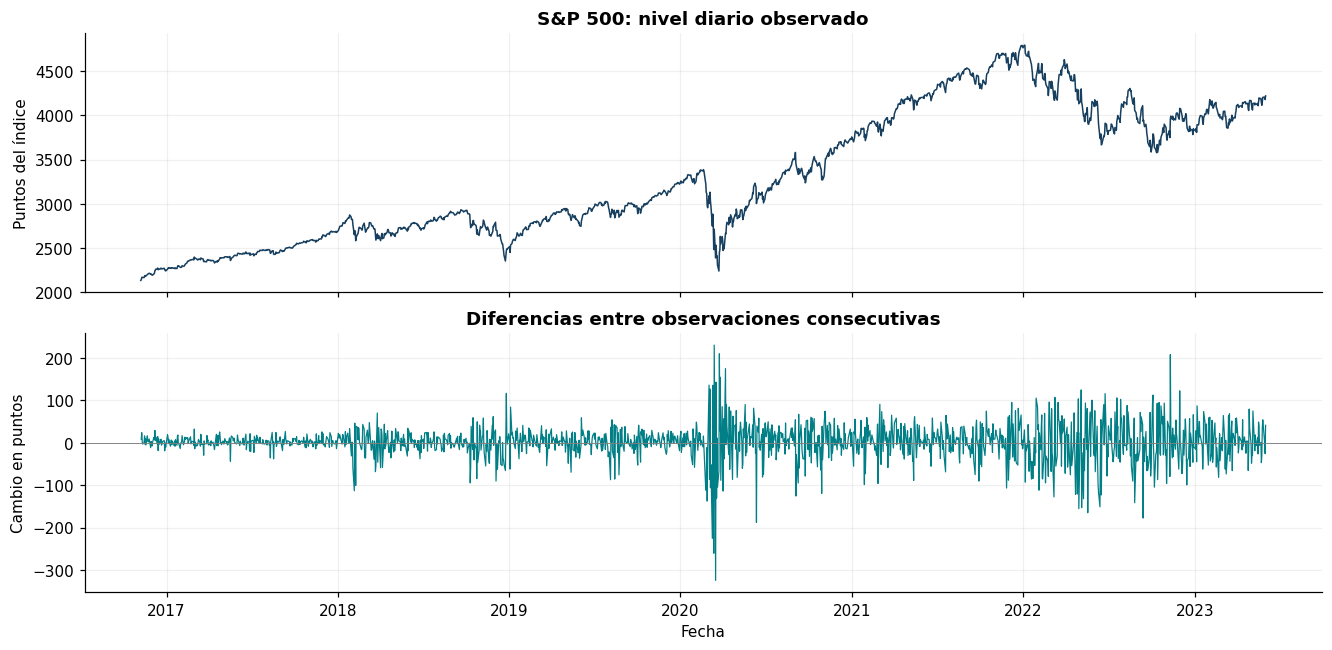

In [32]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 5.8), sharex=True, layout='constrained')
ejes[0].plot(precios['fecha'], precios['valor'], color='#173F5F', linewidth=1)
ejes[0].set(title='S&P 500: nivel diario observado', ylabel='Puntos del índice')
ejes[1].plot(cambios['fecha'], cambios['diferencia'], color='#007F86', linewidth=0.8)
ejes[1].axhline(0, color='gray', linewidth=0.6)
ejes[1].set(title='Diferencias entre observaciones consecutivas',
            ylabel='Cambio en puntos', xlabel='Fecha')
plt.show()

### 5. Ventanas, separación temporal y escalado

Cada ventana contiene 100 cambios **del más antiguo al más reciente**. Su objetivo es el cambio de la fecha siguiente. Ese orden es importante en las redes recurrentes y convolucionales.

Se reserva el **20 % final** para prueba. Dentro del 80 % inicial, se usa el primer 80 % para ajustar pesos y escaladores, y el último 20 % para validación. Aproximadamente, esto representa **64 % de ajuste, 16 % de validación y 20 % de prueba** del conjunto supervisado. El redondeo se muestra en la tabla.

Todos los modelos, incluidas las referencias, aprenden con el mismo bloque de ajuste. No se vuelve a entrenar con la validación después de seleccionar una época. Se evalúa un paso a la vez con observaciones anteriores ya conocidas; el modelo queda fijo durante la prueba. Las ventanas de prueba pueden incorporar cambios reales de días de prueba anteriores, pero nunca el objetivo de su propia fecha.

Para estabilizar el entrenamiento se estandarizan tanto las entradas como el objetivo. Los escaladores se ajustan únicamente con el bloque de ajuste. Las predicciones se transforman de regreso a **puntos del índice** antes de calcular métricas.

In [33]:
def crear_ventanas(valores, rezagos):
    valores = np.asarray(valores, dtype=float)
    x = np.array([valores[i:i + rezagos] for i in range(len(valores) - rezagos)])
    y = valores[rezagos:]
    return x, y

x, y = crear_ventanas(cambios['diferencia'], REZAGOS)
fechas = cambios['fecha'].iloc[REZAGOS:].reset_index(drop=True)
origenes = cambios['fecha_origen'].iloc[REZAGOS:].reset_index(drop=True)
corte = int(len(y) * FRACCION_DESARROLLO)
corte_ajuste = int(corte * FRACCION_AJUSTE_INTERNO)
particiones = {
    'Ajuste': slice(0, corte_ajuste),
    'Validación': slice(corte_ajuste, corte),
    'Prueba': slice(corte, len(y)),
}
assert (origenes < fechas).all()
assert fechas.iloc[corte_ajuste - 1] < fechas.iloc[corte_ajuste]
assert fechas.iloc[corte - 1] < fechas.iloc[corte]
assert np.array_equal(x[0], cambios['diferencia'].iloc[:REZAGOS].to_numpy())
assert x[0, -1] == cambios.loc[REZAGOS - 1, 'diferencia']
assert y[0] == cambios.loc[REZAGOS, 'diferencia']

escalador_x = StandardScaler().fit(x[particiones['Ajuste']].reshape(-1, 1))
escalador_y = StandardScaler().fit(y[particiones['Ajuste']].reshape(-1, 1))
x_2d = escalador_x.transform(x.reshape(-1, 1)).reshape(x.shape).astype('float32')
x_3d = x_2d.reshape(-1, REZAGOS, 1)
y_escalado = escalador_y.transform(y.reshape(-1, 1)).astype('float32')
display(pd.DataFrame([
    {'Partición': nombre, 'Ejemplos': len(y[s]),
     'Porcentaje': 100 * len(y[s]) / len(y),
     'Inicio objetivo': fechas.iloc[s].min().date(),
     'Fin objetivo': fechas.iloc[s].max().date()}
    for nombre, s in particiones.items()
]))
print('Entrada MLP:', x_2d.shape, '= (ejemplos, rezagos)')
print('Entrada RNN / LSTM / CNN:', x_3d.shape, '= (ejemplos, pasos temporales, variables)')
display(pd.DataFrame({
    'fecha_objetivo': fechas.head(3), 'fecha_origen': origenes.head(3),
    'rezago_100_antiguo': x[:3, 0], 'rezago_1_reciente': x[:3, -1], 'objetivo': y[:3],
}))

,Partición,Ejemplos,Porcentaje,Inicio objetivo,Fin objetivo
0,Ajuste,992,63.958736,2017-04-04,2021-03-12
1,Validación,248,15.989684,2021-03-15,2022-03-07
2,Prueba,311,20.051580,2022-03-08,2023-06-01


Entrada MLP: (1551, 100) = (ejemplos, rezagos)
Entrada RNN / LSTM / CNN: (1551, 100, 1) = (ejemplos, pasos temporales, variables)


,fecha_objetivo,fecha_origen,rezago_100_antiguo,rezago_1_reciente,objetivo
0,2017-04-04,2017-04-03,8.04,-3.88,1.32
1,2017-04-05,2017-04-04,23.70,1.32,-7.21
2,2017-04-06,2017-04-05,4.22,-7.21,4.54


### 6. Evaluación y funciones comunes

Se conserva la evaluación del capítulo 7 y se agrega R², tratado en el capítulo 8:

$$\mathrm{MAE}=\frac1n\sum_i|y_i-\hat y_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac1n\sum_i(y_i-\hat y_i)^2}.$$
$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

| Indicador | Interpretación |
|---|---|
| MAE y RMSE | Error en puntos; menor es mejor |
| MSE | Error cuadrático medio, en puntos cuadrados |
| Acierto direccional | Porcentaje de coincidencias entre los signos real y predicho |
| R² | Comparación contra la media de los valores evaluados; puede ser negativo |
| Correlación | Asociación lineal entre observado y predicho |
| Sesgo direccional | Cantidad de predicciones positivas / cantidad de negativas |

Para el acierto se distinguen positivo, negativo y cero; un cero solo acierta si ambos valores son cero. La correlación de una serie constante y el sesgo sin predicciones negativas quedan sin definir (`NaN` o `NULL`). El sesgo direccional no es el sesgo estadístico del equilibrio sesgo-varianza.

**Aclaración sobre R²:** fuera de muestra no está limitado a 0 y 1, y en general no es igual al cuadrado de la correlación entre observaciones y predicciones. Tampoco indica causalidad. La referencia de media se ajusta con datos de ajuste; por eso su R² de prueba no tiene que ser exactamente cero.

In [34]:
def evaluar(real, pred):
    real, pred = np.asarray(real).ravel(), np.asarray(pred).ravel()
    assert real.shape == pred.shape and np.isfinite(pred).all()
    positivas, negativas, ceros = int((pred > 0).sum()), int((pred < 0).sum()), int((pred == 0).sum())
    correlacion = np.nan
    if np.ptp(real) > 0 and np.ptp(pred) > 0:
        correlacion = float(np.corrcoef(real, pred)[0, 1])
    mse = float(mean_squared_error(real, pred))
    return {'n': len(real), 'mae': float(mean_absolute_error(real, pred)), 'mse': mse,
            'rmse': float(np.sqrt(mse)),
            'acierto_pct': float(100 * np.mean(np.sign(real) == np.sign(pred))),
            'r2': float(r2_score(real, pred)), 'correlacion': correlacion,
            'sesgo': positivas / negativas if negativas else np.nan,
            'positivas': positivas, 'negativas': negativas, 'ceros': ceros}

def crear_dataset(entradas, objetivos=None, lote=32):
    contenido = entradas if objetivos is None else (entradas, objetivos)
    ds = tf.data.Dataset.from_tensor_slices(contenido).batch(lote)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 1
    opciones.threading.max_intra_op_parallelism = 1
    opciones.experimental_deterministic = True
    return ds.with_options(opciones).prefetch(1)

resultados, registros_modelos, historiales = [], [], {}
predicciones = {}
redes = {}

def registrar_evaluacion(nombre, pred):
    pred = np.asarray(pred).ravel()
    predicciones[nombre] = pred
    filas = []
    for particion, s in particiones.items():
        fila = {'modelo_id': nombre, 'particion': particion, **evaluar(y[s], pred[s])}
        resultados.append(fila)
        filas.append(fila)
    display(pd.DataFrame(filas).set_index('particion')[
        ['rmse', 'mae', 'acierto_pct', 'r2', 'correlacion', 'sesgo']].round(5))

def graficar_prediccion(nombre, pred):
    ultimos, primeros = 65, min(60, len(y) - corte)
    fig, ax = plt.subplots(figsize=(12, 3.1), layout='constrained')
    ax.plot(fechas.iloc[corte-ultimos:corte], y[corte-ultimos:corte],
            color='#8A96A3', linewidth=1, label='Real: final de validación')
    ax.plot(fechas.iloc[corte:corte+primeros], y[corte:corte+primeros],
            color='#173F5F', linestyle='--', linewidth=1.1, label='Real: prueba')
    ax.plot(fechas.iloc[corte:corte+primeros], pred[corte:corte+primeros],
            color='#E87524', linewidth=1.2, label='Predicción: prueba')
    ax.axvline(fechas.iloc[corte], color='#A12335', linestyle=':', label='Inicio de prueba')
    ax.axhline(0, color='gray', linewidth=0.6)
    ax.set(title=nombre, ylabel='Cambio en puntos', xlabel='Fecha')
    loc = mdates.AutoDateLocator(minticks=4, maxticks=7)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax.legend(loc='upper left', ncol=2, fontsize=8)
    plt.show()

def describir_capas(modelo):
    display(pd.DataFrame([
        {'Capa': capa.name, 'Tipo': type(capa).__name__,
         'Forma de salida': str(tuple(capa.output.shape)), 'Parámetros': capa.count_params()}
        for capa in modelo.layers
    ]))
    print('Parámetros totales:', modelo.count_params())

def entrenar_red(nombre, modelo, entrada_3d, max_epocas, lote):
    entradas = x_3d if entrada_3d else x_2d
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    describir_capas(modelo)
    parada = keras.callbacks.EarlyStopping(
        monitor='val_loss', mode='min', patience=PACIENCIA, min_delta=0,
        restore_best_weights=True)
    inicio = perf_counter()
    historia = modelo.fit(
        crear_dataset(entradas[particiones['Ajuste']], y_escalado[particiones['Ajuste']], lote),
        validation_data=crear_dataset(entradas[particiones['Validación']],
                                     y_escalado[particiones['Validación']], lote),
        epochs=max_epocas, callbacks=[parada], shuffle=False, verbose=0)
    duracion = perf_counter() - inicio
    pred_escalada = modelo.predict(crear_dataset(entradas, lote=128), verbose=0)
    pred = escalador_y.inverse_transform(pred_escalada).ravel()
    mejor_epoca = int(np.argmin(historia.history['val_loss']) + 1)
    historial = pd.DataFrame(historia.history)
    historial.insert(0, 'epoca', np.arange(1, len(historial) + 1))
    historiales[nombre] = historial
    redes[nombre] = modelo
    registros_modelos.append({
        'modelo_id': nombre, 'familia': 'Red neuronal', 'rezagos': REZAGOS,
        'parametros': modelo.count_params(), 'epocas_ejecutadas': len(historial),
        'mejor_epoca': mejor_epoca, 'lote': lote, 'segundos': duracion,
        'configuracion_json': json.dumps({
            'arquitectura': json.loads(modelo.to_json()), 'max_epocas': max_epocas,
            'lote': lote, 'optimizador': 'Adam', 'learning_rate': 0.001,
            'parada_temprana': True, 'paciencia': PACIENCIA,
            'restaurar_mejores_pesos': True,
        }, ensure_ascii=False),
    })
    registrar_evaluacion(nombre, pred)
    fig, ax = plt.subplots(figsize=(9, 2.8), layout='constrained')
    ax.plot(historial['epoca'], historial['loss'], color='#173F5F', label='Ajuste')
    ax.plot(historial['epoca'], historial['val_loss'], color='#E87524', label='Validación')
    ax.axvline(mejor_epoca, color='#007F86', linestyle=':', label='Mejor época de validación')
    ax.set(title=f'Aprendizaje: {nombre}', xlabel='Época', ylabel='MSE del objetivo estandarizado')
    ax.legend(fontsize=8)
    plt.show()
    graficar_prediccion(nombre, pred)
    print(f'Épocas ejecutadas: {len(historial)} de {max_epocas}; mejor época: {mejor_epoca}.')
    print(f'Tiempo de entrenamiento: {duracion:.2f} segundos. Se restauraron los mejores pesos de validación.')

### 7. Referencias de comparación

La referencia de media indica cuánto error se obtiene sin utilizar las entradas. Se agrega una regresión lineal autorregresiva con los mismos 100 rezagos para comprobar si la complejidad de una red aporta una mejora. Ambos modelos se ajustan únicamente con el bloque de ajuste.

In [35]:
referencias = {'Referencia: media': DummyRegressor(strategy='mean'),
               'Regresión lineal': LinearRegression()}
for nombre, modelo in referencias.items():
    with threadpool_limits(limits=2):
        modelo.fit(x_2d[particiones['Ajuste']], y[particiones['Ajuste']])
        pred = modelo.predict(x_2d)
    registros_modelos.append({
        'modelo_id': nombre, 'familia': 'Referencia', 'rezagos': REZAGOS,
        'parametros': None, 'epocas_ejecutadas': 0, 'mejor_epoca': None,
        'lote': None, 'segundos': None,
        'configuracion_json': json.dumps(modelo.get_params(), default=str),
    })
    display(Markdown(f'**{nombre}**'))
    registrar_evaluacion(nombre, pred)
assert np.allclose(predicciones['Referencia: media'], y[particiones['Ajuste']].mean())

**Referencia: media**

,rmse,mae,acierto_pct,r2,correlacion,sesgo
particion,,,,,,
Ajuste,37.17088,22.31283,56.75403,0.00000,NaN,NaN
Validación,39.63620,29.86711,53.62903,-0.00020,NaN,NaN
Prueba,55.32020,42.58873,46.62379,-0.00077,NaN,NaN


**Regresión lineal**

,rmse,mae,acierto_pct,r2,correlacion,sesgo
particion,,,,,,
Ajuste,32.32361,21.23893,59.67742,0.24380,0.49377,1.33412
Validación,45.59649,34.96418,49.59677,-0.32362,-0.08042,1.00000
Prueba,61.66934,48.62318,51.44695,-0.24367,0.04624,1.27007


### 8. Perceptrón multicapa, MLP

Una MLP procesa los 100 rezagos como un vector. Se usan dos capas ocultas de 20 neuronas con ReLU y una salida lineal, como en el ejemplo del material. El máximo es de 500 épocas y el lote es de 16, pero la parada temprana puede terminar antes y restaurar una época anterior.

La curva de pérdida utiliza el objetivo estandarizado. Las métricas de la tabla y la gráfica de pronósticos se expresan después de invertir esa transformación. Una pérdida de ajuste menor no implica automáticamente una pérdida de validación menor.

,Capa,Tipo,Forma de salida,Parámetros
0,dense,Dense,"(None, 20)",2020
1,dense_1,Dense,"(None, 20)",420
2,dense_2,Dense,"(None, 1)",21


Parámetros totales: 2461


,rmse,mae,acierto_pct,r2,correlacion,sesgo
particion,,,,,,
Ajuste,34.35840,21.12837,57.15726,0.14560,0.41331,1.16594
Validación,41.14524,31.17125,54.03226,-0.07781,-0.04132,1.15652
Prueba,57.36702,44.52092,52.09003,-0.07619,0.02773,1.57025


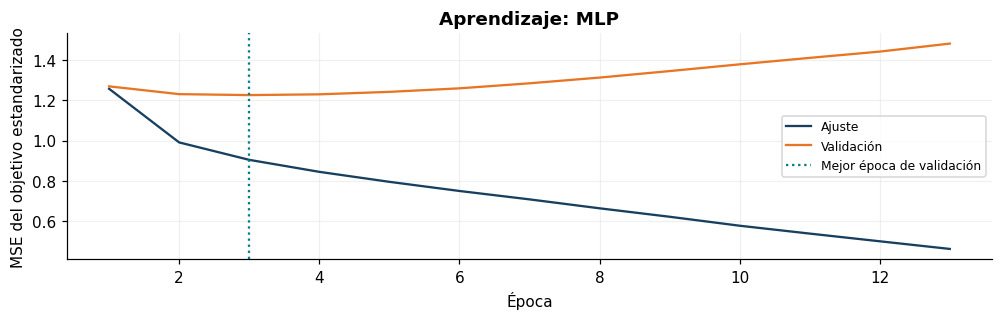

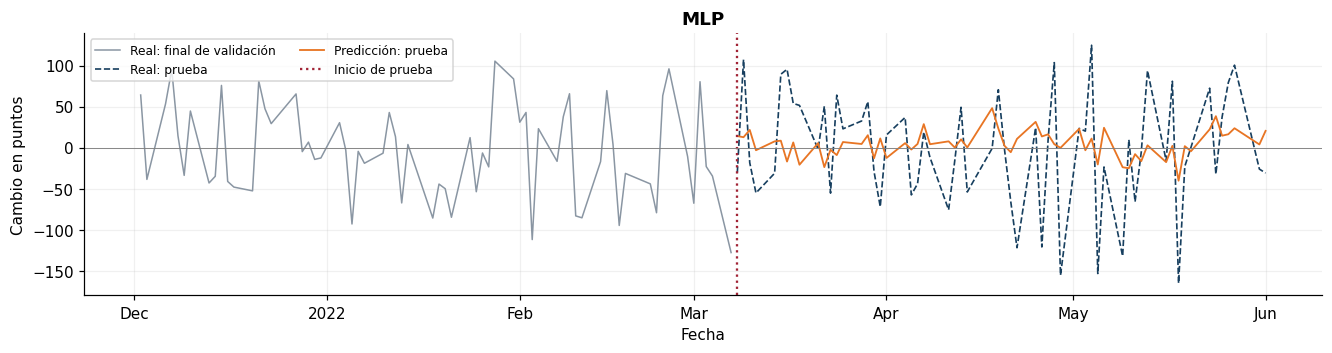

Épocas ejecutadas: 13 de 500; mejor época: 3.
Tiempo de entrenamiento: 2.19 segundos. Se restauraron los mejores pesos de validación.


In [36]:
keras.utils.set_random_seed(SEMILLA)
mlp = keras.Sequential([
    keras.Input(shape=(REZAGOS,)),
    layers.Dense(20, activation='relu'),
    layers.Dense(20, activation='relu'),
    layers.Dense(1),
], name='mlp')
entrenar_red('MLP', mlp, entrada_3d=False, max_epocas=500, lote=16)

### 9. Red recurrente simple, RNN

Una RNN combina la observación de cada paso con un estado que resume pasos anteriores de la misma ventana. La entrada tiene forma `(ejemplos, 100, 1)`. La salida del último paso pasa por una capa densa de 20 neuronas y una salida lineal.

**Corrección del ejemplo:** en la página 29 del PDF, el bloque presentado como RNN vuelve a utilizar únicamente capas `Dense`. Aquí se utiliza **`SimpleRNN`**, coherente con la explicación del capítulo. Los estados se reinician entre ventanas; no se mantiene un estado oculto entre distintos lotes (`stateful=False`).

,Capa,Tipo,Forma de salida,Parámetros
0,simple_rnn,SimpleRNN,"(None, 20)",440
1,dense_3,Dense,"(None, 20)",420
2,dense_4,Dense,"(None, 1)",21


Parámetros totales: 881


,rmse,mae,acierto_pct,r2,correlacion,sesgo
particion,,,,,,
Ajuste,36.86928,22.16243,54.23387,0.01616,0.12927,1.10616
Validación,40.76767,30.61430,48.79032,-0.05812,-0.06687,1.53061
Prueba,56.07649,43.49153,50.16077,-0.02832,0.00199,2.65882


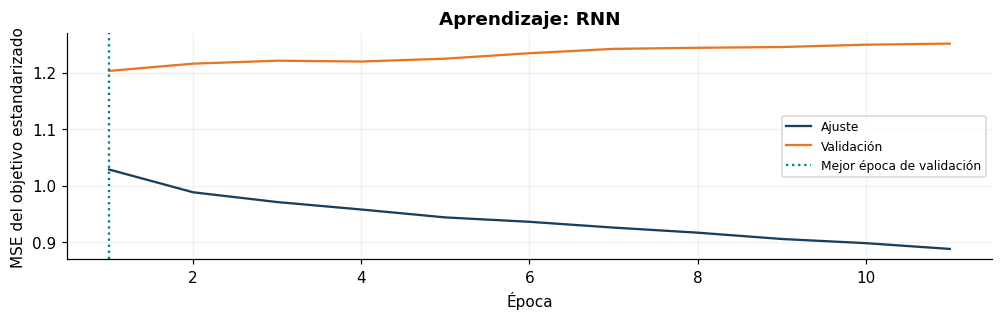

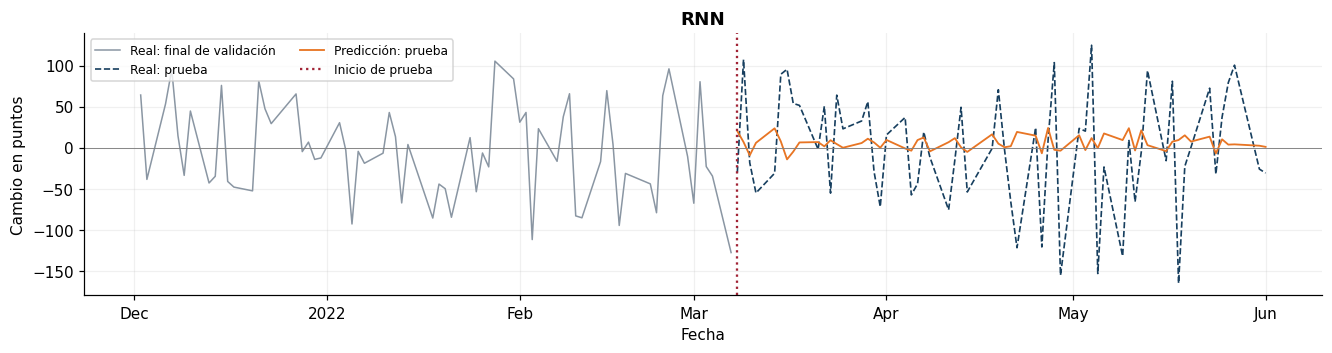

Épocas ejecutadas: 11 de 500; mejor época: 1.
Tiempo de entrenamiento: 6.37 segundos. Se restauraron los mejores pesos de validación.


In [37]:
keras.utils.set_random_seed(SEMILLA)
rnn = keras.Sequential([
    keras.Input(shape=(REZAGOS, 1)),
    layers.SimpleRNN(20, activation='tanh', stateful=False),
    layers.Dense(20, activation='relu'),
    layers.Dense(1),
], name='rnn')
entrenar_red('RNN', rnn, entrada_3d=True, max_epocas=500, lote=16)

### 10. Memoria de corto y largo plazo, LSTM

LSTM es una arquitectura recurrente que utiliza un estado de memoria y compuertas para regular el flujo de información:

| Elemento | Función |
|---|---|
| Compuerta de olvido | Regula qué parte de la memoria previa se conserva |
| Compuerta de entrada | Regula la información nueva que se incorpora |
| Actualización de memoria | Combina la memoria conservada y el contenido nuevo |
| Compuerta de salida | Regula la información de memoria que forma el estado de salida |

Se utiliza una capa LSTM de 20 unidades, una capa densa de 20 neuronas ReLU y una salida lineal. Se mantienen 100 épocas máximas y lote de 32. Las compuertas pueden facilitar el aprendizaje de dependencias, pero no garantizan que existan patrones predictivos en estos datos.

,Capa,Tipo,Forma de salida,Parámetros
0,lstm,LSTM,"(None, 20)",1760
1,dense_5,Dense,"(None, 20)",420
2,dense_6,Dense,"(None, 1)",21


Parámetros totales: 2201


,rmse,mae,acierto_pct,r2,correlacion,sesgo
particion,,,,,,
Ajuste,36.95851,22.21219,56.75403,0.01139,0.11741,NaN
Validación,39.64003,29.93474,53.62903,-0.00039,0.03859,NaN
Prueba,55.40183,42.84013,46.62379,-0.00372,0.03479,NaN


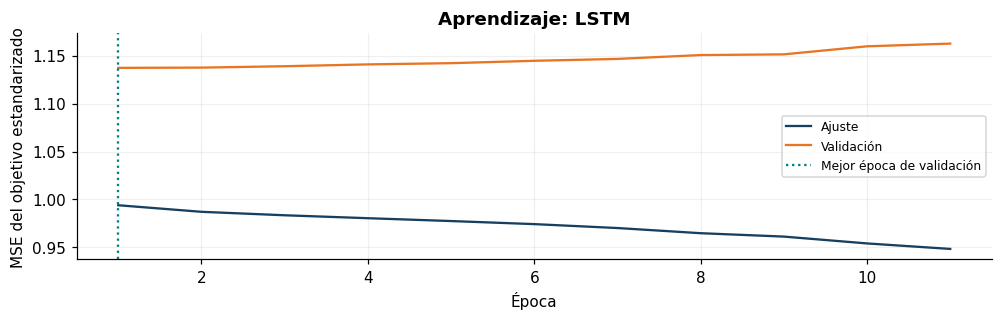

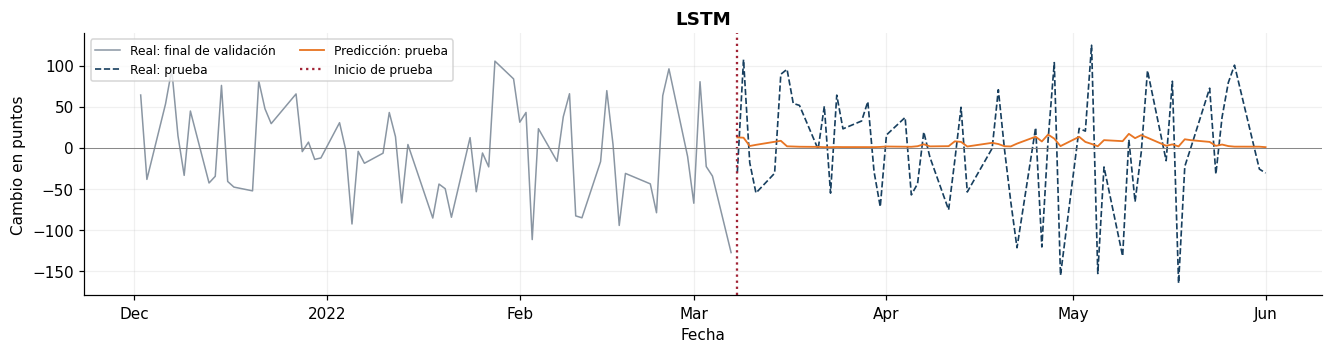

Épocas ejecutadas: 11 de 100; mejor época: 1.
Tiempo de entrenamiento: 24.79 segundos. Se restauraron los mejores pesos de validación.


In [38]:
keras.utils.set_random_seed(SEMILLA)
lstm = keras.Sequential([
    keras.Input(shape=(REZAGOS, 1)),
    layers.LSTM(20, stateful=False),
    layers.Dense(20, activation='relu'),
    layers.Dense(1),
], name='lstm')
entrenar_red('LSTM', lstm, entrada_3d=True, max_epocas=100, lote=32)

### 11. Red convolucional temporal, CNN 1D

`Conv1D` aprende filtros que recorren la ventana temporal. `MaxPooling1D` reduce su longitud, `Flatten` organiza las características resultantes y la última capa entrega una predicción. Se mantienen 64 filtros, núcleo de 4, agrupación de 2, 100 épocas máximas y lote de 8, como en el ejemplo.

Se utiliza una CNN 1D sencilla. No se atribuyen a esta arquitectura características adicionales, como conexiones residuales o convoluciones dilatadas. Con `padding='valid'`, las convoluciones trabajan únicamente sobre la ventana histórica disponible: ningún punto de ella es posterior a la fecha de origen del pronóstico.

,Capa,Tipo,Forma de salida,Parámetros
0,conv1d,Conv1D,"(None, 97, 64)",320
1,max_pooling1d,MaxPooling1D,"(None, 48, 64)",0
2,flatten,Flatten,"(None, 3072)",0
3,dense_7,Dense,"(None, 1)",3073


Parámetros totales: 3393


,rmse,mae,acierto_pct,r2,correlacion,sesgo
particion,,,,,,
Ajuste,34.74125,21.4737,57.45968,0.12646,0.42809,0.82689
Validación,40.33839,30.7540,45.96774,-0.03595,-0.06505,0.55975
Prueba,55.94392,43.1529,49.83923,-0.02346,0.01803,0.70879


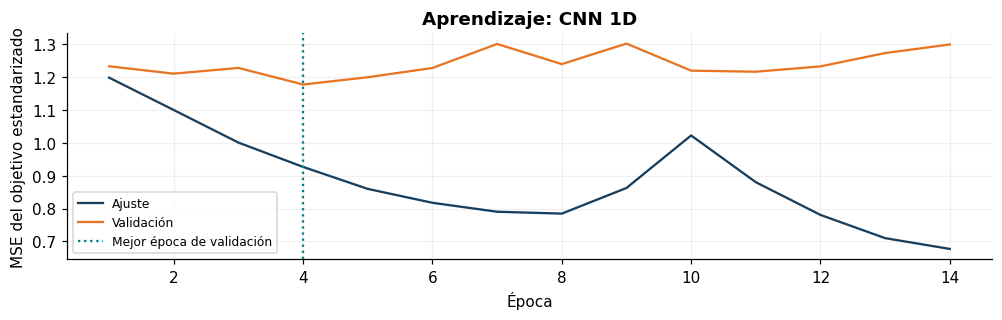

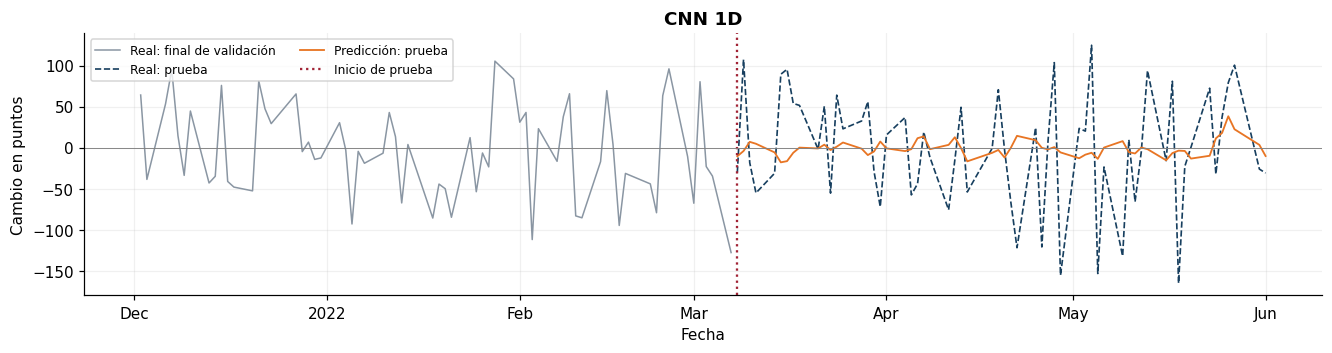

Épocas ejecutadas: 14 de 100; mejor época: 4.
Tiempo de entrenamiento: 27.71 segundos. Se restauraron los mejores pesos de validación.


In [39]:
keras.utils.set_random_seed(SEMILLA)
cnn = keras.Sequential([
    keras.Input(shape=(REZAGOS, 1)),
    layers.Conv1D(filters=64, kernel_size=4, activation='relu', padding='valid'),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(1),
], name='cnn_1d')
entrenar_red('CNN 1D', cnn, entrada_3d=True, max_epocas=100, lote=8)

### 12. Aplicación de dropout

Se agrega una variante de MLP con `Dropout(0.2)` después de la primera capa oculta. El resto de su configuración es igual a la MLP principal y también usa parada temprana. Permite observar una técnica de regularización descrita en el capítulo; no se presupone que vaya a mejorar las métricas.

Durante el entrenamiento, la pérdida de ajuste de esta variante incluye el efecto de dropout. La validación y las predicciones finales lo desactivan, por lo que sus pérdidas pueden diferir aun sin un cambio de datos.

,Capa,Tipo,Forma de salida,Parámetros
0,dense_8,Dense,"(None, 20)",2020
1,dropout,Dropout,"(None, 20)",0
2,dense_9,Dense,"(None, 20)",420
3,dense_10,Dense,"(None, 1)",21


Parámetros totales: 2461


,rmse,mae,acierto_pct,r2,correlacion,sesgo
particion,,,,,,
Ajuste,33.91853,21.19412,55.04032,0.16734,0.46921,0.64511
Validación,40.31008,30.89941,50.40323,-0.03450,0.02327,0.77143
Prueba,56.72970,43.62894,53.69775,-0.05242,0.04042,1.32090


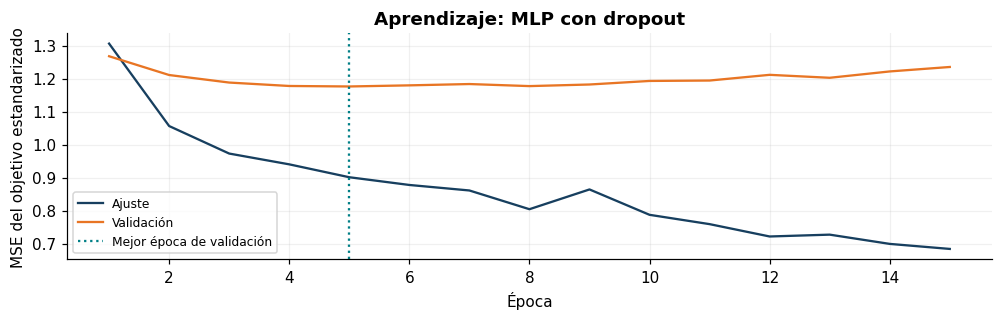

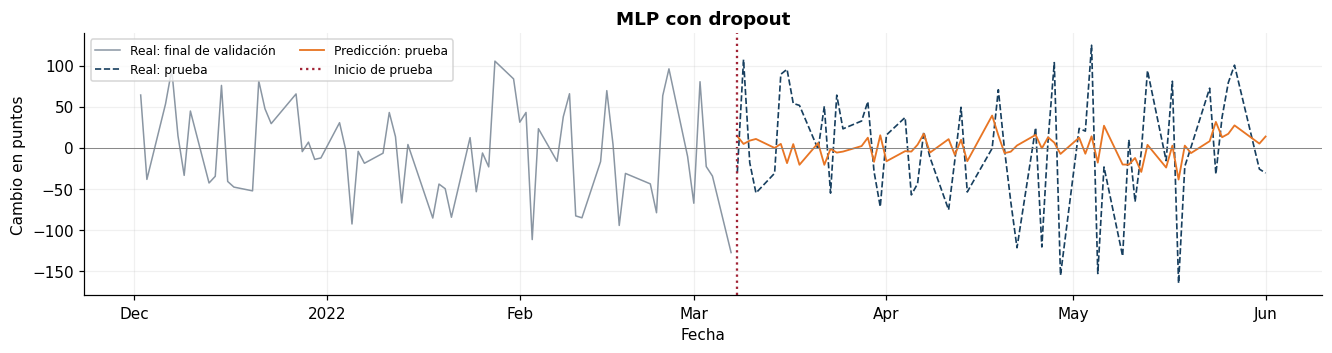

Épocas ejecutadas: 15 de 500; mejor época: 5.
Tiempo de entrenamiento: 2.14 segundos. Se restauraron los mejores pesos de validación.


In [40]:
keras.utils.set_random_seed(SEMILLA)
mlp_dropout = keras.Sequential([
    keras.Input(shape=(REZAGOS,)),
    layers.Dense(20, activation='relu'),
    layers.Dropout(0.2, seed=SEMILLA),
    layers.Dense(20, activation='relu'),
    layers.Dense(1),
], name='mlp_dropout')
entrenar_red('MLP con dropout', mlp_dropout, entrada_3d=False, max_epocas=500, lote=16)

### 13. Comparación financiera de los modelos

Los parámetros y arquitecturas se fijaron antes de observar la prueba. La época se selecciona únicamente mediante validación. Se muestran primero los resultados de validación, útiles para una selección preliminar, y después la comparación final de prueba. Comparar esta última tabla no autoriza a cambiar parámetros repetidamente sobre el mismo periodo.

`mejora_rmse_pct = 100 × (RMSE de referencia - RMSE del modelo) / RMSE de referencia`.

Un porcentaje positivo significa menor RMSE que la referencia. El modelo con menor RMSE de validación, excluyendo la media, queda identificado como candidato antes de interpretar la prueba. Todos los resultados de este apartado corresponden al S&P 500 real; el ejemplo simulado aparece por separado más adelante.

**Validación, antes de interpretar la prueba**

,rmse,mae,acierto_pct,r2
modelo_id,,,,
Referencia: media,39.63620,29.86711,53.62903,-0.00020
LSTM,39.64003,29.93474,53.62903,-0.00039
MLP con dropout,40.31008,30.89941,50.40323,-0.03450
CNN 1D,40.33839,30.75400,45.96774,-0.03595
RNN,40.76767,30.61430,48.79032,-0.05812
MLP,41.14524,31.17125,54.03226,-0.07781
Regresión lineal,45.59649,34.96418,49.59677,-0.32362


Candidato por menor RMSE de validación, excluyendo la media: LSTM


**Prueba final: error en puntos del índice**

,rmse_ajuste,rmse,mae,mejora_rmse_pct
modelo_id,,,,
Referencia: media,37.17088,55.32020,42.58873,0.00000
LSTM,36.95851,55.40183,42.84013,-0.14755
CNN 1D,34.74125,55.94392,43.15290,-1.12747
RNN,36.86928,56.07649,43.49153,-1.36711
MLP con dropout,33.91853,56.72970,43.62894,-2.54788
MLP,34.35840,57.36702,44.52092,-3.69994
Regresión lineal,32.32361,61.66934,48.62318,-11.47707


,acierto_pct,r2,correlacion,sesgo
modelo_id,,,,
Referencia: media,46.62379,-0.00077,NaN,NaN
LSTM,46.62379,-0.00372,0.03479,NaN
CNN 1D,49.83923,-0.02346,0.01803,0.70879
RNN,50.16077,-0.02832,0.00199,2.65882
MLP con dropout,53.69775,-0.05242,0.04042,1.32090
MLP,52.09003,-0.07619,0.02773,1.57025
Regresión lineal,51.44695,-0.24367,0.04624,1.27007


,parametros,epocas_ejecutadas,mejor_epoca,lote
modelo_id,,,,
Referencia: media,NaN,0,NaN,NaN
Regresión lineal,NaN,0,NaN,NaN
MLP,2461.0,13,3.0,16.0
RNN,881.0,11,1.0,16.0
LSTM,2201.0,11,1.0,32.0
CNN 1D,3393.0,14,4.0,8.0
MLP con dropout,2461.0,15,5.0,16.0


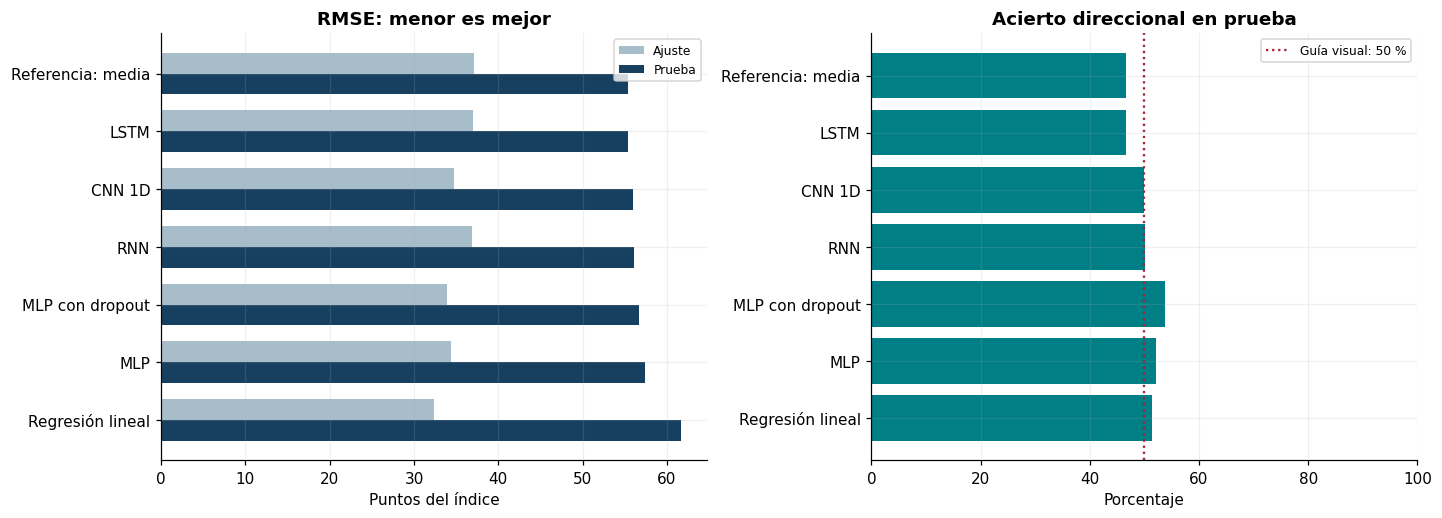

In [41]:
metricas = pd.DataFrame(resultados)
fichas = pd.DataFrame(registros_modelos).set_index('modelo_id')
validacion = metricas.query("particion == 'Validación'").set_index('modelo_id')
prueba = metricas.query("particion == 'Prueba'").set_index('modelo_id')
ajuste = metricas.query("particion == 'Ajuste'").set_index('modelo_id')
candidato_validacion = validacion.drop(index='Referencia: media')['rmse'].idxmin()
display(Markdown('**Validación, antes de interpretar la prueba**'))
display(validacion[['rmse', 'mae', 'acierto_pct', 'r2']].sort_values('rmse').round(5))
print('Candidato por menor RMSE de validación, excluyendo la media:', candidato_validacion)

comparacion = prueba[['rmse', 'mae', 'acierto_pct', 'r2', 'correlacion', 'sesgo']].copy()
comparacion['rmse_ajuste'] = ajuste['rmse']
comparacion['mejora_rmse_pct'] = 100 * (prueba.loc['Referencia: media', 'rmse'] - prueba['rmse']) / prueba.loc['Referencia: media', 'rmse']
comparacion = comparacion.sort_values('rmse')
display(Markdown('**Prueba final: error en puntos del índice**'))
display(comparacion[['rmse_ajuste', 'rmse', 'mae', 'mejora_rmse_pct']].round(5))
display(comparacion[['acierto_pct', 'r2', 'correlacion', 'sesgo']].round(5))
display(fichas[['parametros', 'epocas_ejecutadas', 'mejor_epoca', 'lote']])

orden = comparacion.index.tolist()
pos = np.arange(len(orden))
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6), layout='constrained')
ejes[0].barh(pos - 0.18, ajuste.loc[orden, 'rmse'], height=0.36, color='#A7BDC9', label='Ajuste')
ejes[0].barh(pos + 0.18, prueba.loc[orden, 'rmse'], height=0.36, color='#173F5F', label='Prueba')
ejes[0].set_yticks(pos, orden)
ejes[0].invert_yaxis()
ejes[0].set(title='RMSE: menor es mejor', xlabel='Puntos del índice')
ejes[0].legend(fontsize=8)
ejes[1].barh(pos, prueba.loc[orden, 'acierto_pct'], color='#007F86')
ejes[1].set_yticks(pos, orden)
ejes[1].invert_yaxis()
ejes[1].axvline(50, color='#A12335', linestyle=':', label='Guía visual: 50 %')
ejes[1].set(title='Acierto direccional en prueba', xlabel='Porcentaje', xlim=(0, 100))
ejes[1].legend(fontsize=8)
plt.show()

#### Sobreajuste e interpretación

Una red puede tener mucha capacidad para memorizar ruido. Una brecha entre ajuste y validación o prueba puede indicar sobreajuste; los cambios de distribución y de volatilidad también afectan la comparación de errores entre periodos. La parada temprana y dropout ayudan a controlar el ajuste, pero no garantizan superar la referencia.

Los signos correctos, el RMSE y la correlación evalúan el pronóstico. No son utilidades de una estrategia de inversión: aquí no se definen órdenes, posiciones, capital ni costos. El 50 % de la gráfica es una guía visual y no una prueba estadística.

### 14. Ejemplo didáctico: ¿se necesita siempre una red profunda?

El material compara modelos en una serie ascendente con oscilaciones. Se construye una **serie simulada**, separada de los datos financieros:

$$s_t=100+0.08t+5\sin(2\pi t/50)+\epsilon_t,\qquad
\epsilon_t\sim N(0,0.15^2).$$

La simulación tiene una tendencia y un patrón periódico conocidos. No representa precios reales ni se utiliza para respaldar los resultados del S&P 500. Se evalúan una regresión lineal sobre niveles y, por separado, una referencia de media, una regresión lineal y una MLP sobre diferencias. Se usan 100 rezagos y la misma división cronológica 64/16/20.

En la tarea sobre niveles se incluye persistencia, que predice el último nivel observado. Esto ayuda a reconocer que una predicción visualmente cercana también debe contrastarse con una referencia simple. No se comparan los RMSE de niveles y diferencias como si fueran la misma tarea.

**Tarea 1: niveles simulados**

,Modelo,rmse,r2
0,Persistencia en niveles,0.49739,0.98896
1,Lineal en niveles,0.16335,0.99881


**Tarea 2: diferencias simuladas**

,Modelo,rmse,r2
0,Media en diferencias,0.48622,-0.00116
1,Lineal en diferencias,0.16303,0.88744
2,MLP en diferencias,0.20939,0.81433


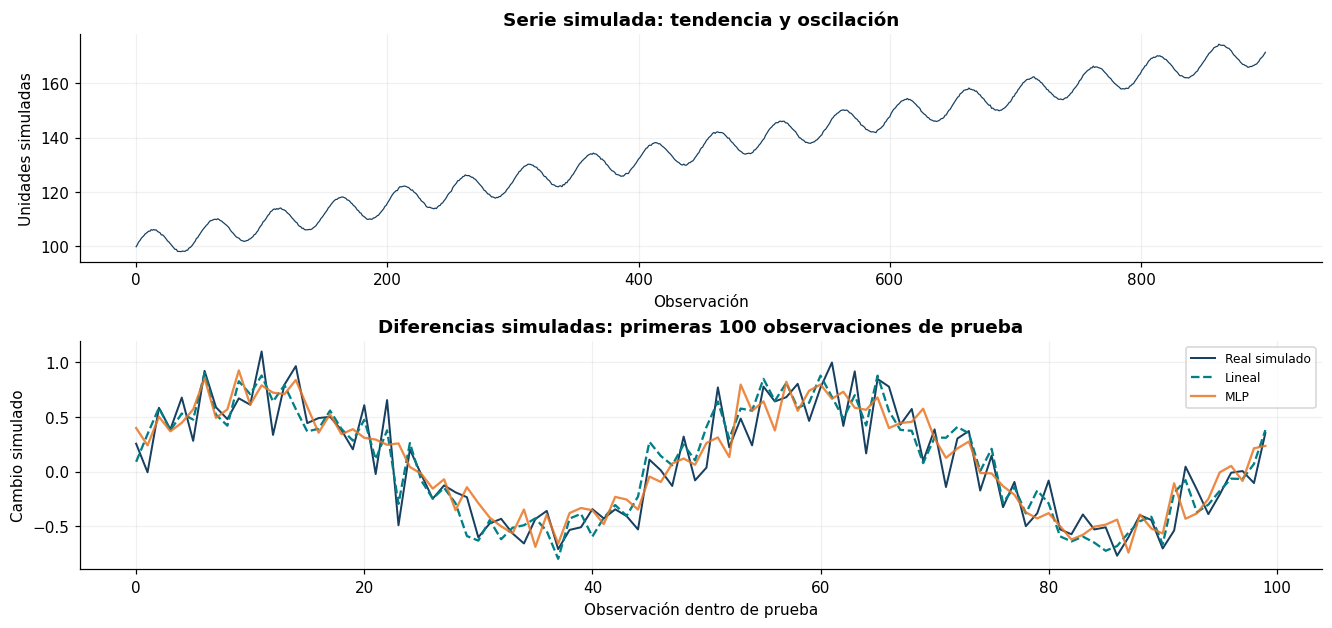

En esta simulación, R² de prueba fue **0.887** para la regresión lineal de diferencias y **0.814** para la MLP. Estos resultados ilustran por qué conviene probar un modelo sencillo cuando el proceso tiene una estructura predecible; no se trasladan automáticamente a datos financieros.

In [42]:
rng = np.random.default_rng(SEMILLA)
t_sim = np.arange(900)
serie_simulada = 100 + 0.08 * t_sim + 5 * np.sin(2 * np.pi * t_sim / 50) + rng.normal(0, 0.15, len(t_sim))
diferencias_simuladas = np.diff(serie_simulada)
x_niveles, y_niveles = crear_ventanas(serie_simulada, REZAGOS)
x_sim, y_sim = crear_ventanas(diferencias_simuladas, REZAGOS)
# Alinear las dos tareas a las mismas fechas objetivo, después de diferenciar.
x_niveles, y_niveles = x_niveles[1:], y_niveles[1:]
corte_sim = int(len(y_sim) * 0.80)
ajuste_sim = int(corte_sim * 0.80)
test_sim = slice(corte_sim, len(y_sim))

lineal_niveles = LinearRegression().fit(x_niveles[:ajuste_sim], y_niveles[:ajuste_sim])
pred_niveles = lineal_niveles.predict(x_niveles[test_sim])
persistencia = x_niveles[test_sim, -1]
tabla_niveles = pd.DataFrame([
    {'Modelo': 'Persistencia en niveles', **evaluar(y_niveles[test_sim], persistencia)},
    {'Modelo': 'Lineal en niveles', **evaluar(y_niveles[test_sim], pred_niveles)},
])

sx_sim = StandardScaler().fit(x_sim[:ajuste_sim])
sy_sim = StandardScaler().fit(y_sim[:ajuste_sim].reshape(-1, 1))
xx_sim = sx_sim.transform(x_sim).astype('float32')
yy_sim = sy_sim.transform(y_sim.reshape(-1, 1)).astype('float32')
lineal_sim = LinearRegression().fit(x_sim[:ajuste_sim], y_sim[:ajuste_sim])
pred_lineal_sim = lineal_sim.predict(x_sim[test_sim])
keras.utils.set_random_seed(SEMILLA)
red_sim = keras.Sequential([
    keras.Input(shape=(REZAGOS,)), layers.Dense(24, activation='relu'),
    layers.Dense(24, activation='relu'), layers.Dense(1),
])
red_sim.compile(optimizer=keras.optimizers.Adam(0.001), loss='mse')
hist_sim = red_sim.fit(
    crear_dataset(xx_sim[:ajuste_sim], yy_sim[:ajuste_sim], 128),
    validation_data=crear_dataset(xx_sim[ajuste_sim:corte_sim], yy_sim[ajuste_sim:corte_sim], 128),
    epochs=50, shuffle=False, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
pred_mlp_sim = sy_sim.inverse_transform(red_sim.predict(crear_dataset(xx_sim[test_sim], lote=128), verbose=0)).ravel()
pred_media_sim = np.full(len(y_sim[test_sim]), y_sim[:ajuste_sim].mean())
tabla_simulada = pd.DataFrame([
    {'Modelo': 'Media en diferencias', **evaluar(y_sim[test_sim], pred_media_sim)},
    {'Modelo': 'Lineal en diferencias', **evaluar(y_sim[test_sim], pred_lineal_sim)},
    {'Modelo': 'MLP en diferencias', **evaluar(y_sim[test_sim], pred_mlp_sim)},
])
display(Markdown('**Tarea 1: niveles simulados**'))
display(tabla_niveles[['Modelo', 'rmse', 'r2']].round(5))
display(Markdown('**Tarea 2: diferencias simuladas**'))
display(tabla_simulada[['Modelo', 'rmse', 'r2']].round(5))
fig, ejes = plt.subplots(2, 1, figsize=(12, 5.6), layout='constrained')
ejes[0].plot(t_sim, serie_simulada, color='#173F5F', linewidth=0.8)
ejes[0].set(title='Serie simulada: tendencia y oscilación', xlabel='Observación', ylabel='Unidades simuladas')
ejes[1].plot(y_sim[test_sim][:100], color='#173F5F', linewidth=1.3, label='Real simulado')
ejes[1].plot(pred_lineal_sim[:100], color='#007F86', linestyle='--', label='Lineal')
ejes[1].plot(pred_mlp_sim[:100], color='#E87524', alpha=0.85, label='MLP')
ejes[1].set(title='Diferencias simuladas: primeras 100 observaciones de prueba',
            xlabel='Observación dentro de prueba', ylabel='Cambio simulado')
ejes[1].legend(fontsize=8)
plt.show()
display(Markdown(
    f'En esta simulación, R² de prueba fue **{r2_score(y_sim[test_sim], pred_lineal_sim):.3f}** '
    f'para la regresión lineal de diferencias y **{r2_score(y_sim[test_sim], pred_mlp_sim):.3f}** '
    'para la MLP. Estos resultados ilustran por qué conviene probar un modelo sencillo '
    'cuando el proceso tiene una estructura predecible; no se trasladan automáticamente a datos financieros.'
))

### 15. Persistencia de resultados y consultas SQL

Solo se registran en las tablas financieras los modelos entrenados con el S&P 500. El ejemplo simulado se exporta por separado. En `historial_epocas`, las pérdidas corresponden al objetivo estandarizado; en `metricas`, los errores corresponden a puntos del índice.

In [43]:
for registro in registros_modelos:
    conexion.execute('INSERT INTO modelos VALUES (?, ?, ?, ?, ?)', (
        registro['modelo_id'], registro['familia'], registro['rezagos'],
        registro['parametros'], registro['configuracion_json']))
columnas_metricas = ['modelo_id', 'particion', 'n', 'mae', 'mse', 'rmse',
                     'acierto_pct', 'r2', 'correlacion', 'sesgo', 'positivas', 'negativas', 'ceros']
metricas[columnas_metricas].to_sql('metricas', conexion, if_exists='append', index=False)
filas_pred = []
for nombre, pred in predicciones.items():
    for fecha, origen, real, estimado in zip(fechas.iloc[corte:], origenes.iloc[corte:], y[corte:], pred[corte:]):
        filas_pred.append((nombre, 'SP500', fecha.strftime('%Y-%m-%d'), origen.strftime('%Y-%m-%d'), float(real), float(estimado)))
conexion.executemany('INSERT INTO predicciones VALUES (?, ?, ?, ?, ?, ?)', filas_pred)
for nombre, historial in historiales.items():
    conexion.executemany('INSERT INTO historial_epocas VALUES (?, ?, ?, ?)', [
        (nombre, int(fila.epoca), float(fila.loss), float(fila.val_loss))
        for fila in historial.itertuples(index=False)])
configuracion = {
    'estudiante': 'Juan Fernando Castrejón Villa', 'matricula': '81901',
    'rezagos': REZAGOS, 'fraccion_desarrollo': FRACCION_DESARROLLO,
    'fraccion_ajuste_interno': FRACCION_AJUSTE_INTERNO, 'semilla': SEMILLA,
    'objetivo': 'Diferencia en puntos entre cierres observados consecutivos',
    'fecha_inicio_prueba': fechas.iloc[corte:].min().strftime('%Y-%m-%d'),
    'fecha_fin_prueba': fechas.iloc[corte:].max().strftime('%Y-%m-%d'),
    'seleccion_epoca': 'Menor MSE de validación; prueba no utilizada',
}
conexion.execute('INSERT INTO ejecucion VALUES (?, ?, ?, ?, ?)', (
    1, P_FECHA, CSV_SHA256, json.dumps(configuracion, ensure_ascii=False),
    json.dumps(dict(zip(versiones['Componente'], versiones['Versión'])), ensure_ascii=False)))
conexion.commit()
display(pd.read_sql_query("""
SELECT m.modelo_id, m.familia, m.parametros,
       ROUND(e.rmse, 4) AS rmse_prueba, ROUND(e.acierto_pct, 2) AS acierto_pct
FROM modelos AS m JOIN metricas AS e ON m.modelo_id = e.modelo_id
WHERE e.particion = 'Prueba' ORDER BY e.rmse
""", conexion))

,modelo_id,familia,parametros,rmse_prueba,acierto_pct
0,Referencia: media,Referencia,NaN,55.3202,46.62
1,LSTM,Red neuronal,2201.0,55.4018,46.62
2,CNN 1D,Red neuronal,3393.0,55.9439,49.84
3,RNN,Red neuronal,881.0,56.0765,50.16
4,MLP con dropout,Red neuronal,2461.0,56.7297,53.70
5,MLP,Red neuronal,2461.0,57.3670,52.09
6,Regresión lineal,Referencia,NaN,61.6693,51.45


In [44]:
comprobacion_sql = pd.read_sql_query("""
SELECT modelo_id, COUNT(*) AS predicciones,
       AVG(ABS(valor_real - valor_predicho)) AS mae_sql
FROM predicciones GROUP BY modelo_id
""", conexion).set_index('modelo_id')
assert np.allclose(comprobacion_sql.loc[prueba.index, 'mae_sql'], prueba['mae'])
assert (comprobacion_sql['predicciones'] == len(y[corte:])).all()
assert conexion.execute('SELECT COUNT(*) FROM modelos').fetchone()[0] == 7
assert conexion.execute('SELECT COUNT(*) FROM metricas').fetchone()[0] == 21
assert conexion.execute('PRAGMA foreign_key_check').fetchall() == []
assert conexion.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
assert set(historiales) == {'MLP', 'RNN', 'LSTM', 'CNN 1D', 'MLP con dropout'}
assert any(isinstance(capa, layers.SimpleRNN) for capa in redes['RNN'].layers)
display(comprobacion_sql.round(5))
print('Integridad correcta: 7 modelos financieros, 21 registros de métricas y predicciones alineadas.')

,predicciones,mae_sql
modelo_id,,
CNN 1D,311,43.15290
LSTM,311,42.84013
MLP,311,44.52092
MLP con dropout,311,43.62894
RNN,311,43.49153
Referencia: media,311,42.58873
Regresión lineal,311,48.62318


Integridad correcta: 7 modelos financieros, 21 registros de métricas y predicciones alineadas.


### 16. Conclusiones del desarrollo

Las conclusiones cuantitativas siguientes se generan con los resultados de esta ejecución. La comparación distingue el candidato elegido mediante validación del modelo que, de manera retrospectiva, tuvo el menor error de prueba.

In [45]:
mejor_prueba = comparacion.index[0]
nombres_redes = list(redes)
mejor_red_prueba = prueba.loc[nombres_redes, 'rmse'].idxmin()
redes_superan = [nombre for nombre in nombres_redes
                 if prueba.loc[nombre, 'rmse'] < prueba.loc['Referencia: media', 'rmse']]
mejor_signo = prueba['acierto_pct'].idxmax()
display(Markdown(f"""
1. Se trabajó con **{len(datos):,} filas originales**, **{datos['valor'].isna().sum():,} faltantes** y **{len(precios):,} cierres válidos** del S&P 500. Después de diferenciar y formar ventanas de 100 rezagos quedaron **{len(y):,} ejemplos**.
2. La división cronológica produjo **{corte_ajuste:,} ejemplos de ajuste**, **{corte-corte_ajuste:,} de validación** y **{len(y)-corte:,} de prueba**. Los escaladores y pesos se ajustaron únicamente con el primer bloque.
3. Se implementaron **MLP, RNN, LSTM y CNN 1D**, además de una **MLP con dropout** y dos referencias. La RNN contiene una capa recurrente real y todas las redes utilizan parada temprana basada en validación.
4. El candidato por menor RMSE de validación, excluyendo la media, fue **{candidato_validacion}**. Su RMSE final de prueba fue **{prueba.loc[candidato_validacion, 'rmse']:.4f} puntos**.
5. El menor RMSE de prueba entre los siete modelos correspondió a **{mejor_prueba}**, con **{prueba.loc[mejor_prueba, 'rmse']:.4f} puntos**. Entre las cinco redes, **{len(redes_superan)}** superaron a la media de referencia en este indicador. La red de menor RMSE de prueba fue **{mejor_red_prueba}**.
6. El mayor acierto direccional de prueba fue **{prueba.loc[mejor_signo, 'acierto_pct']:.2f} %**, con **{mejor_signo}**. Por sí solo no demuestra rentabilidad ni significancia estadística.
7. El ejemplo simulado permite comparar modelos en un proceso con patrón conocido. Sus resultados se mantienen separados del caso real para evitar conclusiones financieras a partir de datos artificiales.
8. La base SQLite conserva los datos, la configuración, las métricas, las predicciones y las pérdidas por época. El MAE consultado mediante SQL coincide con el calculado en Python.

**Conclusión general:** el avance reproduce el proceso de modelado del capítulo y permite revisar tanto el aprendizaje como el desempeño fuera de muestra. La complejidad de una red no sustituye la selección de datos, las referencias simples ni la validación temporal.
"""))


1. Se trabajó con **1,714 filas originales**, **62 faltantes** y **1,652 cierres válidos** del S&P 500. Después de diferenciar y formar ventanas de 100 rezagos quedaron **1,551 ejemplos**.
2. La división cronológica produjo **992 ejemplos de ajuste**, **248 de validación** y **311 de prueba**. Los escaladores y pesos se ajustaron únicamente con el primer bloque.
3. Se implementaron **MLP, RNN, LSTM y CNN 1D**, además de una **MLP con dropout** y dos referencias. La RNN contiene una capa recurrente real y todas las redes utilizan parada temprana basada en validación.
4. El candidato por menor RMSE de validación, excluyendo la media, fue **LSTM**. Su RMSE final de prueba fue **55.4018 puntos**.
5. El menor RMSE de prueba entre los siete modelos correspondió a **Referencia: media**, con **55.3202 puntos**. Entre las cinco redes, **0** superaron a la media de referencia en este indicador. La red de menor RMSE de prueba fue **LSTM**.
6. El mayor acierto direccional de prueba fue **53.70 %**, con **MLP con dropout**. Por sí solo no demuestra rentabilidad ni significancia estadística.
7. El ejemplo simulado permite comparar modelos en un proceso con patrón conocido. Sus resultados se mantienen separados del caso real para evitar conclusiones financieras a partir de datos artificiales.
8. La base SQLite conserva los datos, la configuración, las métricas, las predicciones y las pérdidas por época. El MAE consultado mediante SQL coincide con el calculado en Python.

**Conclusión general:** el avance reproduce el proceso de modelado del capítulo y permite revisar tanto el aprendizaje como el desempeño fuera de muestra. La complejidad de una red no sustituye la selección de datos, las referencias simples ni la validación temporal.


#### Adaptaciones y límites

| Aspecto del material | Decisión en este desarrollo |
|---|---|
| Periodo solicitado desde 1990 | Se declara el intervalo realmente devuelto por FRED, sin completar datos inexistentes |
| Archivo `master_function.py` | Las funciones necesarias se definen dentro del notebook |
| División 80/20 | El 80 % inicial se subdivide para validar sin utilizar la prueba |
| Magnitudes de entrada y salida | Se estandarizan con ajuste exclusivo en entrenamiento y se invierten las predicciones |
| Bloque RNN con capas Dense | Se corrige mediante SimpleRNN e información en tres dimensiones |
| Épocas fijadas | Se conservan los máximos del ejemplo, con parada temprana y recuperación de pesos |
| R² descrito entre 0 y 1 | Se utiliza su definición general, que admite valores negativos fuera de muestra |
| Serie ascendente ilustrativa | Se define una simulación explícita y se evalúa por separado |

El objetivo usa únicamente cambios anteriores de una serie. No se incorporan noticias ni indicadores económicos externos. El conjunto es limitado para modelos con muchos parámetros. La diferenciación no demuestra estacionariedad y la volatilidad puede variar entre periodos.

La prueba ya fue observada en este desarrollo. Cambiar la arquitectura después de verla exigiría confirmar el resultado en otro periodo independiente. Como siguiente etapa se propone ampliar el histórico con una fuente documentada, estudiar estabilidad y estacionariedad, comparar cantidades de rezagos mediante validación temporal y repetir el entrenamiento con distintas semillas para medir la variabilidad.

### 17. Exportación

Al ejecutar la celda se crea `salidas_capitulo8`. La base `sp500_capitulo8.sqlite` contiene los resultados financieros. Se exportan las métricas, predicciones, configuración de escaladores y los historiales por época. Los modelos neuronales quedan guardados en formato `.keras`; para utilizarlos nuevamente deben aplicarse los mismos escaladores y el orden de las ventanas.

Los archivos cuyo nombre contiene `simulada` corresponden solo al ejemplo didáctico. El notebook conserva sus propias tablas y gráficas, de modo que se puede revisar el avance sin abrir esos archivos adicionales.

In [46]:
carpeta = Path.cwd() / 'salidas_capitulo8'
carpeta.mkdir(exist_ok=True)
(carpeta / 'datos_originales_sp500.csv').write_bytes(csv_original)
metricas.to_csv(carpeta / 'metricas_modelos.csv', index=False)
comparacion.to_csv(carpeta / 'comparacion_modelos.csv', index_label='modelo_id')
pd.read_sql_query('SELECT * FROM predicciones ORDER BY modelo_id, fecha_objetivo', conexion).to_csv(
    carpeta / 'predicciones_prueba.csv', index=False)
pd.read_sql_query('SELECT * FROM historial_epocas ORDER BY modelo_id, epoca', conexion).to_csv(
    carpeta / 'historial_epocas.csv', index=False)
tabla_simulada.to_csv(carpeta / 'comparacion_diferencias_simulada.csv', index=False)
tabla_niveles.to_csv(carpeta / 'comparacion_niveles_simulada.csv', index=False)
escaladores = {
    'x_media': float(escalador_x.mean_[0]), 'x_escala': float(escalador_x.scale_[0]),
    'y_media': float(escalador_y.mean_[0]), 'y_escala': float(escalador_y.scale_[0]),
    'rezagos': REZAGOS, 'orden': 'Del más antiguo al más reciente',
}
(carpeta / 'configuracion.json').write_text(
    json.dumps({'ejecucion': configuracion, 'escaladores': escaladores}, ensure_ascii=False, indent=2))
with sqlite3.connect(carpeta / 'sp500_capitulo8.sqlite') as archivo_db:
    conexion.backup(archivo_db)
for nombre, modelo in redes.items():
    nombre_archivo = nombre.lower().replace(' ', '_') + '.keras'
    modelo.save(carpeta / nombre_archivo)
print('Archivos creados en salidas_capitulo8:')
for archivo in sorted(carpeta.iterdir()):
    print(f'  {archivo.name}: {archivo.stat().st_size:,} bytes')

Archivos creados en salidas_capitulo8:
  cnn_1d.keras: 66,162 bytes
  comparacion_diferencias_simulada.csv: 516 bytes
  comparacion_modelos.csv: 1,160 bytes
  comparacion_niveles_simulada.csv: 356 bytes
  configuracion.json: 671 bytes
  datos_originales_sp500.csv: 32,155 bytes
  historial_epocas.csv: 3,066 bytes
  lstm.keras: 55,444 bytes
  metricas_modelos.csv: 3,392 bytes
  mlp.keras: 54,928 bytes
  mlp_con_dropout.keras: 57,100 bytes
  predicciones_prueba.csv: 164,684 bytes
  rnn.keras: 39,539 bytes
  sp500_capitulo8.sqlite: 397,312 bytes


### 18. Referencias

1. Kaabar, S. (2024). *Deep Learning for Finance*. O'Reilly Media. Capítulo 8, “Deep Learning for Time Series Prediction I”. PDF proporcionado para esta actividad, 51 páginas.
2. S&P Dow Jones Indices LLC. (s. f.). *S&P 500 [SP500]*. FRED, Federal Reserve Bank of St. Louis. Consultado el 6 de noviembre de 2026. https://fred.stlouisfed.org/series/SP500
3. Keras team. (s. f.). *SimpleRNN layer*. https://keras.io/api/layers/recurrent_layers/simple_rnn/
4. Keras team. (s. f.). *LSTM layer*. https://keras.io/api/layers/recurrent_layers/lstm/
5. Keras team. (s. f.). *Conv1D layer*. https://keras.io/api/layers/convolution_layers/convolution1d/
6. Keras team. (s. f.). *EarlyStopping*. https://keras.io/api/callbacks/early_stopping/
7. Keras team. (s. f.). *Dropout layer*. https://keras.io/api/layers/regularization_layers/dropout/
8. Scikit-learn developers. (s. f.). *r2_score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html

Las explicaciones y el código constituyen una adaptación didáctica del capítulo. Las tablas, curvas y conclusiones cuantitativas se generan mediante las celdas incluidas. El ejemplo simulado está identificado y separado de los datos financieros reales.

In [47]:
# Registrar las versiones de cada sección sin modificar sus variables.
P_VERSIONES['capitulo_8'] = (dict(zip(versiones['Componente'],versiones['Versión']))
    if isinstance(versiones,pd.DataFrame) else dict(versiones))

## Capítulo 9. Aprendizaje profundo para series temporales II

Esta sección conserva el desarrollo del avance y vuelve a ejecutar sus experimentos con los datos incluidos. Las referencias y limitaciones específicas se mantienen al final del capítulo.

Este avance estudia las técnicas que rodean al modelo principal: transformación de datos, filtrado de señales, actualización del modelo, validación temporal, pronóstico multiperíodo y regularización.

| Contenido del PDF | Páginas | Implementación |
|---|---:|---|
| Diferenciación fraccionaria | 1-8 | S&P 500 y EUR/USD, coeficientes y prueba ADF |
| Umbral de pronóstico | 8-13 | MLP y umbrales fijo, estadístico y de volatilidad |
| Reentrenamiento continuo | 13-17 | Regresión fija, actualización diaria y cada diez observaciones |
| Validación de series temporales | 18-20 | Ventanas expansivas y deslizantes |
| Pronóstico multiperíodo | 20-35 | Temperatura y PMI: métodos recursivo y directo |
| Regularización | 36-44 | LSTM con BatchNormalization, dropout y parada temprana |
| Síntesis | 44-45 | Comparaciones, límites y conclusiones |

### Entorno y forma de ejecución

Abrir este `.ipynb` en Jupyter o Google Colab y ejecutar sus celdas en orden. Los datos utilizados están incluidos; no hacen falta archivos auxiliares ni `master_function.py`. La primera celda instala bibliotecas ausentes y necesita internet solo en ese caso. Se utiliza CPU y semilla 123. Las versiones quedan registradas; puede haber pequeñas diferencias entre plataformas.

El objetivo es reproducir el método con resultados comprobables. Las arquitecturas se reducen en los casos indicados para facilitar su ejecución. Los resultados se calculan aquí y no se copian de las tablas del libro.

In [48]:
import base64, gzip, hashlib, io, json, sqlite3, inspect, textwrap
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.stattools import adfuller
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, HTML

SEMILLA = 123
keras.utils.set_random_seed(SEMILLA)
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    pass
tf.config.experimental.enable_op_determinism()
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi':110, 'font.size':10, 'axes.grid':True,
                     'grid.alpha':0.18, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.titleweight':'bold'})
versiones = {m:version(m) for m in ['numpy','pandas','matplotlib','scikit-learn','statsmodels']}
versiones['TensorFlow']=tf.__version__;versiones['Keras']=keras.__version__
versiones['Python'] = sys.version.split()[0]
versiones['SQLite'] = sqlite3.sqlite_version
display(pd.DataFrame(versiones.items(),columns=['Componente','Versión']))

,Componente,Versión
0,numpy,2.3.5
1,pandas,2.2.3
2,matplotlib,3.10.8
3,scikit-learn,1.8.0
4,statsmodels,0.15.0
5,TensorFlow,2.20.0
6,Keras,3.12.0
7,Python,3.12.14
8,SQLite,3.53.1


### Fuentes y revisión de datos

Se conservan las muestras de EUR/USD y S&P 500 utilizadas en los avances anteriores: sus consultas fueron el 5 y 6 de noviembre de 2026, respectivamente, con final en junio de 2023. FRED limita el histórico diario del S&P 500; se utiliza el intervalo realmente disponible y no se afirma disponer de datos desde 1990.

Temperatura de Basilea y PMI proceden de los Excel del repositorio oficial del libro, fijados a una revisión concreta. Esos archivos **no incluyen fechas** y su primera fila es numérica: se lee con `header=None` para conservarla. Se emplean índices de observación. Según el material, la temperatura es diaria y el PMI mensual; no se inventan días ni meses de calendario.

In [49]:
# Datos congelados para que el avance se pueda reproducir sin nuevas descargas.
BLOB = """
...
"""
contenido = json.loads(gzip.decompress(base64.b64decode(BLOB)))
datos = {}
for nombre, paquete in contenido.items():
    assert hashlib.sha256(paquete['csv'].encode()).hexdigest() == paquete['sha256_csv']
    datos[nombre] = pd.read_csv(io.StringIO(paquete['csv']))
display(pd.DataFrame([
    {'Serie':n,'Filas':len(datos[n]),'Consulta':p['consulta'],'Fuente':p['fuente']}
    for n,p in contenido.items()
]))

,Serie,Filas,Consulta,Fuente
0,sp500,1714,2026-11-06,https://fred.stlouisfed.org/series/SP500
1,euro,6109,2026-11-05,https://fred.stlouisfed.org/series/DEXUSEU
2,temperatura,6241,2026-11-12,https://raw.githubusercontent.com/sofienkaabar...
3,pmi,906,2026-11-12,https://raw.githubusercontent.com/sofienkaabar...


In [50]:
sp = datos['sp500'].dropna(subset=['valor']).copy()
eur = datos['euro'].dropna(subset=['valor']).copy()
sp['fecha']=pd.to_datetime(sp['fecha']);eur['fecha']=pd.to_datetime(eur['fecha'])
temperatura=datos['temperatura']['valor'].to_numpy()
pmi=datos['pmi']['valor'].to_numpy()
assert len(temperatura)==6241 and len(pmi)==906
display(pd.DataFrame({'Serie':['SP500','EURUSD','Temperatura','PMI'],
                      'Observaciones válidas':[len(sp),len(eur),len(temperatura),len(pmi)]}))

,Serie,Observaciones válidas
0,SP500,1652
1,EURUSD,5873
2,Temperatura,6241
3,PMI,906


### Funciones de preparación y evaluación

Se construyen ventanas del dato más antiguo al más reciente. En los modelos supervisados, el primer 64 % de la serie ajusta pesos y escaladores, el siguiente 16 % valida y el 20 % final se reserva para prueba. En salidas múltiples se eliminan las ventanas cuyos **objetivos** cruzan una frontera entre bloques.

Los errores se calculan en las unidades originales después de deshacer el escalado. RMSE y MAE menores indican menor error; R² puede ser negativo. Una correlación constante queda sin definir. Para cambios alrededor de cero, el acierto compara signos. Para niveles, compara el signo del desplazamiento respecto al último valor conocido en el origen.

Las trayectorias de prueba multiperíodo se evalúan desde orígenes separados por el horizonte, evitando contar el mismo objetivo en varios pronósticos solapados. Las entradas sí pueden compartir pasado ya conocido. Se indican los horizontes de cada caso; las métricas de series o tareas diferentes no deben mezclarse para obtener un ganador global.

Se distinguen tres signos: positivo, negativo y cero. Una referencia que pronostica exactamente cero cambio puede tener poco acierto direccional y aun así un RMSE bajo. No se interpreta un cero como aumento o disminución.

In [51]:
def p_adf(valores):
    opciones={'maxlag':12,'autolag':'AIC'}
    if 'result_object' in inspect.signature(adfuller).parameters:
        opciones['result_object']=False
    return float(adfuller(np.asarray(valores).ravel(),**opciones)[1])

def ventanas(valores, rezagos, horizonte=1):
    v = np.asarray(valores, dtype=float).ravel()
    t = np.arange(rezagos, len(v)-horizonte+1)
    x = np.array([v[i-rezagos:i] for i in t])
    y = np.array([v[i:i+horizonte] for i in t])
    return x, y, t

casos, resultados, pronosticos, aprendizajes, modelos_guardados = {}, [], [], [], {}

def preparar(nombre, valores, rezagos, horizonte=1, unidad='', cambio=False):
    v = np.asarray(valores,dtype=float).ravel()
    assert np.isfinite(v).all()
    x,y,t = ventanas(v,rezagos,horizonte)
    limite_ajuste, limite_prueba = int(len(v)*0.64), int(len(v)*0.80)
    mascaras = {'Ajuste': t+horizonte <= limite_ajuste,
                'Validación': (t>=limite_ajuste)&(t+horizonte<=limite_prueba),
                'Prueba': t>=limite_prueba}
    assert all(m.sum()>0 for m in mascaras.values()), 'Se necesitan más datos o una ventana menor.'
    mu,sd = float(v[:limite_ajuste].mean()),float(v[:limite_ajuste].std())
    sd = sd if sd>0 else 1.0
    b = dict(nombre=nombre,v=v,x=x,y=y,t=t,L=rezagos,H=horizonte,mu=mu,sd=sd,
             xs=((x-mu)/sd).astype('float32'), ys=((y-mu)/sd).astype('float32'),
             mascaras=mascaras,unidad=unidad,cambio=cambio)
    casos[nombre]=b
    return b

def evaluar(real,pred,base=None):
    a,b=np.asarray(real,dtype=float),np.asarray(pred,dtype=float)
    assert a.shape==b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    af,bf=a.ravel(),b.ravel()
    corr = float(np.corrcoef(af,bf)[0,1]) if np.ptp(af)>0 and np.ptp(bf)>0 else np.nan
    da,db = a,b
    if base is not None:
        origen=np.asarray(base).reshape(-1,1)
        da,db=a-origen,b-origen
    return dict(n=len(af),mae=float(mean_absolute_error(af,bf)),
                rmse=float(np.sqrt(mean_squared_error(af,bf))),
                r2=float(r2_score(af,bf)) if len(af)>1 else np.nan,
                correlacion=corr,acierto_pct=float(100*np.mean(np.sign(da)==np.sign(db))))

def registrar(b,nombre,pred):
    pred=np.asarray(pred).reshape(b['y'].shape)
    filas=[]
    for particion,mask in b['mascaras'].items():
        ii=np.flatnonzero(mask)
        # En prueba multiperíodo se evalúan bloques sin objetivos solapados.
        if particion=='Prueba' and b['H']>1: ii=ii[::b['H']]
        origen=b['v'][b['t'][ii]-1] if not b['cambio'] else None
        fila=dict(caso=b['nombre'],modelo=nombre,particion=particion,
                  **evaluar(b['y'][ii],pred[ii],origen))
        resultados.append(fila);filas.append(fila)
        if particion=='Prueba':
            for k in ii:
                for h in range(b['H']):
                    pronosticos.append((b['nombre'],nombre,int(b['t'][k]-1),h+1,
                                        float(b['y'][k,h]),float(pred[k,h])))
    return pd.DataFrame(filas).set_index('particion')[['rmse','mae','r2','correlacion','acierto_pct']]

def referencias(b):
    media=b['y'][b['mascaras']['Ajuste']].mean(axis=0)
    p_media=np.tile(media,(len(b['y']),1))
    p_simple=np.zeros_like(b['y']) if b['cambio'] else np.repeat(b['v'][b['t']-1,None],b['H'],axis=1)
    filas=[]
    for nombre,p in [('Media de ajuste',p_media),('Cero' if b['cambio'] else 'Persistencia',p_simple)]:
        filas.append(registrar(b,nombre,p).loc['Prueba'].rename(nombre))
    display(pd.DataFrame(filas).round(5))

def dataset(x,y=None,lote=64):
    ds=tf.data.Dataset.from_tensor_slices(x if y is None else (x,y)).batch(lote)
    opts=tf.data.Options();opts.threading.private_threadpool_size=1
    opts.threading.max_intra_op_parallelism=1;opts.experimental_deterministic=True
    return ds.with_options(opts).prefetch(1)

def entrenar(b,nombre='Red',recurrente=False,neuronas=(32,32),epocas=40,lote=64,
             regularizado=False,callbacks_adicionales=None):
    keras.utils.set_random_seed(SEMILLA)
    x=b['xs'][...,None] if recurrente and b['xs'].ndim==2 else b['xs']
    capas=[keras.Input(shape=x.shape[1:])]
    if recurrente: capas.append(layers.LSTM(neuronas[0]))
    else: capas.append(layers.Dense(neuronas[0],activation='relu'))
    if regularizado: capas.extend([layers.BatchNormalization(),layers.Dropout(0.1,seed=SEMILLA)])
    for n in neuronas[1:]: capas.append(layers.Dense(n,activation='relu'))
    capas.append(layers.Dense(b['H']))
    red=keras.Sequential(capas)
    red.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='mse')
    display(pd.DataFrame([{'Capa':type(c).__name__,'Salida':str(tuple(c.output.shape)),
                          'Parámetros':c.count_params()} for c in red.layers]))
    es=keras.callbacks.EarlyStopping(monitor='val_loss',patience=7,restore_best_weights=True)
    inicio=perf_counter()
    hist=red.fit(dataset(x[b['mascaras']['Ajuste']],b['ys'][b['mascaras']['Ajuste']],lote),
                 validation_data=dataset(x[b['mascaras']['Validación']],b['ys'][b['mascaras']['Validación']],lote),
                 epochs=epocas,shuffle=False,verbose=0,
                 callbacks=[es]+list(callbacks_adicionales or []))
    p=red.predict(dataset(x,lote=128),verbose=0)*b['sd']+b['mu']
    display(registrar(b,nombre,p).round(5))
    for i,(loss,val) in enumerate(zip(hist.history['loss'],hist.history['val_loss'])):
        aprendizajes.append((b['nombre'],nombre,i+1,float(loss),float(val)))
    modelos_guardados[b['nombre']+'__'+nombre]=red
    mejor=int(np.argmin(hist.history['val_loss'])+1)
    print(f'Épocas: {len(hist.history["loss"])} / {epocas}; mejor validación: {mejor}; tiempo: {perf_counter()-inicio:.1f} s.')
    fig,ax=plt.subplots(figsize=(9,2.6),layout='constrained')
    eje_epocas=np.arange(1,len(hist.history['loss'])+1)
    ax.plot(eje_epocas,hist.history['loss'],label='Ajuste',color='#173F5F')
    ax.plot(eje_epocas,hist.history['val_loss'],label='Validación',color='#E87524')
    ax.axvline(mejor,color='#007F86',ls=':')
    ax.set(title=b['nombre']+' | '+nombre,xlabel='Época',ylabel='MSE estandarizado')
    ax.legend(fontsize=8);plt.show()
    return red,p,hist

def trayectoria(b,modelo,horizonte,inicio=None):
    assert b['H']==1
    t=int(b['t'][b['mascaras']['Prueba']][0]) if inicio is None else int(inicio)
    memoria=b['v'][t-b['L']:t].copy();salida=[]
    for _ in range(horizonte):
        xx=((memoria-b['mu'])/b['sd']).astype('float32')[None,:]
        if len(modelo.input_shape)==3: xx=xx[...,None]
        nuevo=float(modelo(xx,training=False).numpy().ravel()[0]*b['sd']+b['mu'])
        salida.append(nuevo);memoria=np.r_[memoria[1:],nuevo]
    return np.array(salida)

def grafico_trayectoria(real,pred,titulo,unidad='',base=None):
    fig,ax=plt.subplots(figsize=(11,3),layout='constrained')
    ax.plot(real,color='#173F5F',lw=1.5,label='Observado')
    ax.plot(pred,color='#E87524',lw=1.3,label='Predicción')
    if base is not None: ax.plot(base,color='#007F86',ls=':',label='Referencia')
    ax.set(title=titulo,xlabel='Paso desde el origen',ylabel=unidad);ax.legend(fontsize=8);plt.show()

def exportar(capitulo):
    carpeta=Path.cwd()/f'salidas_capitulo_{capitulo}';carpeta.mkdir(exist_ok=True)
    m=pd.DataFrame(resultados)
    conexion=sqlite3.connect(':memory:');conexion.execute('PRAGMA foreign_keys=ON')
    conexion.executescript("""
    CREATE TABLE casos(caso TEXT PRIMARY KEY,unidad TEXT,rezagos INTEGER,horizontes INTEGER);
    CREATE TABLE datos(caso TEXT,indice INTEGER,valor REAL,PRIMARY KEY(caso,indice),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE metricas(caso TEXT,modelo TEXT,particion TEXT,n INTEGER,mae REAL,rmse REAL,r2 REAL,correlacion REAL,acierto_pct REAL,
                         PRIMARY KEY(caso,modelo,particion),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE predicciones(caso TEXT,modelo TEXT,origen INTEGER,horizonte INTEGER,real REAL,predicho REAL,
                         PRIMARY KEY(caso,modelo,origen,horizonte),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE aprendizaje(caso TEXT,modelo TEXT,epoca INTEGER,loss REAL,val_loss REAL,
                         PRIMARY KEY(caso,modelo,epoca),FOREIGN KEY(caso) REFERENCES casos(caso));
    """)
    for nombre,b in casos.items():
        conexion.execute('INSERT INTO casos VALUES(?,?,?,?)',(nombre,b['unidad'],b['L'],b['H']))
        conexion.executemany('INSERT INTO datos VALUES(?,?,?)',[(nombre,i,float(v)) for i,v in enumerate(b['v'])])
    m.to_sql('metricas',conexion,index=False,if_exists='append')
    conexion.executemany('INSERT INTO predicciones VALUES(?,?,?,?,?,?)',pronosticos)
    conexion.executemany('INSERT INTO aprendizaje VALUES(?,?,?,?,?)',aprendizajes)
    conexion.commit()
    assert conexion.execute('PRAGMA foreign_key_check').fetchall()==[]
    assert conexion.execute('PRAGMA integrity_check').fetchone()[0]=='ok'
    ver=pd.read_sql_query('SELECT caso,modelo,AVG(ABS(real-predicho)) AS mae_sql FROM predicciones GROUP BY caso,modelo',conexion)
    control=m.query("particion=='Prueba'").merge(ver,on=['caso','modelo'],validate='one_to_one')
    assert np.allclose(control['mae'],control['mae_sql'],rtol=1e-9,atol=1e-10)
    with sqlite3.connect(carpeta/f'capitulo_{capitulo}.sqlite') as db: conexion.backup(db)
    m.to_csv(carpeta/'metricas.csv',index=False)
    pd.DataFrame(pronosticos,columns=['caso','modelo','origen','horizonte','real','predicho']).to_csv(carpeta/'predicciones.csv',index=False)
    pd.DataFrame(aprendizajes,columns=['caso','modelo','epoca','loss','val_loss']).to_csv(carpeta/'aprendizaje.csv',index=False)
    (carpeta/'configuracion.json').write_text(json.dumps({'estudiante':'Juan Fernando Castrejón Villa',
        'matricula':'81901','versiones':versiones,'semilla':SEMILLA,'fecha':P_FECHA},ensure_ascii=False,indent=2))
    display(pd.read_sql_query('SELECT caso,modelo,ROUND(rmse,6) AS rmse,ROUND(acierto_pct,2) AS acierto_pct FROM metricas WHERE particion="Prueba" ORDER BY caso,rmse',conexion))
    print('Archivos creados en',carpeta.name,'| Integridad y verificación SQL del MAE correctas.')
    return m,conexion

### 1. Diferenciación fraccionaria

Se aplica una ventana fija de 100 observaciones. Los coeficientes son $w_0=1$ y $w_k=-w_{k-1}(d-k+1)/k$. La transformación usa únicamente el dato actual y valores anteriores. No se necesita instalar `fracdiff`.

Se contrastan los órdenes del material: **0.48 para S&P 500**, y **0.20 y 0.30 para EUR/USD**. La ADF se calcula solo sobre el tramo inicial de ajuste, alineando las observaciones. Su hipótesis nula es la presencia de raíz unitaria: un p menor que 0.05 permite rechazarla bajo esa especificación; no prueba todas las propiedades de estacionariedad ni garantiza capacidad predictiva. Una correlación alta con el nivel original describe información compartida, no demuestra memoria aprovechable para invertir.

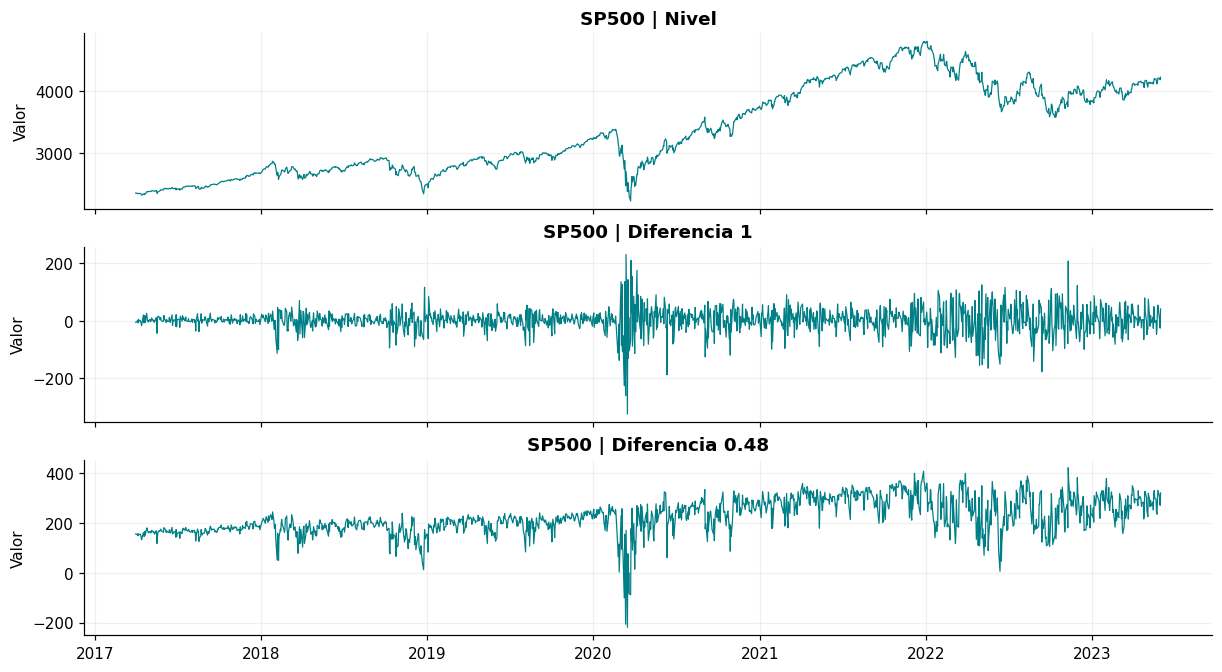

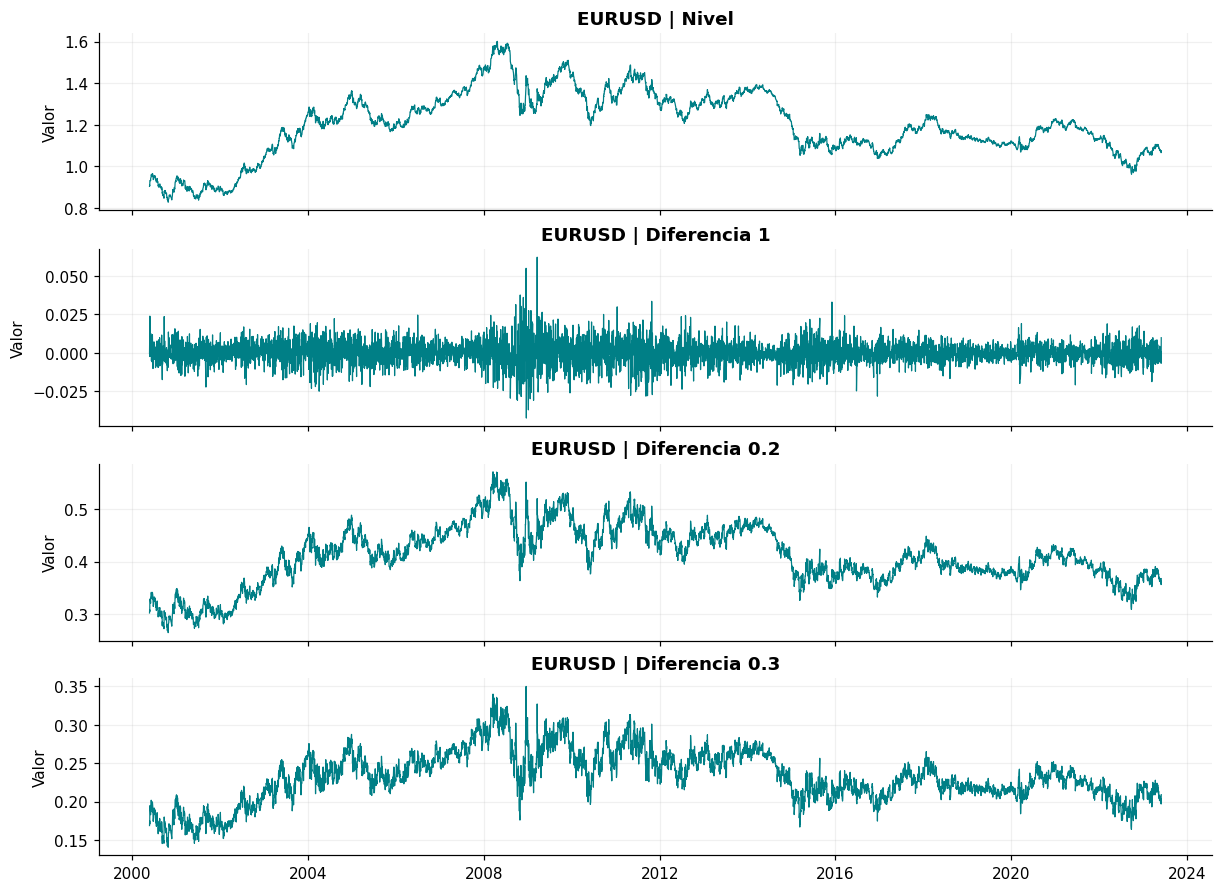

,Serie,Método,p_ADF_ajuste,Rechazo_raíz_5pct,Corr_nivel_ajuste
0,SP500,Nivel,0.77005,False,1.00000
1,SP500,Diferencia 1,0.00000,True,0.08418
2,SP500,Diferencia 0.48,0.00031,True,0.65931
3,EURUSD,Nivel,0.33766,False,1.00000
4,EURUSD,Diferencia 1,0.00000,True,0.01085
5,EURUSD,Diferencia 0.2,0.12083,False,0.98554
6,EURUSD,Diferencia 0.3,0.02314,True,0.95320


In [52]:
def diferencia_fraccionaria(v,d,ventana=100):
    w=[1.0]
    for k in range(1,ventana): w.append(-w[-1]*(d-k+1)/k)
    return np.convolve(np.asarray(v),np.asarray(w),mode='valid')
prueba_simple=np.arange(150,dtype=float)**2
assert np.allclose(diferencia_fraccionaria(prueba_simple,0),prueba_simple[99:])
assert np.allclose(diferencia_fraccionaria(prueba_simple,1),np.diff(prueba_simple)[98:])
filas_adf=[]
for nombre,tabla,ordenes in [('SP500',sp,[0.48]),('EURUSD',eur,[0.20,0.30])]:
    v=tabla['valor'].to_numpy();limite=int(len(v)*0.64)
    alineados={'Nivel':v[99:],'Diferencia 1':np.diff(v)[98:]}
    alineados.update({f'Diferencia {d}':diferencia_fraccionaria(v,d) for d in ordenes})
    fig,axes=plt.subplots(len(alineados),1,figsize=(11,2*len(alineados)),sharex=True,layout='constrained')
    for ax,(metodo,serie) in zip(np.atleast_1d(axes),alineados.items()):
        muestra=serie[:limite-99]
        pvalor=p_adf(muestra)
        filas_adf.append({'Serie':nombre,'Método':metodo,'p_ADF_ajuste':pvalor,
                          'Rechazo_raíz_5pct':pvalor<0.05,
                          'Corr_nivel_ajuste':np.corrcoef(muestra,v[99:limite])[0,1]})
        ax.plot(tabla['fecha'].iloc[99:],serie,lw=0.8,color='#007F86')
        ax.set(title=nombre+' | '+metodo,ylabel='Valor')
    plt.show()
tabla_adf=pd.DataFrame(filas_adf);display(tabla_adf.round(6))

### 2. Umbral de pronóstico

Se pronostica la diferencia diaria del EUR/USD con 500 rezagos y una MLP de dos capas de 64 neuronas. El libro usa 256; aquí se reduce el tamaño y se limita a 40 épocas con validación para facilitar la ejecución.

El umbral fijo **0.0015** está expresado en USD por EUR, como la variable predicha. No es una probabilidad ni un porcentaje de confianza. Se comparan, sin optimizarlos con prueba, un cuantil 75 de magnitudes de ajuste y la mitad de la desviación móvil de 20 diferencias previas. El filtro solo decide si se emite señal. Las métricas del pronóstico se mantienen sin cambiar; además se reportan cobertura y acierto entre señales activas. Si no hay señales, ese acierto queda sin definir.

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,0.00498,0.00372,-0.00141,NaN,49.19149
Cero,0.00498,0.00372,-0.00022,NaN,0.51064


,Capa,Salida,Parámetros
0,Dense,"(None, 64)",32064
1,Dense,"(None, 64)",4160
2,Dense,"(None, 1)",65


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,0.00690,0.00506,0.27169,0.57890,67.86372
Validación,0.00675,0.00512,-0.09005,0.01643,50.58573
Prueba,0.00522,0.00393,-0.09879,-0.00245,49.70213


Épocas: 8 / 40; mejor validación: 1; tiempo: 2.6 s.


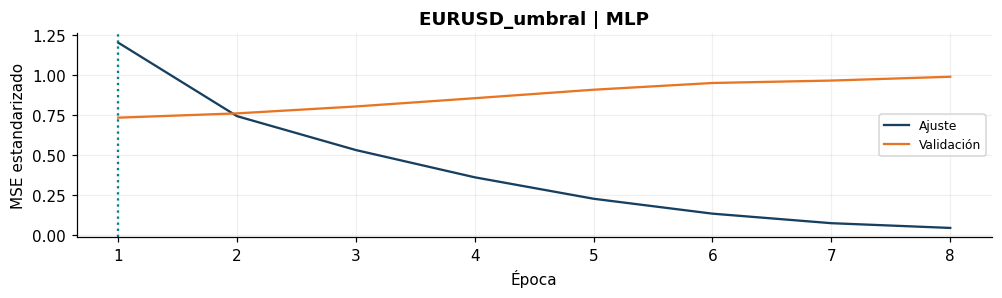

,Umbral,Señales,Cobertura_pct,Acierto_activas_pct
0,Fijo 0.0015,387,32.9362,50.1292
1,Cuantil 75 de ajuste,0,0.0000,NaN
2,Mitad de volatilidad previa,201,17.1064,48.2587


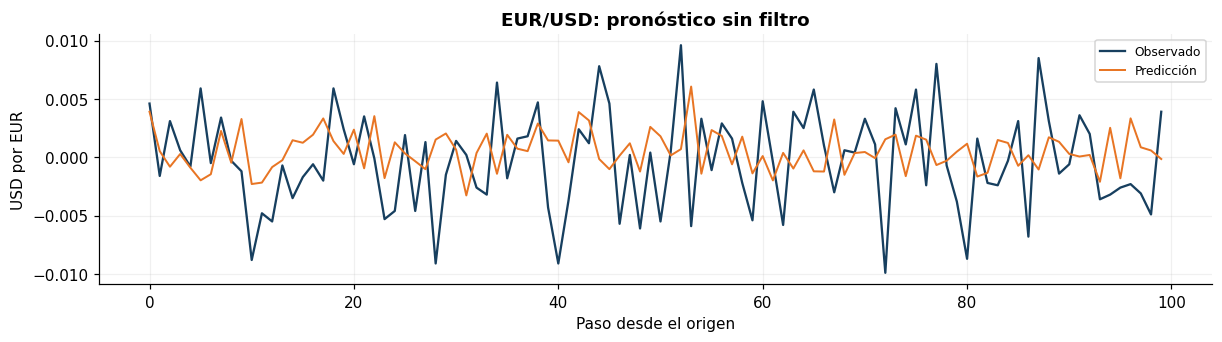

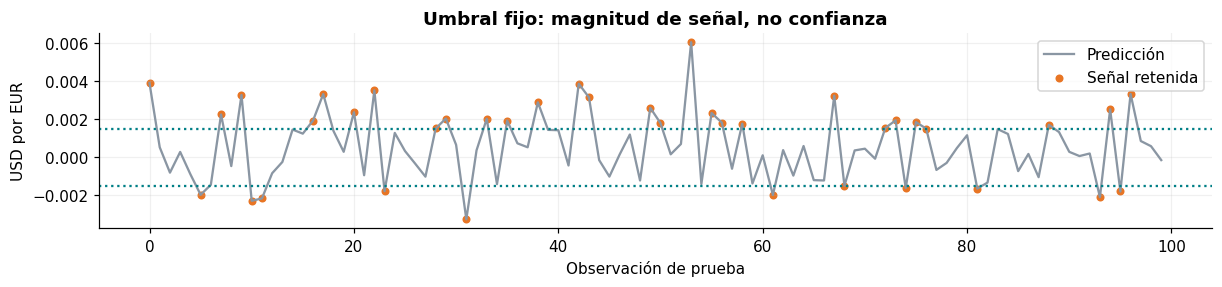

In [53]:
diferencias_eur=np.diff(eur['valor'].to_numpy())
b_umbral=preparar('EURUSD_umbral',diferencias_eur,500,unidad='USD por EUR',cambio=True)
referencias(b_umbral)
red_umbral,p_umbral,h_umbral=entrenar(b_umbral,'MLP',neuronas=(64,64),epocas=40)
ii=np.flatnonzero(b_umbral['mascaras']['Prueba'])
real=b_umbral['y'][ii,0];p=p_umbral[ii,0]
volatilidad=pd.Series(diferencias_eur).rolling(20).std().shift(1).to_numpy()
umbrales={
    'Fijo 0.0015':np.full(len(ii),0.0015),
    'Cuantil 75 de ajuste':np.full(len(ii),np.quantile(np.abs(diferencias_eur[:int(len(diferencias_eur)*0.64)]),0.75)),
    'Mitad de volatilidad previa':0.5*volatilidad[b_umbral['t'][ii]],
}
cobertura=[]
for nombre,u in umbrales.items():
    activas=np.abs(p)>=u
    cobertura.append({'Umbral':nombre,'Señales':int(activas.sum()),'Cobertura_pct':100*activas.mean(),
                       'Acierto_activas_pct':100*np.mean(np.sign(real[activas])==np.sign(p[activas])) if activas.any() else np.nan})
tabla_umbrales=pd.DataFrame(cobertura);display(tabla_umbrales.round(4))
grafico_trayectoria(real[:100],p[:100],'EUR/USD: pronóstico sin filtro','USD por EUR')
fig,ax=plt.subplots(figsize=(11,2.5),layout='constrained')
ax.plot(p[:100],color='#8A96A3',label='Predicción')
ax.scatter(np.arange(min(100,len(p)))[np.abs(p[:100])>=0.0015],p[:100][np.abs(p[:100])>=0.0015],
           color='#E87524',s=18,label='Señal retenida')
ax.axhline(0.0015,ls=':',color='#007F86');ax.axhline(-0.0015,ls=':',color='#007F86')
ax.set(title='Umbral fijo: magnitud de señal, no confianza',xlabel='Observación de prueba',ylabel='USD por EUR')
ax.legend();plt.show()

### 3. Reentrenamiento continuo y validación temporal

Para esta comparación se adopta el 80 % inicial como desarrollo y el 20 % final como prueba, como en el ejemplo de actualización del capítulo. Se usa regresión lineal con 15 rezagos, sin modificar parámetros según los resultados de prueba.

En cada paso primero se predice. Solo después puede incorporarse el valor que acaba de observarse para entrenamientos futuros. Se comparan un modelo fijo, actualización en cada dato y actualización cada diez datos. Los tres parten del mismo desarrollo. Es un pronóstico de un paso con datos anteriores observados, no una trayectoria recursiva desde un solo origen.

La validación expansiva conserva todo el pasado; la deslizante conserva un máximo de 500 ejemplos. Se calculan cuatro bloques dentro del desarrollo, excluyendo la prueba final.

,Modelo,Entrenamientos,Segundos,rmse,acierto_pct
0,Fijo,1,0.05440,0.005,48.97611
1,Cada dato,1172,2.93876,0.005,48.20819
2,Cada 10 datos,118,0.29352,0.005,48.37884


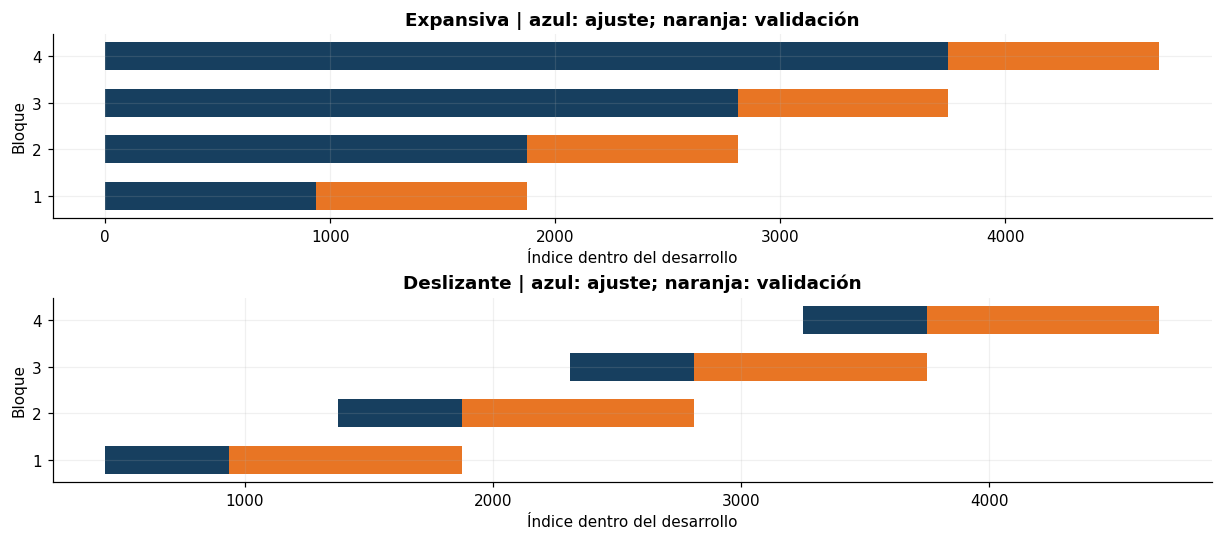

,Ventana,Bloque,N_ajuste,N_validación,rmse
0,Expansiva,1,937,937,0.00691
1,Expansiva,2,1874,937,0.01043
2,Expansiva,3,2811,937,0.00739
3,Expansiva,4,3748,937,0.00648
4,Deslizante,1,500,937,0.00688
5,Deslizante,2,500,937,0.01056
6,Deslizante,3,500,937,0.00752
7,Deslizante,4,500,937,0.00656


,RMSE medio de validación
Ventana,
Deslizante,0.00788
Expansiva,0.00781


In [54]:
x_w,y_w,t_w=ventanas(diferencias_eur,15)
y_w=y_w.ravel();corte_w=int(len(x_w)*0.8)
pred_walk={};tiempos_walk=[]
for nombre,frecuencia in [('Fijo',None),('Cada dato',1),('Cada 10 datos',10)]:
    salida=[];ajustes=0;inicio=perf_counter();modelo=LinearRegression()
    with threadpool_limits(limits=2):
        for j,k in enumerate(range(corte_w,len(x_w))):
            if j==0 or (frecuencia is not None and j%frecuencia==0):
                assert k-1<k
                modelo.fit(x_w[:k],y_w[:k]);ajustes+=1
            salida.append(float(modelo.predict(x_w[k:k+1])[0]))
    pred_walk[nombre]=np.array(salida)
    tiempos_walk.append({'Modelo':nombre,'Entrenamientos':ajustes,
                         'Segundos':perf_counter()-inicio,**evaluar(y_w[corte_w:],salida)})
tabla_walk=pd.DataFrame(tiempos_walk)
display(tabla_walk[['Modelo','Entrenamientos','Segundos','rmse','acierto_pct']].round(6))
filas_cv=[];fig,axes=plt.subplots(2,1,figsize=(11,4.8),layout='constrained')
for ax,(tipo,maximo) in zip(axes,[('Expansiva',None),('Deslizante',500)]):
    cv=TimeSeriesSplit(n_splits=4,max_train_size=maximo)
    for fold,(it,iv) in enumerate(cv.split(x_w[:corte_w]),1):
        assert it.max()<iv.min()<corte_w
        with threadpool_limits(limits=2):
            m=LinearRegression().fit(x_w[it],y_w[it]);pv=m.predict(x_w[iv])
        filas_cv.append({'Ventana':tipo,'Bloque':fold,'N_ajuste':len(it),'N_validación':len(iv),
                         'rmse':np.sqrt(mean_squared_error(y_w[iv],pv))})
        ax.broken_barh([(it[0],len(it))],(fold-.3,.6),facecolors='#173F5F')
        ax.broken_barh([(iv[0],len(iv))],(fold-.3,.6),facecolors='#E87524')
    ax.set(title=tipo+' | azul: ajuste; naranja: validación',xlabel='Índice dentro del desarrollo',ylabel='Bloque')
plt.show();tabla_cv=pd.DataFrame(filas_cv);display(tabla_cv.round(6))
display(tabla_cv.groupby('Ventana')[['rmse']].mean().rename(columns={'rmse':'RMSE medio de validación'}))

### 4. Pronósticos recursivos de temperatura y PMI

Un pronóstico recursivo entrena una salida y vuelve a introducir sus propias predicciones en la ventana. Después del origen, no recibe los valores reales de la trayectoria que está intentando anticipar. El error puede acumularse, pero su crecimiento no tiene por qué ser exponencial.

Se usan 365 rezagos para temperatura, una proyección de 500 observaciones diarias y MLP de 64 y 32 neuronas. Para PMI se usan 10 rezagos y 18 observaciones mensuales. Se mantiene la idea de las páginas 20-28 con tamaños menores y una ventana común para comparar PMI directo y recursivo. La referencia estacional repite el último bloque de 365 temperaturas ya conocido, sin consultar el futuro.

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,8.57741,7.22028,-0.01674,NaN,51.56125
Persistencia,2.93565,2.25264,0.88090,0.94049,0.08006


,Capa,Salida,Parámetros
0,Dense,"(None, 64)",23424
1,Dense,"(None, 32)",2080
2,Dense,"(None, 1)",33


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,3.41951,2.61120,0.83990,0.94579,68.80683
Validación,4.13924,3.35331,0.80637,0.90102,56.41283
Prueba,4.20978,3.36723,0.75508,0.87575,56.60528


Épocas: 30 / 30; mejor validación: 27; tiempo: 3.3 s.


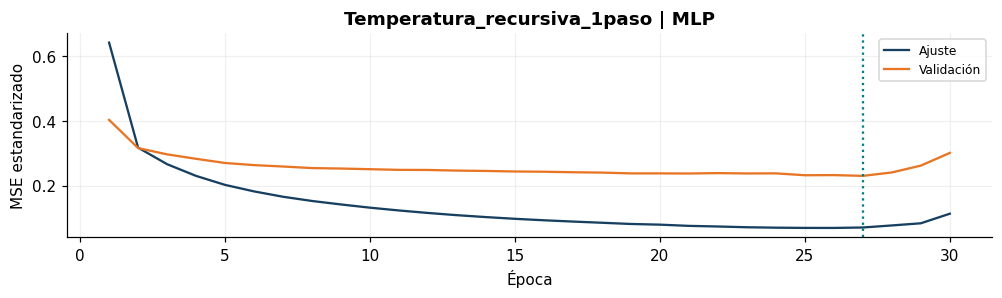

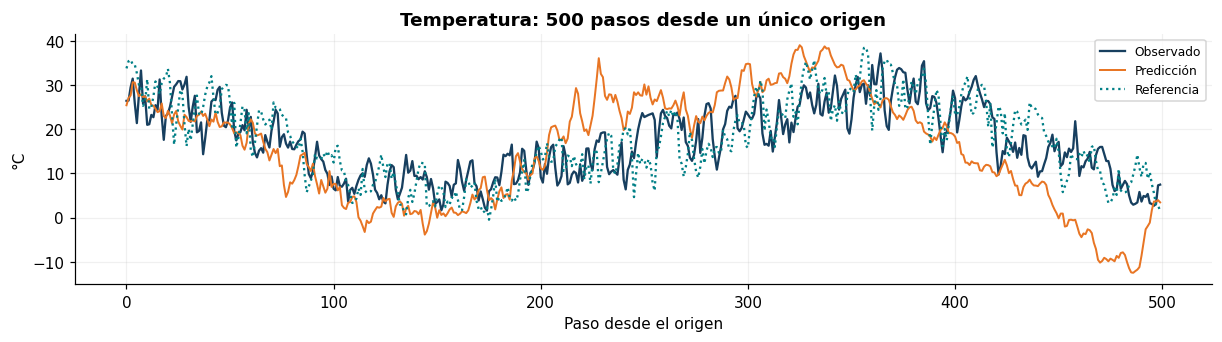

,Método,n,mae,rmse,r2,correlacion,acierto_pct
0,MLP recursiva,500,7.64768,9.37452,-0.31929,0.67380,89.2
1,Estacional 365,500,4.83966,5.98577,0.46212,0.76742,99.8


,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,5.46217,4.14043,-0.00283,NaN,47.80220
Persistencia,2.05373,1.52857,0.85823,0.9289,2.74725


,Capa,Salida,Parámetros
0,Dense,"(None, 64)",704
1,Dense,"(None, 32)",2080
2,Dense,"(None, 1)",33


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,2.92396,2.21927,0.87476,0.93547,55.36028
Validación,1.74194,1.35679,0.83411,0.91740,55.86207
Prueba,2.04043,1.44613,0.86006,0.92877,55.49451


Épocas: 13 / 40; mejor validación: 6; tiempo: 1.3 s.


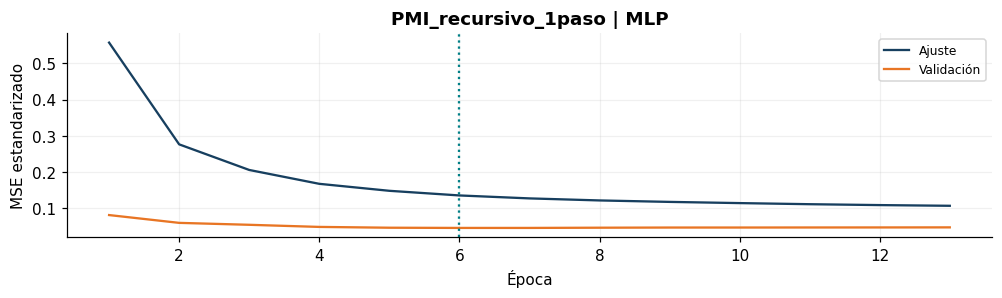

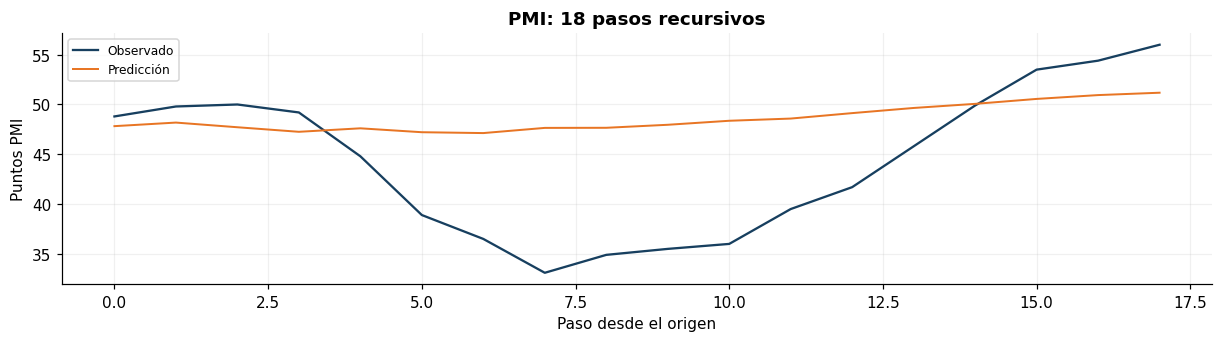

In [55]:
b_temp=preparar('Temperatura_recursiva_1paso',temperatura,365,unidad='°C')
referencias(b_temp)
r_temp,p_temp,_=entrenar(b_temp,'MLP',neuronas=(64,32),epocas=30,lote=128)
origen_temp=int(b_temp['t'][b_temp['mascaras']['Prueba']][0])
futuro_temp=temperatura[origen_temp:origen_temp+500]
rec_temp=trayectoria(b_temp,r_temp,500)
estacional_temp=np.resize(temperatura[origen_temp-365:origen_temp],500)
grafico_trayectoria(futuro_temp,rec_temp,'Temperatura: 500 pasos desde un único origen','°C',estacional_temp)
display(pd.DataFrame([{'Método':'MLP recursiva',**evaluar(futuro_temp,rec_temp)},
                     {'Método':'Estacional 365',**evaluar(futuro_temp,estacional_temp)}]))
b_pmi=preparar('PMI_recursivo_1paso',pmi,10,unidad='Puntos PMI')
referencias(b_pmi)
r_pmi,p_pmi,_=entrenar(b_pmi,'MLP',neuronas=(64,32),epocas=40,lote=32)
origen_pmi=int(b_pmi['t'][b_pmi['mascaras']['Prueba']][0])
rec_pmi=trayectoria(b_pmi,r_pmi,18)
grafico_trayectoria(pmi[origen_pmi:origen_pmi+18],rec_pmi,'PMI: 18 pasos recursivos','Puntos PMI')

### 5. Pronóstico directo con salida múltiple

Una red con 18 salidas entrega de una vez el trayecto del PMI. La salida múltiple no necesita usar una predicción como entrada de la siguiente. Aquí se usa el término **directo de salida múltiple**, para distinguirlo de entrenar un modelo independiente por horizonte.

Las etiquetas de 18 o 500 pasos deben quedar íntegramente dentro de ajuste, validación o prueba. Las ventanas que atraviesan un corte se descartan. Se comparan las dos estrategias del PMI en el mismo primer origen de prueba y se agrega un modelo pequeño de 1 rezago y dos neuronas por capa, como ejercicio de capacidad limitada. Su resultado no se presupone inferior.

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,5.44057,4.09478,-0.00209,-0.05145,66.66667
Persistencia,7.91272,5.97389,-1.11968,-0.03570,1.11111


,Capa,Salida,Parámetros
0,Dense,"(None, 64)",704
1,Dense,"(None, 64)",4160
2,Dense,"(None, 18)",1170


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,6.64450,5.15657,0.32786,0.57323,71.17552
Validación,4.10206,3.19437,0.15543,0.45363,77.95139
Prueba,5.02063,3.48327,0.14664,0.40659,73.88889


Épocas: 18 / 40; mejor validación: 11; tiempo: 1.6 s.


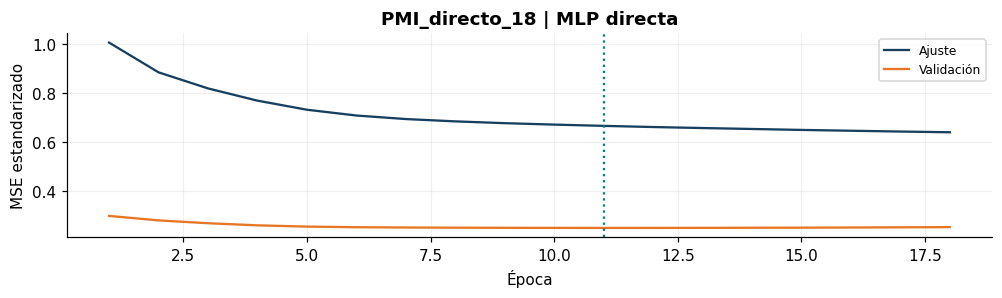

,Método,rmse,mae,r2
0,Directo 18,11.08535,8.43599,-1.34244
1,Recursivo 18,7.75237,6.24768,-0.14561
2,Persistencia,8.50075,6.80556,-0.37748


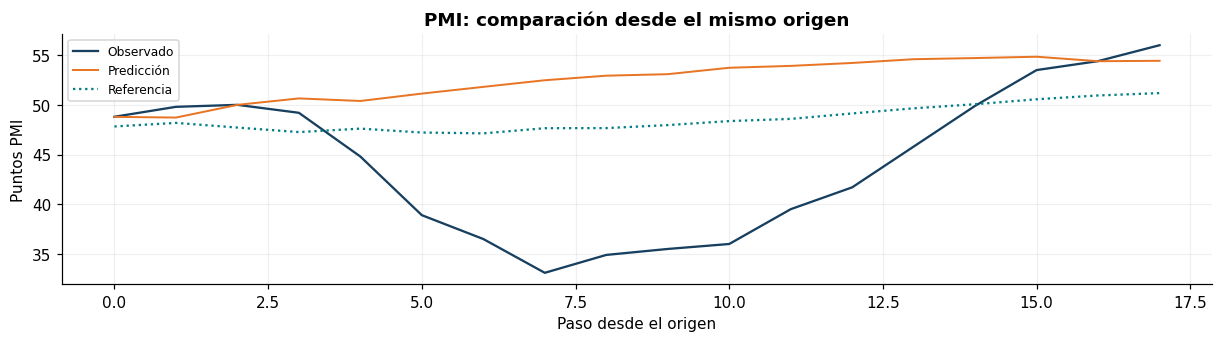

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,5.43952,4.10163,-0.00171,0.02283,66.66667
Persistencia,7.91272,5.97389,-1.11968,-0.03570,1.11111


,Capa,Salida,Parámetros
0,Dense,"(None, 2)",4
1,Dense,"(None, 2)",6
2,Dense,"(None, 18)",54


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,8.19868,6.45537,0.00759,0.08946,66.95385
Validación,4.51548,3.48415,-0.02338,0.09986,75.13021
Prueba,5.45808,4.14604,-0.00855,-0.01568,66.66667


Épocas: 10 / 10; mejor validación: 10; tiempo: 1.2 s.


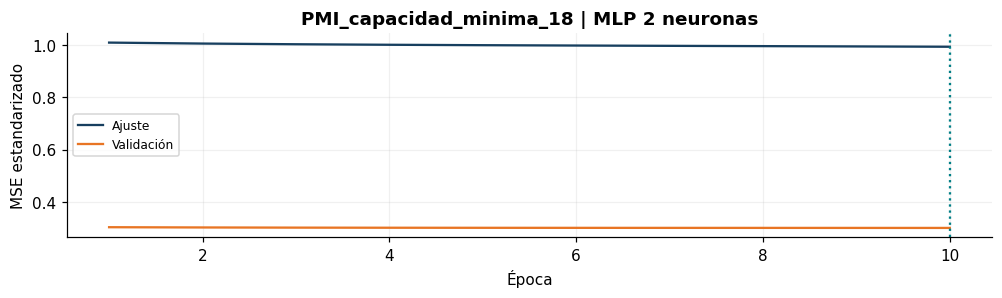

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,8.22693,6.94726,-0.02159,-0.32987,81.0
Persistencia,11.47398,9.30326,-0.98715,0.20702,0.2


,Capa,Salida,Parámetros
0,Dense,"(None, 64)",23424
1,Dense,"(None, 64)",4160
2,Dense,"(None, 500)",32500


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,4.54895,3.70352,0.72225,0.85364,87.26236
Validación,4.84588,4.01011,0.72979,0.86621,87.34790
Prueba,4.76234,3.85915,0.65767,0.84026,82.50000


Épocas: 25 / 25; mejor validación: 25; tiempo: 3.4 s.


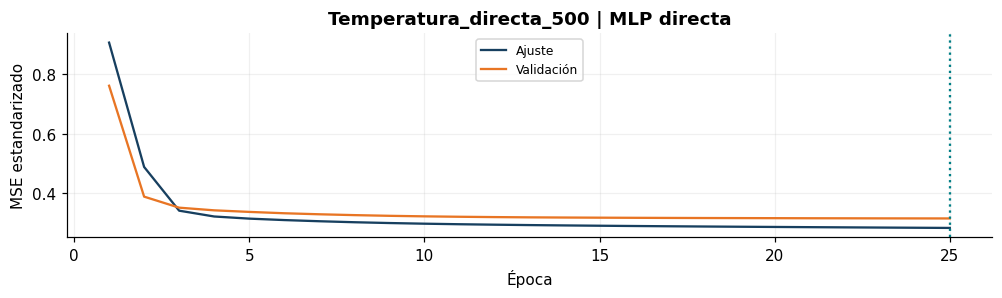

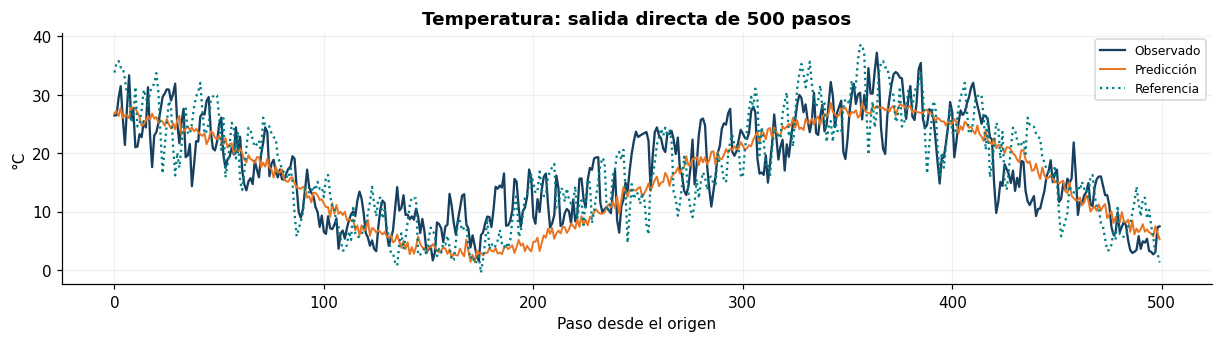

In [56]:
b_pd=preparar('PMI_directo_18',pmi,10,18,unidad='Puntos PMI')
referencias(b_pd)
r_pd,p_pd,_=entrenar(b_pd,'MLP directa',neuronas=(64,64),epocas=40,lote=32)
k=int(np.flatnonzero(b_pd['mascaras']['Prueba'])[0]);assert b_pd['t'][k]==origen_pmi
real18=b_pd['y'][k];directo18=p_pd[k]
display(pd.DataFrame([
    {'Método':'Directo 18',**evaluar(real18,directo18)},
    {'Método':'Recursivo 18',**evaluar(real18,rec_pmi)},
    {'Método':'Persistencia',**evaluar(real18,np.full(18,pmi[origen_pmi-1]))},
])[['Método','rmse','mae','r2']])
grafico_trayectoria(real18,directo18,'PMI: comparación desde el mismo origen','Puntos PMI',rec_pmi)
b_min=preparar('PMI_capacidad_minima_18',pmi,1,18,unidad='Puntos PMI')
referencias(b_min)
_,p_min,_=entrenar(b_min,'MLP 2 neuronas',neuronas=(2,2),epocas=10,lote=32)
b_td=preparar('Temperatura_directa_500',temperatura,365,500,unidad='°C')
referencias(b_td)
_,p_td,_=entrenar(b_td,'MLP directa',neuronas=(64,64),epocas=25,lote=128)
j=int(np.flatnonzero(b_td['mascaras']['Prueba'])[0]);assert b_td['t'][j]==origen_temp
grafico_trayectoria(b_td['y'][j],p_td[j],'Temperatura: salida directa de 500 pasos','°C',estacional_temp)

### 6. Regularización sobre autocorrelación móvil

Se calcula la autocorrelación de retardo 1 dentro de ventanas de 20 niveles del S&P 500. Después se predice su siguiente valor con una LSTM de 24 unidades, BatchNormalization, dropout de 10 % y parada temprana. Se usan 60 rezagos, en lugar de los 500 y las 128 unidades del ejemplo, para que el avance se ejecute en CPU.

La parada observa **validación**, no la pérdida de ajuste. BatchNormalization tiene distinto comportamiento en ajuste e inferencia; los escaladores de entrada siguen aprendiendo solo con el tramo inicial. Esta tarea pronostica un indicador de dependencia, no el precio ni la rentabilidad. Que la autocorrelación sea alta no demuestra por sí solo que vaya a ocurrir una reversión del mercado.

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,0.13849,0.10598,-0.02042,NaN,55.35168
Persistencia,0.04681,0.03174,0.88345,0.94162,0.00000


,Capa,Salida,Parámetros
0,LSTM,"(None, 24)",2496
1,BatchNormalization,"(None, 24)",96
2,Dropout,"(None, 24)",0
3,Dense,"(None, 1)",25


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,0.14591,0.10720,0.19748,0.90211,50.96447
Validación,0.13925,0.11108,0.17043,0.87650,57.47126
Prueba,0.12342,0.09504,0.18964,0.88895,54.74006


Épocas: 8 / 40; mejor validación: 1; tiempo: 3.4 s.


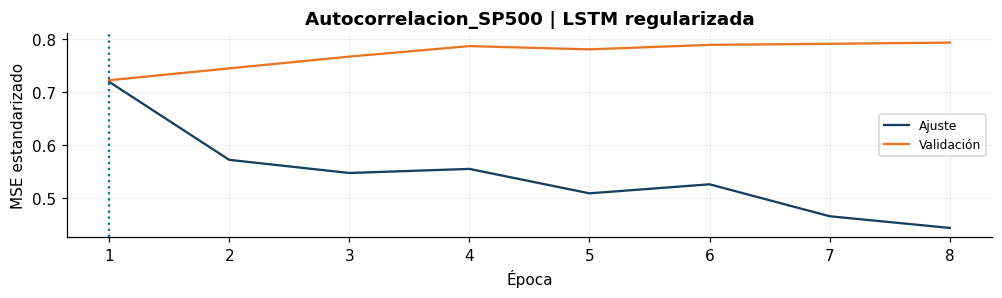

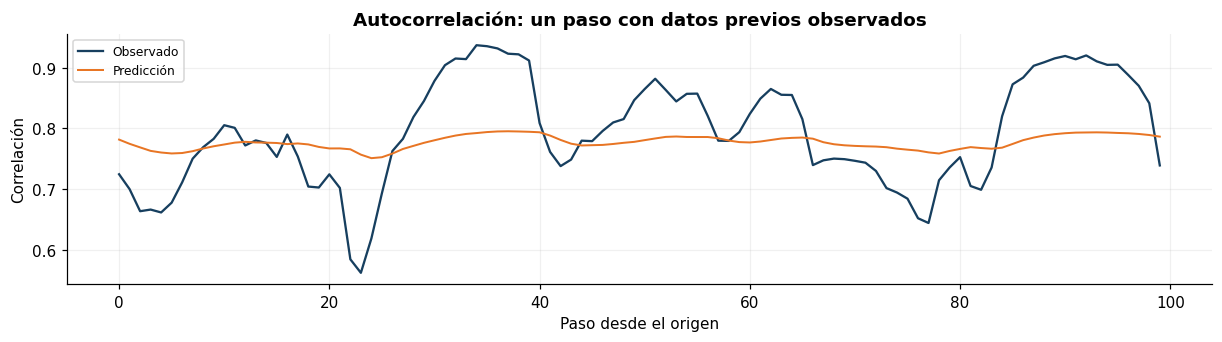

Otras técnicas del capítulo: **L1/L2** penalizan pesos; **DropConnect** elimina conexiones durante ajuste; **restricciones de pesos** limitan magnitudes; el **entrenamiento adversario** busca robustez ante perturbaciones. Se describen como ampliaciones y no se presentan como experimentos realizados en este avance.

In [57]:
acf=sp['valor'].rolling(20).apply(lambda z:np.corrcoef(z[:-1],z[1:])[0,1],raw=True).dropna().to_numpy()
b_acf=preparar('Autocorrelacion_SP500',acf,60,unidad='Correlación')
referencias(b_acf)
_,p_acf,_=entrenar(b_acf,'LSTM regularizada',recurrente=True,neuronas=(24,),epocas=40,regularizado=True)
jj=np.flatnonzero(b_acf['mascaras']['Prueba'])
grafico_trayectoria(b_acf['y'][jj[:100],0],p_acf[jj[:100],0],
                   'Autocorrelación: un paso con datos previos observados','Correlación')
display(Markdown('Otras técnicas del capítulo: **L1/L2** penalizan pesos; **DropConnect** elimina conexiones durante ajuste; '
                 '**restricciones de pesos** limitan magnitudes; el **entrenamiento adversario** busca robustez ante perturbaciones. '
                 'Se describen como ampliaciones y no se presentan como experimentos realizados en este avance.'))

### 7. Consultas SQL, resultados y conclusiones

La base resultante registra cada tarea por separado, sus valores de origen, métricas, pronósticos y curvas de aprendizaje. El MAE se recalcula mediante SQL para comprobar la consistencia de las predicciones almacenadas. En pronóstico multiperíodo se indica el número de valores evaluados; no se consideran ensayos independientes para pruebas de significancia.

In [58]:
metricas9,conexion9=exportar(9)
carpeta9=Path.cwd()/'salidas_capitulo_9'
with sqlite3.connect(carpeta9/'capitulo_9.sqlite') as db:
    for nombre,tabla in [('adf',tabla_adf),('umbrales',tabla_umbrales),
                         ('reentrenamiento',tabla_walk),('validacion_temporal',tabla_cv)]:
        tabla.to_sql(nombre,db,index=False,if_exists='replace')
        tabla.to_csv(carpeta9/(nombre+'.csv'),index=False)
adf_rechazos=int(tabla_adf['Rechazo_raíz_5pct'].sum())
mejor_walk=tabla_walk.loc[tabla_walk['rmse'].idxmin(),'Modelo']
display(Markdown(textwrap.dedent(f"""
- Las transformaciones tienen **{adf_rechazos} rechazos de raíz unitaria de {len(tabla_adf)} pruebas** en el tramo de ajuste. Los p-valores pertenecen a estas muestras, no a las cifras del libro.
- El filtrado mostró coberturas diferentes. Seleccionar menos señales no permite afirmar automáticamente mayor exactitud ni rentabilidad.
- En esta ejecución, **{mejor_walk}** obtuvo el menor RMSE de los tres esquemas de actualización. El reentrenamiento no garantiza mejorar.
- Se implementaron ventanas expansivas y deslizantes sin usar el futuro ni la prueba final para elegirlas.
- PMI y temperatura cuentan con proyecciones recursivas y directas. Los pronósticos desde un único origen no reciben observaciones reales posteriores a ese origen.
- La LSTM regularizada pronostica autocorrelación; sus métricas no equivalen a resultados de una estrategia de mercado.
""")))

,caso,modelo,rmse,acierto_pct
0,Autocorrelacion_SP500,Persistencia,0.04681,0.00
1,Autocorrelacion_SP500,LSTM regularizada,0.12342,54.74
2,Autocorrelacion_SP500,Media de ajuste,0.13849,55.35
3,EURUSD_umbral,Cero,0.00498,0.51
4,EURUSD_umbral,Media de ajuste,0.00498,49.19
5,EURUSD_umbral,MLP,0.00522,49.70
6,PMI_capacidad_minima_18,Media de ajuste,5.43952,66.67
7,PMI_capacidad_minima_18,MLP 2 neuronas,5.45808,66.67
8,PMI_capacidad_minima_18,Persistencia,7.91272,1.11
9,PMI_directo_18,MLP directa,5.02063,73.89


Archivos creados en salidas_capitulo_9 | Integridad y verificación SQL del MAE correctas.



- Las transformaciones tienen **4 rechazos de raíz unitaria de 7 pruebas** en el tramo de ajuste. Los p-valores pertenecen a estas muestras, no a las cifras del libro.
- El filtrado mostró coberturas diferentes. Seleccionar menos señales no permite afirmar automáticamente mayor exactitud ni rentabilidad.
- En esta ejecución, **Cada 10 datos** obtuvo el menor RMSE de los tres esquemas de actualización. El reentrenamiento no garantiza mejorar.
- Se implementaron ventanas expansivas y deslizantes sin usar el futuro ni la prueba final para elegirlas.
- PMI y temperatura cuentan con proyecciones recursivas y directas. Los pronósticos desde un único origen no reciben observaciones reales posteriores a ese origen.
- La LSTM regularizada pronostica autocorrelación; sus métricas no equivalen a resultados de una estrategia de mercado.


#### Alcance y referencias

Las ventanas y redes reducidas, los máximos de 10 a 40 épocas, la validación interna y la exclusión de etiquetas que cruzan cortes son adaptaciones explícitas. Las arquitecturas y parámetros están editables en las celdas. No se optimizan para reproducir las cifras del PDF. La estación, los cambios de distribución y el tamaño limitado del conjunto requieren evaluación posterior en periodos nuevos.

- Kaabar, S. (2024). *Deep Learning for Finance*. O'Reilly. Capítulo 9, PDF proporcionado de 45 páginas.
- Repositorio oficial y datos: https://github.com/sofienkaabar/deep-learning-for-finance
- FRED: https://fred.stlouisfed.org/series/SP500 y https://fred.stlouisfed.org/series/DEXUSEU
- ADF: https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html
- Validación temporal: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html
- Regularización: https://keras.io/api/layers/normalization_layers/batch_normalization/ y https://keras.io/api/callbacks/early_stopping/

In [59]:
# Registrar las versiones de cada sección sin modificar sus variables.
P_VERSIONES['capitulo_9'] = (dict(zip(versiones['Componente'],versiones['Versión']))
    if isinstance(versiones,pd.DataFrame) else dict(versiones))

## Capítulo 10. Aprendizaje por refuerzo profundo

Esta sección conserva el desarrollo del avance y vuelve a ejecutar sus experimentos con los datos incluidos. Las referencias y limitaciones específicas se mantienen al final del capítulo.

Este cuaderno desarrolla estados, acciones, recompensas, ecuación de Bellman, exploración, memoria de experiencias y Double DQN. El ejemplo es una **onda sinusoidal simulada**, como en el capítulo. No representa una operación financiera.

| Apartado del PDF | Páginas | Desarrollo |
|---|---:|---|
| Intuición, estados, acciones y recompensas | 1-5 | Definiciones y ejemplo numérico |
| Q-learning, política y exploración | 5-11 | Actualización de Bellman, alfa, gamma y épsilon |
| Aprendizaje profundo, memoria y DDQN | 11-17 | Dos redes, experiencias y objetivos terminales |
| Experimentos sobre seno | 17-22 | Cinco configuraciones inspiradas en las figuras del capítulo |
| Dificultades y síntesis | 22-24 | Prueba temporal, referencias y límites |

**Corrección necesaria:** el programa del repositorio declara una sola acción y una recompensa que no depende de acertar la predicción. Eso no permite comparar decisiones de pronóstico. Aquí se utiliza una rejilla de 41 acciones numéricas y una recompensa ligada al error. El valor Q estima recompensa acumulada; la predicción es el valor de la acción elegida, no el propio valor Q.

### Entorno y forma de ejecución

Abrir este `.ipynb` en Jupyter o Google Colab y ejecutar sus celdas en orden. Los datos utilizados están incluidos; no hacen falta archivos auxiliares ni `master_function.py`. La primera celda instala bibliotecas ausentes y necesita internet solo en ese caso. Se utiliza CPU y semilla 123. Las versiones quedan registradas; puede haber pequeñas diferencias entre plataformas.

El objetivo es reproducir el método con resultados comprobables. Las arquitecturas se reducen en los casos indicados para facilitar su ejecución. Los resultados se calculan aquí y no se copian de las tablas del libro.

In [60]:
import base64, gzip, hashlib, io, json, sqlite3, inspect, textwrap
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.stattools import adfuller
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, HTML

SEMILLA = 123
keras.utils.set_random_seed(SEMILLA)
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    pass
tf.config.experimental.enable_op_determinism()
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi':110, 'font.size':10, 'axes.grid':True,
                     'grid.alpha':0.18, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.titleweight':'bold'})
versiones = {m:version(m) for m in ['numpy','pandas','matplotlib','scikit-learn','statsmodels']}
versiones['TensorFlow']=tf.__version__;versiones['Keras']=keras.__version__
versiones['Python'] = sys.version.split()[0]
versiones['SQLite'] = sqlite3.sqlite_version
display(pd.DataFrame(versiones.items(),columns=['Componente','Versión']))

,Componente,Versión
0,numpy,2.3.5
1,pandas,2.2.3
2,matplotlib,3.10.8
3,scikit-learn,1.8.0
4,statsmodels,0.15.0
5,TensorFlow,2.20.0
6,Keras,3.12.0
7,Python,3.12.14
8,SQLite,3.53.1


### Funciones de preparación y evaluación

Se construyen ventanas del dato más antiguo al más reciente. En los modelos supervisados, el primer 64 % de la serie ajusta pesos y escaladores, el siguiente 16 % valida y el 20 % final se reserva para prueba. En salidas múltiples se eliminan las ventanas cuyos **objetivos** cruzan una frontera entre bloques.

Los errores se calculan en las unidades originales después de deshacer el escalado. RMSE y MAE menores indican menor error; R² puede ser negativo. Una correlación constante queda sin definir. Para cambios alrededor de cero, el acierto compara signos. Para niveles, compara el signo del desplazamiento respecto al último valor conocido en el origen.

Las trayectorias de prueba multiperíodo se evalúan desde orígenes separados por el horizonte, evitando contar el mismo objetivo en varios pronósticos solapados. Las entradas sí pueden compartir pasado ya conocido. Se indican los horizontes de cada caso; las métricas de series o tareas diferentes no deben mezclarse para obtener un ganador global.

Se distinguen tres signos: positivo, negativo y cero. Una referencia que pronostica exactamente cero cambio puede tener poco acierto direccional y aun así un RMSE bajo. No se interpreta un cero como aumento o disminución.

In [61]:
def p_adf(valores):
    opciones={'maxlag':12,'autolag':'AIC'}
    if 'result_object' in inspect.signature(adfuller).parameters:
        opciones['result_object']=False
    return float(adfuller(np.asarray(valores).ravel(),**opciones)[1])

def ventanas(valores, rezagos, horizonte=1):
    v = np.asarray(valores, dtype=float).ravel()
    t = np.arange(rezagos, len(v)-horizonte+1)
    x = np.array([v[i-rezagos:i] for i in t])
    y = np.array([v[i:i+horizonte] for i in t])
    return x, y, t

casos, resultados, pronosticos, aprendizajes, modelos_guardados = {}, [], [], [], {}

def preparar(nombre, valores, rezagos, horizonte=1, unidad='', cambio=False):
    v = np.asarray(valores,dtype=float).ravel()
    assert np.isfinite(v).all()
    x,y,t = ventanas(v,rezagos,horizonte)
    limite_ajuste, limite_prueba = int(len(v)*0.64), int(len(v)*0.80)
    mascaras = {'Ajuste': t+horizonte <= limite_ajuste,
                'Validación': (t>=limite_ajuste)&(t+horizonte<=limite_prueba),
                'Prueba': t>=limite_prueba}
    assert all(m.sum()>0 for m in mascaras.values()), 'Se necesitan más datos o una ventana menor.'
    mu,sd = float(v[:limite_ajuste].mean()),float(v[:limite_ajuste].std())
    sd = sd if sd>0 else 1.0
    b = dict(nombre=nombre,v=v,x=x,y=y,t=t,L=rezagos,H=horizonte,mu=mu,sd=sd,
             xs=((x-mu)/sd).astype('float32'), ys=((y-mu)/sd).astype('float32'),
             mascaras=mascaras,unidad=unidad,cambio=cambio)
    casos[nombre]=b
    return b

def evaluar(real,pred,base=None):
    a,b=np.asarray(real,dtype=float),np.asarray(pred,dtype=float)
    assert a.shape==b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    af,bf=a.ravel(),b.ravel()
    corr = float(np.corrcoef(af,bf)[0,1]) if np.ptp(af)>0 and np.ptp(bf)>0 else np.nan
    da,db = a,b
    if base is not None:
        origen=np.asarray(base).reshape(-1,1)
        da,db=a-origen,b-origen
    return dict(n=len(af),mae=float(mean_absolute_error(af,bf)),
                rmse=float(np.sqrt(mean_squared_error(af,bf))),
                r2=float(r2_score(af,bf)) if len(af)>1 else np.nan,
                correlacion=corr,acierto_pct=float(100*np.mean(np.sign(da)==np.sign(db))))

def registrar(b,nombre,pred):
    pred=np.asarray(pred).reshape(b['y'].shape)
    filas=[]
    for particion,mask in b['mascaras'].items():
        ii=np.flatnonzero(mask)
        # En prueba multiperíodo se evalúan bloques sin objetivos solapados.
        if particion=='Prueba' and b['H']>1: ii=ii[::b['H']]
        origen=b['v'][b['t'][ii]-1] if not b['cambio'] else None
        fila=dict(caso=b['nombre'],modelo=nombre,particion=particion,
                  **evaluar(b['y'][ii],pred[ii],origen))
        resultados.append(fila);filas.append(fila)
        if particion=='Prueba':
            for k in ii:
                for h in range(b['H']):
                    pronosticos.append((b['nombre'],nombre,int(b['t'][k]-1),h+1,
                                        float(b['y'][k,h]),float(pred[k,h])))
    return pd.DataFrame(filas).set_index('particion')[['rmse','mae','r2','correlacion','acierto_pct']]

def referencias(b):
    media=b['y'][b['mascaras']['Ajuste']].mean(axis=0)
    p_media=np.tile(media,(len(b['y']),1))
    p_simple=np.zeros_like(b['y']) if b['cambio'] else np.repeat(b['v'][b['t']-1,None],b['H'],axis=1)
    filas=[]
    for nombre,p in [('Media de ajuste',p_media),('Cero' if b['cambio'] else 'Persistencia',p_simple)]:
        filas.append(registrar(b,nombre,p).loc['Prueba'].rename(nombre))
    display(pd.DataFrame(filas).round(5))

def dataset(x,y=None,lote=64):
    ds=tf.data.Dataset.from_tensor_slices(x if y is None else (x,y)).batch(lote)
    opts=tf.data.Options();opts.threading.private_threadpool_size=1
    opts.threading.max_intra_op_parallelism=1;opts.experimental_deterministic=True
    return ds.with_options(opts).prefetch(1)

def entrenar(b,nombre='Red',recurrente=False,neuronas=(32,32),epocas=40,lote=64,
             regularizado=False,callbacks_adicionales=None):
    keras.utils.set_random_seed(SEMILLA)
    x=b['xs'][...,None] if recurrente and b['xs'].ndim==2 else b['xs']
    capas=[keras.Input(shape=x.shape[1:])]
    if recurrente: capas.append(layers.LSTM(neuronas[0]))
    else: capas.append(layers.Dense(neuronas[0],activation='relu'))
    if regularizado: capas.extend([layers.BatchNormalization(),layers.Dropout(0.1,seed=SEMILLA)])
    for n in neuronas[1:]: capas.append(layers.Dense(n,activation='relu'))
    capas.append(layers.Dense(b['H']))
    red=keras.Sequential(capas)
    red.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='mse')
    display(pd.DataFrame([{'Capa':type(c).__name__,'Salida':str(tuple(c.output.shape)),
                          'Parámetros':c.count_params()} for c in red.layers]))
    es=keras.callbacks.EarlyStopping(monitor='val_loss',patience=7,restore_best_weights=True)
    inicio=perf_counter()
    hist=red.fit(dataset(x[b['mascaras']['Ajuste']],b['ys'][b['mascaras']['Ajuste']],lote),
                 validation_data=dataset(x[b['mascaras']['Validación']],b['ys'][b['mascaras']['Validación']],lote),
                 epochs=epocas,shuffle=False,verbose=0,
                 callbacks=[es]+list(callbacks_adicionales or []))
    p=red.predict(dataset(x,lote=128),verbose=0)*b['sd']+b['mu']
    display(registrar(b,nombre,p).round(5))
    for i,(loss,val) in enumerate(zip(hist.history['loss'],hist.history['val_loss'])):
        aprendizajes.append((b['nombre'],nombre,i+1,float(loss),float(val)))
    modelos_guardados[b['nombre']+'__'+nombre]=red
    mejor=int(np.argmin(hist.history['val_loss'])+1)
    print(f'Épocas: {len(hist.history["loss"])} / {epocas}; mejor validación: {mejor}; tiempo: {perf_counter()-inicio:.1f} s.')
    fig,ax=plt.subplots(figsize=(9,2.6),layout='constrained')
    eje_epocas=np.arange(1,len(hist.history['loss'])+1)
    ax.plot(eje_epocas,hist.history['loss'],label='Ajuste',color='#173F5F')
    ax.plot(eje_epocas,hist.history['val_loss'],label='Validación',color='#E87524')
    ax.axvline(mejor,color='#007F86',ls=':')
    ax.set(title=b['nombre']+' | '+nombre,xlabel='Época',ylabel='MSE estandarizado')
    ax.legend(fontsize=8);plt.show()
    return red,p,hist

def trayectoria(b,modelo,horizonte,inicio=None):
    assert b['H']==1
    t=int(b['t'][b['mascaras']['Prueba']][0]) if inicio is None else int(inicio)
    memoria=b['v'][t-b['L']:t].copy();salida=[]
    for _ in range(horizonte):
        xx=((memoria-b['mu'])/b['sd']).astype('float32')[None,:]
        if len(modelo.input_shape)==3: xx=xx[...,None]
        nuevo=float(modelo(xx,training=False).numpy().ravel()[0]*b['sd']+b['mu'])
        salida.append(nuevo);memoria=np.r_[memoria[1:],nuevo]
    return np.array(salida)

def grafico_trayectoria(real,pred,titulo,unidad='',base=None):
    fig,ax=plt.subplots(figsize=(11,3),layout='constrained')
    ax.plot(real,color='#173F5F',lw=1.5,label='Observado')
    ax.plot(pred,color='#E87524',lw=1.3,label='Predicción')
    if base is not None: ax.plot(base,color='#007F86',ls=':',label='Referencia')
    ax.set(title=titulo,xlabel='Paso desde el origen',ylabel=unidad);ax.legend(fontsize=8);plt.show()

def exportar(capitulo):
    carpeta=Path.cwd()/f'salidas_capitulo_{capitulo}';carpeta.mkdir(exist_ok=True)
    m=pd.DataFrame(resultados)
    conexion=sqlite3.connect(':memory:');conexion.execute('PRAGMA foreign_keys=ON')
    conexion.executescript("""
    CREATE TABLE casos(caso TEXT PRIMARY KEY,unidad TEXT,rezagos INTEGER,horizontes INTEGER);
    CREATE TABLE datos(caso TEXT,indice INTEGER,valor REAL,PRIMARY KEY(caso,indice),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE metricas(caso TEXT,modelo TEXT,particion TEXT,n INTEGER,mae REAL,rmse REAL,r2 REAL,correlacion REAL,acierto_pct REAL,
                         PRIMARY KEY(caso,modelo,particion),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE predicciones(caso TEXT,modelo TEXT,origen INTEGER,horizonte INTEGER,real REAL,predicho REAL,
                         PRIMARY KEY(caso,modelo,origen,horizonte),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE aprendizaje(caso TEXT,modelo TEXT,epoca INTEGER,loss REAL,val_loss REAL,
                         PRIMARY KEY(caso,modelo,epoca),FOREIGN KEY(caso) REFERENCES casos(caso));
    """)
    for nombre,b in casos.items():
        conexion.execute('INSERT INTO casos VALUES(?,?,?,?)',(nombre,b['unidad'],b['L'],b['H']))
        conexion.executemany('INSERT INTO datos VALUES(?,?,?)',[(nombre,i,float(v)) for i,v in enumerate(b['v'])])
    m.to_sql('metricas',conexion,index=False,if_exists='append')
    conexion.executemany('INSERT INTO predicciones VALUES(?,?,?,?,?,?)',pronosticos)
    conexion.executemany('INSERT INTO aprendizaje VALUES(?,?,?,?,?)',aprendizajes)
    conexion.commit()
    assert conexion.execute('PRAGMA foreign_key_check').fetchall()==[]
    assert conexion.execute('PRAGMA integrity_check').fetchone()[0]=='ok'
    ver=pd.read_sql_query('SELECT caso,modelo,AVG(ABS(real-predicho)) AS mae_sql FROM predicciones GROUP BY caso,modelo',conexion)
    control=m.query("particion=='Prueba'").merge(ver,on=['caso','modelo'],validate='one_to_one')
    assert np.allclose(control['mae'],control['mae_sql'],rtol=1e-9,atol=1e-10)
    with sqlite3.connect(carpeta/f'capitulo_{capitulo}.sqlite') as db: conexion.backup(db)
    m.to_csv(carpeta/'metricas.csv',index=False)
    pd.DataFrame(pronosticos,columns=['caso','modelo','origen','horizonte','real','predicho']).to_csv(carpeta/'predicciones.csv',index=False)
    pd.DataFrame(aprendizajes,columns=['caso','modelo','epoca','loss','val_loss']).to_csv(carpeta/'aprendizaje.csv',index=False)
    (carpeta/'configuracion.json').write_text(json.dumps({'estudiante':'Juan Fernando Castrejón Villa',
        'matricula':'81901','versiones':versiones,'semilla':SEMILLA,'fecha':P_FECHA},ensure_ascii=False,indent=2))
    display(pd.read_sql_query('SELECT caso,modelo,ROUND(rmse,6) AS rmse,ROUND(acierto_pct,2) AS acierto_pct FROM metricas WHERE particion="Prueba" ORDER BY caso,rmse',conexion))
    print('Archivos creados en',carpeta.name,'| Integridad y verificación SQL del MAE correctas.')
    return m,conexion

### 1. Elementos del aprendizaje por refuerzo

| Elemento | En este experimento |
|---|---|
| Estado | Las últimas 5 u 8 observaciones del seno |
| Acción | Elegir uno de 41 valores entre -1 y 1 como pronóstico |
| Recompensa | $r=-(\hat y-y)^2$, mayor cuanto menor sea el error |
| Política | Regla para elegir una acción a partir del estado |
| Episodio | Un recorrido por el bloque de ajuste |
| Fin de episodio | Última transición de ajuste; no se agrega valor futuro |

Para Q-learning:

$$Q(s,a)\leftarrow Q(s,a)+\alpha\,[r+\gamma\max_{a'}Q(s',a')-Q(s,a)].$$

**Alfa** controla el paso de actualización. **Gamma** descuenta recompensas futuras; gamma igual a cero sigue permitiendo aprender recompensas inmediatas. **Épsilon** es la probabilidad de explorar una acción aleatoria. Se distinguen estos parámetros porque un pasaje del PDF confunde la interpretación de gamma.

In [62]:
alfa,gamma,epsilon=0.1,0.9,0.3
q_actual,recompensa,maximo_siguiente=0.4,1.0,1.5
objetivo_bellman=recompensa+gamma*maximo_siguiente
q_nuevo=q_actual+alfa*(objetivo_bellman-q_actual)
display(pd.DataFrame({'Q anterior':[q_actual],'Recompensa':[recompensa],
                      'Objetivo Bellman':[objetivo_bellman],'Q actualizado':[q_nuevo]}))
assert np.isclose(q_nuevo,0.595)
print('Si la transición fuera terminal, el objetivo sería solo la recompensa: 1.0.')

,Q anterior,Recompensa,Objetivo Bellman,Q actualizado
0,0.4,1.0,2.35,0.595


Si la transición fuera terminal, el objetivo sería solo la recompensa: 1.0.


### 2. Serie, acciones y separación temporal

Se crean 500 observaciones de `sin(t)`, con paso fijo. Se respeta el mismo paso de muestreo en ajuste y prueba; no se modifica la frecuencia al evaluar. Todos los experimentos se alinean a las mismas fechas objetivo, a partir de la observación 8.

Los valores entre -1 y 1 son conocidos por la definición matemática del seno. La rejilla se fija antes de entrenar. Su resolución introduce un error de cuantización. No se atribuyen a los datos simulados propiedades demostradas en series financieras.

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,0.70767,0.63697,-0.00159,NaN,51.0
Persistencia,0.04442,0.04000,0.99605,0.99803,0.0


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,7.32608e-16,4.56970e-16,1.0,1.0,100.0
Validación,1.16178e-15,8.37355e-16,1.0,1.0,100.0
Prueba,1.31124e-15,9.08256e-16,1.0,1.0,100.0


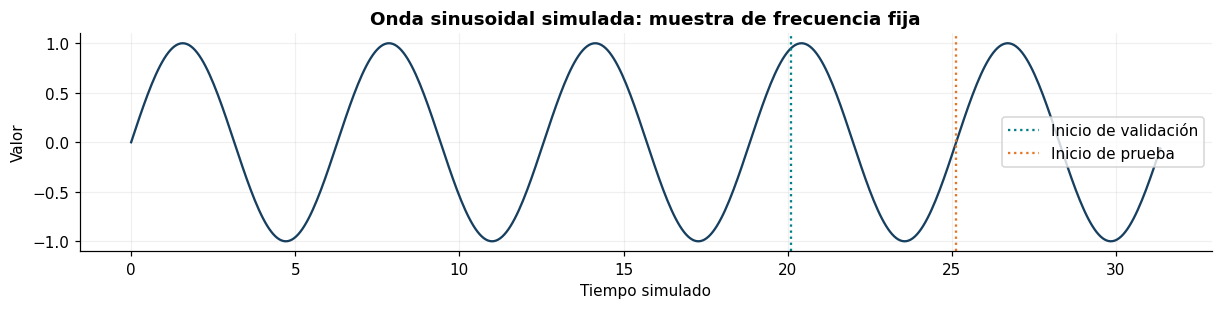

In [63]:
eje=np.arange(500)*10*np.pi/500
seno=np.sin(eje)
acciones=np.linspace(-1,1,41).astype('float32')
b_seno=preparar('Seno_DDQN',seno,8,unidad='Unidades simuladas')
referencias(b_seno)
ma=b_seno['mascaras']['Ajuste']
with threadpool_limits(limits=2):
    lineal=LinearRegression().fit(b_seno['x'][ma],b_seno['y'][ma])
    pred_lineal=lineal.predict(b_seno['x'])
display(registrar(b_seno,'Regresión lineal',pred_lineal))
fig,ax=plt.subplots(figsize=(11,2.7),layout='constrained')
ax.plot(eje,seno,color='#173F5F')
ax.axvline(eje[int(len(seno)*.64)],ls=':',color='#007F86',label='Inicio de validación')
ax.axvline(eje[int(len(seno)*.8)],ls=':',color='#E87524',label='Inicio de prueba')
ax.set(title='Onda sinusoidal simulada: muestra de frecuencia fija',xlabel='Tiempo simulado',ylabel='Valor')
ax.legend();plt.show()

### 3. Memoria de experiencias y Double DQN

Cada experiencia conserva $(s,a,r,s',terminal)$. El búfer solo recibe transiciones de ajuste y se muestrean lotes aleatorios de esa memoria; esto no equivale a mezclar fechas de ajuste con validación o prueba.

DQN ya puede usar una red objetivo. La diferencia de **Double DQN** es que selecciona la siguiente acción con la red en línea y evalúa esa acción con la red objetivo:

$$a^*=\arg\max_a Q_{online}(s',a),\qquad
z=r+\gamma(1-terminal)Q_{objetivo}(s',a^*).$$

Los pesos de la red objetivo se copian al inicio y cada 50 actualizaciones. Las transiciones terminales no incorporan recompensa futura. Se usa Adam con tasa 0.001 y límite de norma del gradiente de 5 para estabilizar el entrenamiento. Una actualización se realiza cada cuatro observaciones, con memoria máxima de 5,000 experiencias.

In [64]:
class AgenteDDQN:
    def __init__(self,rezagos,ocultas,lote,semilla=123):
        keras.utils.set_random_seed(semilla)
        self.rezagos,self.lote=rezagos,lote
        self.rng=np.random.default_rng(semilla)
        self.memoria=deque(maxlen=5000)
        self.gamma=0.9;self.epsilon=1.0;self.actualizaciones=0
        def construir():
            capas=[keras.Input(shape=(rezagos,))]
            capas.extend(layers.Dense(k,activation='relu') for k in ocultas)
            capas.append(layers.Dense(len(acciones)))
            return keras.Sequential(capas)
        self.online,self.objetivo=construir(),construir()
        self.objetivo.set_weights(self.online.get_weights())
        self.optimizador=keras.optimizers.Adam(learning_rate=0.001,clipnorm=5.0)
        firma=[tf.TensorSpec((None,rezagos),tf.float32),tf.TensorSpec((None,),tf.int32),
               tf.TensorSpec((None,),tf.float32),tf.TensorSpec((None,rezagos),tf.float32),
               tf.TensorSpec((None,),tf.float32)]
        self.actualizar=tf.function(self._actualizar,input_signature=firma)
    def elegir(self,s,explorar=True):
        if explorar and self.rng.random()<self.epsilon:return int(self.rng.integers(len(acciones)))
        return int(np.argmax(self.online(s[None,:],training=False).numpy()[0]))
    def _actualizar(self,s,a,r,ss,terminal):
        siguiente_accion=tf.argmax(self.online(ss,training=False),axis=1,output_type=tf.int32)
        q_siguiente=tf.gather(self.objetivo(ss,training=False),siguiente_accion,batch_dims=1)
        destino=tf.stop_gradient(r+self.gamma*(1-terminal)*q_siguiente)
        with tf.GradientTape() as cinta:
            estimado=tf.gather(self.online(s,training=True),a,batch_dims=1)
            perdida=tf.reduce_mean(tf.square(destino-estimado))
        gradientes=cinta.gradient(perdida,self.online.trainable_variables)
        self.optimizador.apply_gradients(zip(gradientes,self.online.trainable_variables))
        return perdida
    def repetir(self):
        indices=self.rng.choice(len(self.memoria),size=self.lote,replace=False)
        lote=[self.memoria[int(i)] for i in indices]
        s=np.stack([e[0] for e in lote]).astype('float32')
        a=np.array([e[1] for e in lote],dtype='int32')
        r=np.array([e[2] for e in lote],dtype='float32')
        ss=np.stack([e[3] for e in lote]).astype('float32')
        terminal=np.array([e[4] for e in lote],dtype='float32')
        perdida=float(self.actualizar(s,a,r,ss,terminal).numpy())
        self.actualizaciones+=1
        if self.actualizaciones%50==0:self.objetivo.set_weights(self.online.get_weights())
        return perdida
    def predecir(self,x):
        q=self.online(np.asarray(x,dtype='float32'),training=False).numpy()
        return acciones[np.argmax(q,axis=1)]

# Ejemplo de terminal: no importa cuánto valga la siguiente acción.
assert np.isclose(2.0+0.9*(1-1)*999,2.0)
assert len(acciones)>1

### 4. Entrenamiento y cinco configuraciones

Se mantienen las cinco combinaciones de capas, episodios, rezagos y lotes de las figuras del capítulo, pero con una implementación corregida. Épsilon empieza en 1, se multiplica por 0.8 al final de cada episodio y no baja de 0.1. En validación y prueba se elige siempre la mejor acción estimada; no se explora ni se actualizan pesos.

La recompensa depende del error de la acción elegida. La trayectoria del seno es externa y no cambia por la decisión del agente: este es un entorno didáctico de pronóstico, no uno donde comprar o vender altere posiciones y capital. El seno de frecuencia fija admite una relación lineal exacta con dos rezagos; por eso una regresión puede tener error casi cero sin fuga de futuro. Además, su salida es continua y la del DDQN pertenece a una rejilla; la comparación debe considerar ese error de cuantización.

In [65]:
configuraciones=[
    ('A: 6 unidades, 1 episodio',5,(6,),1,64),
    ('B: 6-6 unidades, 1 episodio',5,(6,6),1,64),
    ('C: 6-6 unidades, 10 episodios',5,(6,6),10,32),
    ('D: 24-24 unidades, 10 episodios',5,(24,24),10,32),
    ('E: 64-64 unidades, 8 rezagos',8,(64,64),10,32),
]
resumen_config=[];registros_episodios=[];agentes={};pred_ddqn={}
for nombre,lags,ocultas,episodios,lote in configuraciones:
    X=np.array([seno[t-lags:t] for t in b_seno['t']],dtype='float32')
    indices_ajuste=np.flatnonzero(b_seno['mascaras']['Ajuste'])
    assert b_seno['t'][indices_ajuste].max()<int(len(seno)*.64)
    agente=AgenteDDQN(lags,ocultas,lote)
    contador=0;inicio=perf_counter()
    for episodio in range(1,episodios+1):
        recompensas=[];perdidas=[]
        for posicion,k in enumerate(indices_ajuste):
            estado=X[k];a=agente.elegir(estado)
            r=-float((acciones[a]-b_seno['y'][k,0])**2)
            terminal=posicion==len(indices_ajuste)-1
            siguiente=np.zeros(lags,dtype='float32') if terminal else X[indices_ajuste[posicion+1]]
            agente.memoria.append((estado.copy(),a,r,siguiente.copy(),float(terminal)))
            contador+=1;recompensas.append(r)
            if len(agente.memoria)>=lote and contador%4==0:perdidas.append(agente.repetir())
        pv=agente.predecir(X[b_seno['mascaras']['Validación']])
        registros_episodios.append({'modelo':nombre,'episodio':episodio,
            'epsilon':agente.epsilon,'recompensa_media':np.mean(recompensas),
            'mse_TD':np.mean(perdidas),'rmse_validacion':np.sqrt(mean_squared_error(
                b_seno['y'][b_seno['mascaras']['Validación'],0],pv))})
        agente.epsilon=max(0.1,agente.epsilon*.8)
    pesos_antes=[w.copy() for w in agente.online.get_weights()]
    pred=agente.predecir(X)
    assert all(np.array_equal(a,b) for a,b in zip(pesos_antes,agente.online.get_weights()))
    assert np.isin(pred,acciones).all()
    pred_ddqn[nombre]=pred;agentes[nombre]=agente
    display(Markdown('**'+nombre+'**'))
    display(registrar(b_seno,nombre,pred[:,None]).round(5))
    resumen_config.append({'modelo':nombre,'rezagos':lags,'capas':str(ocultas),'episodios':episodios,
                           'lote':lote,'actualizaciones':agente.actualizaciones,'segundos':perf_counter()-inicio})
tabla_episodios=pd.DataFrame(registros_episodios)
display(pd.DataFrame(resumen_config))

**A: 6 unidades, 1 episodio**

,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,0.96641,0.72503,-0.8627,0.11311,46.15385
Validación,0.89477,0.63776,-0.5469,0.17413,51.25000
Prueba,0.94499,0.70023,-0.7860,0.13320,48.00000


**B: 6-6 unidades, 1 episodio**

,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,1.15089,1.03707,-1.64171,-0.87506,49.03846
Validación,1.26017,1.18008,-2.06828,-0.92641,55.00000
Prueba,1.16457,1.05408,-1.71247,-0.87693,51.00000


**C: 6-6 unidades, 10 episodios**

,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,0.22683,0.18120,0.89738,0.94797,38.14103
Validación,0.24201,0.19520,0.88684,0.94237,36.25000
Prueba,0.23002,0.18443,0.89418,0.94630,38.00000


**D: 24-24 unidades, 10 episodios**

,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,0.18945,0.15915,0.92842,0.96459,56.73077
Validación,0.19372,0.16256,0.92749,0.96342,50.00000
Prueba,0.19076,0.16015,0.92722,0.96361,55.00000


**E: 64-64 unidades, 8 rezagos**

,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,0.12361,0.10415,0.96953,0.98843,65.0641
Validación,0.13196,0.11227,0.96636,0.98798,68.7500
Prueba,0.12446,0.10479,0.96902,0.98829,66.0000


,modelo,rezagos,capas,episodios,lote,actualizaciones,segundos
0,"A: 6 unidades, 1 episodio",5,"(6,)",1,64,63,0.97224
1,"B: 6-6 unidades, 1 episodio",5,"(6, 6)",1,64,63,0.78962
2,"C: 6-6 unidades, 10 episodios",5,"(6, 6)",10,32,773,6.87533
3,"D: 24-24 unidades, 10 episodios",5,"(24, 24)",10,32,773,6.66373
4,"E: 64-64 unidades, 8 rezagos",8,"(64, 64)",10,32,773,7.39890


### 5. Evaluación sin aprendizaje sobre la prueba

Cada pronóstico usa la ventana real anterior disponible. No es una trayectoria completamente recursiva. El entrenamiento termina en el bloque de ajuste y los ejemplos de validación y prueba nunca se guardan en la memoria de experiencias.

La curva de error temporal-diferencia evalúa objetivos de Bellman; no es la misma magnitud que el error de pronóstico. Se reportan por separado recompensa de ajuste, error TD y RMSE de validación. Los resultados de prueba se comparan una sola vez, sin cambiar la configuración según ellos.

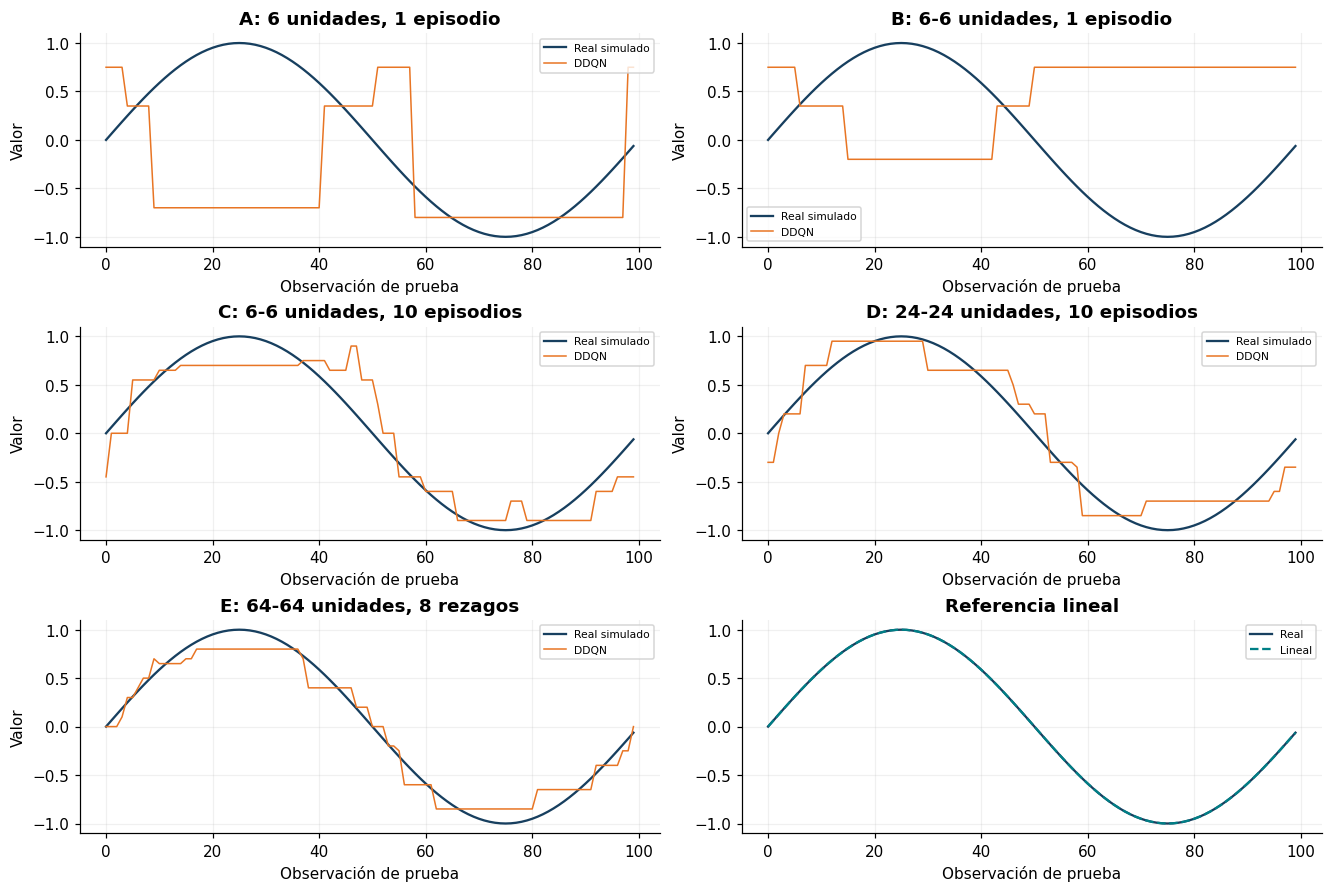

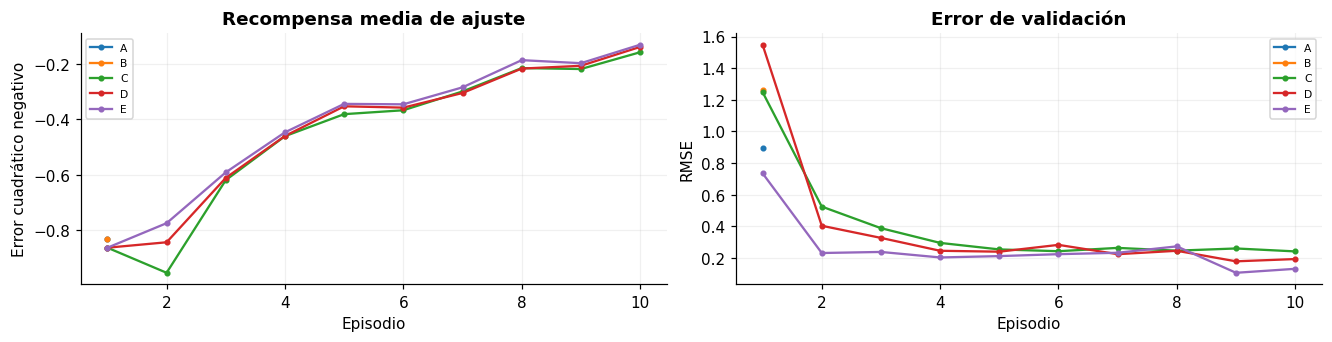

In [66]:
ii=np.flatnonzero(b_seno['mascaras']['Prueba'])
fig,axes=plt.subplots(3,2,figsize=(12,8),layout='constrained')
for ax,(nombre,pred) in zip(axes.flat,pred_ddqn.items()):
    ax.plot(b_seno['y'][ii,0],color='#173F5F',label='Real simulado')
    ax.plot(pred[ii],color='#E87524',lw=1,label='DDQN')
    ax.set(title=nombre,xlabel='Observación de prueba',ylabel='Valor');ax.legend(fontsize=7)
axes.flat[-1].plot(b_seno['y'][ii,0],color='#173F5F',label='Real')
axes.flat[-1].plot(pred_lineal[ii,0],ls='--',color='#007F86',label='Lineal')
axes.flat[-1].set(title='Referencia lineal',xlabel='Observación de prueba');axes.flat[-1].legend(fontsize=7)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,3),layout='constrained')
for nombre,g in tabla_episodios.groupby('modelo'):
    axes[0].plot(g['episodio'],g['recompensa_media'],marker='.',label=nombre.split(':')[0])
    axes[1].plot(g['episodio'],g['rmse_validacion'],marker='.',label=nombre.split(':')[0])
axes[0].set(title='Recompensa media de ajuste',xlabel='Episodio',ylabel='Error cuadrático negativo')
axes[1].set(title='Error de validación',xlabel='Episodio',ylabel='RMSE')
for ax in axes:ax.legend(fontsize=7)
plt.show()

### 6. Registro y conclusiones

Se guarda una base SQLite con la onda, las métricas y los pronósticos. La tabla adicional `episodios` permite revisar la evolución de cada agente. El ejemplo no calcula ganancias, capital, costos ni operaciones.

In [67]:
metricas10,conexion10=exportar(10)
carpeta10=Path.cwd()/'salidas_capitulo_10'
tabla_episodios.to_csv(carpeta10/'episodios.csv',index=False)
with sqlite3.connect(carpeta10/'capitulo_10.sqlite') as db:
    tabla_episodios.to_sql('episodios',db,index=False,if_exists='replace')
prueba10=metricas10.query("particion=='Prueba'").set_index('modelo')
mejor=prueba10['rmse'].idxmin()
mejor_agente=prueba10.loc[list(pred_ddqn),'rmse'].idxmin()
display(Markdown(textwrap.dedent(f"""
- Se implementó una actualización de Bellman con distinción entre alfa, gamma y épsilon.
- El agente dispone de **41 acciones**, memoria limitada, dos redes y objetivos terminales correctamente tratados.
- Se ejecutaron **cinco configuraciones** sobre una onda simulada de frecuencia fija, con una prueba temporal común de **{len(ii)} observaciones**.
- El menor RMSE entre referencias y agentes correspondió a **{mejor}**. Entre los agentes, el menor fue **{mejor_agente}**. Estas comparaciones describen esta ejecución; no prueban superioridad general.
- La evaluación no actualizó los pesos. Se comprobó que las predicciones pertenecen a la rejilla de acciones y que no se almacenaron estados de prueba en el entrenamiento.
- Un resultado en un seno determinista no demuestra que un sistema pueda operar rentablemente en mercados reales.
""")))

,caso,modelo,rmse,acierto_pct
0,Seno_DDQN,Regresión lineal,0.00000,100.0
1,Seno_DDQN,Persistencia,0.04442,0.0
2,Seno_DDQN,"E: 64-64 unidades, 8 rezagos",0.12447,66.0
3,Seno_DDQN,"D: 24-24 unidades, 10 episodios",0.19076,55.0
4,Seno_DDQN,"C: 6-6 unidades, 10 episodios",0.23002,38.0
5,Seno_DDQN,Media de ajuste,0.70767,51.0
6,Seno_DDQN,"A: 6 unidades, 1 episodio",0.94499,48.0
7,Seno_DDQN,"B: 6-6 unidades, 1 episodio",1.16457,51.0


Archivos creados en salidas_capitulo_10 | Integridad y verificación SQL del MAE correctas.



- Se implementó una actualización de Bellman con distinción entre alfa, gamma y épsilon.
- El agente dispone de **41 acciones**, memoria limitada, dos redes y objetivos terminales correctamente tratados.
- Se ejecutaron **cinco configuraciones** sobre una onda simulada de frecuencia fija, con una prueba temporal común de **100 observaciones**.
- El menor RMSE entre referencias y agentes correspondió a **Regresión lineal**. Entre los agentes, el menor fue **E: 64-64 unidades, 8 rezagos**. Estas comparaciones describen esta ejecución; no prueban superioridad general.
- La evaluación no actualizó los pesos. Se comprobó que las predicciones pertenecen a la rejilla de acciones y que no se almacenaron estados de prueba en el entrenamiento.
- Un resultado en un seno determinista no demuestra que un sistema pueda operar rentablemente en mercados reales.


#### Límites, adaptaciones y referencias

La rejilla discreta, el diseño de recompensa, la reducción periódica de exploración y el muestreo de la memoria son decisiones explícitas. Con una sola semilla no se mide la variabilidad del entrenamiento. La red puede predecir casi siempre el mismo valor; eso es un resultado a diagnosticar, no una razón para ocultar el experimento. Se requerirían más semillas, otros procesos, un entorno de posiciones y una evaluación independiente para estudiar una aplicación financiera.

- Kaabar, S. (2024). *Deep Learning for Finance*. O'Reilly. Capítulo 10, PDF proporcionado de 24 páginas.
- Código del autor consultado como referencia: https://github.com/sofienkaabar/deep-learning-for-finance/tree/main/Chapter%2010
- Van Hasselt, H., Guez, A., y Silver, D. (2015). *Deep Reinforcement Learning with Double Q-learning*. https://arxiv.org/abs/1509.06461
- TensorFlow, diferenciación automática: https://www.tensorflow.org/guide/autodiff

El código es una implementación didáctica corregida del método descrito. La onda es simulada y todos sus resultados se obtienen ejecutando las celdas.

In [68]:
# Registrar las versiones de cada sección sin modificar sus variables.
P_VERSIONES['capitulo_10'] = (dict(zip(versiones['Componente'],versiones['Versión']))
    if isinstance(versiones,pd.DataFrame) else dict(versiones))

## Capítulo 11. Técnicas y aplicaciones avanzadas

Esta sección conserva el desarrollo del avance y vuelve a ejecutar sus experimentos con los datos incluidos. Las referencias y limitaciones específicas se mantienen al final del capítulo.

El avance aplica las herramientas anteriores a tres tipos de información: posicionamiento de participantes en futuros, indicadores técnicos y variabilidad del precio de Bitcoin. También permite observar cómo cambian las predicciones durante el entrenamiento de una red.

| Apartado del PDF | Páginas | Desarrollo |
|---|---:|---|
| Datos COT y CAD | 1-10 | Fuente, categorías, cálculo neto, correlación descriptiva y ADF |
| Tres algoritmos COT | 11-20 | LSTM de un paso, directo de 50 pasos y recursivo |
| Integración y calidad del modelado | 21-24 | Cortes temporales y preparación de variables |
| Indicadores técnicos como entradas | 23-30 | RSI, distancia a media y LSTM multivariable |
| Volatilidad de Bitcoin | 30-44 | Escalas, desviación móvil y pronóstico de cambios |
| Visualización del entrenamiento | 44-54 | Callback, visualización dinámica y arquitectura |
| Síntesis | 55-56 | Resultados, límites y siguientes pasos |

Se utilizan datos reales de los archivos históricos del repositorio oficial y las muestras FRED documentadas. No se crean posiciones COT ni precios de Bitcoin simulados. Las redes tienen tamaños menores que algunas del material, indicados en las celdas, para que el avance sea reproducible en CPU.

### Entorno y forma de ejecución

Abrir este `.ipynb` en Jupyter o Google Colab y ejecutar sus celdas en orden. Los datos utilizados están incluidos; no hacen falta archivos auxiliares ni `master_function.py`. La primera celda instala bibliotecas ausentes y necesita internet solo en ese caso. Se utiliza CPU y semilla 123. Las versiones quedan registradas; puede haber pequeñas diferencias entre plataformas.

El objetivo es reproducir el método con resultados comprobables. Las arquitecturas se reducen en los casos indicados para facilitar su ejecución. Los resultados se calculan aquí y no se copian de las tablas del libro.

In [69]:
import base64, gzip, hashlib, io, json, sqlite3, inspect, textwrap
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.stattools import adfuller
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, HTML

SEMILLA = 123
keras.utils.set_random_seed(SEMILLA)
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    pass
tf.config.experimental.enable_op_determinism()
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi':110, 'font.size':10, 'axes.grid':True,
                     'grid.alpha':0.18, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.titleweight':'bold'})
versiones = {m:version(m) for m in ['numpy','pandas','matplotlib','scikit-learn','statsmodels']}
versiones['TensorFlow']=tf.__version__;versiones['Keras']=keras.__version__
versiones['Python'] = sys.version.split()[0]
versiones['SQLite'] = sqlite3.sqlite_version
display(pd.DataFrame(versiones.items(),columns=['Componente','Versión']))

,Componente,Versión
0,numpy,2.3.5
1,pandas,2.2.3
2,matplotlib,3.10.8
3,scikit-learn,1.8.0
4,statsmodels,0.15.0
5,TensorFlow,2.20.0
6,Keras,3.12.0
7,Python,3.12.14
8,SQLite,3.53.1


### 1. Fuentes y alcance temporal

Los archivos COT CAD, Bitcoin y PMI se descargaron del repositorio del autor, fijando la revisión y verificando la integridad del conjunto incluido. El archivo COT conserva fechas reales de los informes. Bitcoin y PMI **no incluyen fechas**: se usan índices de observación, sin deducir un calendario a partir de los precios. El PMI empieza con una observación numérica y se conserva al leerlo sin encabezado.

La cotización USDCAD se consulta en FRED y se invierte para obtener **CADUSD**. EUR/USD conserva la muestra histórica del capítulo 7. Las fuentes son muestras históricas para este proyecto, no una consulta de mercado en tiempo real.

In [70]:
# Datos congelados para que el avance se pueda reproducir sin nuevas descargas.
BLOB = """
...
"""
contenido = json.loads(gzip.decompress(base64.b64decode(BLOB)))
datos = {}
for nombre, paquete in contenido.items():
    assert hashlib.sha256(paquete['csv'].encode()).hexdigest() == paquete['sha256_csv']
    datos[nombre] = pd.read_csv(io.StringIO(paquete['csv']))
display(pd.DataFrame([
    {'Serie':n,'Filas':len(datos[n]),'Consulta':p['consulta'],'Fuente':p['fuente']}
    for n,p in contenido.items()
]))

,Serie,Filas,Consulta,Fuente
0,cot,449,2026-11-12,https://raw.githubusercontent.com/sofienkaabar...
1,bitcoin,3123,2026-11-12,https://raw.githubusercontent.com/sofienkaabar...
2,pmi,906,2026-11-12,https://raw.githubusercontent.com/sofienkaabar...
3,euro,6109,2026-11-05,https://fred.stlouisfed.org/series/DEXUSEU
4,cad,2243,2026-11-12,https://fred.stlouisfed.org/series/DEXCAUS


In [71]:
cot=datos['cot'].copy();cot['fecha']=pd.to_datetime(cot['fecha'])
cot=cot.sort_values('fecha').reset_index(drop=True)
btc=datos['bitcoin']['valor'].to_numpy(dtype=float)
pmi=datos['pmi']['valor'].to_numpy(dtype=float)
eur=datos['euro'].dropna(subset=['valor']).copy();eur['fecha']=pd.to_datetime(eur['fecha'])
cad=datos['cad'].dropna(subset=['CADUSD']).copy();cad['fecha']=pd.to_datetime(cad['fecha'])
assert cot['fecha'].is_unique and len(cot)==449
assert len(btc)==3123 and len(pmi)==906 and (btc>0).all()
display(pd.DataFrame({'Serie':['COT CAD','Bitcoin','PMI','EURUSD','CADUSD'],
                      'Valores válidos':[len(cot),len(btc),len(pmi),len(eur),len(cad)]}))
print('Informes COT:',cot['fecha'].min().date(),'a',cot['fecha'].max().date())

,Serie,Valores válidos
0,COT CAD,449
1,Bitcoin,3123
2,PMI,906
3,EURUSD,5873
4,CADUSD,2149


Informes COT: 2015-01-06 a 2023-08-08


### Funciones de preparación y evaluación

Se construyen ventanas del dato más antiguo al más reciente. En los modelos supervisados, el primer 64 % de la serie ajusta pesos y escaladores, el siguiente 16 % valida y el 20 % final se reserva para prueba. En salidas múltiples se eliminan las ventanas cuyos **objetivos** cruzan una frontera entre bloques.

Los errores se calculan en las unidades originales después de deshacer el escalado. RMSE y MAE menores indican menor error; R² puede ser negativo. Una correlación constante queda sin definir. Para cambios alrededor de cero, el acierto compara signos. Para niveles, compara el signo del desplazamiento respecto al último valor conocido en el origen.

Las trayectorias de prueba multiperíodo se evalúan desde orígenes separados por el horizonte, evitando contar el mismo objetivo en varios pronósticos solapados. Las entradas sí pueden compartir pasado ya conocido. Se indican los horizontes de cada caso; las métricas de series o tareas diferentes no deben mezclarse para obtener un ganador global.

Se distinguen tres signos: positivo, negativo y cero. Una referencia que pronostica exactamente cero cambio puede tener poco acierto direccional y aun así un RMSE bajo. No se interpreta un cero como aumento o disminución.

In [72]:
def p_adf(valores):
    opciones={'maxlag':12,'autolag':'AIC'}
    if 'result_object' in inspect.signature(adfuller).parameters:
        opciones['result_object']=False
    return float(adfuller(np.asarray(valores).ravel(),**opciones)[1])

def ventanas(valores, rezagos, horizonte=1):
    v = np.asarray(valores, dtype=float).ravel()
    t = np.arange(rezagos, len(v)-horizonte+1)
    x = np.array([v[i-rezagos:i] for i in t])
    y = np.array([v[i:i+horizonte] for i in t])
    return x, y, t

casos, resultados, pronosticos, aprendizajes, modelos_guardados = {}, [], [], [], {}

def preparar(nombre, valores, rezagos, horizonte=1, unidad='', cambio=False):
    v = np.asarray(valores,dtype=float).ravel()
    assert np.isfinite(v).all()
    x,y,t = ventanas(v,rezagos,horizonte)
    limite_ajuste, limite_prueba = int(len(v)*0.64), int(len(v)*0.80)
    mascaras = {'Ajuste': t+horizonte <= limite_ajuste,
                'Validación': (t>=limite_ajuste)&(t+horizonte<=limite_prueba),
                'Prueba': t>=limite_prueba}
    assert all(m.sum()>0 for m in mascaras.values()), 'Se necesitan más datos o una ventana menor.'
    mu,sd = float(v[:limite_ajuste].mean()),float(v[:limite_ajuste].std())
    sd = sd if sd>0 else 1.0
    b = dict(nombre=nombre,v=v,x=x,y=y,t=t,L=rezagos,H=horizonte,mu=mu,sd=sd,
             xs=((x-mu)/sd).astype('float32'), ys=((y-mu)/sd).astype('float32'),
             mascaras=mascaras,unidad=unidad,cambio=cambio)
    casos[nombre]=b
    return b

def evaluar(real,pred,base=None):
    a,b=np.asarray(real,dtype=float),np.asarray(pred,dtype=float)
    assert a.shape==b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    af,bf=a.ravel(),b.ravel()
    corr = float(np.corrcoef(af,bf)[0,1]) if np.ptp(af)>0 and np.ptp(bf)>0 else np.nan
    da,db = a,b
    if base is not None:
        origen=np.asarray(base).reshape(-1,1)
        da,db=a-origen,b-origen
    return dict(n=len(af),mae=float(mean_absolute_error(af,bf)),
                rmse=float(np.sqrt(mean_squared_error(af,bf))),
                r2=float(r2_score(af,bf)) if len(af)>1 else np.nan,
                correlacion=corr,acierto_pct=float(100*np.mean(np.sign(da)==np.sign(db))))

def registrar(b,nombre,pred):
    pred=np.asarray(pred).reshape(b['y'].shape)
    filas=[]
    for particion,mask in b['mascaras'].items():
        ii=np.flatnonzero(mask)
        # En prueba multiperíodo se evalúan bloques sin objetivos solapados.
        if particion=='Prueba' and b['H']>1: ii=ii[::b['H']]
        origen=b['v'][b['t'][ii]-1] if not b['cambio'] else None
        fila=dict(caso=b['nombre'],modelo=nombre,particion=particion,
                  **evaluar(b['y'][ii],pred[ii],origen))
        resultados.append(fila);filas.append(fila)
        if particion=='Prueba':
            for k in ii:
                for h in range(b['H']):
                    pronosticos.append((b['nombre'],nombre,int(b['t'][k]-1),h+1,
                                        float(b['y'][k,h]),float(pred[k,h])))
    return pd.DataFrame(filas).set_index('particion')[['rmse','mae','r2','correlacion','acierto_pct']]

def referencias(b):
    media=b['y'][b['mascaras']['Ajuste']].mean(axis=0)
    p_media=np.tile(media,(len(b['y']),1))
    p_simple=np.zeros_like(b['y']) if b['cambio'] else np.repeat(b['v'][b['t']-1,None],b['H'],axis=1)
    filas=[]
    for nombre,p in [('Media de ajuste',p_media),('Cero' if b['cambio'] else 'Persistencia',p_simple)]:
        filas.append(registrar(b,nombre,p).loc['Prueba'].rename(nombre))
    display(pd.DataFrame(filas).round(5))

def dataset(x,y=None,lote=64):
    ds=tf.data.Dataset.from_tensor_slices(x if y is None else (x,y)).batch(lote)
    opts=tf.data.Options();opts.threading.private_threadpool_size=1
    opts.threading.max_intra_op_parallelism=1;opts.experimental_deterministic=True
    return ds.with_options(opts).prefetch(1)

def entrenar(b,nombre='Red',recurrente=False,neuronas=(32,32),epocas=40,lote=64,
             regularizado=False,callbacks_adicionales=None):
    keras.utils.set_random_seed(SEMILLA)
    x=b['xs'][...,None] if recurrente and b['xs'].ndim==2 else b['xs']
    capas=[keras.Input(shape=x.shape[1:])]
    if recurrente: capas.append(layers.LSTM(neuronas[0]))
    else: capas.append(layers.Dense(neuronas[0],activation='relu'))
    if regularizado: capas.extend([layers.BatchNormalization(),layers.Dropout(0.1,seed=SEMILLA)])
    for n in neuronas[1:]: capas.append(layers.Dense(n,activation='relu'))
    capas.append(layers.Dense(b['H']))
    red=keras.Sequential(capas)
    red.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='mse')
    display(pd.DataFrame([{'Capa':type(c).__name__,'Salida':str(tuple(c.output.shape)),
                          'Parámetros':c.count_params()} for c in red.layers]))
    es=keras.callbacks.EarlyStopping(monitor='val_loss',patience=7,restore_best_weights=True)
    inicio=perf_counter()
    hist=red.fit(dataset(x[b['mascaras']['Ajuste']],b['ys'][b['mascaras']['Ajuste']],lote),
                 validation_data=dataset(x[b['mascaras']['Validación']],b['ys'][b['mascaras']['Validación']],lote),
                 epochs=epocas,shuffle=False,verbose=0,
                 callbacks=[es]+list(callbacks_adicionales or []))
    p=red.predict(dataset(x,lote=128),verbose=0)*b['sd']+b['mu']
    display(registrar(b,nombre,p).round(5))
    for i,(loss,val) in enumerate(zip(hist.history['loss'],hist.history['val_loss'])):
        aprendizajes.append((b['nombre'],nombre,i+1,float(loss),float(val)))
    modelos_guardados[b['nombre']+'__'+nombre]=red
    mejor=int(np.argmin(hist.history['val_loss'])+1)
    print(f'Épocas: {len(hist.history["loss"])} / {epocas}; mejor validación: {mejor}; tiempo: {perf_counter()-inicio:.1f} s.')
    fig,ax=plt.subplots(figsize=(9,2.6),layout='constrained')
    eje_epocas=np.arange(1,len(hist.history['loss'])+1)
    ax.plot(eje_epocas,hist.history['loss'],label='Ajuste',color='#173F5F')
    ax.plot(eje_epocas,hist.history['val_loss'],label='Validación',color='#E87524')
    ax.axvline(mejor,color='#007F86',ls=':')
    ax.set(title=b['nombre']+' | '+nombre,xlabel='Época',ylabel='MSE estandarizado')
    ax.legend(fontsize=8);plt.show()
    return red,p,hist

def trayectoria(b,modelo,horizonte,inicio=None):
    assert b['H']==1
    t=int(b['t'][b['mascaras']['Prueba']][0]) if inicio is None else int(inicio)
    memoria=b['v'][t-b['L']:t].copy();salida=[]
    for _ in range(horizonte):
        xx=((memoria-b['mu'])/b['sd']).astype('float32')[None,:]
        if len(modelo.input_shape)==3: xx=xx[...,None]
        nuevo=float(modelo(xx,training=False).numpy().ravel()[0]*b['sd']+b['mu'])
        salida.append(nuevo);memoria=np.r_[memoria[1:],nuevo]
    return np.array(salida)

def grafico_trayectoria(real,pred,titulo,unidad='',base=None):
    fig,ax=plt.subplots(figsize=(11,3),layout='constrained')
    ax.plot(real,color='#173F5F',lw=1.5,label='Observado')
    ax.plot(pred,color='#E87524',lw=1.3,label='Predicción')
    if base is not None: ax.plot(base,color='#007F86',ls=':',label='Referencia')
    ax.set(title=titulo,xlabel='Paso desde el origen',ylabel=unidad);ax.legend(fontsize=8);plt.show()

def exportar(capitulo):
    carpeta=Path.cwd()/f'salidas_capitulo_{capitulo}';carpeta.mkdir(exist_ok=True)
    m=pd.DataFrame(resultados)
    conexion=sqlite3.connect(':memory:');conexion.execute('PRAGMA foreign_keys=ON')
    conexion.executescript("""
    CREATE TABLE casos(caso TEXT PRIMARY KEY,unidad TEXT,rezagos INTEGER,horizontes INTEGER);
    CREATE TABLE datos(caso TEXT,indice INTEGER,valor REAL,PRIMARY KEY(caso,indice),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE metricas(caso TEXT,modelo TEXT,particion TEXT,n INTEGER,mae REAL,rmse REAL,r2 REAL,correlacion REAL,acierto_pct REAL,
                         PRIMARY KEY(caso,modelo,particion),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE predicciones(caso TEXT,modelo TEXT,origen INTEGER,horizonte INTEGER,real REAL,predicho REAL,
                         PRIMARY KEY(caso,modelo,origen,horizonte),FOREIGN KEY(caso) REFERENCES casos(caso));
    CREATE TABLE aprendizaje(caso TEXT,modelo TEXT,epoca INTEGER,loss REAL,val_loss REAL,
                         PRIMARY KEY(caso,modelo,epoca),FOREIGN KEY(caso) REFERENCES casos(caso));
    """)
    for nombre,b in casos.items():
        conexion.execute('INSERT INTO casos VALUES(?,?,?,?)',(nombre,b['unidad'],b['L'],b['H']))
        conexion.executemany('INSERT INTO datos VALUES(?,?,?)',[(nombre,i,float(v)) for i,v in enumerate(b['v'])])
    m.to_sql('metricas',conexion,index=False,if_exists='append')
    conexion.executemany('INSERT INTO predicciones VALUES(?,?,?,?,?,?)',pronosticos)
    conexion.executemany('INSERT INTO aprendizaje VALUES(?,?,?,?,?)',aprendizajes)
    conexion.commit()
    assert conexion.execute('PRAGMA foreign_key_check').fetchall()==[]
    assert conexion.execute('PRAGMA integrity_check').fetchone()[0]=='ok'
    ver=pd.read_sql_query('SELECT caso,modelo,AVG(ABS(real-predicho)) AS mae_sql FROM predicciones GROUP BY caso,modelo',conexion)
    control=m.query("particion=='Prueba'").merge(ver,on=['caso','modelo'],validate='one_to_one')
    assert np.allclose(control['mae'],control['mae_sql'],rtol=1e-9,atol=1e-10)
    with sqlite3.connect(carpeta/f'capitulo_{capitulo}.sqlite') as db: conexion.backup(db)
    m.to_csv(carpeta/'metricas.csv',index=False)
    pd.DataFrame(pronosticos,columns=['caso','modelo','origen','horizonte','real','predicho']).to_csv(carpeta/'predicciones.csv',index=False)
    pd.DataFrame(aprendizajes,columns=['caso','modelo','epoca','loss','val_loss']).to_csv(carpeta/'aprendizaje.csv',index=False)
    (carpeta/'configuracion.json').write_text(json.dumps({'estudiante':'Juan Fernando Castrejón Villa',
        'matricula':'81901','versiones':versiones,'semilla':SEMILLA,'fecha':P_FECHA},ensure_ascii=False,indent=2))
    display(pd.read_sql_query('SELECT caso,modelo,ROUND(rmse,6) AS rmse,ROUND(acierto_pct,2) AS acierto_pct FROM metricas WHERE particion="Prueba" ORDER BY caso,rmse',conexion))
    print('Archivos creados en',carpeta.name,'| Integridad y verificación SQL del MAE correctas.')
    return m,conexion

### 2. Posicionamiento COT: qué se calcula

El capítulo presenta primero categorías generales de participantes y después utiliza columnas del informe **Traders in Financial Futures (TFF)**. En el cálculo concreto se usan **dealers/intermediarios** y **leveraged money**, que no deben confundirse automáticamente con todas las categorías comerciales y no comerciales del informe Legacy.

$$Neto_{dealer}=\%Largos_{dealer}-\%Cortos_{dealer}$$
$$Neto_{fondos}=\%Largos_{leveraged}-\%Cortos_{leveraged}$$
$$COT_{neto}=Neto_{fondos}-Neto_{dealer}$$

El resultado está en **puntos porcentuales del interés abierto**, no en contratos ni en dólares. Se comprueba contra la columna incluida en el archivo del autor.

Los informes suelen publicarse el viernes con posiciones del martes, y pueden existir retrasos. La fecha del informe no es necesariamente la de disponibilidad pública. La comparación con CADUSD de este cuaderno es **descriptiva y contemporánea**; no se usa para simular una operación con información aún no publicada. No se presupone una disponibilidad exacta tres días después en todos los años.

,fecha,Neto_dealer,Neto_fondos,Net_COT
0,2015-01-06,17.5,-22.9,-40.4
1,2015-01-13,20.3,-25.8,-46.1
2,2015-01-20,25.0,-26.2,-51.2
3,2015-01-27,24.2,-24.4,-48.6
4,2015-02-03,27.0,-26.6,-53.6


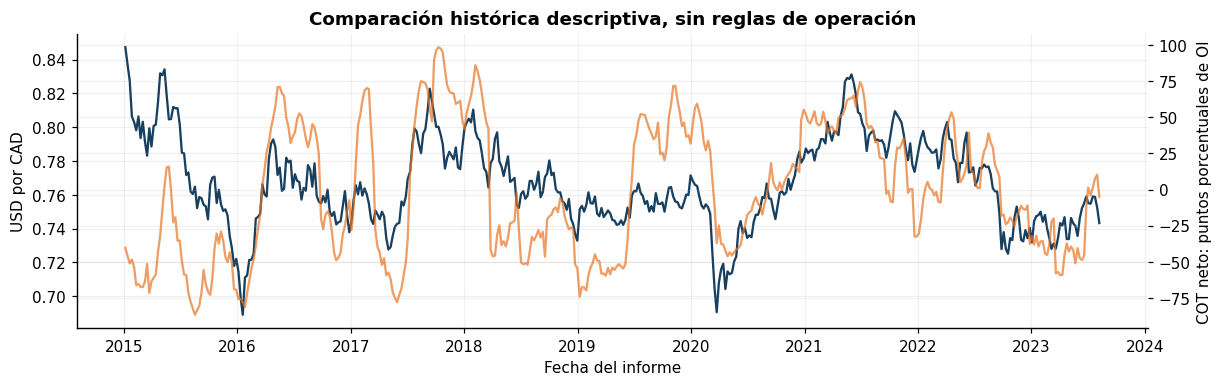

,Cálculo,Valor
0,Correlación de últimos 200 informes,0.69300
1,p ADF en ajuste del COT neto,0.00665


Una correlación de niveles no demuestra causalidad ni anticipación del precio.


In [73]:
cot['Neto_dealer']=cot['Pct_of_OI_Dealer_Long_All']-cot['Pct_of_OI_Dealer_Short_All']
cot['Neto_fondos']=cot['Pct_of_OI_Lev_Money_Long_All']-cot['Pct_of_OI_Lev_Money_Short_All']
cot['Neto_calculado']=cot['Neto_fondos']-cot['Neto_dealer']
assert np.allclose(cot['Neto_calculado'],cot['Net_COT'])
display(cot[['fecha','Neto_dealer','Neto_fondos','Net_COT']].head())
conjunto=pd.merge_asof(cot[['fecha','Net_COT']],cad[['fecha','CADUSD']].sort_values('fecha'),
                      on='fecha',direction='backward')
correlacion_200=conjunto.tail(200)[['Net_COT','CADUSD']].corr().iloc[0,1]
fig,ax=plt.subplots(figsize=(11,3.4),layout='constrained');otro=ax.twinx()
ax.plot(conjunto['fecha'],conjunto['CADUSD'],color='#173F5F',label='CADUSD')
otro.plot(conjunto['fecha'],conjunto['Net_COT'],color='#E87524',alpha=.7,label='COT neto')
ax.set(title='Comparación histórica descriptiva, sin reglas de operación',xlabel='Fecha del informe',ylabel='USD por CAD')
otro.set_ylabel('COT neto: puntos porcentuales de OI');plt.show()
neto=cot['Net_COT'].to_numpy()
p_adf_cot=p_adf(neto[:int(len(neto)*.64)])
display(pd.DataFrame({'Cálculo':['Correlación de últimos 200 informes','p ADF en ajuste del COT neto'],
                      'Valor':[correlacion_200,p_adf_cot]}))
print('Una correlación de niveles no demuestra causalidad ni anticipación del precio.')

### 3. Tres esquemas de predicción del COT

**Un paso:** una LSTM pronostica el siguiente valor del COT neto con los 100 anteriores. Durante la prueba, las ventanas usan informes anteriores observados. Es una evaluación sobre la secuencia histórica de informes; no una reconstrucción de todas sus fechas de publicación ni de sus distintas versiones.

**Directo:** una salida de 50 valores pronostica una trayectoria completa. Las etiquetas se mantienen dentro de su partición y se evalúan desde el primer origen disponible de prueba. Con 449 informes, el número de trayectorias largas independientes es limitado.

**Recursivo:** la red de un paso genera 50 predicciones sucesivas, incorporando solo sus propias estimaciones después del origen. Para aislar la diferencia entre métodos se reutiliza esa misma red. En ambos casos se predice **COT**, no el precio CADUSD. Se usan 24 unidades LSTM y 24 densas, con 40 épocas máximas y validación; el libro ensaya tamaños mayores y hasta 200 épocas.

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,29.95515,24.42079,-0.15182,NaN,60.0
Persistencia,11.48645,8.06222,0.83064,0.91671,0.0


,Capa,Salida,Parámetros
0,LSTM,"(None, 24)",2496
1,Dense,"(None, 24)",600
2,Dense,"(None, 1)",25


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,25.68810,20.24511,0.73671,0.88455,52.94118
Validación,13.67680,10.35352,0.71339,0.89259,48.61111
Prueba,17.45913,14.69624,0.60872,0.81136,53.33333


Épocas: 21 / 40; mejor validación: 14; tiempo: 4.7 s.


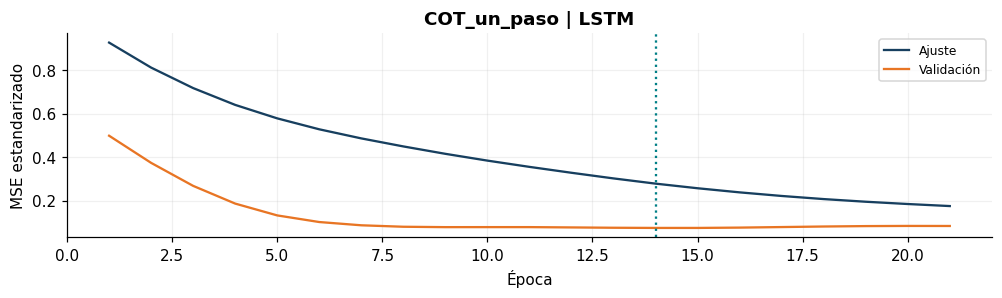

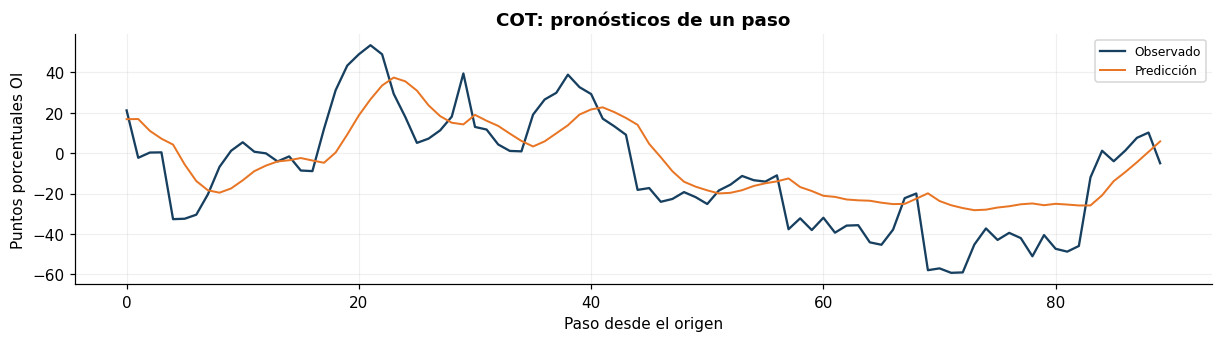

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,20.90304,16.05267,0.09836,0.46971,88.0
Persistencia,35.75911,30.56800,-1.63869,NaN,0.0


,Capa,Salida,Parámetros
0,LSTM,"(None, 24)",2496
1,Dense,"(None, 24)",600
2,Dense,"(None, 50)",1250


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,48.54530,42.79515,0.10846,0.33928,71.24638
Validación,44.52643,38.61973,-2.83076,-0.02688,50.60870
Prueba,26.64798,21.17607,-0.46536,-0.11010,88.00000


Épocas: 31 / 40; mejor validación: 24; tiempo: 5.3 s.


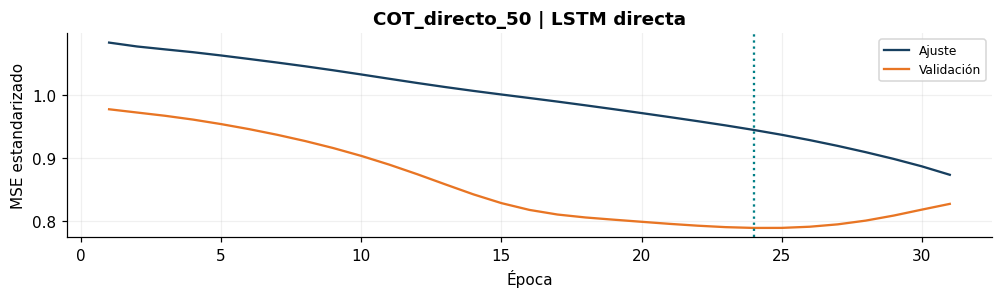

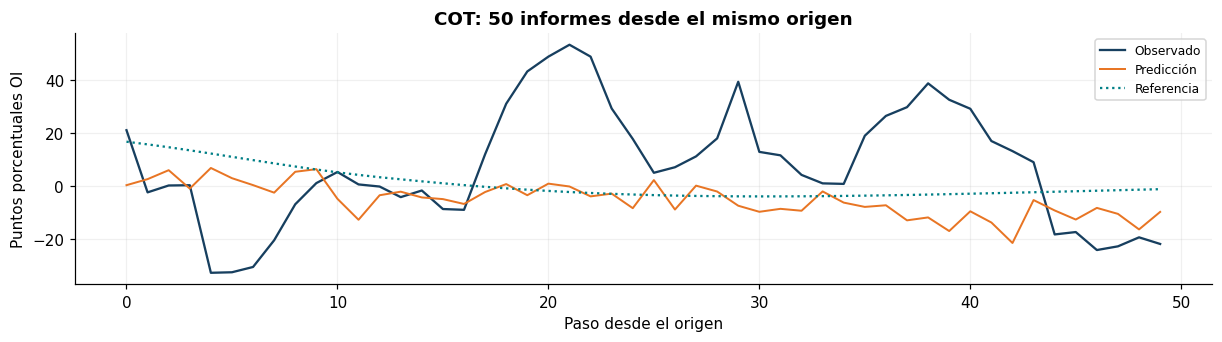

,Método,n_origenes,rmse,mae,r2
0,Directo,1,26.64798,21.17607,-0.46536
1,Recursivo,1,25.91172,21.39749,-0.38550
2,Persistencia,1,35.75911,30.56800,-1.63869


In [74]:
b_cot=preparar('COT_un_paso',neto,100,unidad='Puntos porcentuales OI')
referencias(b_cot)
r_cot,p_cot,_=entrenar(b_cot,'LSTM',recurrente=True,neuronas=(24,24),epocas=40,lote=32)
ii=np.flatnonzero(b_cot['mascaras']['Prueba'])
grafico_trayectoria(b_cot['y'][ii,0],p_cot[ii,0],'COT: pronósticos de un paso','Puntos porcentuales OI')
b_cd=preparar('COT_directo_50',neto,100,50,unidad='Puntos porcentuales OI')
referencias(b_cd)
_,p_cd,_=entrenar(b_cd,'LSTM directa',recurrente=True,neuronas=(24,24),epocas=40,lote=32)
k=int(np.flatnonzero(b_cd['mascaras']['Prueba'])[0]);origen=int(b_cd['t'][k])
rec_cot=trayectoria(b_cot,r_cot,50,inicio=origen)
real_cot=b_cd['y'][k]
grafico_trayectoria(real_cot,p_cd[k],'COT: 50 informes desde el mismo origen','Puntos porcentuales OI',rec_cot)
tabla_cot_trayectoria=pd.DataFrame([
    {'Método':'Directo','n_origenes':1,**evaluar(real_cot,p_cd[k])},
    {'Método':'Recursivo','n_origenes':1,**evaluar(real_cot,rec_cot)},
    {'Método':'Persistencia','n_origenes':1,**evaluar(real_cot,np.full(50,neto[origen-1]))},
])
display(tabla_cot_trayectoria[['Método','n_origenes','rmse','mae','r2']])

### 4. Integración de variables e indicadores técnicos

Se agregan dos indicadores calculados únicamente con precios ya disponibles: RSI de 5 semanas con suavizado de Wilder y distancia entre precio y media de 5 semanas. Las cotizaciones diarias EUR/USD se agrupan por semana terminada en viernes; se excluye una última semana incompleta.

Se usan los últimos **tres pasos y dos variables por paso**, forma `(ejemplos, 3, 2)`. No se convierten seis variables heterogéneas en seis instantes de una sola serie. Se evita `np.roll`, que puede llevar datos del final de una serie a sus primeras filas. La variable objetivo es la diferencia de precio de la semana siguiente en USD por EUR.

Las variables numéricas se escalan con el ajuste. Las variables categóricas, si se agregaran, necesitarían codificación aprendida también solo en ajuste; no se inventan categorías en este ejemplo. La correlación entre indicadores permite explorar redundancia, pero no sustituye una validación de su aporte.

,RSI t-3,Distancia t-3,RSI t-2,Distancia t-2,RSI t-1,Distancia t-1
0,13.18773,-0.00730,13.67842,-0.00144,11.35238,-0.00340
1,13.67842,-0.00144,11.35238,-0.00340,8.38264,-0.01496
2,11.35238,-0.00340,8.38264,-0.01496,16.13671,-0.00884


,RSI_5,Precio_menos_MA5
RSI_5,1.00000,0.80201
Precio_menos_MA5,0.80201,1.00000


,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,0.01122,0.00868,-0.00437,NaN,49.59016
Cero,0.01121,0.00868,-0.00141,NaN,0.00000


,Capa,Salida,Parámetros
0,LSTM,"(None, 24)",2592
1,Dense,"(None, 24)",600
2,Dense,"(None, 24)",600
3,Dense,"(None, 1)",25


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,0.01707,0.01317,0.00226,0.05016,53.29884
Validación,0.01369,0.01078,0.00128,0.04108,51.53061
Prueba,0.01123,0.00870,-0.00480,-0.00674,49.18033


Épocas: 9 / 40; mejor validación: 2; tiempo: 2.6 s.


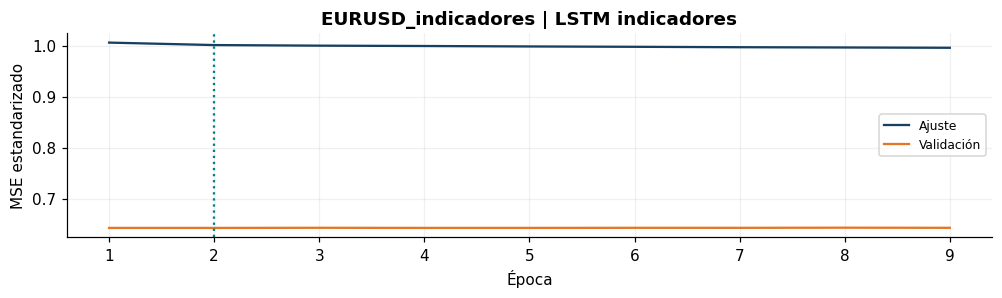

,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,0.01707,0.01316,0.00245,0.04955,52.91074
Validación,0.01373,0.01076,-0.00481,-0.01077,50.00000
Prueba,0.01129,0.00876,-0.01729,-0.12015,46.72131


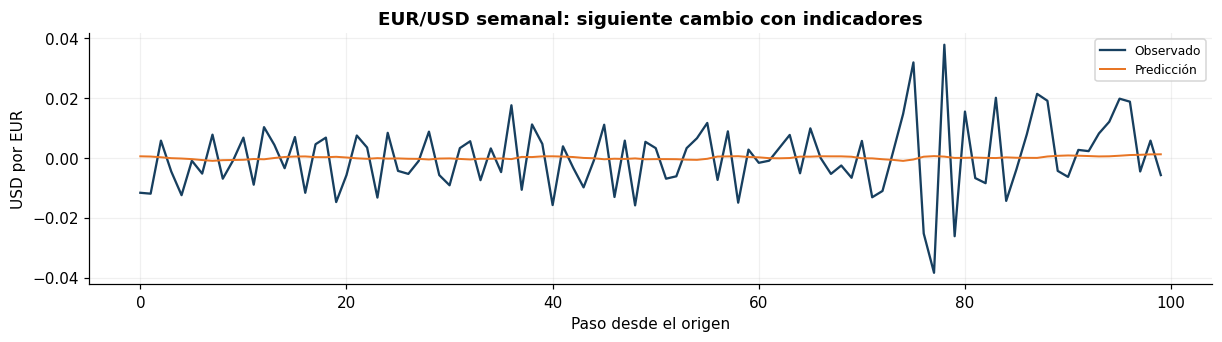

In [75]:
semanal=eur.set_index('fecha')['valor'].resample('W-FRI').last().dropna()
semanal=semanal.loc[semanal.index<=eur['fecha'].max()]
d=semanal.diff()
ganancia=d.clip(lower=0).ewm(alpha=1/5,adjust=False,min_periods=5).mean()
perdida=(-d.clip(upper=0)).ewm(alpha=1/5,adjust=False,min_periods=5).mean()
rsi=100-100/(1+ganancia/perdida)
rsi=rsi.mask((perdida==0)&(ganancia>0),100).mask((perdida==0)&(ganancia==0),50)
f=pd.DataFrame({'RSI_5':rsi,'Precio_menos_MA5':semanal-semanal.rolling(5).mean()}).iloc[1:]
cambio=d.iloc[1:].to_numpy()
X,Y,T=[],[],[]
for k in range(3,len(f)):
    ventana=f.iloc[k-3:k].to_numpy()
    if np.isfinite(ventana).all():X.append(ventana);Y.append([cambio[k]]);T.append(k)
X,Y,T=np.array(X),np.array(Y),np.array(T)
nfit,ntest=int(len(cambio)*.64),int(len(cambio)*.8)
masks={'Ajuste':T<nfit,'Validación':(T>=nfit)&(T<ntest),'Prueba':T>=ntest}
sx=StandardScaler().fit(X[masks['Ajuste']].reshape(-1,2))
mu,sd=float(cambio[:nfit].mean()),float(cambio[:nfit].std())
b_ind=dict(nombre='EURUSD_indicadores',v=cambio,x=X,y=Y,t=T,L=3,H=1,
           mu=mu,sd=sd,unidad='USD por EUR',cambio=True,mascaras=masks,
           xs=sx.transform(X.reshape(-1,2)).reshape(X.shape).astype('float32'),
           ys=((Y-mu)/sd).astype('float32'))
casos[b_ind['nombre']]=b_ind
assert X.shape[1:]==(3,2)
display(pd.DataFrame(X[:3].reshape(3,6),columns=['RSI t-3','Distancia t-3','RSI t-2','Distancia t-2','RSI t-1','Distancia t-1']))
display(f.iloc[:nfit].corr())
referencias(b_ind)
r_ind,p_ind,_=entrenar(b_ind,'LSTM indicadores',recurrente=True,neuronas=(24,24,24),epocas=40,lote=64)
retardos=np.array([cambio[t-3:t] for t in T])
with threadpool_limits(limits=2):
    ar=LinearRegression().fit(retardos[masks['Ajuste']],Y[masks['Ajuste']])
    p_ar=ar.predict(retardos)
display(registrar(b_ind,'AR 3 rezagos',p_ar).round(5))
jj=np.flatnonzero(masks['Prueba'])
grafico_trayectoria(Y[jj[:100],0],p_ind[jj[:100],0],
                   'EUR/USD semanal: siguiente cambio con indicadores','USD por EUR')

### 5. Predicción de variabilidad del precio de Bitcoin

El archivo del libro contiene una columna `Price`, sin fechas ni metadatos del mercado de origen. Se conserva su secuencia completa y se expresan los precios en USD según el contexto del material. Las escalas lineal y logarítmica permiten inspeccionar cambios de magnitud; ninguna crea capacidad predictiva por sí sola.

Se calcula la **desviación estándar poblacional de los últimos 10 precios**, en USD (`ddof=0`), siguiendo la familia de variable del capítulo. No se la presenta como volatilidad de rendimientos ni como volatilidad anualizada. Después se pronostican sus diferencias, con 60 rezagos y una salida de 10 pasos. El horizonte de 10 se define explícitamente porque el fragmento de código del PDF lo utiliza sin asignarlo.

Se prueba ADF en el tramo de ajuste para los niveles de esa medida y sus diferencias. La transformación queda fijada de antemano; no se elige mirando los resultados de prueba.

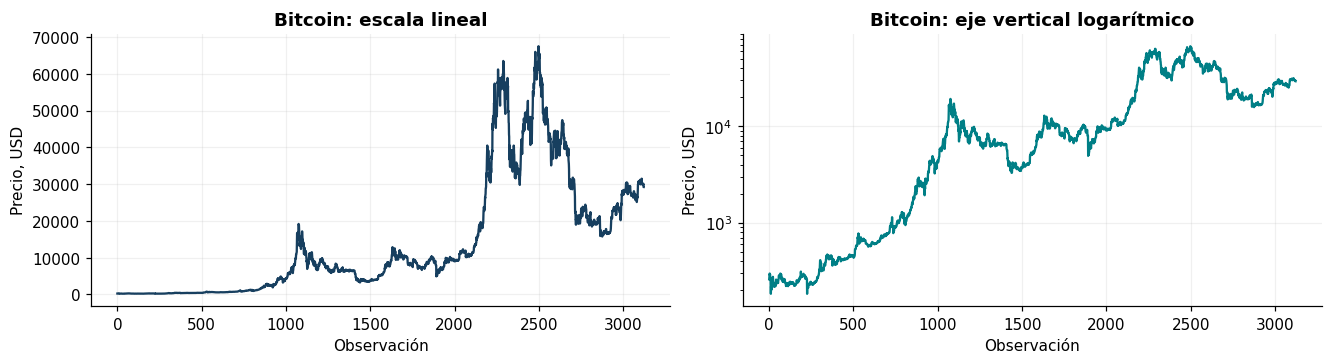

,Serie,p_ADF_ajuste
0,Desviación de precios 10,7.63822e-03
1,Diferencias de desviación,4.51888e-30


,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,227.80196,137.56519,-0.00017,0.01893,47.09677
Cero,227.80149,137.56166,-0.00016,NaN,0.00000


,Capa,Salida,Parámetros
0,LSTM,"(None, 24)",2496
1,Dense,"(None, 24)",600
2,Dense,"(None, 24)",600
3,Dense,"(None, 24)",600
4,Dense,"(None, 10)",250


,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,57.30956,26.62875,0.15341,0.39208,57.71191
Validación,284.63618,186.43839,0.09299,0.31794,59.71370
Prueba,208.37019,128.98640,0.16319,0.42225,58.54839


Épocas: 32 / 35; mejor validación: 25; tiempo: 9.4 s.


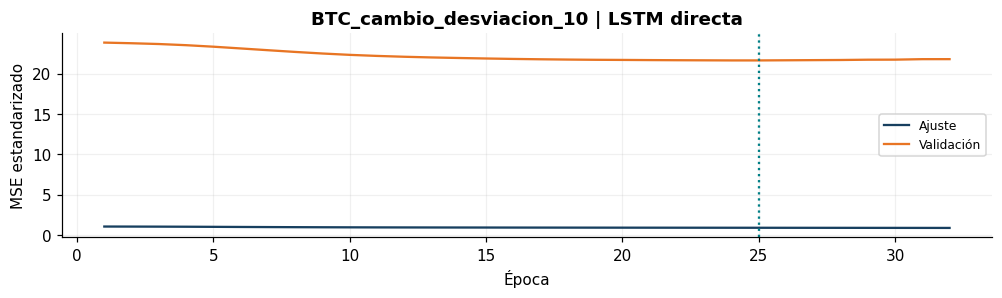

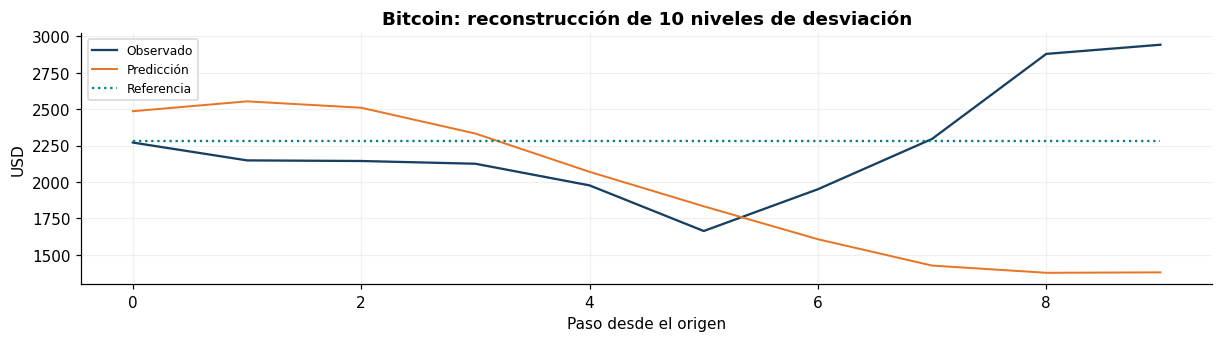

,Paso,Desviación observada,Desviación predicha
0,1,2270.37105,2485.55765
1,2,2147.85619,2553.22519
2,3,2143.66391,2509.48813
3,4,2124.86449,2332.25852
4,5,1976.25926,2069.32080
5,6,1662.86069,1832.75559
6,7,1949.81836,1606.40433
7,8,2295.39482,1425.60105
8,9,2879.05470,1376.02182
9,10,2942.02749,1378.90915


Niveles predichos negativos, sin recorte artificial: 0


In [76]:
fig,axes=plt.subplots(1,2,figsize=(12,3.2),layout='constrained')
axes[0].plot(btc,color='#173F5F');axes[0].set(title='Bitcoin: escala lineal',xlabel='Observación',ylabel='Precio, USD')
axes[1].semilogy(btc,color='#007F86');axes[1].set(title='Bitcoin: eje vertical logarítmico',xlabel='Observación',ylabel='Precio, USD')
plt.show()
vol=pd.Series(btc).rolling(10).std(ddof=0).dropna().to_numpy()
dvol=np.diff(vol)
display(pd.DataFrame([
    {'Serie':'Desviación de precios 10','p_ADF_ajuste':p_adf(vol[:int(len(vol)*.64)])},
    {'Serie':'Diferencias de desviación','p_ADF_ajuste':p_adf(dvol[:int(len(dvol)*.64)])},
]))
b_vol=preparar('BTC_cambio_desviacion_10',dvol,60,10,unidad='Cambio de desviación, USD',cambio=True)
referencias(b_vol)
r_vol,p_vol,_=entrenar(b_vol,'LSTM directa',recurrente=True,neuronas=(24,24,24,24),epocas=35,lote=128)
k=int(np.flatnonzero(b_vol['mascaras']['Prueba'])[0]);t=int(b_vol['t'][k])
# dvol[t] = vol[t+1]-vol[t]; el último nivel conocido es vol[t].
nivel_pred=vol[t]+np.cumsum(p_vol[k])
nivel_real=vol[t+1:t+11]
assert len(nivel_real)==10
grafico_trayectoria(nivel_real,nivel_pred,'Bitcoin: reconstrucción de 10 niveles de desviación','USD',np.full(10,vol[t]))
display(pd.DataFrame({'Paso':np.arange(1,11),'Desviación observada':nivel_real,'Desviación predicha':nivel_pred}))
print('Niveles predichos negativos, sin recorte artificial:',int((nivel_pred<0).sum()))

### 6. Visualización del entrenamiento en tiempo real

Una callback guarda predicciones sobre los primeros 60 ejemplos de **ajuste** al terminar cada época. Actualiza el gráfico durante el entrenamiento y conserva una animación para revisarlo después. La validación se usa para parada temprana y la prueba se evalúa al terminar.

Los fotogramas muestran la red tal como estaba en cada época, antes de recuperar los mejores pesos. Las métricas finales se calculan con esos mejores pesos. Un ajuste visualmente bueno del pasado no demuestra generalización; una predicción dentro de muestra no es por sí misma una fuga de futuro, pero sí una evaluación optimista del rendimiento.

,rmse,mae,r2,correlacion,acierto_pct
Media de ajuste,2.05965,1.53730,-0.00030,NaN,49.72376
Cero,2.05939,1.53702,-0.00006,NaN,2.20994


,Capa,Salida,Parámetros
0,LSTM,"(None, 24)",2496
1,Dense,"(None, 24)",600
2,Dense,"(None, 24)",600
3,Dense,"(None, 24)",600
4,Dense,"(None, 1)",25


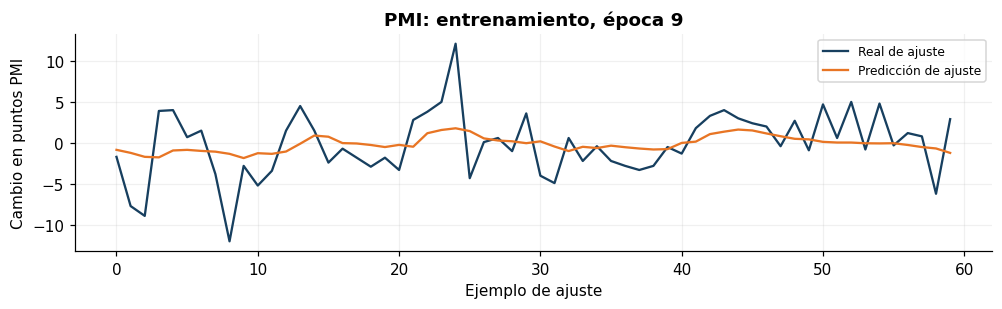

,rmse,mae,r2,correlacion,acierto_pct
particion,,,,,
Ajuste,2.79945,2.12425,0.03109,0.23489,55.00911
Validación,1.68401,1.27854,0.00287,0.07242,55.17241
Prueba,2.06293,1.54657,-0.00350,0.03297,54.14365


Épocas: 9 / 30; mejor validación: 2; tiempo: 4.5 s.


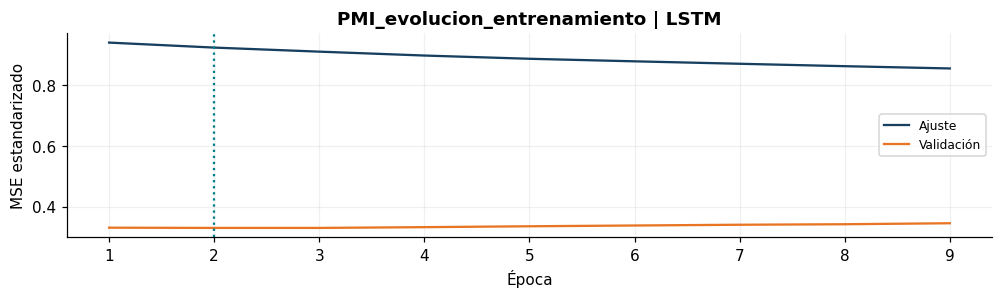

In [77]:
b_pmi=preparar('PMI_evolucion_entrenamiento',np.diff(pmi),30,unidad='Cambio en puntos PMI',cambio=True)
referencias(b_pmi)
class EvolucionEntrenamiento(keras.callbacks.Callback):
    def __init__(self,b):
        super().__init__();self.b=b;self.fotogramas=[];self.epocas=[]
        self.x=b['xs'][b['mascaras']['Ajuste']][:60,...,None]
        self.real=b['y'][b['mascaras']['Ajuste']][:60,0]
        self.fig,self.ax=plt.subplots(figsize=(9,2.7),layout='constrained')
        self.manejador=None
    def dibujar(self,epoca,p):
        self.ax.clear();self.ax.plot(self.real,color='#173F5F',label='Real de ajuste')
        self.ax.plot(p,color='#E87524',label='Predicción de ajuste')
        self.ax.set(title=f'PMI: entrenamiento, época {epoca}',xlabel='Ejemplo de ajuste',ylabel='Cambio en puntos PMI')
        self.ax.legend(fontsize=8)
        if self.manejador is None:self.manejador=display(self.fig,display_id=True)
        else:self.manejador.update(self.fig)
    def on_epoch_end(self,epoch,logs=None):
        p=self.model(self.x,training=False).numpy().ravel()*self.b['sd']+self.b['mu']
        self.fotogramas.append(p.copy());self.epocas.append(epoch+1)
        if epoch==0 or (epoch+1)%5==0:self.dibujar(epoch+1,p)
    def on_train_end(self,logs=None):
        self.dibujar(self.epocas[-1],self.fotogramas[-1]);plt.close(self.fig)
evolucion=EvolucionEntrenamiento(b_pmi)
r_pmi,p_pmi,h_pmi=entrenar(b_pmi,'LSTM',recurrente=True,neuronas=(24,24,24,24),
                         epocas=30,lote=32,callbacks_adicionales=[evolucion])

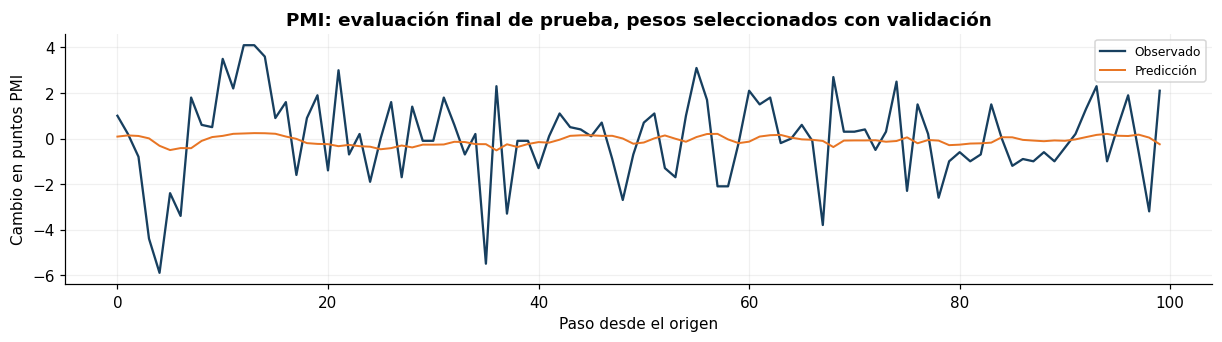

In [78]:
from matplotlib.animation import FuncAnimation
seleccion=sorted(set([0]+list(range(4,len(evolucion.epocas),5))+[len(evolucion.epocas)-1]))
fig,ax=plt.subplots(figsize=(9,2.7),layout='constrained')
ax.plot(evolucion.real,color='#173F5F',label='Real de ajuste')
linea,=ax.plot(evolucion.fotogramas[seleccion[0]],color='#E87524',label='Predicción de ajuste')
todos=np.r_[evolucion.real,np.concatenate(evolucion.fotogramas)]
ax.set_ylim(todos.min()-.2,todos.max()+.2)
ax.set(xlabel='Ejemplo de ajuste',ylabel='Cambio en puntos PMI');ax.legend(fontsize=8)
def actualizar_animacion(frame):
    k=seleccion[frame];linea.set_ydata(evolucion.fotogramas[k])
    ax.set_title(f'PMI: evolución real del entrenamiento, época {evolucion.epocas[k]}')
    return linea,
animacion=FuncAnimation(fig,actualizar_animacion,frames=len(seleccion),interval=600,repeat=False)
display(HTML(animacion.to_jshtml(default_mode='once')));plt.close(fig)
jj=np.flatnonzero(b_pmi['mascaras']['Prueba'])
grafico_trayectoria(b_pmi['y'][jj[:100],0],p_pmi[jj[:100],0],
                   'PMI: evaluación final de prueba, pesos seleccionados con validación','Cambio en puntos PMI')

#### Arquitectura y diagnóstico de predicciones constantes

La arquitectura se representa con sus formas reales y número de parámetros. Una salida casi constante puede deberse a subajuste, regularización excesiva, problemas de escala o falta de señal en las entradas. Se compara su dispersión con la del objetivo, sin asegurar que variar hiperparámetros vaya a resolver la falta de capacidad predictiva.

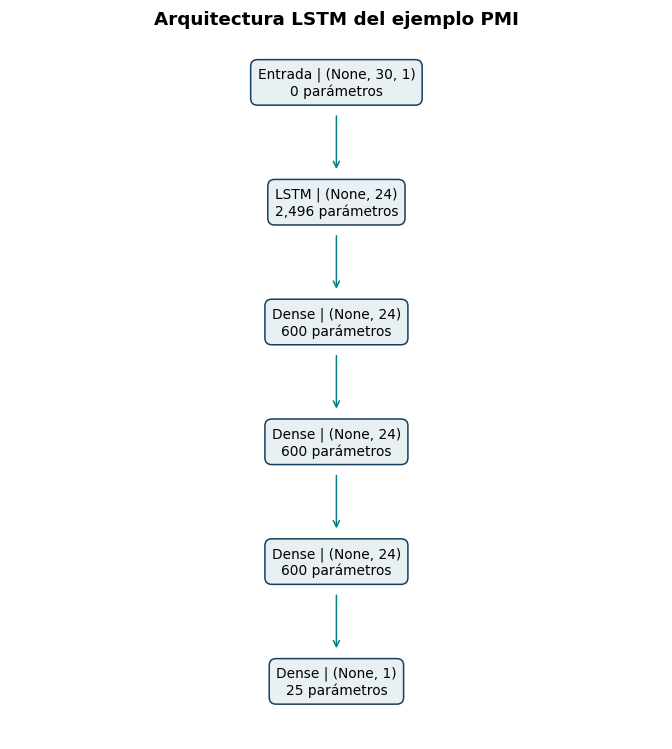

,Caso,SD real prueba,SD predicha prueba
0,COT_un_paso,27.91125,18.31671
1,EURUSD_indicadores,0.01120,0.00062
2,BTC_cambio_desviacion_10,228.46553,73.17973
3,PMI_evolucion_entrenamiento,2.05934,0.17839


In [79]:
bloques=[('Entrada',str(r_pmi.input_shape),0)]+[(type(c).__name__,str(tuple(c.output.shape)),c.count_params()) for c in r_pmi.layers]
fig,ax=plt.subplots(figsize=(6,6.7),layout='constrained');ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
ys=np.linspace(.93,.08,len(bloques))
for k,((nombre,forma,param),yy) in enumerate(zip(bloques,ys)):
    ax.text(.5,yy,f'{nombre} | {forma}\n{param:,} parámetros',ha='center',va='center',fontsize=9,
            bbox=dict(boxstyle='round,pad=.5',facecolor='#E8F0F4',edgecolor='#173F5F'))
    if k<len(ys)-1:ax.annotate('',xy=(.5,ys[k+1]+.043),xytext=(.5,yy-.043),arrowprops=dict(arrowstyle='->',color='#007F86'))
ax.set_title('Arquitectura LSTM del ejemplo PMI');plt.show()
display(pd.DataFrame([
    {'Caso':b['nombre'],'SD real prueba':float(b['y'][np.flatnonzero(b['mascaras']['Prueba'])].std()),
     'SD predicha prueba':float(p[np.flatnonzero(b['mascaras']['Prueba'])].std())}
    for b,p in [(b_cot,p_cot),(b_ind,p_ind),(b_vol,p_vol),(b_pmi,p_pmi)]
]))

### 7. Consultas SQL y conclusiones

Los casos se almacenan por separado porque predicen variables y unidades distintas. El seguimiento de una red y la animación se refieren solo a entrenamiento. Las predicciones de prueba quedan congeladas después de la selección por validación.

In [80]:
metricas11,conexion11=exportar(11)
carpeta11=Path.cwd()/'salidas_capitulo_11'
cot.to_csv(carpeta11/'cot_original_y_calculado.csv',index=False)
tabla_cot_trayectoria.to_csv(carpeta11/'comparacion_trayectorias_cot.csv',index=False)
with sqlite3.connect(carpeta11/'capitulo_11.sqlite') as db:
    cot.to_sql('cot_fuente',db,index=False,if_exists='replace')
    conjunto.to_sql('cot_cad_descriptivo',db,index=False,if_exists='replace')
    f.reset_index().to_sql('indicadores_semanales',db,index=False,if_exists='replace')
    pd.DataFrame({'Precio':btc,'Desviacion_10':np.r_[np.full(9,np.nan),vol]}).to_sql(
        'bitcoin_fuente',db,index=True,index_label='indice',if_exists='replace')
p11=metricas11.query("particion=='Prueba'")
mejores=p11.loc[p11.groupby('caso')['rmse'].idxmin(),['caso','modelo','rmse']]
display(mejores)
display(Markdown(textwrap.dedent(f"""
- El COT neto calculado coincide con las **449 observaciones** del archivo histórico del autor. Se conservaron las categorías TFF, sus unidades y las fechas reales del informe.
- La correlación descriptiva entre COT neto y CADUSD en los últimos 200 informes fue **{correlacion_200:.3f}**. No se interpretó como una prueba de anticipación ni se utilizó el informe antes de su publicación.
- Se implementaron pronósticos COT de un paso, de salida directa y recursivos. La comparación de trayectorias de 50 pasos utiliza un origen común y tiene una muestra limitada.
- Los indicadores EUR/USD se organizaron en **tres pasos y dos variables**, sin convertir columnas distintas en instantes ficticios ni introducir datos del final al principio.
- En Bitcoin se separaron precio, desviación móvil de precios y diferencias de esa desviación. La reconstrucción de niveles usa solo el nivel del origen y las predicciones futuras.
- La callback registró **{len(evolucion.epocas)} épocas** del entrenamiento PMI; la animación conserva instantáneas de ese proceso. El desempeño final se calculó con los pesos elegidos mediante validación.
- Las consultas SQL reprodujeron el MAE y verificaron integridad. Los resultados del cuadro se interpretan por tarea; no hay un ganador global entre unidades diferentes.
""")))

,caso,modelo,rmse,acierto_pct
0,BTC_cambio_desviacion_10,LSTM directa,208.37019,58.55
1,BTC_cambio_desviacion_10,Cero,227.80149,0.00
2,BTC_cambio_desviacion_10,Media de ajuste,227.80196,47.10
3,COT_directo_50,Media de ajuste,20.90304,88.00
4,COT_directo_50,LSTM directa,26.64798,88.00
5,COT_directo_50,Persistencia,35.75910,0.00
6,COT_un_paso,Persistencia,11.48645,0.00
7,COT_un_paso,LSTM,17.45913,53.33
8,COT_un_paso,Media de ajuste,29.95516,60.00
9,EURUSD_indicadores,Cero,0.01121,0.00


Archivos creados en salidas_capitulo_11 | Integridad y verificación SQL del MAE correctas.


,caso,modelo,rmse
38,BTC_cambio_desviacion_10,LSTM directa,208.37019
11,COT_directo_50,Media de ajuste,20.90304
5,COT_un_paso,Persistencia,11.48645
23,EURUSD_indicadores,Cero,0.01121
44,PMI_evolucion_entrenamiento,Cero,2.05939



- El COT neto calculado coincide con las **449 observaciones** del archivo histórico del autor. Se conservaron las categorías TFF, sus unidades y las fechas reales del informe.
- La correlación descriptiva entre COT neto y CADUSD en los últimos 200 informes fue **0.693**. No se interpretó como una prueba de anticipación ni se utilizó el informe antes de su publicación.
- Se implementaron pronósticos COT de un paso, de salida directa y recursivos. La comparación de trayectorias de 50 pasos utiliza un origen común y tiene una muestra limitada.
- Los indicadores EUR/USD se organizaron en **tres pasos y dos variables**, sin convertir columnas distintas en instantes ficticios ni introducir datos del final al principio.
- En Bitcoin se separaron precio, desviación móvil de precios y diferencias de esa desviación. La reconstrucción de niveles usa solo el nivel del origen y las predicciones futuras.
- La callback registró **9 épocas** del entrenamiento PMI; la animación conserva instantáneas de ese proceso. El desempeño final se calculó con los pesos elegidos mediante validación.
- Las consultas SQL reprodujeron el MAE y verificaron integridad. Los resultados del cuadro se interpretan por tarea; no hay un ganador global entre unidades diferentes.


#### Adaptaciones, límites y referencias

Las redes usan 24 unidades recurrentes y entre una y tres capas densas pequeñas, en lugar de algunas configuraciones de 100 a 500 unidades del PDF. Se reducen las épocas máximas, se valida cronológicamente y se purgan etiquetas que cruzan los cortes. Los datos sin fecha no se convierten a un calendario supuesto. La escala de indicadores se ajusta solo con entrenamiento.

La prueba ADF tiene límites y no asegura predictibilidad. Los datos COT aquí son una fotografía histórica, sin reconstrucción completa de revisiones y fechas efectivas de difusión; por eso no se presenta una estrategia de ejecución basada en ellos. Los datos de Bitcoin no documentan mercado ni horario. Una desviación de precios puede depender del nivel del activo y no sustituye una estimación de volatilidad de retornos. Una sola semilla no mide robustez.

Como trabajo futuro se propone ampliar la trazabilidad de publicación y cotizaciones, contrastar más semillas y periodos nuevos, elegir hiperparámetros dentro del desarrollo y confirmar la utilidad frente a referencias simples.

- Kaabar, S. (2024). *Deep Learning for Finance*. O'Reilly. Capítulo 11, PDF proporcionado de 56 páginas.
- Repositorio oficial: https://github.com/sofienkaabar/deep-learning-for-finance
- CFTC, informes y calendario: https://www.cftc.gov/MarketReports/CommitmentsofTraders/index.htm y https://www.cftc.gov/MarketReports/CommitmentsofTraders/ReleaseSchedule/index.htm
- FRED: https://fred.stlouisfed.org/series/DEXCAUS y https://fred.stlouisfed.org/series/DEXUSEU
- Callbacks Keras: https://keras.io/api/callbacks/
- Animación Matplotlib: https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.FuncAnimation.html

Las explicaciones y el código son una adaptación didáctica. Los resultados, tablas y fotogramas provienen de la ejecución de las celdas incluidas.

In [81]:
# Registrar las versiones de cada sección sin modificar sus variables.
P_VERSIONES['capitulo_11'] = (dict(zip(versiones['Componente'],versiones['Versión']))
    if isinstance(versiones,pd.DataFrame) else dict(versiones))

## 9. Integración de resultados con SQLite

Las siguientes celdas reúnen las bases producidas por los cinco capítulos. Se crea una nueva base para la entrega final y se conservan las bases específicas. La carga utiliza parámetros SQL y una transacción; no concatena los valores de los datos dentro de las sentencias.

El DDL implementa el diseño presentado al inicio. La información se relaciona mediante `JOIN`, se resume con `GROUP BY` y se consulta mediante una vista. Las curvas de las redes supervisadas se incorporan a `aprendizaje`; las recompensas y pérdidas TD de Double DQN conservan su significado propio en la tabla `episodios` de su base de capítulo.

In [82]:
import sqlite3, json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Cada capítulo se conserva como un experimento. La integración no reescala
# sus resultados ni mezcla sus variables objetivo.
P_RUTAS = {
    7: Path('salidas_capitulo7/eurusd_capitulo7.sqlite'),
    8: Path('salidas_capitulo8/sp500_capitulo8.sqlite'),
    9: Path('salidas_capitulo_9/capitulo_9.sqlite'),
    10: Path('salidas_capitulo_10/capitulo_10.sqlite'),
    11: Path('salidas_capitulo_11/capitulo_11.sqlite'),
}
assert all(p.is_file() for p in P_RUTAS.values()), 'Ejecuta primero los cinco capítulos.'
P_DB = sqlite3.connect(':memory:')
P_DB.execute('PRAGMA foreign_keys=ON')
P_DDL = '''
CREATE TABLE capitulos (
    capitulo_id INTEGER PRIMARY KEY CHECK(capitulo_id BETWEEN 7 AND 11),
    titulo TEXT NOT NULL
);
CREATE TABLE fuentes (
    fuente_id TEXT PRIMARY KEY,
    nombre TEXT NOT NULL,
    tipo TEXT NOT NULL CHECK(tipo IN ('Real','Simulada')),
    url TEXT,
    fecha_consulta TEXT,
    sha256_original TEXT,
    sha256_csv TEXT,
    nota TEXT NOT NULL
);
CREATE TABLE casos (
    caso_id TEXT PRIMARY KEY,
    capitulo_id INTEGER NOT NULL REFERENCES capitulos(capitulo_id),
    nombre TEXT NOT NULL,
    unidad TEXT NOT NULL,
    rezagos_maximos INTEGER NOT NULL CHECK(rezagos_maximos>0),
    horizontes INTEGER NOT NULL CHECK(horizontes>0),
    objetivo TEXT NOT NULL,
    UNIQUE(capitulo_id,nombre)
);
CREATE TABLE caso_fuente (
    caso_id TEXT NOT NULL REFERENCES casos(caso_id),
    fuente_id TEXT NOT NULL REFERENCES fuentes(fuente_id),
    papel TEXT NOT NULL,
    PRIMARY KEY(caso_id,fuente_id)
);
CREATE TABLE observaciones (
    caso_id TEXT NOT NULL REFERENCES casos(caso_id),
    indice INTEGER NOT NULL CHECK(indice>=0),
    fecha TEXT,
    valor REAL NOT NULL,
    PRIMARY KEY(caso_id,indice),
    UNIQUE(caso_id,fecha)
);
CREATE TABLE modelos (
    modelo_id INTEGER PRIMARY KEY,
    caso_id TEXT NOT NULL REFERENCES casos(caso_id),
    nombre TEXT NOT NULL,
    familia TEXT NOT NULL,
    rezagos INTEGER NOT NULL CHECK(rezagos>0),
    configuracion_json TEXT NOT NULL,
    UNIQUE(caso_id,nombre)
);
CREATE TABLE metricas (
    modelo_id INTEGER NOT NULL REFERENCES modelos(modelo_id),
    particion TEXT NOT NULL CHECK(particion IN ('Entrenamiento','Ajuste','Validación','Prueba')),
    n INTEGER NOT NULL CHECK(n>0),
    mae REAL NOT NULL CHECK(mae>=0),
    rmse REAL NOT NULL CHECK(rmse>=0),
    r2 REAL,
    correlacion REAL,
    acierto_pct REAL NOT NULL CHECK(acierto_pct BETWEEN 0 AND 100),
    PRIMARY KEY(modelo_id,particion)
);
CREATE TABLE predicciones (
    modelo_id INTEGER NOT NULL REFERENCES modelos(modelo_id),
    origen TEXT NOT NULL,
    objetivo TEXT NOT NULL,
    horizonte INTEGER NOT NULL CHECK(horizonte>0),
    real REAL NOT NULL,
    predicho REAL NOT NULL,
    PRIMARY KEY(modelo_id,origen,horizonte)
);
CREATE TABLE aprendizaje (
    modelo_id INTEGER NOT NULL REFERENCES modelos(modelo_id),
    epoca INTEGER NOT NULL CHECK(epoca>0),
    loss REAL NOT NULL,
    val_loss REAL NOT NULL,
    PRIMARY KEY(modelo_id,epoca)
);
CREATE TABLE ejecucion (
    ejecucion_id INTEGER PRIMARY KEY,
    fecha TEXT NOT NULL,
    alumno TEXT NOT NULL,
    matricula TEXT NOT NULL,
    semilla INTEGER NOT NULL,
    versiones_json TEXT NOT NULL,
    alcance TEXT NOT NULL
);
CREATE INDEX idx_predicciones_objetivo ON predicciones(objetivo);
CREATE INDEX idx_metricas_particion ON metricas(particion,rmse);
CREATE INDEX idx_casos_capitulo ON casos(capitulo_id);
CREATE VIEW resultados_prueba AS
SELECT c.capitulo_id,c.caso_id,c.nombre AS caso,c.unidad,c.horizontes,
       m.modelo_id,m.nombre AS modelo,m.familia,m.rezagos,
       e.n,e.mae,e.rmse,e.r2,e.correlacion,e.acierto_pct
FROM casos c JOIN modelos m USING(caso_id)
JOIN metricas e USING(modelo_id) WHERE e.particion='Prueba';
'''
P_DB.executescript(P_DDL)

P_OBJETIVOS = {
    'EURUSD_cambio': ('euro','Diferencia entre cotizaciones consecutivas; un paso con pasado observado.'),
    'SP500_cambio': ('sp500','Diferencia entre cierres consecutivos; un paso con pasado observado.'),
    'EURUSD_umbral': ('euro','Diferencia diaria; los filtros se estudian en la sección del capítulo 9.'),
    'Temperatura_recursiva_1paso': ('temperatura','Nivel de temperatura; evaluación de un paso y trayectoria recursiva separada.'),
    'PMI_recursivo_1paso': ('pmi','Nivel PMI; evaluación de un paso y trayectoria recursiva separada.'),
    'PMI_directo_18': ('pmi','Niveles PMI; salida directa de 18 pasos, bloques de prueba sin objetivos solapados.'),
    'PMI_capacidad_minima_18': ('pmi','Niveles PMI; salida de 18 pasos con red de capacidad reducida.'),
    'Temperatura_directa_500': ('temperatura','Niveles de temperatura; salida directa de 500 pasos.'),
    'Autocorrelacion_SP500': ('sp500','Autocorrelación de orden 1 en una ventana móvil de 20 precios.'),
    'Seno_DDQN': ('seno','Nivel de onda simulada; siguiente observación con pasado real de la simulación.'),
    'COT_un_paso': ('cot','Posicionamiento neto TFF; un informe adelante.'),
    'COT_directo_50': ('cot','Posicionamiento neto TFF; salida directa de 50 informes.'),
    'EURUSD_indicadores': ('euro','Cambio semanal; tres pasos con RSI y distancia a media como entradas.'),
    'BTC_cambio_desviacion_10': ('bitcoin','Cambio en desviación poblacional móvil de diez precios, no volatilidad de retornos.'),
    'PMI_evolucion_entrenamiento': ('pmi','Diferencia de PMI; las instantáneas de aprendizaje usan solo ajuste.'),
}

def p_familia(nombre):
    if nombre in ('Referencia: media','Media de ajuste','Persistencia','Cero'):
        return 'Referencia simple'
    if nombre.startswith(('A:','B:','C:','D:','E:')):
        return 'Double DQN'
    if any(s in nombre for s in ('MLP','LSTM','CNN','RNN')):
        return 'Red neuronal'
    return 'Aprendizaje clásico'

def p_registrar_modelo(src, capitulo, caso_original, caso_id, nombre, rezagos):
    config = {'semilla':123,'capitulo':capitulo,'caso':caso_original}
    if capitulo in (7,8):
        row = src.execute('SELECT * FROM modelos WHERE modelo_id=?',(nombre,)).fetchone()
        config.update(dict(row))
        rezagos = row['rezagos']
    elif capitulo == 10 and nombre.startswith(('A:','B:','C:','D:','E:')):
        rezagos = 8 if nombre.startswith('E:') else 5
        config.update({'rezagos':rezagos,'acciones':41,'gamma':0.9,
                       'episodios':1 if nombre.startswith(('A:','B:')) else 10})
    elif capitulo in (9,11):
        # La arquitectura completa está en las celdas; no se inventan
        # parámetros que las bases de los avances no registraban.
        config['arquitectura'] = 'Consultar la celda del caso en este cuaderno.'
    cur = P_DB.execute('INSERT INTO modelos(caso_id,nombre,familia,rezagos,configuracion_json) VALUES(?,?,?,?,?)',
                       (caso_id,nombre,p_familia(nombre),int(rezagos),json.dumps(config,ensure_ascii=False)))
    mid = cur.lastrowid
    if capitulo in (7,8):
        mets = src.execute('SELECT * FROM metricas WHERE modelo_id=?',(nombre,)).fetchall()
        pred = src.execute('SELECT * FROM predicciones WHERE modelo_id=?',(nombre,)).fetchall()
    else:
        mets = src.execute('SELECT * FROM metricas WHERE caso=? AND modelo=?',(caso_original,nombre)).fetchall()
        pred = src.execute('SELECT * FROM predicciones WHERE caso=? AND modelo=?',(caso_original,nombre)).fetchall()
    for row in mets:
        r=dict(row)
        P_DB.execute('INSERT INTO metricas VALUES(?,?,?,?,?,?,?,?)',
                     (mid,r['particion'],r['n'],r['mae'],r['rmse'],r.get('r2'),r['correlacion'],r['acierto_pct']))
    if capitulo in (7,8):
        rows=[(mid,r['fecha_origen'],r['fecha_objetivo'],1,r['valor_real'],r['valor_predicho']) for r in pred]
    else:
        rows=[(mid,str(r['origen']),str(r['origen']+r['horizonte']),r['horizonte'],r['real'],r['predicho']) for r in pred]
    P_DB.executemany('INSERT INTO predicciones VALUES(?,?,?,?,?,?)',rows)
    if capitulo==8:
        hist=src.execute('SELECT epoca,loss,val_loss FROM historial_epocas WHERE modelo_id=?',(nombre,)).fetchall()
    elif capitulo in (9,10,11):
        hist=src.execute('SELECT epoca,loss,val_loss FROM aprendizaje WHERE caso=? AND modelo=?',(caso_original,nombre)).fetchall()
    else:
        hist=[]
    P_DB.executemany('INSERT INTO aprendizaje VALUES(?,?,?,?)',[(mid,*r) for r in hist])

with P_DB:
    P_DB.executemany('INSERT INTO capitulos VALUES(?,?)',[(7,'Aprendizaje automático'),
        (8,'Redes neuronales'),(9,'Validación y pronósticos multiperíodo'),
        (10,'Aprendizaje por refuerzo'),(11,'Aplicaciones avanzadas')])
    for fid,meta in P_MANIFIESTO.items():
        P_DB.execute('INSERT INTO fuentes VALUES(?,?,?,?,?,?,?,?)',
                     (fid,meta['nombre'],meta['tipo'],meta.get('fuente'),meta.get('consulta'),
                      meta.get('sha256_original'),meta.get('sha256_csv'),meta['nota']))
    for ch,path in P_RUTAS.items():
        with sqlite3.connect(path) as src:
            src.row_factory=sqlite3.Row
            if ch in (7,8):
                specs=[{'caso':'EURUSD_cambio' if ch==7 else 'SP500_cambio',
                        'unidad':'USD por EUR' if ch==7 else 'Puntos S&P 500',
                        'rezagos':500 if ch==7 else 100,'horizontes':1}]
            else:
                specs=[dict(r) for r in src.execute('SELECT * FROM casos')]
            for spec in specs:
                name=spec['caso'];cid=f'C{ch}_{name}'
                fid,objetivo=P_OBJETIVOS[name]
                P_DB.execute('INSERT INTO casos VALUES(?,?,?,?,?,?,?)',
                             (cid,ch,name,spec['unidad'],spec['rezagos'],spec['horizontes'],objetivo))
                P_DB.execute('INSERT INTO caso_fuente VALUES(?,?,?)',(cid,fid,'Serie utilizada para modelar'))
                if name=='COT_un_paso':
                    P_DB.execute('INSERT INTO caso_fuente VALUES(?,?,?)',
                                 (cid,'cad','Comparación descriptiva; no es entrada del pronóstico COT'))
                if ch in (7,8):
                    raw=pd.read_sql_query('SELECT fecha,valor FROM cotizaciones WHERE valor IS NOT NULL ORDER BY fecha',src)
                    raw['cambio']=raw['valor'].diff()
                    P_DB.executemany('INSERT INTO observaciones VALUES(?,?,?,?)',
                        [(cid,i,r.fecha,float(r.cambio)) for i,r in enumerate(raw.iloc[1:].itertuples(index=False))])
                    names=[r[0] for r in src.execute('SELECT modelo_id FROM modelos ORDER BY modelo_id')]
                else:
                    P_DB.executemany('INSERT INTO observaciones VALUES(?,?,?,?)',
                        [(cid,r['indice'],None,r['valor']) for r in src.execute('SELECT indice,valor FROM datos WHERE caso=?',(name,))])
                    names=[r[0] for r in src.execute('SELECT DISTINCT modelo FROM metricas WHERE caso=? ORDER BY modelo',(name,))]
                for name_model in names:
                    p_registrar_modelo(src,ch,name,cid,name_model,spec['rezagos'])
    P_DB.execute('INSERT INTO ejecucion VALUES(?,?,?,?,?,?,?)',
                 (1,P_FECHA,'Juan Fernando Castrejón Villa','81901',123,
                  json.dumps(P_VERSIONES,ensure_ascii=False),
                  'Integración y nueva ejecución de los capítulos 7 al 11; datos históricos congelados.'))

P_INVENTARIO = pd.read_sql_query('''
SELECT c.capitulo_id AS capitulo,COUNT(DISTINCT c.caso_id) AS casos,
       COUNT(DISTINCT m.modelo_id) AS modelos
FROM casos c JOIN modelos m USING(caso_id) GROUP BY c.capitulo_id ORDER BY c.capitulo_id
''',P_DB)
display(P_INVENTARIO)
display(pd.read_sql_query('SELECT fuente_id,nombre,tipo,fecha_consulta FROM fuentes ORDER BY fuente_id',P_DB))
print('Integración completada. Los nombres se identifican por caso para evitar colisiones entre capítulos.')

,capitulo,casos,modelos
0,7,1,9
1,8,1,7
2,9,7,21
3,10,1,8
4,11,5,16


,fuente_id,nombre,tipo,fecha_consulta
0,bitcoin,"Bitcoin, archivo histórico del autor",Real,2026-11-12
1,cad,FRED DEXCAUS,Real,2026-11-12
2,cot,"COT CAD, informe TFF",Real,2026-11-12
3,euro,"FRED DEXUSEU, EUR/USD",Real,2026-11-05
4,pmi,ISM PMI,Real,2026-11-12
5,seno,Onda sinusoidal,Simulada,None
6,sp500,FRED SP500,Real,2026-11-06
7,temperatura,Temperatura Basel,Real,2026-11-12


Integración completada. Los nombres se identifican por caso para evitar colisiones entre capítulos.


### Auditoría de los datos almacenados

Se comprueban cuatro aspectos: **cantidad de predicciones frente al tamaño declarado; MAE y RMSE recalculados; mismos orígenes y valores reales para los modelos de un caso; e integridad relacional**. El MSE se agrega en SQL y su raíz se obtiene en Python para evitar depender de una extensión matemática de SQLite.

Además, una operación inválida demuestra que las claves foráneas rechazan una métrica sin modelo. Un punto de restauración (`SAVEPOINT`) revierte el intento. El control no deja registros ficticios en la base.

In [83]:
# Los controles vuelven a calcular las métricas desde cada valor guardado.
P_CONTROL=pd.read_sql_query('''
SELECT m.modelo_id,c.capitulo_id,c.nombre AS caso,m.nombre AS modelo,
       e.n AS n_declarado,COUNT(p.horizonte) AS n_sql,e.mae,e.rmse,
       AVG(ABS(p.real-p.predicho)) AS mae_sql,
       AVG((p.real-p.predicho)*(p.real-p.predicho)) AS mse_sql
FROM modelos m JOIN casos c USING(caso_id)
JOIN metricas e ON e.modelo_id=m.modelo_id AND e.particion='Prueba'
JOIN predicciones p ON p.modelo_id=m.modelo_id
GROUP BY m.modelo_id
''',P_DB)
P_CONTROL['rmse_sql']=np.sqrt(P_CONTROL['mse_sql'])
assert (P_CONTROL['n_declarado']==P_CONTROL['n_sql']).all()
assert np.allclose(P_CONTROL['mae'],P_CONTROL['mae_sql'],rtol=1e-9,atol=1e-10)
assert np.allclose(P_CONTROL['rmse'],P_CONTROL['rmse_sql'],rtol=1e-9,atol=1e-10)
assert len(P_CONTROL)==P_DB.execute('SELECT COUNT(*) FROM modelos').fetchone()[0]
assert P_DB.execute('PRAGMA foreign_key_check').fetchall()==[]
assert P_DB.execute('PRAGMA integrity_check').fetchone()[0]=='ok'

# Todos los métodos de un caso deben tener los mismos orígenes y valores reales.
for cid, in P_DB.execute('SELECT caso_id FROM casos'):
    grupos=[]
    for mid, in P_DB.execute('SELECT modelo_id FROM modelos WHERE caso_id=?',(cid,)):
        grupos.append(P_DB.execute('SELECT origen,objetivo,horizonte,real FROM predicciones WHERE modelo_id=? ORDER BY origen,horizonte',(mid,)).fetchall())
    assert all(x==grupos[0] for x in grupos[1:]), cid

# La base rechaza un registro huérfano y la transacción vuelve a su estado previo.
P_DB.execute('SAVEPOINT ejemplo_integridad')
try:
    P_DB.execute('INSERT INTO metricas VALUES(-999,\'Prueba\',1,0,0,NULL,NULL,0)')
except sqlite3.IntegrityError:
    print('Clave foránea comprobada: se rechazó la métrica sin modelo.')
else:
    raise AssertionError('La base permitió una referencia inexistente.')
finally:
    P_DB.execute('ROLLBACK TO ejemplo_integridad')
    P_DB.execute('RELEASE ejemplo_integridad')

P_TOTALES={t:P_DB.execute('SELECT COUNT(*) FROM '+t).fetchone()[0]
           for t in ['fuentes','casos','observaciones','modelos','metricas','predicciones','aprendizaje']}
display(pd.DataFrame(P_TOTALES.items(),columns=['Tabla','Registros']))
print(f"Control correcto en {len(P_CONTROL)} grupos caso-modelo: conteo, MAE, RMSE, alineación e integridad.")

Clave foránea comprobada: se rechazó la métrica sin modelo.


,Tabla,Registros
0,fuentes,8
1,casos,15
2,observaciones,36864
3,modelos,61
4,metricas,174
5,predicciones,29330
6,aprendizaje,278


Control correcto en 61 grupos caso-modelo: conteo, MAE, RMSE, alineación e integridad.


## 10. Resultados integrados y cierre

La primera consulta usa una función de ventana para obtener el menor RMSE **dentro de cada caso**. La segunda contrasta candidatos con la mejor referencia simple observada para esa misma tarea. Las comparaciones conservan los horizontes y las unidades.

La gráfica expresa cada error como proporción del error de la mejor referencia simple del propio caso. La línea de 1 indica igualdad; valores menores representan menor RMSE. La normalización facilita la lectura, pero no elimina las diferencias en fuentes, ventanas, tamaños de prueba ni horizontes.

,capitulo,caso,unidad,horizontes,modelo,n,rmse,mae,acierto_pct
0,7,EURUSD_cambio,USD por EUR,1,Referencia: media,1075,5.05192e-03,3.75066e-03,49.39535
1,8,SP500_cambio,Puntos S&P 500,1,Referencia: media,311,5.53202e+01,4.25887e+01,46.62379
2,9,Autocorrelacion_SP500,Correlación,1,Persistencia,327,4.68056e-02,3.17432e-02,0.00000
3,9,EURUSD_umbral,USD por EUR,1,Cero,1175,4.98103e-03,3.71506e-03,0.51064
4,9,PMI_capacidad_minima_18,Puntos PMI,18,Media de ajuste,180,5.43952e+00,4.10163e+00,66.66667
5,9,PMI_directo_18,Puntos PMI,18,MLP directa,180,5.02063e+00,3.48327e+00,73.88889
6,9,PMI_recursivo_1paso,Puntos PMI,1,MLP,182,2.04043e+00,1.44613e+00,55.49451
7,9,Temperatura_directa_500,°C,500,MLP directa,1000,4.76234e+00,3.85915e+00,82.50000
8,9,Temperatura_recursiva_1paso,°C,1,Persistencia,1249,2.93565e+00,2.25264e+00,0.08006
9,10,Seno_DDQN,Unidades simuladas,1,Regresión lineal,100,1.31124e-15,9.08256e-16,100.00000


La posición anterior es **descriptiva de la prueba**. No se usa para elegir hiperparámetros ni demuestra superioridad en periodos posteriores.

,capitulo,caso,unidad,horizontes,modelo,rmse_candidato,rmse_referencia,mejora_pct
0,7,EURUSD_cambio,USD por EUR,1,Bosque aleatorio,0.00506,0.00505,-0.23175
1,8,SP500_cambio,Puntos S&P 500,1,LSTM,55.40183,55.32020,-0.14755
2,9,Autocorrelacion_SP500,Correlación,1,LSTM regularizada,0.12342,0.04681,-163.68418
3,9,EURUSD_umbral,USD por EUR,1,MLP,0.00522,0.00498,-4.81171
4,9,PMI_capacidad_minima_18,Puntos PMI,18,MLP 2 neuronas,5.45808,5.43952,-0.34120
5,9,PMI_directo_18,Puntos PMI,18,MLP directa,5.02063,5.44057,7.71866
6,9,PMI_recursivo_1paso,Puntos PMI,1,MLP,2.04043,2.05373,0.64758
7,9,Temperatura_directa_500,°C,500,MLP directa,4.76234,8.22693,42.11281
8,9,Temperatura_recursiva_1paso,°C,1,MLP,4.20978,2.93565,-43.40174
9,10,Seno_DDQN,Unidades simuladas,1,Regresión lineal,0.00000,0.04442,100.00000


La columna `mejora_pct` compara, dentro de cada caso, el candidato de menor RMSE con la mejor referencia simple observada. Un valor negativo representa mayor error. Es una descripción posterior de esta muestra; las referencias y los candidatos se fijaron antes de evaluar la prueba.

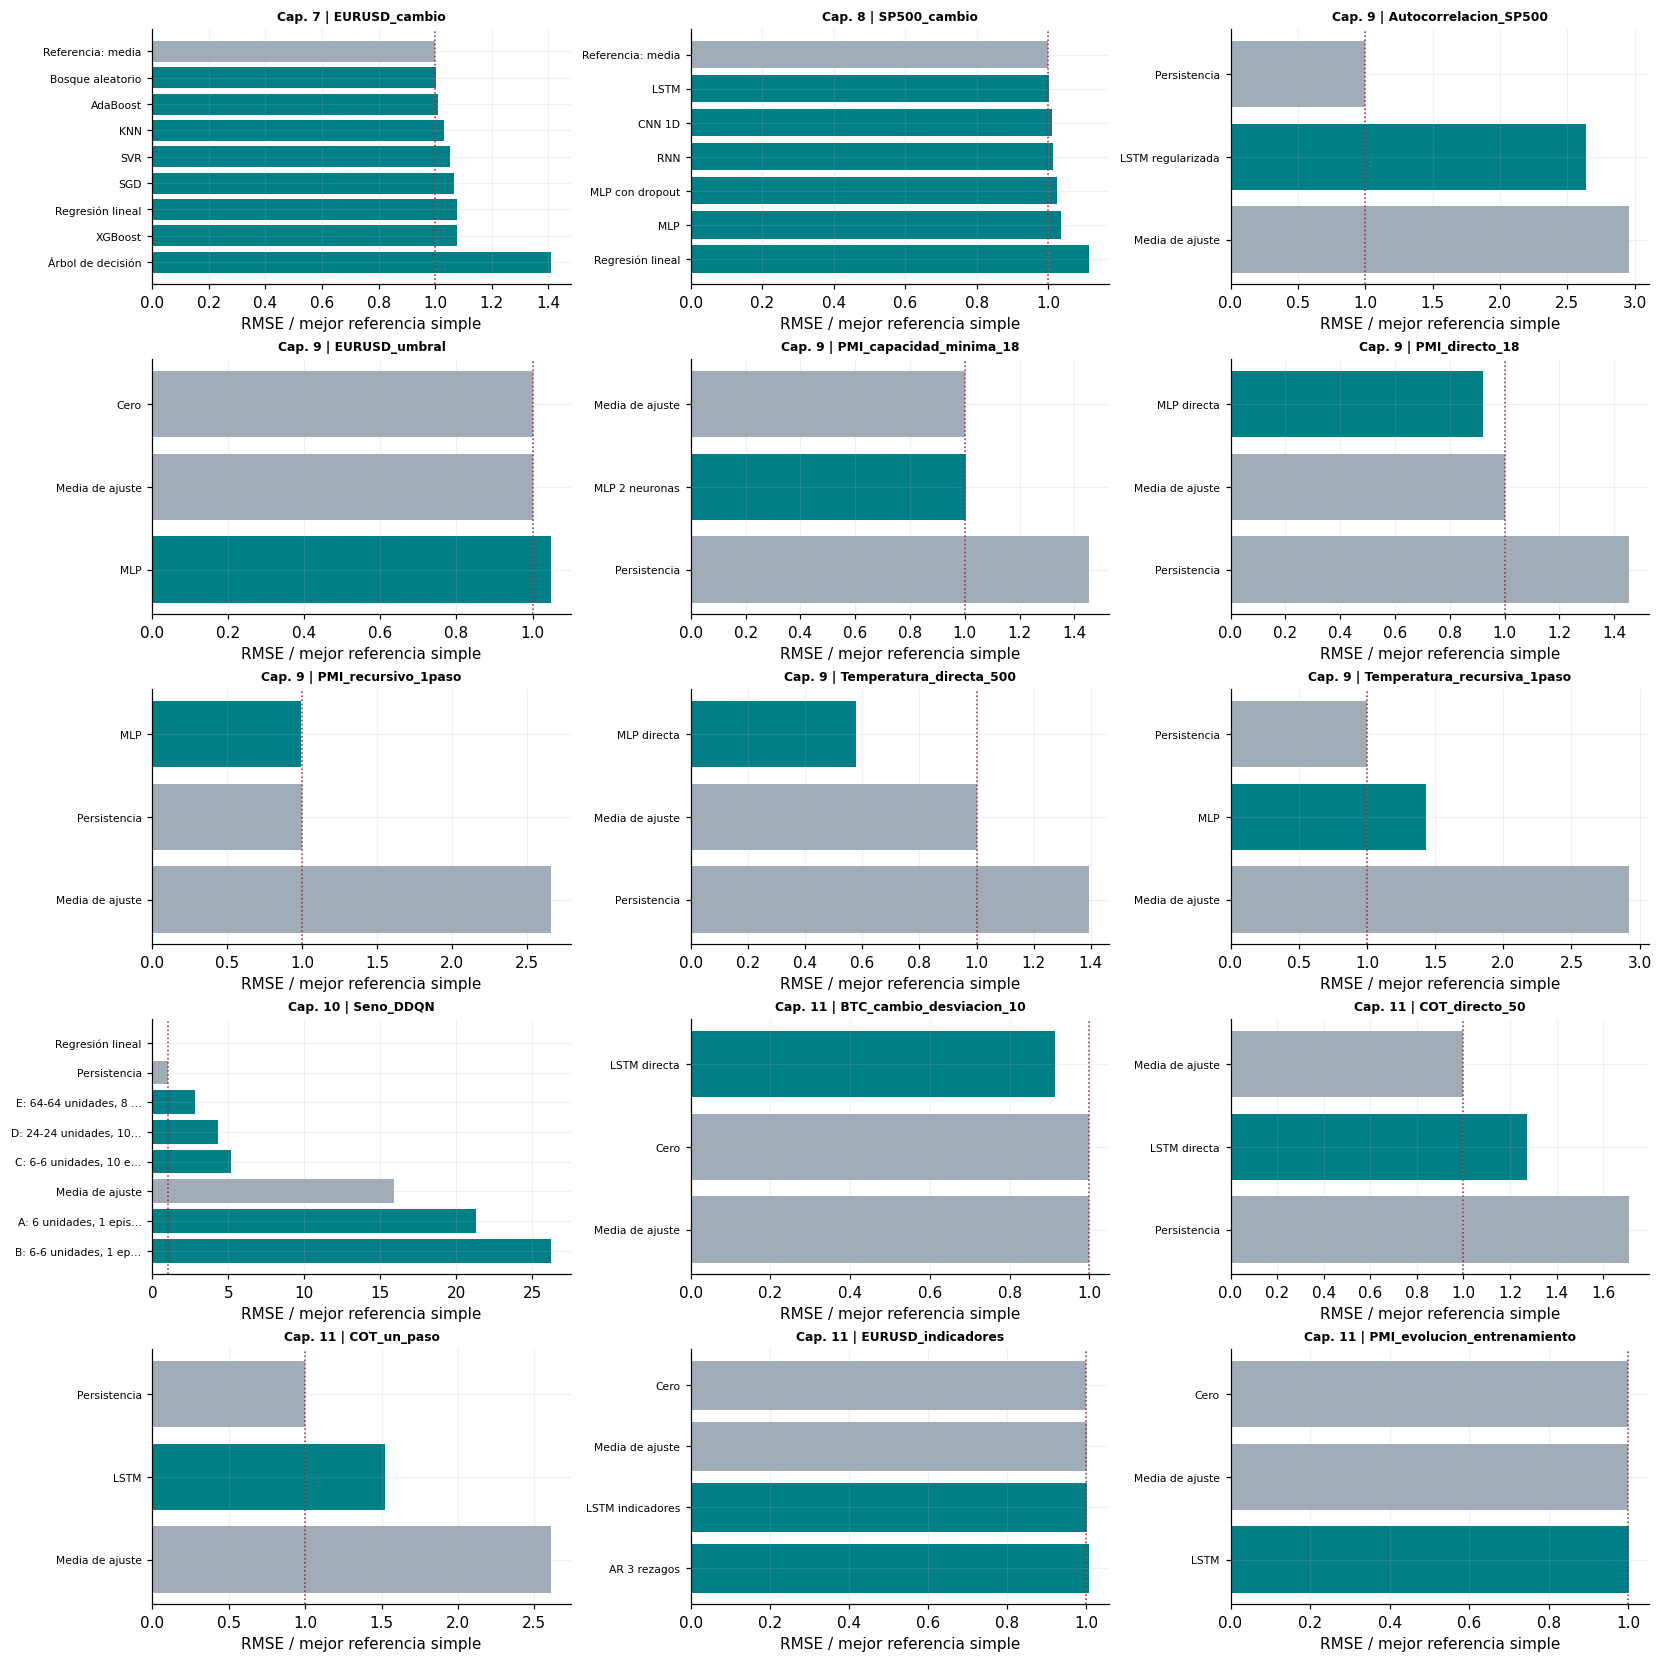


### Conclusiones generales del proyecto

1. **Se cumplió el objetivo de integración.** Se desarrollaron los capítulos 7 al 11 en un solo cuaderno y se organizó su evidencia en una base relacional con **15 casos**, **61 grupos caso-modelo**, **174 registros de métricas** y **29,330 valores pronosticados de prueba**. El número de casos no incluye cada demostración auxiliar; las trayectorias recursivas y los ejercicios de cálculo permanecen en sus secciones.
2. **La complejidad no garantiza mejor precisión.** En EUR/USD, **0 de los ocho modelos** del capítulo 7 superaron a la media en RMSE. En S&P 500, **0 de las cinco redes** del capítulo 8 la superaron. Las referencias tuvieron RMSE de **0.005052 USD/EUR** y **55.3202 puntos**, respectivamente. Estos errores pertenecen a variables distintas y no se comparan entre sí.
3. **La evaluación temporal determina el significado del resultado.** La prueba usa observaciones posteriores; los escaladores y las épocas no se eligen con ella. Los pronósticos de un paso reciben el pasado observado disponible. Las trayectorias recursivas desde un origen fijo reciben sus propias predicciones. Los dos esquemas responden a preguntas diferentes.
4. **Las aplicaciones avanzadas requieren definir la variable.** El COT predicho es posicionamiento TFF; la autocorrelación es un indicador; la desviación móvil de precios de Bitcoin no es volatilidad anualizada de retornos. El experimento DDQN utiliza una onda simulada y una recompensa de predicción. Ninguno de estos resultados se interpreta por sí mismo como utilidad de una operación financiera.
5. **SQL permitió auditar el análisis.** El conteo, el MAE y el RMSE recalculados a partir de las predicciones almacenadas coinciden con las métricas registradas en todos los modelos. También se comprobaron claves foráneas, unicidad, integridad y alineación de las observaciones comparadas. La base permite revisar las conclusiones sin volver a entrenar las redes.
6. **La respuesta a la pregunta general depende de la tarea y de la muestra.** La tabla anterior muestra los resultados por caso. Una mejora observada no constituye una garantía estadística: se trabajó con una semilla y cortes concretos; algunas trayectorias largas tienen pocos orígenes independientes. Se requiere validación adicional en periodos y semillas nuevos antes de sostener utilidad predictiva general.

### Aportación a Actuaría y a Gestión de bases de datos

El proyecto une la preparación de series, la medición del error y el almacenamiento de evidencia. Para Actuaría, permite distinguir ajuste histórico, incertidumbre y capacidad de generalización. Para Gestión de bases de datos, demuestra cómo las claves, las relaciones, las transacciones, los índices, las vistas y las consultas agregadas sostienen un análisis verificable.

### Limitaciones y trabajo futuro

Se conservaron las fotografías históricas de los avances; no se sustituyeron por descargas recientes. Los archivos sin fecha se identifican por posición y no reciben calendarios supuestos. El historial COT no permite reconstruir todas las revisiones ni las fechas efectivas de publicación. No se realizaron pruebas de significancia, una evaluación de múltiples semillas ni un estudio de costos de transacción. El siguiente desarrollo útil sería una evaluación temporal anidada con más orígenes, trazabilidad de publicaciones y validación de estabilidad frente a las referencias.


In [84]:
P_CONSULTA = '''
WITH orden AS (
 SELECT *,DENSE_RANK() OVER(PARTITION BY caso_id ORDER BY rmse) AS posicion
 FROM resultados_prueba
)
SELECT capitulo_id AS capitulo,caso,unidad,horizontes,modelo,
       n,rmse,mae,acierto_pct FROM orden WHERE posicion=1
ORDER BY capitulo_id,caso;
'''
P_MEJORES=pd.read_sql_query(P_CONSULTA,P_DB)
display(P_MEJORES)
display(Markdown('La posición anterior es **descriptiva de la prueba**. No se usa para elegir hiperparámetros ni demuestra superioridad en periodos posteriores.'))

P_COMPARACION=pd.read_sql_query('''
WITH base AS (
 SELECT caso_id,MIN(rmse) AS rmse_referencia
 FROM resultados_prueba WHERE familia='Referencia simple' GROUP BY caso_id
), candidatos AS (
 SELECT *,ROW_NUMBER() OVER(PARTITION BY caso_id ORDER BY rmse,modelo) AS posicion
 FROM resultados_prueba WHERE familia<>'Referencia simple'
)
SELECT c.capitulo_id AS capitulo,c.caso,c.unidad,c.horizontes,c.modelo,
       c.rmse AS rmse_candidato,b.rmse_referencia,
       100*(b.rmse_referencia-c.rmse)/NULLIF(b.rmse_referencia,0) AS mejora_pct
FROM candidatos c JOIN base b USING(caso_id)
WHERE c.posicion=1 ORDER BY c.capitulo_id,c.caso;
''',P_DB)
display(P_COMPARACION.round(5))
display(Markdown('La columna `mejora_pct` compara, dentro de cada caso, el candidato de menor RMSE con la mejor referencia simple observada. Un valor negativo representa mayor error. Es una descripción posterior de esta muestra; las referencias y los candidatos se fijaron antes de evaluar la prueba.'))

# Gráfica en unidades propias, un panel por caso; no se suman errores heterogéneos.
fig,axes=plt.subplots(5,3,figsize=(15,15),layout='constrained')
for ax,(cid,grupo) in zip(axes.flat,pd.read_sql_query('SELECT * FROM resultados_prueba ORDER BY capitulo_id,caso,rmse',P_DB).groupby('caso_id',sort=False)):
    base=grupo.loc[grupo['familia']=='Referencia simple','rmse'].min()
    ratio=grupo['rmse']/base
    colores=['#A0ACB7' if f=='Referencia simple' else '#007F86' for f in grupo['familia']]
    ax.barh(range(len(grupo)),ratio,color=colores)
    ax.set_yticks(range(len(grupo)),[n if len(n)<24 else n[:21]+'…' for n in grupo['modelo']],fontsize=7)
    ax.invert_yaxis();ax.axvline(1,color='#A12335',ls=':',lw=1)
    ax.set(title=f"Cap. {grupo.iloc[0]['capitulo_id']} | {grupo.iloc[0]['caso']}",xlabel='RMSE / mejor referencia simple')
    ax.title.set_fontsize(8)
plt.show()

p7=pd.read_sql_query("SELECT * FROM resultados_prueba WHERE capitulo_id=7",P_DB)
p8=pd.read_sql_query("SELECT * FROM resultados_prueba WHERE capitulo_id=8",P_DB)
v7=float(p7.loc[p7['modelo']=='Referencia: media','rmse'].iloc[0])
v8=float(p8.loc[p8['modelo']=='Referencia: media','rmse'].iloc[0])
n7=int(((p7['familia']!='Referencia simple')&(p7['rmse']<v7)).sum())
n8=int(((p8['familia']=='Red neuronal')&(p8['rmse']<v8)).sum())
display(Markdown(f'''
### Conclusiones generales del proyecto

1. **Se cumplió el objetivo de integración.** Se desarrollaron los capítulos 7 al 11 en un solo cuaderno y se organizó su evidencia en una base relacional con **{P_TOTALES['casos']} casos**, **{P_TOTALES['modelos']} grupos caso-modelo**, **{P_TOTALES['metricas']} registros de métricas** y **{P_TOTALES['predicciones']:,} valores pronosticados de prueba**. El número de casos no incluye cada demostración auxiliar; las trayectorias recursivas y los ejercicios de cálculo permanecen en sus secciones.
2. **La complejidad no garantiza mejor precisión.** En EUR/USD, **{n7} de los ocho modelos** del capítulo 7 superaron a la media en RMSE. En S&P 500, **{n8} de las cinco redes** del capítulo 8 la superaron. Las referencias tuvieron RMSE de **{v7:.6f} USD/EUR** y **{v8:.4f} puntos**, respectivamente. Estos errores pertenecen a variables distintas y no se comparan entre sí.
3. **La evaluación temporal determina el significado del resultado.** La prueba usa observaciones posteriores; los escaladores y las épocas no se eligen con ella. Los pronósticos de un paso reciben el pasado observado disponible. Las trayectorias recursivas desde un origen fijo reciben sus propias predicciones. Los dos esquemas responden a preguntas diferentes.
4. **Las aplicaciones avanzadas requieren definir la variable.** El COT predicho es posicionamiento TFF; la autocorrelación es un indicador; la desviación móvil de precios de Bitcoin no es volatilidad anualizada de retornos. El experimento DDQN utiliza una onda simulada y una recompensa de predicción. Ninguno de estos resultados se interpreta por sí mismo como utilidad de una operación financiera.
5. **SQL permitió auditar el análisis.** El conteo, el MAE y el RMSE recalculados a partir de las predicciones almacenadas coinciden con las métricas registradas en todos los modelos. También se comprobaron claves foráneas, unicidad, integridad y alineación de las observaciones comparadas. La base permite revisar las conclusiones sin volver a entrenar las redes.
6. **La respuesta a la pregunta general depende de la tarea y de la muestra.** La tabla anterior muestra los resultados por caso. Una mejora observada no constituye una garantía estadística: se trabajó con una semilla y cortes concretos; algunas trayectorias largas tienen pocos orígenes independientes. Se requiere validación adicional en periodos y semillas nuevos antes de sostener utilidad predictiva general.

### Aportación a Actuaría y a Gestión de bases de datos

El proyecto une la preparación de series, la medición del error y el almacenamiento de evidencia. Para Actuaría, permite distinguir ajuste histórico, incertidumbre y capacidad de generalización. Para Gestión de bases de datos, demuestra cómo las claves, las relaciones, las transacciones, los índices, las vistas y las consultas agregadas sostienen un análisis verificable.

### Limitaciones y trabajo futuro

Se conservaron las fotografías históricas de los avances; no se sustituyeron por descargas recientes. Los archivos sin fecha se identifican por posición y no reciben calendarios supuestos. El historial COT no permite reconstruir todas las revisiones ni las fechas efectivas de publicación. No se realizaron pruebas de significancia, una evaluación de múltiples semillas ni un estudio de costos de transacción. El siguiente desarrollo útil sería una evaluación temporal anidada con más orígenes, trazabilidad de publicaciones y validación de estabilidad frente a las referencias.
'''))

## 11. Exportación de la entrega

Al terminar, `entrega_final` contiene la base integrada, las consultas SQL, los resultados por caso, la auditoría y el registro de fuentes y versiones. Las carpetas de salida de los capítulos conservan los datos y resultados auxiliares generados durante la ejecución. El `.ipynb` reúne explicaciones, código y salidas para su revisión.

| Archivo | Uso |
|---|---|
| `Proyecto_Final_81901.sqlite` | Consultar la evidencia de todos los casos |
| `modelo_relacional.sql` | Revisar la definición de tablas, relaciones e índices |
| `consulta_resultados.sql` | Repetir el resumen por caso |
| `resultados_prueba.csv` | Revisar todos los resultados de prueba |
| `comparacion_referencias.csv` | Contrastar candidatos y referencias por caso |
| `auditoria_metricas.csv` | Comprobar conteos y errores recalculados |
| `fuentes_y_versiones.json` | Identificar procedencia, semillas y versiones |

In [85]:
P_SALIDA=Path('entrega_final');P_SALIDA.mkdir(exist_ok=True)
with sqlite3.connect(P_SALIDA/'Proyecto_Final_81901.sqlite') as destino:
    P_DB.backup(destino)
P_MEJORES.to_csv(P_SALIDA/'mejor_resultado_por_caso.csv',index=False)
P_COMPARACION.to_csv(P_SALIDA/'comparacion_referencias.csv',index=False)
P_CONTROL.to_csv(P_SALIDA/'auditoria_metricas.csv',index=False)
pd.read_sql_query('SELECT * FROM resultados_prueba',P_DB).to_csv(P_SALIDA/'resultados_prueba.csv',index=False)
(P_SALIDA/'modelo_relacional.sql').write_text(P_DDL,encoding='utf-8')
(P_SALIDA/'consulta_resultados.sql').write_text(P_CONSULTA,encoding='utf-8')
(P_SALIDA/'fuentes_y_versiones.json').write_text(json.dumps({
    'fecha_ejecucion_final':P_FECHA,'alumno':'Juan Fernando Castrejón Villa',
    'matricula':'81901','semilla':123,'versiones':P_VERSIONES,'fuentes':P_MANIFIESTO,
    'controles':P_TOTALES},ensure_ascii=False,indent=2),encoding='utf-8')
print('Entrega final generada:')
for archivo in sorted(P_SALIDA.iterdir()):
    if archivo.is_file():print(f'  {archivo.name}: {archivo.stat().st_size:,} bytes')
print('El notebook conserva las tablas, las gráficas y las conclusiones de la ejecución.')

Entrega final generada:
  Proyecto_Final_81901.sqlite: 6,926,336 bytes
  auditoria_metricas.csv: 8,709 bytes
  comparacion_referencias.csv: 1,688 bytes
  consulta_resultados.sql: 266 bytes
  fuentes_y_versiones.json: 5,210 bytes
  mejor_resultado_por_caso.csv: 1,655 bytes
  modelo_relacional.sql: 3,139 bytes
  resultados_prueba.csv: 11,313 bytes
El notebook conserva las tablas, las gráficas y las conclusiones de la ejecución.


## Referencias generales

Kaabar, S. (2024). *Deep Learning for Finance*. O'Reilly Media. Capítulos 7, 8, 9, 10 y 11 del material proporcionado para la actividad.

Kaabar, S. *deep-learning-for-finance* [Repositorio de código y datos]. https://github.com/sofienkaabar/deep-learning-for-finance. Revisión de datos fijada: `07e6d4f4844b228849294eee5b426029e7b011b1`.

Federal Reserve Bank of St. Louis. *FRED*: https://fred.stlouisfed.org/series/DEXUSEU, https://fred.stlouisfed.org/series/SP500 y https://fred.stlouisfed.org/series/DEXCAUS. Consultas históricas documentadas por fuente.

Commodity Futures Trading Commission. *Commitments of Traders*. https://www.cftc.gov/MarketReports/CommitmentsofTraders/index.htm.

Scikit-learn developers. Documentación de modelos, métricas y validación temporal: https://scikit-learn.org/stable/.

Keras team. Documentación de capas, optimizadores y callbacks: https://keras.io/api/.

SQLite. Lenguaje SQL, claves foráneas y transacciones: https://www.sqlite.org/lang.html y https://www.sqlite.org/foreignkeys.html.

Las referencias específicas a ADF, XGBoost y animación se encuentran en las secciones correspondientes. La implementación es una adaptación académica: los ajustes de arquitectura, las correcciones del procedimiento y las limitaciones se declaran en cada capítulo.